In [1]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 2: CANCER REGISTRY
# PHASE 1 — REFERENCE
# STEP 1 — AUDIT OF Dataset_REF
#
# IMPORTANT:
# - No correction
# - No imputation
# - No row/column deletion
# - No use of CR-IDA reference rules
# - Dataset_REF remains unchanged
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import sys
import platform
from datetime import datetime

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
    r"\CASE_STUDY_2_CANCER_REGISTRY"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "reference"
    / "simulated_registry_data.csv"
)

RESULTS_DIR = PROJECT_ROOT / "results" / "01_reference"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

print("=" * 80)
print("DEMARCHE_ENCAD3 — CASE STUDY 2")
print("PHASE 1 — REFERENCE")
print("STEP 1 — DATASET_REF AUDIT")
print("=" * 80)

print("\nProject root:")
print(PROJECT_ROOT)

print("\nDataset:")
print(DATA_PATH)

# ------------------------------------------------------------
# 2. VERIFY DATASET
# ------------------------------------------------------------

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"\nDataset not found:\n{DATA_PATH}\n\n"
        "Place simulated_registry_data.csv in:\n"
        "data/reference/"
    )

# ------------------------------------------------------------
# 3. LOAD DATASET
# ------------------------------------------------------------

df = pd.read_csv(DATA_PATH)

# Explicit immutable reference copy for this audit
Dataset_REF = df.copy(deep=True)

print("\n" + "=" * 80)
print("1. GENERAL INFORMATION")
print("=" * 80)

print(f"Rows       : {Dataset_REF.shape[0]:,}")
print(f"Columns    : {Dataset_REF.shape[1]:,}")
print(f"Total cells: {Dataset_REF.size:,}")

# ------------------------------------------------------------
# 4. COLUMN NAMES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("2. VARIABLES")
print("=" * 80)

for i, column in enumerate(Dataset_REF.columns, start=1):
    print(f"{i:02d}. {column}")

# ------------------------------------------------------------
# 5. DATA TYPES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("3. DATA TYPES")
print("=" * 80)

dtype_table = pd.DataFrame({
    "feature": Dataset_REF.columns,
    "dtype": [str(Dataset_REF[c].dtype) for c in Dataset_REF.columns]
})

print(dtype_table.to_string(index=False))

# ------------------------------------------------------------
# 6. MISSING VALUES
# ------------------------------------------------------------

missing_count = Dataset_REF.isna().sum()
missing_percent = (missing_count / len(Dataset_REF) * 100).round(3)

missing_table = pd.DataFrame({
    "feature": Dataset_REF.columns,
    "missing_count": missing_count.values,
    "missing_percent": missing_percent.values
}).sort_values(
    ["missing_count", "feature"],
    ascending=[False, True]
)

print("\n" + "=" * 80)
print("4. MISSING VALUES")
print("=" * 80)

print(missing_table.to_string(index=False))

# ------------------------------------------------------------
# 7. UNIQUE VALUES / CARDINALITY
# ------------------------------------------------------------

cardinality_table = pd.DataFrame({
    "feature": Dataset_REF.columns,
    "n_unique_excluding_na": [
        Dataset_REF[c].nunique(dropna=True)
        for c in Dataset_REF.columns
    ],
    "n_unique_including_na": [
        Dataset_REF[c].nunique(dropna=False)
        for c in Dataset_REF.columns
    ]
}).sort_values(
    ["n_unique_excluding_na", "feature"],
    ascending=[True, True]
)

print("\n" + "=" * 80)
print("5. CARDINALITY")
print("=" * 80)

print(cardinality_table.to_string(index=False))

# ------------------------------------------------------------
# 8. EXACT DUPLICATES
# ------------------------------------------------------------

n_duplicates = int(Dataset_REF.duplicated().sum())
duplicate_percent = (
    100 * n_duplicates / len(Dataset_REF)
    if len(Dataset_REF) > 0 else 0
)

print("\n" + "=" * 80)
print("6. EXACT DUPLICATE ROWS")
print("=" * 80)

print(f"Duplicate rows : {n_duplicates}")
print(f"Percentage     : {duplicate_percent:.3f}%")

# ------------------------------------------------------------
# 9. NUMERICAL VARIABLES
# ------------------------------------------------------------

numeric_columns = Dataset_REF.select_dtypes(
    include=[np.number]
).columns.tolist()

print("\n" + "=" * 80)
print("7. NUMERICAL VARIABLES")
print("=" * 80)

print(f"Number of numerical variables: {len(numeric_columns)}")

if numeric_columns:

    numerical_summary = (
        Dataset_REF[numeric_columns]
        .describe()
        .T
        .reset_index()
        .rename(columns={"index": "feature"})
    )

    numerical_summary["missing"] = [
        Dataset_REF[c].isna().sum()
        for c in numeric_columns
    ]

    print(numerical_summary.to_string(index=False))

else:
    numerical_summary = pd.DataFrame()
    print("No numerical variables detected.")

# ------------------------------------------------------------
# 10. NON-NUMERICAL VARIABLES
# ------------------------------------------------------------

non_numeric_columns = [
    c for c in Dataset_REF.columns
    if c not in numeric_columns
]

print("\n" + "=" * 80)
print("8. NON-NUMERICAL VARIABLES")
print("=" * 80)

print(f"Number of non-numerical variables: {len(non_numeric_columns)}")

categorical_rows = []

for column in non_numeric_columns:

    vc = Dataset_REF[column].value_counts(
        dropna=False
    ).head(10)

    categorical_rows.append({
        "feature": column,
        "n_unique": Dataset_REF[column].nunique(dropna=True),
        "top_values": " | ".join(
            [f"{str(k)}:{int(v)}" for k, v in vc.items()]
        )
    })

categorical_summary = pd.DataFrame(categorical_rows)

if not categorical_summary.empty:
    print(categorical_summary.to_string(index=False))

# ------------------------------------------------------------
# 11. CONSTANT / NEAR-CONSTANT FEATURES
# ------------------------------------------------------------

constant_features = []

near_constant_features = []

for column in Dataset_REF.columns:

    counts = Dataset_REF[column].value_counts(
        normalize=True,
        dropna=False
    )

    n_unique = Dataset_REF[column].nunique(dropna=False)

    if n_unique <= 1:
        constant_features.append(column)

    elif len(counts) > 0 and counts.iloc[0] >= 0.95:
        near_constant_features.append({
            "feature": column,
            "dominant_fraction": round(float(counts.iloc[0]), 4),
            "dominant_value": str(counts.index[0])
        })

near_constant_table = pd.DataFrame(near_constant_features)

print("\n" + "=" * 80)
print("9. CONSTANT / NEAR-CONSTANT FEATURES")
print("=" * 80)

print("Constant features:")
print(constant_features if constant_features else "None")

print("\nNear-constant features (>=95% same value):")

if not near_constant_table.empty:
    print(near_constant_table.to_string(index=False))
else:
    print("None")

# ------------------------------------------------------------
# 12. POTENTIAL IDENTIFIER-LIKE FEATURES
#     OBSERVATION ONLY — NOTHING IS REMOVED
# ------------------------------------------------------------

identifier_rows = []

n_rows = len(Dataset_REF)

for column in Dataset_REF.columns:

    n_unique = Dataset_REF[column].nunique(dropna=True)

    uniqueness_ratio = (
        n_unique / n_rows
        if n_rows > 0 else np.nan
    )

    if uniqueness_ratio >= 0.90:
        identifier_rows.append({
            "feature": column,
            "n_unique": n_unique,
            "uniqueness_ratio": round(float(uniqueness_ratio), 4)
        })

identifier_table = pd.DataFrame(identifier_rows)

print("\n" + "=" * 80)
print("10. POTENTIAL IDENTIFIER-LIKE FEATURES")
print("=" * 80)

print(
    "NOTE: This is only a structural observation.\n"
    "No feature is classified or removed automatically."
)

if not identifier_table.empty:
    print(identifier_table.to_string(index=False))
else:
    print("None detected using the >=90% uniqueness heuristic.")

# ------------------------------------------------------------
# 13. FIRST 10 ROWS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("11. FIRST 10 ROWS — INSPECTION ONLY")
print("=" * 80)

print(Dataset_REF.head(10).to_string(index=False))

# ------------------------------------------------------------
# 14. CREATE FEATURE-LEVEL AUDIT TABLE
# ------------------------------------------------------------

audit_rows = []

for column in Dataset_REF.columns:

    series = Dataset_REF[column]

    audit_rows.append({
        "feature": column,
        "dtype": str(series.dtype),
        "n_rows": len(series),
        "missing_count": int(series.isna().sum()),
        "missing_percent": round(
            float(series.isna().mean() * 100), 3
        ),
        "n_unique": int(series.nunique(dropna=True)),
        "unique_ratio": round(
            float(series.nunique(dropna=True) / len(series)),
            4
        ) if len(series) else np.nan
    })

feature_audit = pd.DataFrame(audit_rows)

# ------------------------------------------------------------
# 15. SAVE RESULTS
# ------------------------------------------------------------

feature_audit.to_csv(
    RESULTS_DIR / "dataset_ref_feature_audit.csv",
    index=False
)

missing_table.to_csv(
    RESULTS_DIR / "dataset_ref_missing_values.csv",
    index=False
)

cardinality_table.to_csv(
    RESULTS_DIR / "dataset_ref_cardinality.csv",
    index=False
)

if not numerical_summary.empty:
    numerical_summary.to_csv(
        RESULTS_DIR / "dataset_ref_numerical_summary.csv",
        index=False
    )

if not categorical_summary.empty:
    categorical_summary.to_csv(
        RESULTS_DIR / "dataset_ref_categorical_summary.csv",
        index=False
    )

if not identifier_table.empty:
    identifier_table.to_csv(
        RESULTS_DIR / "dataset_ref_identifier_candidates.csv",
        index=False
    )

if not near_constant_table.empty:
    near_constant_table.to_csv(
        RESULTS_DIR / "dataset_ref_near_constant.csv",
        index=False
    )

# ------------------------------------------------------------
# 16. SAVE REPRODUCIBILITY INFORMATION
# ------------------------------------------------------------

audit_metadata = {
    "case_study": "Cancer Registry simulated dataset",
    "framework": "DEMARCHE_ENCAD3",
    "phase": "01_REFERENCE",
    "step": "Dataset_REF audit",
    "audit_timestamp": datetime.now().isoformat(),
    "dataset_file": DATA_PATH.name,
    "n_rows": int(Dataset_REF.shape[0]),
    "n_columns": int(Dataset_REF.shape[1]),
    "duplicate_rows": n_duplicates,
    "numeric_columns": numeric_columns,
    "non_numeric_columns": non_numeric_columns,
    "constant_features": constant_features,
    "python_version": sys.version,
    "platform": platform.platform(),
    "pandas_version": pd.__version__,
    "numpy_version": np.__version__,
    "data_modified": False,
    "reference_rules_used": False
}

with open(
    RESULTS_DIR / "dataset_ref_audit_metadata.json",
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        audit_metadata,
        f,
        ensure_ascii=False,
        indent=4
    )

# ------------------------------------------------------------
# 17. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("AUDIT SUMMARY")
print("=" * 80)

print(f"""
Dataset_REF
-----------
Rows                 : {Dataset_REF.shape[0]:,}
Columns              : {Dataset_REF.shape[1]}
Numerical features   : {len(numeric_columns)}
Non-numerical        : {len(non_numeric_columns)}
Missing cells        : {int(Dataset_REF.isna().sum().sum()):,}
Duplicate rows       : {n_duplicates}
Constant features    : {len(constant_features)}
Near-constant        : {len(near_constant_features)}
Identifier candidates: {len(identifier_rows)}

DATA MODIFIED         : NO
IMPUTATION            : NO
CORRECTION            : NO
ROWS REMOVED          : NO
REFERENCE RULES USED  : NO
""")

print("=" * 80)
print("FILES CREATED")
print("=" * 80)

for file in sorted(RESULTS_DIR.glob("*")):
    print(file.name)

print("\nSTEP 1 COMPLETED.")
print("Do not modify Dataset_REF before analysis of these results.")

DEMARCHE_ENCAD3 — CASE STUDY 2
PHASE 1 — REFERENCE
STEP 1 — DATASET_REF AUDIT

Project root:
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_2_CANCER_REGISTRY

Dataset:
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_2_CANCER_REGISTRY\data\reference\simulated_registry_data.csv

1. GENERAL INFORMATION
Rows       : 1,902
Columns    : 27
Total cells: 51,354

2. VARIABLES
01. registration_number
02. disease_id
03. sex_code
04. sex_name
05. birth_date
06. age_diag
07. vital_status_code
08. vital_status_name
09. death_date
10. diag_date
11. diag_year
12. diag_date_valid_name
13. mkb10_code
14. mkb10_name
15. mkb10_3char
16. histology_code
17. icdo3_m_code
18. icdo3_m_name
19. registry_stage_code
20. registry_stage_name
21. stage_definition_code
22. stage_definition_name
23. diagnosis_method_code
24. diagnosis_method_name
25. finding_code
26. finding_name
27. administr_unit

3. DATA TYPES
              feature   dtype
  registration_number

In [3]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 2: CANCER REGISTRY
# PHASE 1 — REFERENCE
# STEP 2 — MINIMAL SEMANTIC FEATURE DICTIONARY
#
# OBJECTIVE:
# Extract ONLY descriptive/semantic information about features.
#
# STRICTLY FORBIDDEN:
# - rules
# - rule conditions
# - thresholds
# - correction actions
# - exclusion criteria
# - rule parameters
#
# NO DATA MODIFICATION
# NO REFERENCE RULE USED
# ============================================================

from pathlib import Path
import pandas as pd
import json
from datetime import datetime

# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
    r"\CASE_STUDY_2_CANCER_REGISTRY"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "reference"
    / "simulated_registry_data.csv"
)

METADATA_PATH = (
    PROJECT_ROOT
    / "hidden_reference"
    / "metadata_original.xlsx"
)

DICTIONARY_DIR = (
    PROJECT_ROOT
    / "data"
    / "dictionary"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
    / "01_reference"
)

DICTIONARY_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DICTIONARY = (
    DICTIONARY_DIR
    / "feature_dictionary.csv"
)

OUTPUT_AUDIT = (
    RESULTS_DIR
    / "step2_dictionary_audit.json"
)

print("=" * 80)
print("DEMARCHE_ENCAD3 — CASE STUDY 2")
print("PHASE 1 — REFERENCE")
print("STEP 2 — MINIMAL SEMANTIC FEATURE DICTIONARY")
print("=" * 80)

# ------------------------------------------------------------
# 2. VERIFY INPUT FILES
# ------------------------------------------------------------

if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found:\n{DATA_PATH}"
    )

if not METADATA_PATH.exists():
    raise FileNotFoundError(
        f"Metadata file not found:\n{METADATA_PATH}\n\n"
        "Place metadata.xlsx in hidden_reference/ "
        "and rename it metadata_original.xlsx"
    )

# ------------------------------------------------------------
# 3. LOAD Dataset_REF
# ------------------------------------------------------------

Dataset_REF = pd.read_csv(DATA_PATH)

dataset_features = list(Dataset_REF.columns)

print("\nDataset_REF:")
print(f"Rows     : {Dataset_REF.shape[0]}")
print(f"Features : {Dataset_REF.shape[1]}")

# ------------------------------------------------------------
# 4. INSPECT EXCEL SHEET NAMES
#    INFORMATION ONLY
# ------------------------------------------------------------

xls = pd.ExcelFile(METADATA_PATH)

print("\n" + "=" * 80)
print("AVAILABLE METADATA SHEETS")
print("=" * 80)

for sheet in xls.sheet_names:
    print(f"- {sheet}")

# ------------------------------------------------------------
# 5. SECURITY / ANTI-LEAKAGE POLICY
# ------------------------------------------------------------

# ONLY this sheet is authorized.
AUTHORIZED_SHEET = "variable_catalogue"

# These sheets must NEVER be read during this step.
FORBIDDEN_SHEETS = [
    "rules",
    "rule_context",
    "rule_set_items",
    "rule_sets",
    "rule_parameters",
    "screening_plan",
    "screening_catalogue",
    "screening_items",
    "screening_parameters"
]

if AUTHORIZED_SHEET not in xls.sheet_names:
    raise ValueError(
        f"Required sheet '{AUTHORIZED_SHEET}' not found."
    )

print("\n" + "=" * 80)
print("ANTI-LEAKAGE POLICY")
print("=" * 80)

print(f"AUTHORIZED SHEET : {AUTHORIZED_SHEET}")

print("\nFORBIDDEN SHEETS:")
for sheet in FORBIDDEN_SHEETS:
    print(f"- {sheet}")

print(
    "\nOnly variable_catalogue will now be loaded."
)

# ------------------------------------------------------------
# 6. LOAD ONLY variable_catalogue
# ------------------------------------------------------------

variable_catalogue = pd.read_excel(
    METADATA_PATH,
    sheet_name=AUTHORIZED_SHEET
)

print("\n" + "=" * 80)
print("VARIABLE_CATALOGUE STRUCTURE")
print("=" * 80)

print("Rows   :", variable_catalogue.shape[0])
print("Columns:", variable_catalogue.shape[1])

print("\nAvailable columns:")

for column in variable_catalogue.columns:
    print(f"- {column}")

# ------------------------------------------------------------
# 7. IDENTIFY FEATURE-NAME COLUMN
# ------------------------------------------------------------

possible_feature_columns = [
    "variable",
    "variable_name",
    "feature",
    "feature_name",
    "name"
]

feature_column = None

for candidate in possible_feature_columns:
    if candidate in variable_catalogue.columns:
        feature_column = candidate
        break

if feature_column is None:
    raise ValueError(
        "\nCould not identify the feature-name column.\n"
        f"Available columns: {list(variable_catalogue.columns)}"
    )

print("\nFeature-name column detected:")
print(feature_column)

# ------------------------------------------------------------
# 8. DEFINE STRICT SEMANTIC WHITELIST
# ------------------------------------------------------------

# We intentionally use a WHITELIST rather than copying
# the whole metadata table.
#
# This prevents accidental extraction of rules,
# thresholds, validity criteria or correction actions.

SEMANTIC_CANDIDATES = [
    "description",
    "label",
    "type",
    "data_type",
    "role",
    "coding_values",
    "unit"
]

selected_semantic_columns = [
    c for c in SEMANTIC_CANDIDATES
    if c in variable_catalogue.columns
]

selected_columns = [
    feature_column
] + selected_semantic_columns

print("\n" + "=" * 80)
print("AUTHORIZED SEMANTIC COLUMNS")
print("=" * 80)

for column in selected_columns:
    print(f"- {column}")

# ------------------------------------------------------------
# 9. EXTRACT ONLY DATASET FEATURES
# ------------------------------------------------------------

minimal_dictionary = (
    variable_catalogue[selected_columns]
    .copy()
)

# Normalize feature names for matching only
minimal_dictionary["_feature_match"] = (
    minimal_dictionary[feature_column]
    .astype(str)
    .str.strip()
)

dataset_feature_set = set(dataset_features)

minimal_dictionary = minimal_dictionary[
    minimal_dictionary["_feature_match"].isin(
        dataset_feature_set
    )
].copy()

# Rename main column consistently
minimal_dictionary = minimal_dictionary.rename(
    columns={feature_column: "feature"}
)

minimal_dictionary = minimal_dictionary.drop(
    columns=["_feature_match"]
)

# ------------------------------------------------------------
# 10. PRESERVE DATASET FEATURE ORDER
# ------------------------------------------------------------

feature_order = {
    feature: i
    for i, feature in enumerate(dataset_features)
}

minimal_dictionary["_order"] = (
    minimal_dictionary["feature"]
    .map(feature_order)
)

minimal_dictionary = (
    minimal_dictionary
    .sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 11. CHECK COVERAGE
# ------------------------------------------------------------

dictionary_features = set(
    minimal_dictionary["feature"]
)

features_with_definition = [
    f for f in dataset_features
    if f in dictionary_features
]

features_without_definition = [
    f for f in dataset_features
    if f not in dictionary_features
]

extra_metadata_features = [
    str(v)
    for v in variable_catalogue[feature_column].dropna()
    if str(v).strip() not in dataset_feature_set
]

print("\n" + "=" * 80)
print("DICTIONARY COVERAGE")
print("=" * 80)

print(
    f"Dataset features             : "
    f"{len(dataset_features)}"
)

print(
    f"Features found in dictionary : "
    f"{len(features_with_definition)}"
)

print(
    f"Features without definition  : "
    f"{len(features_without_definition)}"
)

if features_without_definition:

    print("\nFeatures without metadata definition:")

    for feature in features_without_definition:
        print(f"- {feature}")

else:
    print("\nAll Dataset_REF features have a dictionary entry.")

# ------------------------------------------------------------
# 12. DISPLAY MINIMAL DICTIONARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("MINIMAL SEMANTIC DICTIONARY")
print("=" * 80)

if minimal_dictionary.empty:

    print("No matching features found.")

else:

    with pd.option_context(
        "display.max_rows", None,
        "display.max_columns", None,
        "display.width", 250,
        "display.max_colwidth", 100
    ):
        print(
            minimal_dictionary.to_string(index=False)
        )

# ------------------------------------------------------------
# 13. AUTOMATIC LEAKAGE CHECK
# ------------------------------------------------------------

# Check column names of the OUTPUT only.
# We do not inspect forbidden sheets.

forbidden_terms = [
    "rule",
    "threshold",
    "exclude",
    "exclusion",
    "correct",
    "correction",
    "validity",
    "eligibility",
    "parameter"
]

suspicious_columns = []

for column in minimal_dictionary.columns:

    column_lower = str(column).lower()

    if any(
        term in column_lower
        for term in forbidden_terms
    ):
        suspicious_columns.append(column)

print("\n" + "=" * 80)
print("LEAKAGE CHECK")
print("=" * 80)

if suspicious_columns:

    raise ValueError(
        "Potential leakage detected in output columns: "
        f"{suspicious_columns}"
    )

else:

    print(
        "PASS — No rule/action/threshold column "
        "detected in the minimal dictionary."
    )

# ------------------------------------------------------------
# 14. SAVE MINIMAL DICTIONARY
# ------------------------------------------------------------

minimal_dictionary.to_csv(
    OUTPUT_DICTIONARY,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 15. SAVE TRACEABILITY INFORMATION
# ------------------------------------------------------------

audit = {

    "framework":
        "DEMARCHE_ENCAD3",

    "case_study":
        "Cancer Registry simulated dataset",

    "phase":
        "01_REFERENCE",

    "step":
        "02_MINIMAL_SEMANTIC_DICTIONARY",

    "timestamp":
        datetime.now().isoformat(),

    "dataset_file":
        DATA_PATH.name,

    "metadata_file":
        METADATA_PATH.name,

    "authorized_sheet":
        AUTHORIZED_SHEET,

    "forbidden_sheets":
        FORBIDDEN_SHEETS,

    "selected_columns":
        selected_columns,

    "dataset_feature_count":
        len(dataset_features),

    "dictionary_feature_count":
        len(features_with_definition),

    "features_without_definition":
        features_without_definition,

    "reference_rules_used":
        False,

    "rule_parameters_used":
        False,

    "correction_information_used":
        False,

    "dataset_modified":
        False
}

with open(
    OUTPUT_AUDIT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        audit,
        f,
        ensure_ascii=False,
        indent=4
    )

# ------------------------------------------------------------
# 16. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 2 SUMMARY")
print("=" * 80)

print(f"""
Dataset_REF features       : {len(dataset_features)}
Dictionary matches         : {len(features_with_definition)}
Missing definitions        : {len(features_without_definition)}

Source sheet used          : {AUTHORIZED_SHEET}

REFERENCE RULES USED       : NO
RULE PARAMETERS USED       : NO
CORRECTION INFO USED       : NO
DATASET MODIFIED           : NO
""")

print("Files created:")
print(f"- {OUTPUT_DICTIONARY.name}")
print(f"- {OUTPUT_AUDIT.name}")

print("\nSTEP 2 COMPLETED.")
print(
    "Do not proceed to target selection before "
    "reviewing the semantic dictionary."
)

DEMARCHE_ENCAD3 — CASE STUDY 2
PHASE 1 — REFERENCE
STEP 2 — MINIMAL SEMANTIC FEATURE DICTIONARY

Dataset_REF:
Rows     : 1902
Features : 27

AVAILABLE METADATA SHEETS
- dataset_definition
- population_definition
- unit
- variable_catalogue
- rules
- rule_context
- rule_set_items
- rule_sets
- rule_parameters
- screening_plan
- screening_catalogue
- screening_items
- screening_parameters

ANTI-LEAKAGE POLICY
AUTHORIZED SHEET : variable_catalogue

FORBIDDEN SHEETS:
- rules
- rule_context
- rule_set_items
- rule_sets
- rule_parameters
- screening_plan
- screening_catalogue
- screening_items
- screening_parameters

Only variable_catalogue will now be loaded.

VARIABLE_CATALOGUE STRUCTURE
Rows   : 48
Columns: 8

Available columns:
- dataset_id
- variable
- description
- type
- role
- coding_values
- missing_definition
- derivation

Feature-name column detected:
variable

AUTHORIZED SEMANTIC COLUMNS
- variable
- description
- type
- role
- coding_values

DICTIONARY COVERAGE
Dataset features 

In [4]:
# ============================================================
# STEP 2 — DIAGNOSTIC OF variable_catalogue DATASET CONTEXTS
# No file is modified.
# ============================================================

from pathlib import Path
import pandas as pd

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
    r"\CASE_STUDY_2_CANCER_REGISTRY"
)

METADATA_PATH = (
    PROJECT_ROOT
    / "hidden_reference"
    / "metadata_original.xlsx"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "reference"
    / "simulated_registry_data.csv"
)

df = pd.read_csv(DATA_PATH)

vc = pd.read_excel(
    METADATA_PATH,
    sheet_name="variable_catalogue"
)

print("=" * 80)
print("DATASET_ID VALUES")
print("=" * 80)

print(vc["dataset_id"].value_counts(dropna=False).to_string())

print("\n" + "=" * 80)
print("FEATURES BY DATASET_ID")
print("=" * 80)

for dataset_id, group in vc.groupby("dataset_id", dropna=False):

    print(f"\n--- dataset_id = {dataset_id} ---")
    print(f"Number of definitions: {len(group)}")

    variables = group["variable"].dropna().astype(str).tolist()

    print(variables)

    overlap = sorted(set(variables) & set(df.columns))

    print(f"\nOverlap with Dataset_REF: {len(overlap)}/{len(df.columns)}")
    print(overlap)

print("\n" + "=" * 80)
print("DUPLICATED FEATURE DEFINITIONS")
print("=" * 80)

duplicates = (
    vc[vc["variable"].isin(df.columns)]
    .sort_values(["variable", "dataset_id"])
)

print(
    duplicates[
        [
            "dataset_id",
            "variable",
            "description",
            "type",
            "role",
            "coding_values"
        ]
    ].to_string(index=False)
)

print("\nNo data or metadata file was modified.")

DATASET_ID VALUES
dataset_id
LUNG_SURV_2020_v1    16
LUNG_SURV_2020_v2    16
LUNG_SURV_DEMO_v1    16

FEATURES BY DATASET_ID

--- dataset_id = LUNG_SURV_2020_v1 ---
Number of definitions: 16
['study_patient_id', 'study_disease_id', 'sex_code', 'age_diag', 'diag_date', 'diag_year', 'mkb10_code', 'mkb10_3char', 'histology_code', 'death_date', 'event', 'end_date', 'surv_time_days', 'surv_time_years', 'registry_stage_code', 'stage_definition_code']

Overlap with Dataset_REF: 10/27
['age_diag', 'death_date', 'diag_date', 'diag_year', 'histology_code', 'mkb10_3char', 'mkb10_code', 'registry_stage_code', 'sex_code', 'stage_definition_code']

--- dataset_id = LUNG_SURV_2020_v2 ---
Number of definitions: 16
['study_patient_id', 'study_disease_id', 'sex_code', 'age_diag', 'diag_date', 'diag_year', 'mkb10_code', 'mkb10_3char', 'histology_code', 'death_date', 'event', 'end_date', 'surv_time_days', 'surv_time_years', 'registry_stage_code', 'stage_definition_code']

Overlap with Dataset_REF: 10/27
[

In [5]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 2
# PHASE 1 — REFERENCE
# STEP 2 — FINAL MINIMAL SEMANTIC DICTIONARY
# ============================================================

from pathlib import Path
import pandas as pd
import json
from datetime import datetime

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
    r"\CASE_STUDY_2_CANCER_REGISTRY"
)

DATA_PATH = (
    PROJECT_ROOT / "data" / "reference"
    / "simulated_registry_data.csv"
)

METADATA_PATH = (
    PROJECT_ROOT / "hidden_reference"
    / "metadata_original.xlsx"
)

DICTIONARY_DIR = PROJECT_ROOT / "data" / "dictionary"
RESULTS_DIR = PROJECT_ROOT / "results" / "01_reference"

DICTIONARY_DIR.mkdir(parents=True, exist_ok=True)
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

OUTPUT_DICTIONARY = DICTIONARY_DIR / "feature_dictionary.csv"
OUTPUT_AUDIT = RESULTS_DIR / "step2_dictionary_audit.json"

# ------------------------------------------------------------
# 1. LOAD DATASET
# ------------------------------------------------------------

Dataset_REF = pd.read_csv(DATA_PATH)

dataset_features = list(Dataset_REF.columns)

print("=" * 80)
print("DEMARCHE_ENCAD3 — CASE STUDY 2")
print("PHASE 1 — REFERENCE")
print("STEP 2 — FINAL MINIMAL SEMANTIC DICTIONARY")
print("=" * 80)

print(f"\nDataset_REF: {Dataset_REF.shape[0]} rows × {Dataset_REF.shape[1]} columns")

# ------------------------------------------------------------
# 2. LOAD ONLY AUTHORIZED SHEET
# ------------------------------------------------------------

AUTHORIZED_SHEET = "variable_catalogue"
TARGET_DATASET_ID = "LUNG_SURV_DEMO_v1"

vc = pd.read_excel(
    METADATA_PATH,
    sheet_name=AUTHORIZED_SHEET
)

# ------------------------------------------------------------
# 3. FILTER DEMONSTRATION DATASET ONLY
# ------------------------------------------------------------

vc_demo = vc[
    vc["dataset_id"] == TARGET_DATASET_ID
].copy()

print("\nSelected metadata context:")
print(f"dataset_id = {TARGET_DATASET_ID}")
print(f"Definitions available = {len(vc_demo)}")

# ------------------------------------------------------------
# 4. STRICT SEMANTIC WHITELIST
# ------------------------------------------------------------

AUTHORIZED_COLUMNS = [
    "variable",
    "description",
    "type",
    "role",
    "coding_values"
]

minimal_dictionary = vc_demo[
    AUTHORIZED_COLUMNS
].copy()

minimal_dictionary = minimal_dictionary.rename(
    columns={"variable": "feature"}
)

# ------------------------------------------------------------
# 5. KEEP ONLY FEATURES PRESENT IN Dataset_REF
# ------------------------------------------------------------

minimal_dictionary = minimal_dictionary[
    minimal_dictionary["feature"].isin(dataset_features)
].copy()

# Preserve Dataset_REF order
feature_order = {
    feature: i
    for i, feature in enumerate(dataset_features)
}

minimal_dictionary["_order"] = (
    minimal_dictionary["feature"].map(feature_order)
)

minimal_dictionary = (
    minimal_dictionary
    .sort_values("_order")
    .drop(columns="_order")
    .reset_index(drop=True)
)

# ------------------------------------------------------------
# 6. VERIFY UNIQUENESS
# ------------------------------------------------------------

duplicates = minimal_dictionary[
    minimal_dictionary["feature"].duplicated(keep=False)
]

if not duplicates.empty:
    raise ValueError(
        "Duplicate feature definitions remain after "
        "filtering LUNG_SURV_DEMO_v1."
    )

# ------------------------------------------------------------
# 7. COVERAGE
# ------------------------------------------------------------

defined_features = set(minimal_dictionary["feature"])

missing_features = [
    feature
    for feature in dataset_features
    if feature not in defined_features
]

print("\n" + "=" * 80)
print("FINAL SEMANTIC DICTIONARY")
print("=" * 80)

print(minimal_dictionary.to_string(index=False))

print("\n" + "=" * 80)
print("COVERAGE")
print("=" * 80)

print(f"Dataset_REF features       : {len(dataset_features)}")
print(f"Documented features        : {len(defined_features)}")
print(f"Undocumented raw features  : {len(missing_features)}")

print("\nUndocumented raw features:")

for feature in missing_features:
    print(f"- {feature}")

# ------------------------------------------------------------
# 8. ANTI-LEAKAGE CHECK
# ------------------------------------------------------------

forbidden_terms = [
    "rule",
    "threshold",
    "exclude",
    "exclusion",
    "correct",
    "correction",
    "validity",
    "eligibility",
    "parameter"
]

suspicious = [
    col
    for col in minimal_dictionary.columns
    if any(term in col.lower() for term in forbidden_terms)
]

if suspicious:
    raise ValueError(
        f"Potential knowledge leakage: {suspicious}"
    )

print("\n" + "=" * 80)
print("ANTI-LEAKAGE CHECK")
print("=" * 80)

print("PASS")
print("No rules, thresholds, correction actions or rule parameters used.")

# ------------------------------------------------------------
# 9. SAVE FINAL DICTIONARY
# ------------------------------------------------------------

minimal_dictionary.to_csv(
    OUTPUT_DICTIONARY,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 10. TRACEABILITY
# ------------------------------------------------------------

audit = {
    "framework": "DEMARCHE_ENCAD3",
    "case_study": "Cancer Registry simulated dataset",
    "phase": "01_REFERENCE",
    "step": "02_MINIMAL_SEMANTIC_DICTIONARY_FINAL",
    "timestamp": datetime.now().isoformat(),

    "source_file": METADATA_PATH.name,
    "source_sheet": AUTHORIZED_SHEET,
    "selected_dataset_id": TARGET_DATASET_ID,

    "authorized_columns": AUTHORIZED_COLUMNS,

    "dataset_ref_features": len(dataset_features),
    "documented_features": len(defined_features),
    "undocumented_features": missing_features,

    "reference_rules_used": False,
    "rule_parameters_used": False,
    "correction_information_used": False,
    "dataset_modified": False
}

with open(
    OUTPUT_AUDIT,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        audit,
        f,
        ensure_ascii=False,
        indent=4
    )

# ------------------------------------------------------------
# 11. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 2 — FINAL RESULT")
print("=" * 80)

print(f"""
Metadata context       : {TARGET_DATASET_ID}

Dataset_REF features   : {len(dataset_features)}
Documented features    : {len(defined_features)}
Undocumented features  : {len(missing_features)}

REFERENCE RULES USED   : NO
RULE PARAMETERS USED   : NO
CORRECTION INFO USED   : NO
DATASET MODIFIED       : NO

Output:
{OUTPUT_DICTIONARY}
""")

print("STEP 2 COMPLETED SUCCESSFULLY.")

DEMARCHE_ENCAD3 — CASE STUDY 2
PHASE 1 — REFERENCE
STEP 2 — FINAL MINIMAL SEMANTIC DICTIONARY

Dataset_REF: 1902 rows × 27 columns

Selected metadata context:
dataset_id = LUNG_SURV_DEMO_v1
Definitions available = 16

FINAL SEMANTIC DICTIONARY
              feature                                         description        type                               role                      coding_values
             sex_code                                                 sex categorical                     stratification                   1=male, 2=female
             age_diag                            age at diagnosis (years)     numeric                          covariate                              years
           death_date                                       date of death        date                         event_time                         YYYY-MM-DD
            diag_date                                   date of diagnosis        date                        time_origin            

In [6]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 2
# PHASE 1 — REFERENCE
# STEP 3 — PREDICTIVE TASK DESIGN / LEAKAGE ANALYSIS
#
# PURPOSE:
# Examine Dataset_REF before choosing Y and X.
#
# NO MODEL
# NO SHAP
# NO DATA CORRECTION
# NO REFERENCE RULE
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
from datetime import datetime

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
    r"\CASE_STUDY_2_CANCER_REGISTRY"
)

DATA_PATH = (
    PROJECT_ROOT
    / "data"
    / "reference"
    / "simulated_registry_data.csv"
)

DICTIONARY_PATH = (
    PROJECT_ROOT
    / "data"
    / "dictionary"
    / "feature_dictionary.csv"
)

RESULTS_DIR = (
    PROJECT_ROOT
    / "results"
    / "01_reference"
)

RESULTS_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. LOAD Dataset_REF
# ------------------------------------------------------------

Dataset_REF = pd.read_csv(DATA_PATH)

if DICTIONARY_PATH.exists():
    feature_dictionary = pd.read_csv(DICTIONARY_PATH)
else:
    feature_dictionary = pd.DataFrame()

print("=" * 80)
print("DEMARCHE_ENCAD3 — CASE STUDY 2")
print("PHASE 1 — REFERENCE")
print("STEP 3 — PREDICTIVE TASK DESIGN")
print("=" * 80)

print(
    f"\nDataset_REF: "
    f"{Dataset_REF.shape[0]} rows × "
    f"{Dataset_REF.shape[1]} columns"
)

# ------------------------------------------------------------
# 3. STRUCTURAL CLASSIFICATION OF VARIABLES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("1. STRUCTURAL CLASSIFICATION")
print("=" * 80)

identifier_candidates = []
date_candidates = []
categorical_candidates = []
continuous_candidates = []

for col in Dataset_REF.columns:

    s = Dataset_REF[col]

    uniqueness = s.nunique(dropna=True) / len(s)

    # Identifier-like
    if uniqueness >= 0.90:
        identifier_candidates.append(col)

    # Date-like based only on column name
    if "date" in col.lower():
        date_candidates.append(col)

    # Categorical candidate
    if s.nunique(dropna=True) <= 20:
        categorical_candidates.append(col)

    # Numeric continuous candidate
    if (
        pd.api.types.is_numeric_dtype(s)
        and s.nunique(dropna=True) > 20
    ):
        continuous_candidates.append(col)

print("\nPotential identifier-like variables:")
print(identifier_candidates)

print("\nDate-related variables:")
print(date_candidates)

print("\nLow-cardinality / categorical candidates:")
print(categorical_candidates)

print("\nContinuous numerical candidates:")
print(continuous_candidates)

# ------------------------------------------------------------
# 4. DISTRIBUTIONS OF LOW-CARDINALITY VARIABLES
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("2. LOW-CARDINALITY VARIABLE DISTRIBUTIONS")
print("=" * 80)

distribution_rows = []

for col in categorical_candidates:

    print(f"\n--- {col} ---")

    counts = (
        Dataset_REF[col]
        .value_counts(dropna=False)
    )

    percentages = (
        Dataset_REF[col]
        .value_counts(
            dropna=False,
            normalize=True
        )
        * 100
    )

    summary = pd.DataFrame({
        "count": counts,
        "percent": percentages
    })

    print(summary.to_string())

    for value, count in counts.items():

        distribution_rows.append({
            "feature": col,
            "value": str(value),
            "count": int(count),
            "percent": float(percentages.loc[value])
        })

distribution_df = pd.DataFrame(distribution_rows)

# ------------------------------------------------------------
# 5. CODE / NAME PAIRS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("3. CODE / NAME PAIR ANALYSIS")
print("=" * 80)

code_name_pairs = []

for col in Dataset_REF.columns:

    if col.endswith("_code"):

        base = col[:-5]
        possible_name = base + "_name"

        if possible_name in Dataset_REF.columns:
            code_name_pairs.append(
                (col, possible_name)
            )

print("Detected pairs:")
for pair in code_name_pairs:
    print(pair)

pair_results = []

for code_col, name_col in code_name_pairs:

    tmp = (
        Dataset_REF[
            [code_col, name_col]
        ]
        .drop_duplicates()
        .sort_values(
            by=code_col,
            key=lambda x: x.astype(str)
        )
    )

    print(
        "\n----------------------------------------"
    )
    print(f"{code_col} <-> {name_col}")
    print(
        "----------------------------------------"
    )

    print(tmp.to_string(index=False))

    # Number of names per code
    mapping1 = (
        Dataset_REF
        .groupby(code_col, dropna=False)[name_col]
        .nunique(dropna=False)
    )

    # Number of codes per name
    mapping2 = (
        Dataset_REF
        .groupby(name_col, dropna=False)[code_col]
        .nunique(dropna=False)
    )

    one_to_one = (
        mapping1.max() == 1
        and mapping2.max() == 1
    )

    pair_results.append({
        "code_feature": code_col,
        "name_feature": name_col,
        "one_to_one_mapping": bool(one_to_one),
        "max_names_per_code": int(mapping1.max()),
        "max_codes_per_name": int(mapping2.max())
    })

    print(f"\nOne-to-one mapping: {one_to_one}")

pair_results_df = pd.DataFrame(pair_results)

# ------------------------------------------------------------
# 6. DATE PARSING — ANALYSIS ONLY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("4. DATE STRUCTURE")
print("=" * 80)

date_info = []

parsed_dates = {}

for col in date_candidates:

    parsed = pd.to_datetime(
        Dataset_REF[col],
        errors="coerce"
    )

    parsed_dates[col] = parsed

    valid = parsed.notna().sum()
    missing_or_invalid = parsed.isna().sum()

    min_date = (
        parsed.min()
        if valid > 0
        else None
    )

    max_date = (
        parsed.max()
        if valid > 0
        else None
    )

    print(f"\n{col}")
    print(f"Parsed dates       : {valid}")
    print(f"Missing/unparsed   : {missing_or_invalid}")
    print(f"Minimum            : {min_date}")
    print(f"Maximum            : {max_date}")

    date_info.append({
        "feature": col,
        "parsed_count": int(valid),
        "missing_or_unparsed": int(missing_or_invalid),
        "min_date": (
            str(min_date)
            if min_date is not None
            else None
        ),
        "max_date": (
            str(max_date)
            if max_date is not None
            else None
        )
    })

date_info_df = pd.DataFrame(date_info)

# ------------------------------------------------------------
# 7. RELATION BETWEEN VITAL STATUS AND DEATH DATE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("5. VITAL STATUS / DEATH DATE RELATION")
print("=" * 80)

if (
    "vital_status_name" in Dataset_REF.columns
    and "death_date" in Dataset_REF.columns
):

    death_present = (
        Dataset_REF["death_date"].notna()
    )

    cross = pd.crosstab(
        Dataset_REF["vital_status_name"],
        death_present,
        margins=True
    )

    cross.columns = [
        "death_date_missing",
        "death_date_present",
        "total"
    ]

    print(cross.to_string())

    print(
        "\nThis table is descriptive only. "
        "No inconsistency is inferred."
    )

# ------------------------------------------------------------
# 8. DIAGNOSIS YEAR VS DIAGNOSIS DATE
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("6. DIAG_YEAR / DIAG_DATE RELATION")
print("=" * 80)

if (
    "diag_date" in parsed_dates
    and "diag_year" in Dataset_REF.columns
):

    derived_year = (
        parsed_dates["diag_date"].dt.year
    )

    comparable = derived_year.notna()

    matches = (
        derived_year[comparable]
        ==
        Dataset_REF.loc[
            comparable,
            "diag_year"
        ]
    )

    print(
        f"Comparable rows : {int(comparable.sum())}"
    )

    print(
        f"Matching year   : {int(matches.sum())}"
    )

    print(
        f"Different year  : "
        f"{int((~matches).sum())}"
    )

    print(
        "\nThis is structural redundancy analysis, "
        "not error diagnosis."
    )

# ------------------------------------------------------------
# 9. AGE VS BIRTH/DIAGNOSIS DATES
#    STRUCTURAL RELATION ONLY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("7. AGE / DATE STRUCTURAL RELATION")
print("=" * 80)

if (
    "birth_date" in parsed_dates
    and "diag_date" in parsed_dates
    and "age_diag" in Dataset_REF.columns
):

    approximate_age = (
        (
            parsed_dates["diag_date"]
            -
            parsed_dates["birth_date"]
        ).dt.days
        / 365.2425
    )

    age_difference = (
        Dataset_REF["age_diag"]
        -
        approximate_age
    )

    valid_age = age_difference.dropna()

    print(
        f"Comparable rows : {len(valid_age)}"
    )

    if len(valid_age) > 0:

        print(
            f"Mean difference : "
            f"{valid_age.mean():.4f}"
        )

        print(
            f"Median difference: "
            f"{valid_age.median():.4f}"
        )

        print(
            f"Min difference  : "
            f"{valid_age.min():.4f}"
        )

        print(
            f"Max difference  : "
            f"{valid_age.max():.4f}"
        )

    print(
        "\nNo threshold is applied and no row "
        "is classified as erroneous."
    )

# ------------------------------------------------------------
# 10. CATEGORICAL ASSOCIATION
#     CRAMER'S V
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("8. STRONG CATEGORICAL ASSOCIATIONS")
print("=" * 80)

def cramers_v(x, y):

    table = pd.crosstab(x, y)

    if table.empty:
        return np.nan

    observed = table.to_numpy(dtype=float)

    n = observed.sum()

    if n == 0:
        return np.nan

    row_sum = observed.sum(axis=1)
    col_sum = observed.sum(axis=0)

    expected = np.outer(
        row_sum,
        col_sum
    ) / n

    valid = expected > 0

    chi2 = (
        ((observed - expected) ** 2)[valid]
        /
        expected[valid]
    ).sum()

    r, k = observed.shape

    if min(r - 1, k - 1) <= 0:
        return np.nan

    phi2 = chi2 / n

    # Bias correction
    phi2corr = max(
        0,
        phi2
        -
        ((k - 1) * (r - 1))
        / max(n - 1, 1)
    )

    rcorr = (
        r
        -
        ((r - 1) ** 2)
        / max(n - 1, 1)
    )

    kcorr = (
        k
        -
        ((k - 1) ** 2)
        / max(n - 1, 1)
    )

    denominator = min(
        kcorr - 1,
        rcorr - 1
    )

    if denominator <= 0:
        return np.nan

    return np.sqrt(
        phi2corr / denominator
    )

# Only low-cardinality variables
cat_assoc_features = [
    col
    for col in categorical_candidates
    if Dataset_REF[col].nunique(dropna=True) > 1
]

association_rows = []

for i in range(len(cat_assoc_features)):

    for j in range(i + 1, len(cat_assoc_features)):

        a = cat_assoc_features[i]
        b = cat_assoc_features[j]

        v = cramers_v(
            Dataset_REF[a],
            Dataset_REF[b]
        )

        association_rows.append({
            "feature_1": a,
            "feature_2": b,
            "cramers_v": v
        })

association_df = pd.DataFrame(
    association_rows
)

if not association_df.empty:

    association_df = (
        association_df
        .sort_values(
            "cramers_v",
            ascending=False
        )
        .reset_index(drop=True)
    )

    # Display only very strong structural associations
    strong_assoc = association_df[
        association_df["cramers_v"] >= 0.80
    ]

    if strong_assoc.empty:

        print(
            "No association >= 0.80 detected."
        )

    else:

        print(
            strong_assoc.to_string(
                index=False
            )
        )

# ------------------------------------------------------------
# 11. SAVE RESULTS
# ------------------------------------------------------------

distribution_df.to_csv(
    RESULTS_DIR
    / "step3_categorical_distributions.csv",
    index=False,
    encoding="utf-8-sig"
)

pair_results_df.to_csv(
    RESULTS_DIR
    / "step3_code_name_pairs.csv",
    index=False,
    encoding="utf-8-sig"
)

date_info_df.to_csv(
    RESULTS_DIR
    / "step3_date_structure.csv",
    index=False,
    encoding="utf-8-sig"
)

association_df.to_csv(
    RESULTS_DIR
    / "step3_categorical_associations.csv",
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 12. TRACEABILITY
# ------------------------------------------------------------

metadata = {

    "framework":
        "DEMARCHE_ENCAD3",

    "phase":
        "01_REFERENCE",

    "step":
        "03_PREDICTIVE_TASK_DESIGN",

    "timestamp":
        datetime.now().isoformat(),

    "dataset_rows":
        len(Dataset_REF),

    "dataset_columns":
        Dataset_REF.shape[1],

    "identifier_candidates":
        identifier_candidates,

    "date_candidates":
        date_candidates,

    "categorical_candidates":
        categorical_candidates,

    "continuous_candidates":
        continuous_candidates,

    "model_trained":
        False,

    "shap_computed":
        False,

    "dataset_modified":
        False,

    "reference_rules_used":
        False
}

with open(
    RESULTS_DIR
    / "step3_predictive_task_design.json",
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        ensure_ascii=False,
        indent=4
    )

# ------------------------------------------------------------
# 13. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 3 SUMMARY")
print("=" * 80)

print(f"""
Identifier candidates     : {len(identifier_candidates)}
Date-related variables    : {len(date_candidates)}
Categorical candidates    : {len(categorical_candidates)}
Continuous candidates     : {len(continuous_candidates)}

MODEL TRAINED             : NO
SHAP COMPUTED             : NO
DATASET MODIFIED          : NO
REFERENCE RULES USED      : NO
""")

print("Files created:")
print("- step3_categorical_distributions.csv")
print("- step3_code_name_pairs.csv")
print("- step3_date_structure.csv")
print("- step3_categorical_associations.csv")
print("- step3_predictive_task_design.json")

print("\nSTEP 3 ANALYSIS COMPLETED.")
print(
    "Next decision: define Y and the authorized X variables "
    "before training Model_REF."
)

DEMARCHE_ENCAD3 — CASE STUDY 2
PHASE 1 — REFERENCE
STEP 3 — PREDICTIVE TASK DESIGN

Dataset_REF: 1902 rows × 27 columns

1. STRUCTURAL CLASSIFICATION

Potential identifier-like variables:
['registration_number', 'disease_id', 'birth_date']

Date-related variables:
['birth_date', 'death_date', 'diag_date', 'diag_date_valid_name']

Low-cardinality / categorical candidates:
['sex_code', 'sex_name', 'vital_status_code', 'vital_status_name', 'diag_year', 'diag_date_valid_name', 'mkb10_code', 'mkb10_name', 'mkb10_3char', 'histology_code', 'icdo3_m_code', 'icdo3_m_name', 'registry_stage_code', 'registry_stage_name', 'stage_definition_code', 'stage_definition_name', 'diagnosis_method_code', 'diagnosis_method_name', 'finding_code', 'finding_name', 'administr_unit']

Continuous numerical candidates:
['age_diag']

2. LOW-CARDINALITY VARIABLE DISTRIBUTIONS

--- sex_code ---
          count   percent
sex_code                 
1          1129  59.35857
2           773  40.64143

--- sex_name ---
   

In [1]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 2
# PHASE 1 — REFERENCE
# STEP 4 — CONSTRUCTION DU PROTOCOLE PREDICTIF DE REFERENCE
#
# Objectifs :
#   1. Construire Y = statut à 3 ans
#   2. Identifier les cas où Y est indéterminable
#   3. Construire X_MODEL sans fuite directe de la cible
#   4. Documenter toutes les exclusions de features
#   5. Sauvegarder les artefacts du protocole
#
# IMPORTANT :
#   - Dataset_REF original n'est PAS modifié
#   - Aucun modèle n'est entraîné
#   - Aucune règle cachée du papier n'est utilisée
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json

# ------------------------------------------------------------
# 1. CHEMINS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = PROJECT_ROOT / "CASE_STUDY_2_CANCER_REGISTRY"

DATA_PATH = (
    CASE_ROOT
    / "data"
    / "reference"
    / "simulated_registry_data.csv"
)

RESULT_DIR = (
    CASE_ROOT
    / "results"
    / "01_reference"
)

RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. CHARGEMENT DE DATASET_REF
# ------------------------------------------------------------

df = pd.read_csv(DATA_PATH)

print("=" * 80)
print("PHASE 1 — REFERENCE")
print("STEP 4 — PROTOCOLE PREDICTIF DE REFERENCE")
print("=" * 80)

print("\nDataset_REF chargé :")
print(f"  Observations : {df.shape[0]}")
print(f"  Features     : {df.shape[1]}")

assert df.shape[0] == 1902, (
    f"ATTENTION : 1902 observations attendues, {df.shape[0]} trouvées."
)

# ------------------------------------------------------------
# 3. CONVERSION DES DATES NECESSAIRES
# ------------------------------------------------------------

diag_date = pd.to_datetime(
    df["diag_date"],
    errors="coerce"
)

death_or_contact_date = pd.to_datetime(
    df["death_date"],
    errors="coerce"
)

# Fin administrative du suivi du dataset simulé
ADMIN_FOLLOWUP_END = pd.Timestamp("2025-12-31")

# Horizon prédictif validé
HORIZON_YEARS = 3

# Horizon CALENDAIRE exact :
# date diagnostic + 3 années
horizon_date = diag_date + pd.DateOffset(years=HORIZON_YEARS)

# ------------------------------------------------------------
# 4. CONSTRUCTION DE Y A 3 ANS
# ------------------------------------------------------------
#
# Y = 0 :
#   décès observé avant ou à 3 ans
#
# Y = 1 :
#   patient connu comme ayant atteint au moins 3 ans
#
# Y = NA :
#   information insuffisante pour déterminer le statut à 3 ans
#
# Particularité du dataset simulé :
# - Dead  : death_date = date de décès
# - Alive : suivi connu jusqu'à ADMIN_FOLLOWUP_END
# - Lost to follow-up :
#           death_date contient la dernière date de contact connue
# - Temporary record / unknown :
#           suivi insuffisant / statut indéterminé
# ------------------------------------------------------------

status = df["vital_status_name"].astype(str).str.strip()

Y = pd.Series(
    pd.NA,
    index=df.index,
    dtype="Int64",
    name="Y_3years"
)

# ------------------------------------------------------------
# 4.1 Décès observé avant ou à 3 ans -> Y = 0
# ------------------------------------------------------------

mask_dead_before_3y = (
    status.eq("Dead")
    & death_or_contact_date.notna()
    & (death_or_contact_date <= horizon_date)
)

Y.loc[mask_dead_before_3y] = 0

# ------------------------------------------------------------
# 4.2 Décès après 3 ans -> Y = 1
# ------------------------------------------------------------

mask_dead_after_3y = (
    status.eq("Dead")
    & death_or_contact_date.notna()
    & (death_or_contact_date > horizon_date)
)

Y.loc[mask_dead_after_3y] = 1

# ------------------------------------------------------------
# 4.3 Patient vivant avec suivi administratif >= 3 ans -> Y = 1
# ------------------------------------------------------------

mask_alive_3y = (
    status.eq("Alive")
    & (ADMIN_FOLLOWUP_END >= horizon_date)
)

Y.loc[mask_alive_3y] = 1

# ------------------------------------------------------------
# 4.4 Perdu de vue mais suivi connu jusqu'à >= 3 ans -> Y = 1
# ------------------------------------------------------------

mask_ltfu_3y = (
    status.eq("Lost to follow-up")
    & death_or_contact_date.notna()
    & (death_or_contact_date >= horizon_date)
)

Y.loc[mask_ltfu_3y] = 1

# Les autres cas restent NA :
# impossible de savoir avec certitude s'ils ont atteint 3 ans.

# ------------------------------------------------------------
# 5. VERIFICATION DE Y
# ------------------------------------------------------------

n_total = len(df)
n_known = Y.notna().sum()
n_unknown = Y.isna().sum()

n_y0 = (Y == 0).sum()
n_y1 = (Y == 1).sum()

print("\n" + "-" * 80)
print("CONSTRUCTION DE Y = STATUT A 3 ANS")
print("-" * 80)

print(f"\nY = 0 : {n_y0}")
print("        décès observé avant ou à 3 ans")

print(f"\nY = 1 : {n_y1}")
print("        patient connu comme ayant atteint au moins 3 ans")

print(f"\nY indéterminable : {n_unknown}")

print(f"\nCas utilisables pour la modélisation : {n_known}/{n_total}")
print(f"Pourcentage déterminable : {100*n_known/n_total:.3f}%")

# Vérifications attendues d'après notre audit précédent
if (n_y0, n_y1, n_unknown) == (1197, 668, 37):
    print("\n[PASS] Distribution de Y conforme à l'audit précédent.")
else:
    print("\n[ATTENTION] Distribution différente de l'audit précédent.")
    print("Vérifier avant de poursuivre vers Model_REF.")

# ------------------------------------------------------------
# 6. DEFINITION DES FEATURES EXCLUES DE X_MODEL
# ------------------------------------------------------------

excluded_features = {

    # Identifiants
    "registration_number":
        "Identifiant patient : traçabilité uniquement ; risque de mémorisation.",

    "disease_id":
        "Identifiant maladie/enregistrement : traçabilité uniquement.",

    # Fuite directe de Y
    "death_date":
        "Utilisée pour construire Y_3years : fuite directe de la cible.",

    "vital_status_code":
        "Le statut vital intervient dans la construction de Y : fuite de cible.",

    "vital_status_name":
        "Le statut vital intervient dans la construction de Y : fuite de cible.",

    # Représentations textuelles redondantes
    "sex_name":
        "Redondante avec sex_code ; représentation codée conservée.",

    "mkb10_name":
        "Redondante avec mkb10_code ; représentation codée conservée.",

    "icdo3_m_name":
        "Redondante avec icdo3_m_code ; représentation codée conservée.",

    "registry_stage_name":
        "Redondante avec registry_stage_code ; représentation codée conservée.",

    "stage_definition_name":
        "Redondante avec stage_definition_code ; représentation codée conservée.",

    "diagnosis_method_name":
        "Redondante avec diagnosis_method_code ; représentation codée conservée.",

    "finding_name":
        "Redondante avec finding_code ; représentation codée conservée.",

    # Variable constante
    "diag_date_valid_name":
        "Variable constante dans Dataset_REF ; aucune information discriminante."
}

# ------------------------------------------------------------
# 7. CONSTRUCTION DE LA LISTE X_MODEL
# ------------------------------------------------------------

all_features = df.columns.tolist()

X_MODEL_FEATURES = [
    col
    for col in all_features
    if col not in excluded_features
]

print("\n" + "-" * 80)
print("DEFINITION DE X_MODEL")
print("-" * 80)

print(f"\nFeatures originales Dataset_REF : {len(all_features)}")
print(f"Features exclues de X_MODEL     : {len(excluded_features)}")
print(f"Features candidates X_MODEL     : {len(X_MODEL_FEATURES)}")

# ------------------------------------------------------------
# 8. TABLEAU DE DECISION POUR LES 27 FEATURES
# ------------------------------------------------------------

protocol_rows = []

for feature in all_features:

    if feature in excluded_features:

        protocol_rows.append({
            "feature": feature,
            "model_status": "EXCLUDED",
            "reason": excluded_features[feature]
        })

    else:

        reason = "Candidate prédictive conservée avant analyse SHAP."

        if feature == "birth_date":
            reason = (
                "Conservée provisoirement ; relation/redondance avec "
                "age_diag et diag_date à surveiller."
            )

        elif feature == "diag_date":
            reason = (
                "Conservée provisoirement ; possible effet temporel lié "
                "à l'horizon de suivi à surveiller avant entraînement."
            )

        elif feature == "mkb10_3char":
            reason = (
                "Conservée provisoirement ; relation forte avec mkb10_code "
                "à documenter sans sélection par importance."
            )

        elif feature == "histology_code":
            reason = (
                "Conservée ; relation avec icdo3_m_code à surveiller."
            )

        protocol_rows.append({
            "feature": feature,
            "model_status": "INCLUDED_CANDIDATE",
            "reason": reason
        })

feature_protocol = pd.DataFrame(protocol_rows)

print("\nTableau des décisions :\n")

print(
    feature_protocol.to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 9. CREATION DU SOUS-ENSEMBLE MODELISABLE
# ------------------------------------------------------------
#
# IMPORTANT :
# On ne supprime PAS ces 37 observations du Dataset_REF original.
#
# Elles sont seulement absentes du dataset supervisé utilisé
# pour entraîner/évaluer le modèle.
# ------------------------------------------------------------

model_mask = Y.notna()

X_model = df.loc[
    model_mask,
    X_MODEL_FEATURES
].copy()

Y_model = Y.loc[
    model_mask
].astype(int).copy()

print("\n" + "-" * 80)
print("JEU PREDICTIF DE REFERENCE")
print("-" * 80)

print(f"\nX_MODEL : {X_model.shape}")
print(f"Y_MODEL : {Y_model.shape}")

print("\nDistribution Y_MODEL :")
print(Y_model.value_counts().sort_index())

# ------------------------------------------------------------
# 10. TABLE DE LABELS POUR TRAÇABILITE
# ------------------------------------------------------------

target_labels = pd.DataFrame({
    "row_index": df.index,
    "registration_number": df["registration_number"],
    "disease_id": df["disease_id"],
    "Y_3years": Y,
    "target_status": np.where(
        Y.notna(),
        "DETERMINATE",
        "TARGET_INDETERMINATE"
    )
})

# ------------------------------------------------------------
# 11. SAUVEGARDE DES ARTEFACTS
# ------------------------------------------------------------

feature_protocol_path = (
    RESULT_DIR / "step4_model_feature_protocol.csv"
)

target_labels_path = (
    RESULT_DIR / "step4_target_labels.csv"
)

protocol_json_path = (
    RESULT_DIR / "step4_predictive_protocol.json"
)

feature_protocol.to_csv(
    feature_protocol_path,
    index=False
)

target_labels.to_csv(
    target_labels_path,
    index=False
)

protocol_metadata = {

    "phase": "01_reference",

    "step": "04_predictive_protocol",

    "dataset_ref_rows": int(n_total),

    "dataset_ref_features": int(len(all_features)),

    "target": {
        "name": "Y_3years",
        "type": "binary_classification",
        "horizon_years": 3,
        "class_0_definition":
            "Death observed before or at 3 years after diagnosis",
        "class_1_definition":
            "Known to have reached at least 3 years after diagnosis",
        "indeterminate_policy":
            "Excluded from supervised model fitting/evaluation; retained in Dataset_REF",
        "n_class_0": int(n_y0),
        "n_class_1": int(n_y1),
        "n_indeterminate": int(n_unknown),
        "n_model_eligible": int(n_known)
    },

    "features": {
        "x_encad3_count": int(len(all_features)),
        "x_model_candidate_count": int(len(X_MODEL_FEATURES)),
        "excluded_count": int(len(excluded_features)),
        "x_model_candidates": X_MODEL_FEATURES
    },

    "anti_leakage": {
        "hidden_reference_rules_used": False,
        "correction_rules_used": False,
        "dataset_ref_modified": False,
        "model_trained": False,
        "shap_computed": False
    }
}

with open(
    protocol_json_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        protocol_metadata,
        f,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 12. CONTROLE FINAL
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("CONTROLE FINAL STEP 4")
print("=" * 80)

print(f"""
Dataset_REF modifié               : NON
Règles cachées utilisées          : NON
Correction appliquée              : NON
Modèle entraîné                   : NON
SHAP calculé                      : NON

Y défini                          : OUI
Y = 0                             : {n_y0}
Y = 1                             : {n_y1}
Y indéterminable                  : {n_unknown}
Cas disponibles pour Model_REF    : {n_known}

Features Dataset_REF / ENCAD3     : {len(all_features)}
Features candidates X_MODEL       : {len(X_MODEL_FEATURES)}
Features exclues du modèle        : {len(excluded_features)}
""")

print("X_MODEL candidates :")
for i, feature in enumerate(X_MODEL_FEATURES, start=1):
    print(f"  {i:02d}. {feature}")

print("\nArtefacts sauvegardés :")
print(f"  - {feature_protocol_path}")
print(f"  - {target_labels_path}")
print(f"  - {protocol_json_path}")

print("\nSTEP 4 TERMINEE.")
print("Aucun entraînement ne doit être lancé avant validation de cette sortie.")

PHASE 1 — REFERENCE
STEP 4 — PROTOCOLE PREDICTIF DE REFERENCE

Dataset_REF chargé :
  Observations : 1902
  Features     : 27

--------------------------------------------------------------------------------
CONSTRUCTION DE Y = STATUT A 3 ANS
--------------------------------------------------------------------------------

Y = 0 : 1198
        décès observé avant ou à 3 ans

Y = 1 : 667
        patient connu comme ayant atteint au moins 3 ans

Y indéterminable : 37

Cas utilisables pour la modélisation : 1865/1902
Pourcentage déterminable : 98.055%

[ATTENTION] Distribution différente de l'audit précédent.
Vérifier avant de poursuivre vers Model_REF.

--------------------------------------------------------------------------------
DEFINITION DE X_MODEL
--------------------------------------------------------------------------------

Features originales Dataset_REF : 27
Features exclues de X_MODEL     : 13
Features candidates X_MODEL     : 14

Tableau des décisions :

              feat

In [2]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 2
# PHASE 1 — REFERENCE
# STEP 5 — CONTROLE FINAL DES FEATURES + DATASET_NEW
#
# Objectifs :
#   1. Reconstruire Y_3years selon le protocole validé
#   2. Exclure uniquement les 37 cas Y indéterminables
#   3. Créer dataset_new.csv avec 1865 observations
#   4. Conserver les 27 variables originales + Y_3years
#   5. Contrôler les redondances des 14 candidates X_MODEL
#   6. Ne PAS entraîner de modèle
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json

# ------------------------------------------------------------
# 1. CHEMINS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = PROJECT_ROOT / "CASE_STUDY_2_CANCER_REGISTRY"

DATA_PATH = (
    CASE_ROOT / "data" / "reference" / "simulated_registry_data.csv"
)

DATASET_NEW_PATH = (
    CASE_ROOT / "data" / "reference" / "dataset_new.csv"
)

RESULT_DIR = CASE_ROOT / "results" / "01_reference"
RESULT_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. CHARGEMENT DATASET_REF
# ------------------------------------------------------------

df = pd.read_csv(DATA_PATH)

print("=" * 85)
print("PHASE 1 — REFERENCE")
print("STEP 5 — CONTROLE FINAL DES FEATURES + CREATION DATASET_NEW")
print("=" * 85)

print(f"\nDataset_REF : {df.shape[0]} observations × {df.shape[1]} features")

# ------------------------------------------------------------
# 3. RECONSTRUCTION DE Y_3years
#    EXACTEMENT SELON LE PROTOCOLE VALIDE
# ------------------------------------------------------------

diag_date = pd.to_datetime(df["diag_date"], errors="coerce")
death_or_contact_date = pd.to_datetime(df["death_date"], errors="coerce")

status = df["vital_status_name"].astype(str).str.strip()

ADMIN_FOLLOWUP_END = pd.Timestamp("2025-12-31")

horizon_date = diag_date + pd.DateOffset(years=3)

Y = pd.Series(
    pd.NA,
    index=df.index,
    dtype="Int64",
    name="Y_3years"
)

# Décès avant ou exactement à 3 ans
mask_dead_before_3y = (
    status.eq("Dead")
    & death_or_contact_date.notna()
    & (death_or_contact_date <= horizon_date)
)

Y.loc[mask_dead_before_3y] = 0

# Décès après 3 ans
mask_dead_after_3y = (
    status.eq("Dead")
    & death_or_contact_date.notna()
    & (death_or_contact_date > horizon_date)
)

Y.loc[mask_dead_after_3y] = 1

# Vivant avec au moins 3 ans de suivi administratif possible
mask_alive_3y = (
    status.eq("Alive")
    & (ADMIN_FOLLOWUP_END >= horizon_date)
)

Y.loc[mask_alive_3y] = 1

# Perdu de vue mais contact connu au moins jusqu'à 3 ans
mask_ltfu_3y = (
    status.eq("Lost to follow-up")
    & death_or_contact_date.notna()
    & (death_or_contact_date >= horizon_date)
)

Y.loc[mask_ltfu_3y] = 1

# ------------------------------------------------------------
# 4. VERIFICATION DE Y
# ------------------------------------------------------------

n0 = int((Y == 0).sum())
n1 = int((Y == 1).sum())
n_unknown = int(Y.isna().sum())

print("\n--- Vérification Y_3years ---")
print(f"Y = 0 : {n0}")
print(f"Y = 1 : {n1}")
print(f"Y indéterminable : {n_unknown}")

assert n0 == 1198, f"Y=0 inattendu : {n0}"
assert n1 == 667, f"Y=1 inattendu : {n1}"
assert n_unknown == 37, f"Nombre indéterminable inattendu : {n_unknown}"

print("\n[PASS] Distribution Y conforme au protocole validé.")

# ------------------------------------------------------------
# 5. CREATION DATASET_NEW
# ------------------------------------------------------------
#
# IMPORTANT :
# - Dataset_REF reste intact
# - seules les observations avec Y certain sont conservées
# - aucune feature originale n'est supprimée
# - Y_3years est ajoutée comme 28e colonne
# ------------------------------------------------------------

valid_mask = Y.notna()

dataset_new = df.loc[valid_mask].copy()
dataset_new["Y_3years"] = Y.loc[valid_mask].astype(int)

dataset_new.to_csv(
    DATASET_NEW_PATH,
    index=False
)

print("\n" + "-" * 85)
print("DATASET_NEW")
print("-" * 85)

print(f"Observations Dataset_REF : {len(df)}")
print(f"Observations exclues     : {(~valid_mask).sum()}")
print(f"Observations Dataset_NEW : {len(dataset_new)}")
print(f"Colonnes originales      : {df.shape[1]}")
print(f"Colonnes Dataset_NEW     : {dataset_new.shape[1]}")

print("\nDistribution de Y dans Dataset_NEW :")
print(dataset_new["Y_3years"].value_counts().sort_index())

print(f"\nFichier créé :\n{DATASET_NEW_PATH}")

# ------------------------------------------------------------
# 6. 14 FEATURES CANDIDATES ISSUES DE STEP 4
# ------------------------------------------------------------

candidate_features = [
    "sex_code",
    "birth_date",
    "age_diag",
    "diag_date",
    "diag_year",
    "mkb10_code",
    "mkb10_3char",
    "histology_code",
    "icdo3_m_code",
    "registry_stage_code",
    "stage_definition_code",
    "diagnosis_method_code",
    "finding_code",
    "administr_unit"
]

# ------------------------------------------------------------
# 7. CONTROLE TEMPOREL
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("A. CONTROLE DES VARIABLES TEMPORELLES")
print("=" * 85)

tmp = dataset_new.copy()

tmp["birth_date_dt"] = pd.to_datetime(
    tmp["birth_date"],
    errors="coerce"
)

tmp["diag_date_dt"] = pd.to_datetime(
    tmp["diag_date"],
    errors="coerce"
)

# année extraite de diag_date
tmp["diag_year_from_date"] = tmp["diag_date_dt"].dt.year

diag_year_match = (
    tmp["diag_year_from_date"] == tmp["diag_year"]
)

print("\ndiag_date -> diag_year")
print(f"Correspondances exactes : {diag_year_match.sum()}/{len(tmp)}")
print(f"Taux : {100 * diag_year_match.mean():.3f}%")

# âge approximatif calculé à partir des dates
age_from_dates = (
    (tmp["diag_date_dt"] - tmp["birth_date_dt"]).dt.days / 365.25
)

age_difference = tmp["age_diag"] - age_from_dates

print("\nbirth_date + diag_date -> age_diag")
print(f"Différence moyenne : {age_difference.mean():.4f} an")
print(f"Différence médiane : {age_difference.median():.4f} an")
print(f"Différence min     : {age_difference.min():.4f}")
print(f"Différence max     : {age_difference.max():.4f}")

# ------------------------------------------------------------
# 8. CONTROLE mkb10_code / mkb10_3char
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("B. CONTROLE mkb10_code / mkb10_3char")
print("=" * 85)

mkb_prefix = (
    dataset_new["mkb10_code"]
    .astype(str)
    .str[:3]
)

mkb_match = (
    mkb_prefix == dataset_new["mkb10_3char"].astype(str)
)

print(f"\nCorrespondances exactes : {mkb_match.sum()}/{len(dataset_new)}")
print(f"Taux : {100 * mkb_match.mean():.3f}%")

print("\nNombre de valeurs uniques :")
print(f"mkb10_code  : {dataset_new['mkb10_code'].nunique(dropna=False)}")
print(f"mkb10_3char : {dataset_new['mkb10_3char'].nunique(dropna=False)}")

# ------------------------------------------------------------
# 9. CONTROLE histology_code / icdo3_m_code
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("C. CONTROLE histology_code / icdo3_m_code")
print("=" * 85)

h = dataset_new[["histology_code", "icdo3_m_code"]].copy()

both_available = (
    h["histology_code"].notna()
    & h["icdo3_m_code"].notna()
)

n_pairs = int(both_available.sum())

if n_pairs > 0:

    # nombre de valeurs icdo3 associées à chaque histology_code
    hist_to_icdo = (
        h.loc[both_available]
        .groupby("histology_code")["icdo3_m_code"]
        .nunique()
    )

    # nombre de histology_code associés à chaque icdo3
    icdo_to_hist = (
        h.loc[both_available]
        .groupby("icdo3_m_code")["histology_code"]
        .nunique()
    )

    one_to_one = (
        hist_to_icdo.max() == 1
        and icdo_to_hist.max() == 1
    )

    print(f"\nPaires disponibles : {n_pairs}")
    print(f"Relation strictement 1-à-1 : {one_to_one}")
    print(
        "Max icdo3_m_code par histology_code :",
        hist_to_icdo.max()
    )
    print(
        "Max histology_code par icdo3_m_code :",
        icdo_to_hist.max()
    )

else:
    one_to_one = False
    print("\nAucune paire disponible.")

# ------------------------------------------------------------
# 10. CONTROLE DES TYPES ET CARDINALITES DES 14 FEATURES
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("D. PROFIL FINAL DES 14 FEATURES CANDIDATES")
print("=" * 85)

profile_rows = []

for col in candidate_features:

    profile_rows.append({
        "feature": col,
        "dtype": str(dataset_new[col].dtype),
        "n_missing": int(dataset_new[col].isna().sum()),
        "missing_pct": round(
            100 * dataset_new[col].isna().mean(), 3
        ),
        "n_unique": int(
            dataset_new[col].nunique(dropna=True)
        ),
        "unique_ratio": round(
            dataset_new[col].nunique(dropna=True)
            / len(dataset_new),
            4
        )
    })

feature_profile = pd.DataFrame(profile_rows)

print("\n")
print(feature_profile.to_string(index=False))

# ------------------------------------------------------------
# 11. DECISIONS AUTOMATIQUES UNIQUEMENT SI RELATION EXACTE
# ------------------------------------------------------------
#
# Nous ne supprimons PAS automatiquement les variables selon
# leur corrélation avec Y ou leur importance.
#
# Ici, seules les redondances structurelles exactes sont
# signalées.
# ------------------------------------------------------------

review_rows = []

# birth_date
review_rows.append({
    "feature": "birth_date",
    "decision": "REVIEW",
    "reason":
        "Très liée à age_diag et diag_date ; décision finale après contrôle."
})

# diag_date
review_rows.append({
    "feature": "diag_date",
    "decision": "REVIEW",
    "reason":
        "Détermine diag_year et intervient dans la définition temporelle de Y."
})

# diag_year
review_rows.append({
    "feature": "diag_year",
    "decision": "REVIEW",
    "reason":
        "Représentation temporelle plus compacte que diag_date."
})

# mkb10
review_rows.append({
    "feature": "mkb10_code",
    "decision": "REVIEW",
    "reason":
        "Comparer avec mkb10_3char avant de conserver les deux."
})

review_rows.append({
    "feature": "mkb10_3char",
    "decision": "REVIEW",
    "reason":
        "Potentiellement dérivable de mkb10_code."
})

# histologie
review_rows.append({
    "feature": "histology_code",
    "decision": "REVIEW",
    "reason":
        "Comparer avec icdo3_m_code."
})

review_rows.append({
    "feature": "icdo3_m_code",
    "decision": "REVIEW",
    "reason":
        "Comparer avec histology_code."
})

review_table = pd.DataFrame(review_rows)

# ------------------------------------------------------------
# 12. SAUVEGARDE DES RESULTATS DU CONTROLE
# ------------------------------------------------------------

profile_path = RESULT_DIR / "step5_candidate_feature_profile.csv"
review_path = RESULT_DIR / "step5_feature_review.csv"

feature_profile.to_csv(profile_path, index=False)
review_table.to_csv(review_path, index=False)

audit = {
    "step": "05_feature_control_and_dataset_new",
    "dataset_ref_rows": int(len(df)),
    "excluded_indeterminate_target_rows": int((~valid_mask).sum()),
    "dataset_new_rows": int(len(dataset_new)),
    "dataset_new_columns": int(dataset_new.shape[1]),
    "Y_0": n0,
    "Y_1": n1,
    "candidate_features_before_final_review": len(candidate_features),
    "diag_year_exact_match_pct":
        float(100 * diag_year_match.mean()),
    "mkb10_prefix_exact_match_pct":
        float(100 * mkb_match.mean()),
    "histology_icdo_one_to_one":
        bool(one_to_one),
    "model_trained": False,
    "shap_computed": False,
    "dataset_ref_modified": False
}

audit_path = RESULT_DIR / "step5_audit.json"

with open(audit_path, "w", encoding="utf-8") as f:
    json.dump(audit, f, indent=4, ensure_ascii=False)

# ------------------------------------------------------------
# 13. CONTROLE FINAL
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("CONTROLE FINAL STEP 5")
print("=" * 85)

print(f"""
Dataset_REF modifié                    : NON

Dataset_NEW créé                       : OUI
Observations Dataset_NEW               : {len(dataset_new)}
Observations Y indéterminable exclues  : {(~valid_mask).sum()}
Colonnes Dataset_NEW                   : {dataset_new.shape[1]}
  = 27 variables originales + Y_3years

Y = 0                                  : {n0}
Y = 1                                  : {n1}

Features candidates à contrôler        : {len(candidate_features)}

Modèle entraîné                        : NON
SHAP calculé                           : NON
""")

print("Fichiers produits :")
print(f"  - {DATASET_NEW_PATH}")
print(f"  - {profile_path}")
print(f"  - {review_path}")
print(f"  - {audit_path}")

print("\nSTEP 5 TERMINEE.")
print("Envoyer toute cette sortie console avant de figer X_MODEL.")

PHASE 1 — REFERENCE
STEP 5 — CONTROLE FINAL DES FEATURES + CREATION DATASET_NEW

Dataset_REF : 1902 observations × 27 features

--- Vérification Y_3years ---
Y = 0 : 1198
Y = 1 : 667
Y indéterminable : 37

[PASS] Distribution Y conforme au protocole validé.

-------------------------------------------------------------------------------------
DATASET_NEW
-------------------------------------------------------------------------------------
Observations Dataset_REF : 1902
Observations exclues     : 37
Observations Dataset_NEW : 1865
Colonnes originales      : 27
Colonnes Dataset_NEW     : 28

Distribution de Y dans Dataset_NEW :
Y_3years
0    1198
1     667
Name: count, dtype: int64

Fichier créé :
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_2_CANCER_REGISTRY\data\reference\dataset_new.csv

A. CONTROLE DES VARIABLES TEMPORELLES

diag_date -> diag_year
Correspondances exactes : 1865/1865
Taux : 100.000%

birth_date + diag_date -> age_diag
Différence moyenne 

In [3]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 2
# PHASE 1 — REFERENCE
# STEP 6 — MODEL_REF + PERFORMANCE_REF
#
# Objectifs :
#   1. Charger Dataset_NEW
#   2. Construire X_MODEL avec les 10 features validées
#   3. Séparer TRAIN / TEST par PATIENT
#   4. Prétraiter les variables sans fuite Train -> Test
#   5. Entraîner un Random Forest de référence
#   6. Calculer Performance_REF
#   7. Sauvegarder modèle, protocole et résultats
#
# IMPORTANT :
#   - aucune correction ENCAD3
#   - aucune règle cachée
#   - aucun SHAP à cette étape
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import joblib

from sklearn.model_selection import GroupShuffleSplit
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report
)

# ------------------------------------------------------------
# 1. CHEMINS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = PROJECT_ROOT / "CASE_STUDY_2_CANCER_REGISTRY"

DATA_PATH = (
    CASE_ROOT
    / "data"
    / "reference"
    / "dataset_new.csv"
)

RESULT_DIR = (
    CASE_ROOT
    / "results"
    / "01_reference"
)

MODEL_DIR = (
    CASE_ROOT
    / "models"
)

RESULT_DIR.mkdir(parents=True, exist_ok=True)
MODEL_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. CHARGEMENT DATASET_NEW
# ------------------------------------------------------------

df = pd.read_csv(DATA_PATH)

print("=" * 85)
print("PHASE 1 — REFERENCE")
print("STEP 6 — MODEL_REF + PERFORMANCE_REF")
print("=" * 85)

print("\nDataset_NEW chargé :")
print(f"  Observations : {df.shape[0]}")
print(f"  Colonnes     : {df.shape[1]}")

assert len(df) == 1865, (
    f"1865 observations attendues, {len(df)} trouvées."
)

assert "Y_3years" in df.columns
assert "registration_number" in df.columns

# ------------------------------------------------------------
# 3. DEFINITION DEFINITIVE DE X_MODEL ET Y
# ------------------------------------------------------------

X_MODEL_FEATURES = [
    "sex_code",
    "age_diag",
    "diag_year",
    "mkb10_code",
    "icdo3_m_code",
    "registry_stage_code",
    "stage_definition_code",
    "diagnosis_method_code",
    "finding_code",
    "administr_unit"
]

TARGET = "Y_3years"
GROUP = "registration_number"

missing_features = [
    col for col in X_MODEL_FEATURES
    if col not in df.columns
]

assert not missing_features, (
    f"Features absentes : {missing_features}"
)

X = df[X_MODEL_FEATURES].copy()
y = df[TARGET].astype(int).copy()
groups = df[GROUP].copy()

print("\nX_MODEL final :")
for i, col in enumerate(X_MODEL_FEATURES, 1):
    print(f"  {i:02d}. {col}")

print(f"\nNombre de features : {len(X_MODEL_FEATURES)}")

print("\nDistribution globale de Y :")
print(y.value_counts().sort_index())

# ------------------------------------------------------------
# 4. DEFINITION DES TYPES DE VARIABLES
# ------------------------------------------------------------
#
# IMPORTANT :
# Même si certaines variables sont stockées sous forme numérique,
# les codes (sex_code, registry_stage_code, etc.) sont traités
# comme des catégories et NON comme des quantités continues.
# ------------------------------------------------------------

NUMERIC_FEATURES = [
    "age_diag",
    "diag_year"
]

CATEGORICAL_FEATURES = [
    "sex_code",
    "mkb10_code",
    "icdo3_m_code",
    "registry_stage_code",
    "stage_definition_code",
    "diagnosis_method_code",
    "finding_code",
    "administr_unit"
]

assert (
    set(NUMERIC_FEATURES + CATEGORICAL_FEATURES)
    == set(X_MODEL_FEATURES)
)

print("\nVariables numériques :")
print(NUMERIC_FEATURES)

print("\nVariables catégorielles :")
print(CATEGORICAL_FEATURES)

# ------------------------------------------------------------
# 5. TRAIN / TEST SPLIT PAR PATIENT
# ------------------------------------------------------------
#
# 80 % TRAIN / 20 % TEST
#
# GroupShuffleSplit garantit qu'un même registration_number
# ne se trouve pas dans les deux ensembles.
# ------------------------------------------------------------

RANDOM_STATE = 42
TEST_SIZE = 0.20

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=TEST_SIZE,
    random_state=RANDOM_STATE
)

train_idx, test_idx = next(
    splitter.split(
        X,
        y,
        groups=groups
    )
)

X_train = X.iloc[train_idx].copy()
X_test = X.iloc[test_idx].copy()

y_train = y.iloc[train_idx].copy()
y_test = y.iloc[test_idx].copy()

groups_train = groups.iloc[train_idx].copy()
groups_test = groups.iloc[test_idx].copy()

# ------------------------------------------------------------
# 6. VERIFICATION ABSENCE DE PATIENT COMMUN
# ------------------------------------------------------------

train_patients = set(groups_train)
test_patients = set(groups_test)

patient_overlap = train_patients.intersection(test_patients)

print("\n" + "-" * 85)
print("TRAIN / TEST SPLIT")
print("-" * 85)

print(f"\nTRAIN observations : {len(X_train)}")
print(f"TEST observations  : {len(X_test)}")

print(f"\nTRAIN patients uniques : {len(train_patients)}")
print(f"TEST patients uniques  : {len(test_patients)}")

print(
    f"\nPatients présents à la fois TRAIN et TEST : "
    f"{len(patient_overlap)}"
)

assert len(patient_overlap) == 0, (
    "ERREUR : fuite patient entre TRAIN et TEST."
)

print("[PASS] Aucun patient commun entre TRAIN et TEST.")

# ------------------------------------------------------------
# 7. DISTRIBUTION DES CLASSES TRAIN / TEST
# ------------------------------------------------------------

def class_distribution(series):

    counts = series.value_counts().sort_index()
    percentages = (
        series.value_counts(normalize=True)
        .sort_index()
        * 100
    )

    result = pd.DataFrame({
        "n": counts,
        "pct": percentages.round(3)
    })

    return result


print("\nDistribution Y — TRAIN :")
print(class_distribution(y_train))

print("\nDistribution Y — TEST :")
print(class_distribution(y_test))

# ------------------------------------------------------------
# 8. PRETRAITEMENT
# ------------------------------------------------------------
#
# NUMERIQUE :
#   - médiane en cas de valeur manquante
#
# CATEGORIEL :
#   - modalité la plus fréquente si valeur manquante
#   - OneHotEncoder
#
# Le prétraitement est dans le Pipeline :
# il est appris UNIQUEMENT sur TRAIN.
# ------------------------------------------------------------

numeric_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "onehot",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ]
)

preprocessor = ColumnTransformer(
    transformers=[
        (
            "numeric",
            numeric_transformer,
            NUMERIC_FEATURES
        ),
        (
            "categorical",
            categorical_transformer,
            CATEGORICAL_FEATURES
        )
    ],
    remainder="drop"
)

# ------------------------------------------------------------
# 9. MODEL_REF
# ------------------------------------------------------------
#
# Random Forest baseline.
#
# Pas de tuning agressif à cette étape :
# nous voulons un modèle de référence stable et reproductible.
# ------------------------------------------------------------

rf = RandomForestClassifier(
    n_estimators=500,
    random_state=RANDOM_STATE,
    n_jobs=-1,
    class_weight="balanced"
)

model_ref = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            rf
        )
    ]
)

# ------------------------------------------------------------
# 10. ENTRAINEMENT
# ------------------------------------------------------------

print("\n" + "-" * 85)
print("ENTRAINEMENT MODEL_REF")
print("-" * 85)

model_ref.fit(
    X_train,
    y_train
)

print("\nModel_REF entraîné.")

# ------------------------------------------------------------
# 11. PREDICTIONS
# ------------------------------------------------------------

y_pred = model_ref.predict(X_test)

# Probabilité uniquement pour ROC-AUC
y_prob = model_ref.predict_proba(X_test)[:, 1]

# ------------------------------------------------------------
# 12. PERFORMANCE_REF
# ------------------------------------------------------------

accuracy = accuracy_score(
    y_test,
    y_pred
)

balanced_accuracy = balanced_accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred,
    zero_division=0
)

recall = recall_score(
    y_test,
    y_pred,
    zero_division=0
)

f1 = f1_score(
    y_test,
    y_pred,
    zero_division=0
)

roc_auc = roc_auc_score(
    y_test,
    y_prob
)

cm = confusion_matrix(
    y_test,
    y_pred
)

# ------------------------------------------------------------
# 13. AFFICHAGE PERFORMANCE
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("PERFORMANCE_REF")
print("=" * 85)

print(f"\nAccuracy          : {accuracy:.4f}")
print(f"Balanced Accuracy : {balanced_accuracy:.4f}")
print(f"Precision         : {precision:.4f}")
print(f"Recall            : {recall:.4f}")
print(f"F1-score          : {f1:.4f}")
print(f"ROC-AUC           : {roc_auc:.4f}")

print("\nMatrice de confusion :")
print(cm)

tn, fp, fn, tp = cm.ravel()

print("\nLecture matrice :")
print(f"TN = {tn}")
print(f"FP = {fp}")
print(f"FN = {fn}")
print(f"TP = {tp}")

print("\nClassification report :")
print(
    classification_report(
        y_test,
        y_pred,
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 14. SAUVEGARDE DES PREDICTIONS TEST
# ------------------------------------------------------------

predictions_test = pd.DataFrame({
    "original_index": df.index[test_idx],
    "registration_number": groups_test.values,
    "Y_true": y_test.values,
    "Y_pred": y_pred,
    "P_Y1": y_prob
})

predictions_path = (
    RESULT_DIR
    / "step6_model_ref_test_predictions.csv"
)

predictions_test.to_csv(
    predictions_path,
    index=False
)

# ------------------------------------------------------------
# 15. SAUVEGARDE PERFORMANCE_REF
# ------------------------------------------------------------

performance_ref = {
    "model": "RandomForestClassifier",
    "random_state": RANDOM_STATE,
    "split_strategy": "GroupShuffleSplit_by_registration_number",
    "test_size": TEST_SIZE,

    "n_total": int(len(df)),
    "n_train": int(len(X_train)),
    "n_test": int(len(X_test)),

    "n_train_patients": int(len(train_patients)),
    "n_test_patients": int(len(test_patients)),
    "patient_overlap": int(len(patient_overlap)),

    "target": TARGET,

    "features": X_MODEL_FEATURES,

    "metrics": {
        "accuracy": float(accuracy),
        "balanced_accuracy": float(balanced_accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "roc_auc": float(roc_auc)
    },

    "confusion_matrix": {
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    },

    "encad3_correction_applied": False,
    "hidden_reference_rules_used": False,
    "shap_computed": False
}

performance_path = (
    RESULT_DIR
    / "step6_performance_ref.json"
)

with open(
    performance_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        performance_ref,
        f,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 16. SAUVEGARDE DU MODELE COMPLET
# ------------------------------------------------------------
#
# Sauvegarde Pipeline complet :
# preprocessing + Random Forest
# ------------------------------------------------------------

model_path = (
    MODEL_DIR
    / "Model_REF_random_forest.joblib"
)

joblib.dump(
    model_ref,
    model_path
)

# ------------------------------------------------------------
# 17. SAUVEGARDE DES INDICES TRAIN / TEST
# ------------------------------------------------------------
#
# Très important :
# les mêmes partitions devront être réutilisées plus tard
# lors des comparaisons avec les corrections ENCAD3.
# ------------------------------------------------------------

split_df = pd.DataFrame({
    "original_index": df.index,
    "registration_number": groups,
    "split": "TRAIN"
})

split_df.loc[
    split_df["original_index"].isin(df.index[test_idx]),
    "split"
] = "TEST"

split_path = (
    RESULT_DIR
    / "step6_train_test_split.csv"
)

split_df.to_csv(
    split_path,
    index=False
)

# ------------------------------------------------------------
# 18. CONTROLE FINAL
# ------------------------------------------------------------

print("\n" + "=" * 85)
print("CONTROLE FINAL STEP 6")
print("=" * 85)

print(f"""
Dataset utilisé                 : Dataset_NEW
Observations                    : {len(df)}

Target                          : Y_3years
Sortie principale              : Y_pred ∈ {{0,1}}

Features X_MODEL                : {len(X_MODEL_FEATURES)}

Split                           : par registration_number
Patients communs Train/Test     : {len(patient_overlap)}

Model_REF                       : Random Forest
Correction ENCAD3 appliquée     : NON
Règles cachées utilisées        : NON
SHAP calculé                    : NON

Accuracy_REF                    : {accuracy:.4f}
Balanced_Accuracy_REF           : {balanced_accuracy:.4f}
Precision_REF                   : {precision:.4f}
Recall_REF                      : {recall:.4f}
F1_REF                          : {f1:.4f}
ROC_AUC_REF                     : {roc_auc:.4f}
""")

print("Fichiers produits :")
print(f"  - {performance_path}")
print(f"  - {predictions_path}")
print(f"  - {split_path}")
print(f"  - {model_path}")

print("\nSTEP 6 TERMINEE.")
print("Envoyer toute la sortie console avant de passer à SHAP_REF.")

PHASE 1 — REFERENCE
STEP 6 — MODEL_REF + PERFORMANCE_REF

Dataset_NEW chargé :
  Observations : 1865
  Colonnes     : 28

X_MODEL final :
  01. sex_code
  02. age_diag
  03. diag_year
  04. mkb10_code
  05. icdo3_m_code
  06. registry_stage_code
  07. stage_definition_code
  08. diagnosis_method_code
  09. finding_code
  10. administr_unit

Nombre de features : 10

Distribution globale de Y :
Y_3years
0    1198
1     667
Name: count, dtype: int64

Variables numériques :
['age_diag', 'diag_year']

Variables catégorielles :
['sex_code', 'mkb10_code', 'icdo3_m_code', 'registry_stage_code', 'stage_definition_code', 'diagnosis_method_code', 'finding_code', 'administr_unit']

-------------------------------------------------------------------------------------
TRAIN / TEST SPLIT
-------------------------------------------------------------------------------------

TRAIN observations : 1494
TEST observations  : 371

TRAIN patients uniques : 1411
TEST patients uniques  : 353

Patients présents

PHASE 1 — REFERENCE
STEP 7 — SHAP_REF + DOCUMENTATION DE L'EXPERIENCE

Dataset_NEW : (1865, 28)
Model_REF   : Model_REF_random_forest.joblib

Réutilisation de la partition Step 6 :
  TRAIN : 1494
  TEST  : 371

Vérification Performance_REF :
  Accuracy          : 0.7251
  Balanced Accuracy : 0.6796
  Precision         : 0.6449
  Recall            : 0.5188
  F1                : 0.5750
  ROC-AUC           : 0.7636

[PASS] Model_REF et TEST identiques à Step 6.

Après preprocessing :
  X_TEST original    : (371, 10)
  X_TEST transformé  : (371, 48)
  Features encodées  : 48

Calcul SHAP_REF...
  SHAP classe 1 : (371, 48)

Mapping des features encodées :
                                encoded_feature      original_feature
                              numeric__age_diag              age_diag
                             numeric__diag_year             diag_year
                        categorical__sex_code_1              sex_code
                        categorical__sex_code_2              

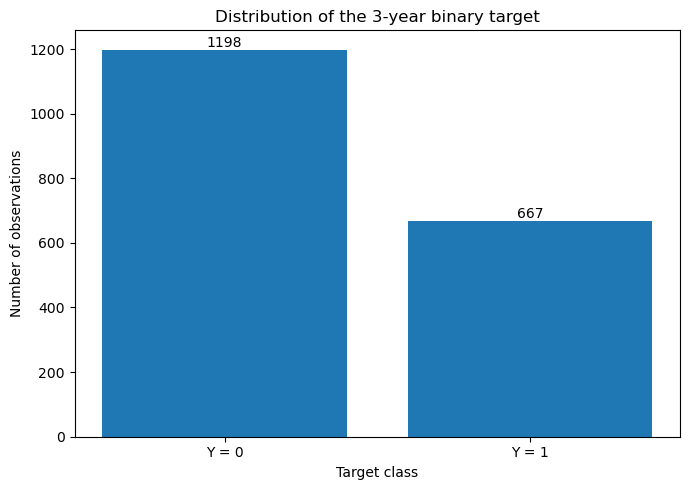

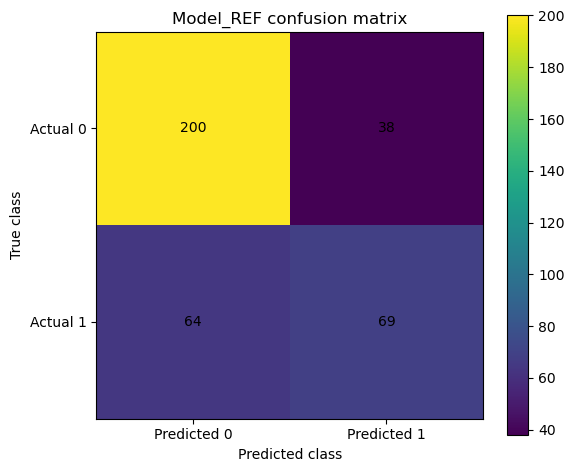

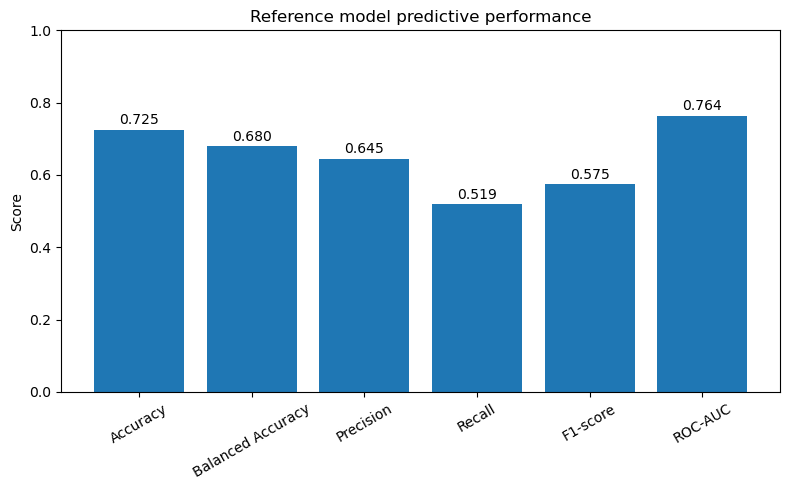

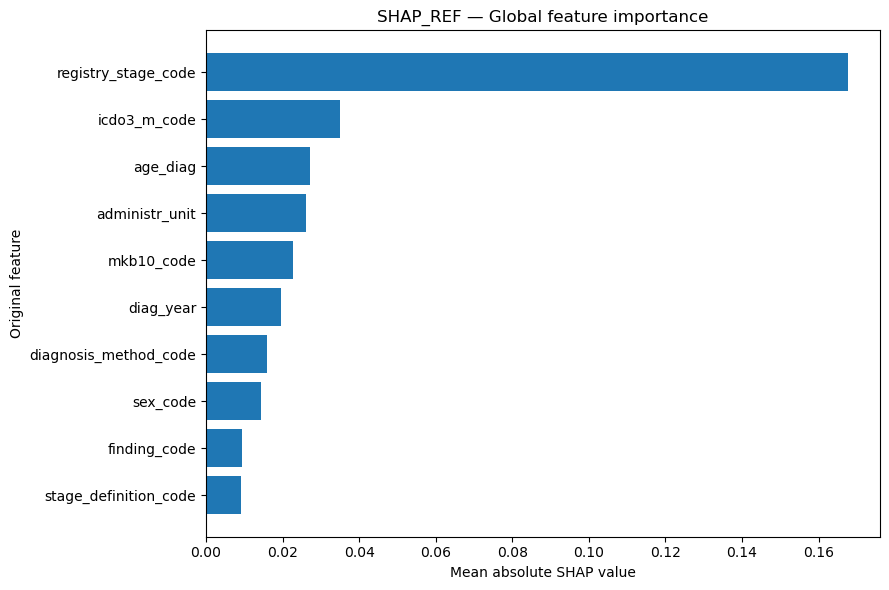

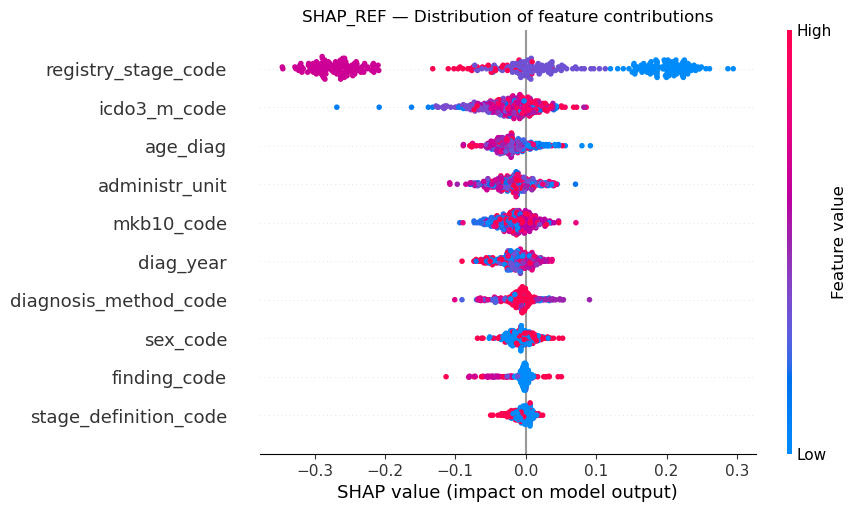

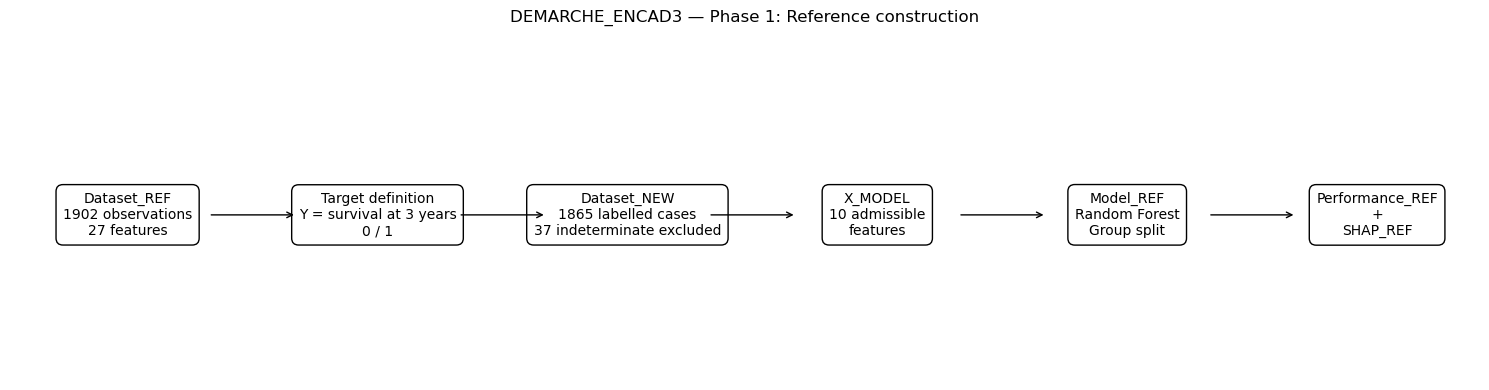


CONTROLE FINAL STEP 7

Model_REF réentraîné               : NON
Partition Train/Test modifiée      : NON
Correction ENCAD3                  : NON
Règles cachées utilisées           : NON

Observations expliquées            : 371
Features originales expliquées     : 10
Features après encodage            : 48

SHAP_REF calculé                   : OUI
Explication globale                : OUI
Explications locales               : OUI

Figures générées                   : 6
Tableaux générés                   : 6


Classement final SHAP_REF :
 rank               feature  mean_abs_SHAP  relative_importance_pct
    1   registry_stage_code       0.167674                48.380224
    2          icdo3_m_code       0.034918                10.075053
    3              age_diag       0.027211                 7.851284
    4        administr_unit       0.026027                 7.509713
    5            mkb10_code       0.022733                 6.559382
    6             diag_year       0.019502       

In [4]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 2
# PHASE 1 — REFERENCE
# STEP 7 — SHAP_REF + ARTEFACTS POUR LA REDACTION
#
# Objectifs :
#   1. Recharger exactement Model_REF
#   2. Reconstituer exactement le TEST de Step 6
#   3. Calculer SHAP_REF
#   4. Agréger le One-Hot vers les 10 features originales
#   5. Sauvegarder les explications globales et locales
#   6. Générer figures, tableaux et schéma de Phase 1
#
# IMPORTANT :
#   - PAS de réentraînement
#   - PAS de nouvelle partition
#   - PAS de correction ENCAD3
#   - PAS de règles cachées
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import joblib
import matplotlib.pyplot as plt

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# ------------------------------------------------------------
# 0. IMPORT SHAP
# ------------------------------------------------------------

try:
    import shap
except ImportError:
    raise ImportError(
        "Le package SHAP n'est pas installé.\n"
        "Dans Anaconda/Jupyter, exécuter d'abord :\n"
        "pip install shap"
    )

# ------------------------------------------------------------
# 1. CHEMINS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = PROJECT_ROOT / "CASE_STUDY_2_CANCER_REGISTRY"

DATA_PATH = (
    CASE_ROOT
    / "data"
    / "reference"
    / "dataset_new.csv"
)

MODEL_PATH = (
    CASE_ROOT
    / "models"
    / "Model_REF_random_forest.joblib"
)

RESULT_DIR = (
    CASE_ROOT
    / "results"
    / "01_reference"
)

SPLIT_PATH = (
    RESULT_DIR
    / "step6_train_test_split.csv"
)

PERFORMANCE_PATH = (
    RESULT_DIR
    / "step6_performance_ref.json"
)

# Dossier spécifique aux artefacts SHAP_REF
SHAP_DIR = RESULT_DIR / "step7_shap_ref"
SHAP_DIR.mkdir(parents=True, exist_ok=True)

# Dossier spécifique aux figures de rédaction
FIG_DIR = SHAP_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# Dossier spécifique aux tableaux de rédaction
TABLE_DIR = SHAP_DIR / "tables"
TABLE_DIR.mkdir(parents=True, exist_ok=True)

# ------------------------------------------------------------
# 2. CHARGEMENT
# ------------------------------------------------------------

df = pd.read_csv(DATA_PATH)
split_df = pd.read_csv(SPLIT_PATH)
model_ref = joblib.load(MODEL_PATH)

with open(PERFORMANCE_PATH, "r", encoding="utf-8") as f:
    performance_ref = json.load(f)

print("=" * 90)
print("PHASE 1 — REFERENCE")
print("STEP 7 — SHAP_REF + DOCUMENTATION DE L'EXPERIENCE")
print("=" * 90)

print(f"\nDataset_NEW : {df.shape}")
print(f"Model_REF   : {MODEL_PATH.name}")

# ------------------------------------------------------------
# 3. PROTOCOLE FIGE
# ------------------------------------------------------------

X_MODEL_FEATURES = [
    "sex_code",
    "age_diag",
    "diag_year",
    "mkb10_code",
    "icdo3_m_code",
    "registry_stage_code",
    "stage_definition_code",
    "diagnosis_method_code",
    "finding_code",
    "administr_unit"
]

TARGET = "Y_3years"

# ------------------------------------------------------------
# 4. RECONSTRUCTION EXACTE DU TEST
# ------------------------------------------------------------

assert len(split_df) == len(df), (
    "Le fichier de split ne correspond pas à Dataset_NEW."
)

test_indices = (
    split_df.loc[
        split_df["split"] == "TEST",
        "original_index"
    ]
    .astype(int)
    .tolist()
)

train_indices = (
    split_df.loc[
        split_df["split"] == "TRAIN",
        "original_index"
    ]
    .astype(int)
    .tolist()
)

X_test = df.loc[test_indices, X_MODEL_FEATURES].copy()
y_test = df.loc[test_indices, TARGET].astype(int).copy()

print("\nRéutilisation de la partition Step 6 :")
print(f"  TRAIN : {len(train_indices)}")
print(f"  TEST  : {len(test_indices)}")

assert len(test_indices) == 371
assert len(train_indices) == 1494

# ------------------------------------------------------------
# 5. VERIFICATION QUE MODEL_REF EST STRICTEMENT IDENTIQUE
# ------------------------------------------------------------

y_pred = model_ref.predict(X_test)
y_prob = model_ref.predict_proba(X_test)[:, 1]

accuracy = accuracy_score(y_test, y_pred)
balanced_accuracy = balanced_accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred, zero_division=0)
recall = recall_score(y_test, y_pred, zero_division=0)
f1 = f1_score(y_test, y_pred, zero_division=0)
roc_auc = roc_auc_score(y_test, y_prob)

print("\nVérification Performance_REF :")
print(f"  Accuracy          : {accuracy:.4f}")
print(f"  Balanced Accuracy : {balanced_accuracy:.4f}")
print(f"  Precision         : {precision:.4f}")
print(f"  Recall            : {recall:.4f}")
print(f"  F1                : {f1:.4f}")
print(f"  ROC-AUC           : {roc_auc:.4f}")

expected_accuracy = performance_ref["metrics"]["accuracy"]

assert np.isclose(
    accuracy,
    expected_accuracy
), "Model_REF ou TEST différent de Step 6."

print("\n[PASS] Model_REF et TEST identiques à Step 6.")

# ------------------------------------------------------------
# 6. EXTRACTION DU PREPROCESSOR ET DU RANDOM FOREST
# ------------------------------------------------------------

preprocessor = model_ref.named_steps["preprocessor"]
classifier = model_ref.named_steps["classifier"]

# Transformation du TEST avec le préprocesseur DEJA appris
X_test_transformed = preprocessor.transform(X_test)

# Noms des variables après transformation / One-Hot
transformed_feature_names = (
    preprocessor.get_feature_names_out()
)

print("\nAprès preprocessing :")
print(f"  X_TEST original    : {X_test.shape}")
print(f"  X_TEST transformé  : {X_test_transformed.shape}")
print(f"  Features encodées  : {len(transformed_feature_names)}")

# ------------------------------------------------------------
# 7. CALCUL SHAP SUR LE RANDOM FOREST
# ------------------------------------------------------------

print("\nCalcul SHAP_REF...")

explainer = shap.TreeExplainer(classifier)

raw_shap_values = explainer.shap_values(
    X_test_transformed
)

# ------------------------------------------------------------
# 8. NORMALISATION DES DIFFERENTS FORMATS SHAP
# ------------------------------------------------------------
#
# Selon la version de SHAP :
#
# ancien format :
#   liste [classe0, classe1]
#
# certains formats récents :
#   ndarray (n_samples, n_features, n_classes)
#
# autre possibilité :
#   ndarray (n_samples, n_features)
#
# Nous voulons TOUJOURS expliquer la classe 1.
# ------------------------------------------------------------

if isinstance(raw_shap_values, list):

    # classification binaire ancienne API
    shap_class1 = np.asarray(raw_shap_values[1])

elif isinstance(raw_shap_values, np.ndarray):

    if raw_shap_values.ndim == 3:

        # (samples, features, classes)
        shap_class1 = raw_shap_values[:, :, 1]

    elif raw_shap_values.ndim == 2:

        shap_class1 = raw_shap_values

    else:

        raise ValueError(
            f"Format SHAP inattendu : {raw_shap_values.shape}"
        )

else:

    raise TypeError(
        f"Type SHAP inattendu : {type(raw_shap_values)}"
    )

print(f"  SHAP classe 1 : {shap_class1.shape}")

assert shap_class1.shape[0] == len(X_test)
assert shap_class1.shape[1] == X_test_transformed.shape[1]

# ------------------------------------------------------------
# 9. TABLE SHAP AU NIVEAU DES FEATURES ENCODEES
# ------------------------------------------------------------

shap_encoded_df = pd.DataFrame(
    shap_class1,
    columns=transformed_feature_names,
    index=X_test.index
)

# ------------------------------------------------------------
# 10. MAPPING FEATURE ENCODEE -> FEATURE ORIGINALE
# ------------------------------------------------------------
#
# ColumnTransformer produit typiquement :
#
# numeric__age_diag
# categorical__sex_code_1
# categorical__sex_code_2
# ...
#
# Nous reconstruisons les contributions des 10 variables
# originales.
# ------------------------------------------------------------

def original_feature_from_encoded(encoded_name):

    # Supprimer préfixe ColumnTransformer
    if "__" in encoded_name:
        clean_name = encoded_name.split("__", 1)[1]
    else:
        clean_name = encoded_name

    # Variables numériques
    for feature in X_MODEL_FEATURES:

        if clean_name == feature:
            return feature

    # Variables catégorielles One-Hot
    #
    # On teste les noms les plus longs d'abord pour éviter
    # toute ambiguïté de préfixe.
    for feature in sorted(
        X_MODEL_FEATURES,
        key=len,
        reverse=True
    ):

        if clean_name.startswith(feature + "_"):
            return feature

    raise ValueError(
        f"Impossible de mapper : {encoded_name}"
    )


encoded_to_original = {
    encoded:
        original_feature_from_encoded(encoded)
    for encoded in transformed_feature_names
}

# Vérification
mapping_df = pd.DataFrame({
    "encoded_feature": list(encoded_to_original.keys()),
    "original_feature": list(encoded_to_original.values())
})

print("\nMapping des features encodées :")
print(mapping_df.to_string(index=False))

# ------------------------------------------------------------
# 11. AGREGER SHAP VERS LES 10 FEATURES ORIGINALES
# ------------------------------------------------------------

shap_original_df = pd.DataFrame(
    index=X_test.index
)

for feature in X_MODEL_FEATURES:

    encoded_columns = [
        encoded
        for encoded, original
        in encoded_to_original.items()
        if original == feature
    ]

    shap_original_df[feature] = (
        shap_encoded_df[encoded_columns]
        .sum(axis=1)
    )

assert shap_original_df.shape == (
    len(X_test),
    len(X_MODEL_FEATURES)
)

# ------------------------------------------------------------
# 12. IMPORTANCE SHAP GLOBALE
# ------------------------------------------------------------
#
# Mean Absolute SHAP :
#
# importance_j =
# mean_i |SHAP_ij|
#
# ------------------------------------------------------------

mean_abs_shap = (
    shap_original_df
    .abs()
    .mean(axis=0)
    .sort_values(ascending=False)
)

shap_ranking = (
    mean_abs_shap
    .reset_index()
)

shap_ranking.columns = [
    "feature",
    "mean_abs_SHAP"
]

shap_ranking["rank"] = (
    np.arange(
        1,
        len(shap_ranking) + 1
    )
)

shap_ranking = shap_ranking[
    ["rank", "feature", "mean_abs_SHAP"]
]

# Contribution relative (%)
total_shap = shap_ranking["mean_abs_SHAP"].sum()

shap_ranking["relative_importance_pct"] = (
    100
    * shap_ranking["mean_abs_SHAP"]
    / total_shap
)

print("\n" + "=" * 90)
print("CLASSEMENT GLOBAL SHAP_REF")
print("=" * 90)

print(
    shap_ranking.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 13. TABLEAU LOCAL SHAP PAR OBSERVATION
# ------------------------------------------------------------

local_shap_table = pd.DataFrame({
    "original_index": X_test.index,
    "registration_number":
        df.loc[X_test.index, "registration_number"].values,
    "disease_id":
        df.loc[X_test.index, "disease_id"].values,
    "Y_true": y_test.values,
    "Y_pred": y_pred,
    "P_Y1": y_prob
})

for feature in X_MODEL_FEATURES:
    local_shap_table[
        f"SHAP_{feature}"
    ] = shap_original_df[feature].values

# ------------------------------------------------------------
# 14. TABLEAU PERFORMANCE POUR L'ARTICLE
# ------------------------------------------------------------

performance_table = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Balanced Accuracy",
        "Precision",
        "Recall",
        "F1-score",
        "ROC-AUC"
    ],
    "Value": [
        accuracy,
        balanced_accuracy,
        precision,
        recall,
        f1,
        roc_auc
    ]
})

performance_table["Value"] = (
    performance_table["Value"].round(4)
)

# ------------------------------------------------------------
# 15. TABLEAU MATRICE DE CONFUSION
# ------------------------------------------------------------

cm = confusion_matrix(y_test, y_pred)

confusion_table = pd.DataFrame(
    cm,
    index=[
        "Actual Y=0",
        "Actual Y=1"
    ],
    columns=[
        "Predicted Y=0",
        "Predicted Y=1"
    ]
)

# ------------------------------------------------------------
# 16. FIGURE 1 — DISTRIBUTION DE Y
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(7, 5))

counts = (
    df[TARGET]
    .value_counts()
    .sort_index()
)

ax.bar(
    ["Y = 0", "Y = 1"],
    counts.values
)

ax.set_title(
    "Distribution of the 3-year binary target"
)

ax.set_ylabel("Number of observations")
ax.set_xlabel("Target class")

for i, value in enumerate(counts.values):
    ax.text(
        i,
        value,
        str(value),
        ha="center",
        va="bottom"
    )

fig.tight_layout()

fig1_path = FIG_DIR / "Figure_1_target_distribution.png"

fig.savefig(
    fig1_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 17. FIGURE 2 — MATRICE DE CONFUSION
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(6, 5))

im = ax.imshow(cm)

ax.set_xticks([0, 1])
ax.set_yticks([0, 1])

ax.set_xticklabels([
    "Predicted 0",
    "Predicted 1"
])

ax.set_yticklabels([
    "Actual 0",
    "Actual 1"
])

ax.set_xlabel("Predicted class")
ax.set_ylabel("True class")

ax.set_title(
    "Model_REF confusion matrix"
)

for i in range(2):
    for j in range(2):

        ax.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

fig.colorbar(im, ax=ax)

fig.tight_layout()

fig2_path = FIG_DIR / "Figure_2_confusion_matrix.png"

fig.savefig(
    fig2_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 18. FIGURE 3 — PERFORMANCE_REF
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    performance_table["Metric"],
    performance_table["Value"]
)

ax.set_ylim(0, 1)

ax.set_ylabel("Score")

ax.set_title(
    "Reference model predictive performance"
)

ax.tick_params(
    axis="x",
    rotation=30
)

for i, value in enumerate(
    performance_table["Value"]
):

    ax.text(
        i,
        value + 0.015,
        f"{value:.3f}",
        ha="center"
    )

fig.tight_layout()

fig3_path = FIG_DIR / "Figure_3_performance_ref.png"

fig.savefig(
    fig3_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 19. FIGURE 4 — SHAP GLOBAL IMPORTANCE
# ------------------------------------------------------------

ranking_plot = (
    shap_ranking
    .sort_values(
        "mean_abs_SHAP",
        ascending=True
    )
)

fig, ax = plt.subplots(figsize=(9, 6))

ax.barh(
    ranking_plot["feature"],
    ranking_plot["mean_abs_SHAP"]
)

ax.set_xlabel(
    "Mean absolute SHAP value"
)

ax.set_ylabel("Original feature")

ax.set_title(
    "SHAP_REF — Global feature importance"
)

fig.tight_layout()

fig4_path = (
    FIG_DIR
    / "Figure_4_SHAP_global_importance.png"
)

fig.savefig(
    fig4_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 20. FIGURE 5 — SHAP BEESWARM SUR FEATURES ORIGINALES
# ------------------------------------------------------------
#
# Pour un beeswarm lisible, il faut représenter les valeurs
# des features originales.
#
# Les variables catégorielles sont converties en codes
# uniquement pour la VISUALISATION.
#
# Cela ne modifie PAS le modèle.
# ------------------------------------------------------------

X_visual = X_test.copy()

for col in X_visual.columns:

    if col in CATEGORICAL_FEATURES if 'CATEGORICAL_FEATURES' in globals() else [
        "sex_code",
        "mkb10_code",
        "icdo3_m_code",
        "registry_stage_code",
        "stage_definition_code",
        "diagnosis_method_code",
        "finding_code",
        "administr_unit"
    ]:

        X_visual[col] = (
            X_visual[col]
            .astype("category")
            .cat.codes
        )

X_visual = X_visual.astype(float)

# Explanation objet pour API SHAP moderne
shap_explanation = shap.Explanation(
    values=shap_original_df.values,
    data=X_visual.values,
    feature_names=X_MODEL_FEATURES
)

plt.figure()

shap.plots.beeswarm(
    shap_explanation,
    max_display=len(X_MODEL_FEATURES),
    show=False
)

plt.title(
    "SHAP_REF — Distribution of feature contributions"
)

fig5_path = (
    FIG_DIR
    / "Figure_5_SHAP_beeswarm.png"
)

plt.savefig(
    fig5_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close()

# ------------------------------------------------------------
# 21. FIGURE 6 — SCHEMA DE LA PHASE 1
# ------------------------------------------------------------
#
# Schéma méthodologique directement réutilisable
# dans la rédaction de l'expérience.
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(15, 4))

ax.axis("off")

boxes = [
    (
        0.08,
        "Dataset_REF\n1902 observations\n27 features"
    ),
    (
        0.25,
        "Target definition\nY = survival at 3 years\n0 / 1"
    ),
    (
        0.42,
        "Dataset_NEW\n1865 labelled cases\n37 indeterminate excluded"
    ),
    (
        0.59,
        "X_MODEL\n10 admissible\nfeatures"
    ),
    (
        0.76,
        "Model_REF\nRandom Forest\nGroup split"
    ),
    (
        0.93,
        "Performance_REF\n+\nSHAP_REF"
    )
]

for x, text_box in boxes:

    ax.text(
        x,
        0.5,
        text_box,
        ha="center",
        va="center",
        transform=ax.transAxes,
        bbox=dict(
            boxstyle="round,pad=0.5",
            fill=False
        )
    )

for i in range(len(boxes) - 1):

    x1 = boxes[i][0] + 0.055
    x2 = boxes[i + 1][0] - 0.055

    ax.annotate(
        "",
        xy=(x2, 0.5),
        xytext=(x1, 0.5),
        xycoords=ax.transAxes,
        textcoords=ax.transAxes,
        arrowprops=dict(
            arrowstyle="->"
        )
    )

ax.set_title(
    "DEMARCHE_ENCAD3 — Phase 1: Reference construction",
    pad=20
)

fig.tight_layout()

fig6_path = (
    FIG_DIR
    / "Figure_6_Phase1_reference_workflow.png"
)

fig.savefig(
    fig6_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 22. SAUVEGARDE DES TABLEAUX
# ------------------------------------------------------------

ranking_path = (
    TABLE_DIR
    / "Table_SHAP_REF_global_ranking.csv"
)

local_path = (
    TABLE_DIR
    / "Table_SHAP_REF_local_values.csv"
)

performance_table_path = (
    TABLE_DIR
    / "Table_Performance_REF.csv"
)

confusion_table_path = (
    TABLE_DIR
    / "Table_Confusion_Matrix_REF.csv"
)

mapping_path = (
    TABLE_DIR
    / "Table_encoded_to_original_features.csv"
)

shap_ranking.to_csv(
    ranking_path,
    index=False
)

local_shap_table.to_csv(
    local_path,
    index=False
)

performance_table.to_csv(
    performance_table_path,
    index=False
)

confusion_table.to_csv(
    confusion_table_path
)

mapping_df.to_csv(
    mapping_path,
    index=False
)

# ------------------------------------------------------------
# 23. SAUVEGARDE NUMPY POUR COMPARAISONS FUTURES
# ------------------------------------------------------------
#
# Ces fichiers seront particulièrement importants pour :
#
# SHAP_REF vs SHAP_CORRECTED
#
# ------------------------------------------------------------

np.save(
    SHAP_DIR / "SHAP_REF_original_features.npy",
    shap_original_df.values
)

np.save(
    SHAP_DIR / "SHAP_REF_encoded_features.npy",
    shap_class1
)

# ------------------------------------------------------------
# 24. METADATA SHAP_REF
# ------------------------------------------------------------

metadata = {

    "phase": "01_reference",

    "step": "07_shap_ref",

    "model": "Model_REF_random_forest",

    "target": TARGET,

    "explained_class": 1,

    "n_test": int(len(X_test)),

    "n_original_features": int(
        len(X_MODEL_FEATURES)
    ),

    "n_encoded_features": int(
        len(transformed_feature_names)
    ),

    "global_importance_measure":
        "mean_absolute_SHAP",

    "aggregation":
        "sum_SHAP_of_encoded_components_per_original_feature",

    "model_retrained": False,

    "encad3_correction_applied": False,

    "hidden_reference_rules_used": False,

    "performance_ref": {
        "accuracy": float(accuracy),
        "balanced_accuracy":
            float(balanced_accuracy),
        "precision": float(precision),
        "recall": float(recall),
        "f1": float(f1),
        "roc_auc": float(roc_auc)
    },

    "top_features": (
        shap_ranking
        .head(10)
        .to_dict(orient="records")
    )
}

metadata_path = (
    SHAP_DIR
    / "step7_SHAP_REF_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 25. RESUME ARTICLE / TRACE EXPERIMENTALE
# ------------------------------------------------------------

summary_table = pd.DataFrame({
    "Experimental_component": [
        "Dataset_REF",
        "Indeterminate targets",
        "Dataset_NEW",
        "Target",
        "X_MODEL",
        "Train observations",
        "Test observations",
        "Model",
        "Accuracy",
        "Balanced Accuracy",
        "F1-score",
        "ROC-AUC",
        "Explainability method"
    ],

    "Value": [
        "1902 observations / 27 original features",
        "37 observations",
        "1865 observations / 27 original features + Y",
        "Binary 3-year status (0/1)",
        "10 features",
        str(len(train_indices)),
        str(len(test_indices)),
        "Random Forest",
        f"{accuracy:.4f}",
        f"{balanced_accuracy:.4f}",
        f"{f1:.4f}",
        f"{roc_auc:.4f}",
        "SHAP / TreeExplainer"
    ]
})

summary_path = (
    TABLE_DIR
    / "Table_Phase1_experimental_summary.csv"
)

summary_table.to_csv(
    summary_path,
    index=False
)

# ------------------------------------------------------------
# 26. CONTROLE FINAL
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("CONTROLE FINAL STEP 7")
print("=" * 90)

print(f"""
Model_REF réentraîné               : NON
Partition Train/Test modifiée      : NON
Correction ENCAD3                  : NON
Règles cachées utilisées           : NON

Observations expliquées            : {len(X_test)}
Features originales expliquées     : {len(X_MODEL_FEATURES)}
Features après encodage            : {len(transformed_feature_names)}

SHAP_REF calculé                   : OUI
Explication globale                : OUI
Explications locales               : OUI

Figures générées                   : 6
Tableaux générés                   : 6
""")

print("\nClassement final SHAP_REF :")

print(
    shap_ranking.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

print("\nFIGURES :")
for path in [
    fig1_path,
    fig2_path,
    fig3_path,
    fig4_path,
    fig5_path,
    fig6_path
]:
    print(f"  - {path}")

print("\nTABLEAUX :")
for path in [
    ranking_path,
    local_path,
    performance_table_path,
    confusion_table_path,
    mapping_path,
    summary_path
]:
    print(f"  - {path}")

print("\nARTEFACTS SHAP :")
print(
    f"  - {SHAP_DIR / 'SHAP_REF_original_features.npy'}"
)
print(
    f"  - {SHAP_DIR / 'SHAP_REF_encoded_features.npy'}"
)
print(f"  - {metadata_path}")

print("\nSTEP 7 TERMINEE.")
print(
    "Envoyer toute la sortie console, en particulier "
    "le classement SHAP_REF, avant de commencer la Phase 2."
)

PHASE 2 — KNOWLEDGE
STEP 8 — SELECTION DES FEATURES INFLUENTES + PREPARATION DU CORPUS RAG

Classement SHAP_REF chargé :
 rank               feature  mean_abs_SHAP  relative_importance_pct
    1   registry_stage_code       0.167674                48.380224
    2          icdo3_m_code       0.034918                10.075053
    3              age_diag       0.027211                 7.851284
    4        administr_unit       0.026027                 7.509713
    5            mkb10_code       0.022733                 6.559382
    6             diag_year       0.019502                 5.627107
    7 diagnosis_method_code       0.015825                 4.566010
    8              sex_code       0.014271                 4.117655
    9          finding_code       0.009299                 2.683247
   10 stage_definition_code       0.009116                 2.630324

-----------------------------------------------------------------------------------------------
SELECTION F_RAG
------------------

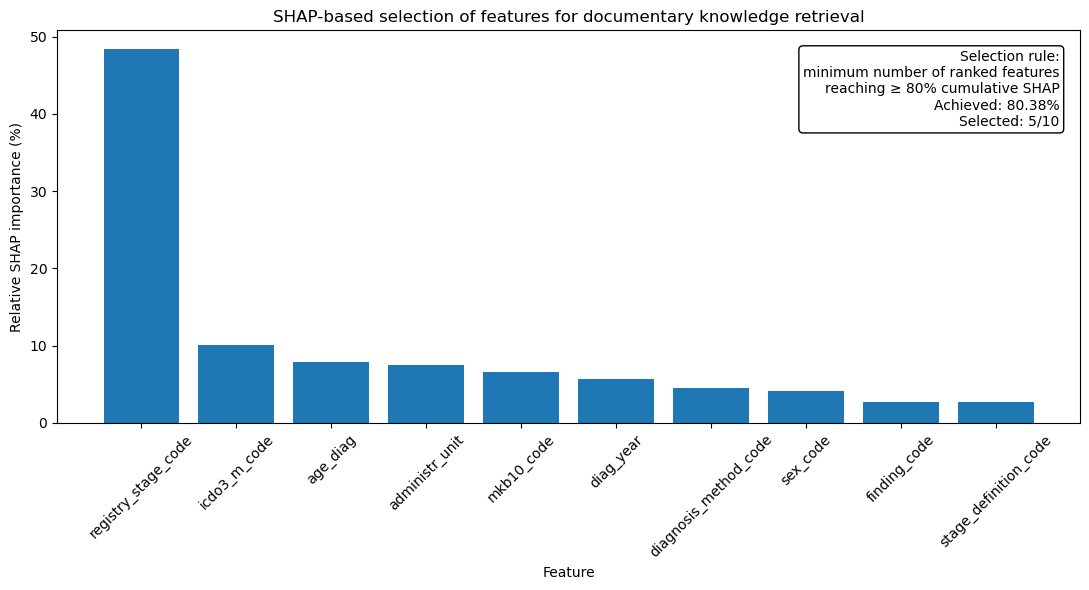

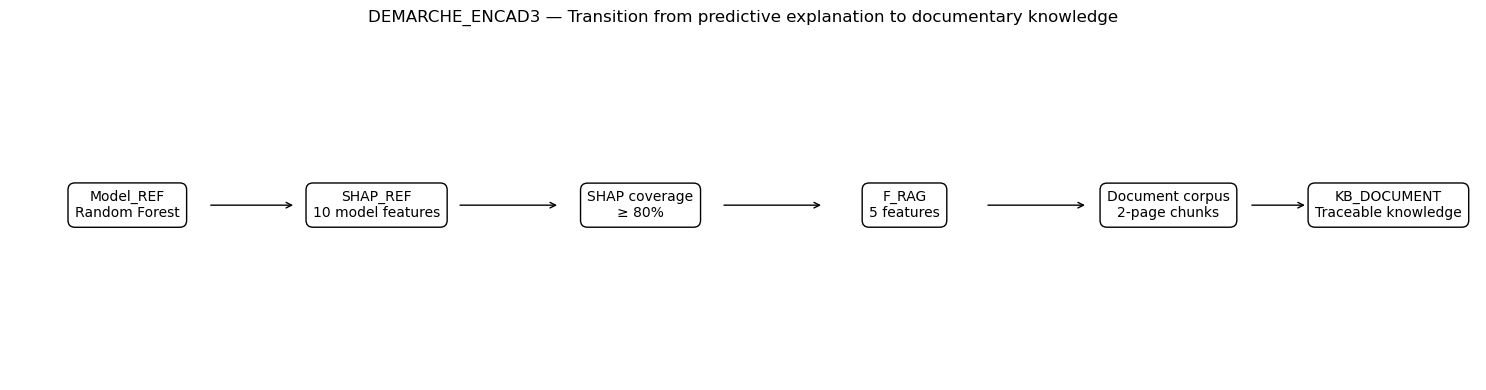


CONTROLE FINAL STEP 8

Features du modèle                  : 10
Features sélectionnées pour RAG     : 5

Critère                             : couverture SHAP cumulée
Seuil                               : 80.0 %
Couverture obtenue                  : 80.376 %

F_RAG :

  - registry_stage_code
  - icdo3_m_code
  - age_diag
  - administr_unit
  - mkb10_code


Documents actuellement dans raw     : 0

Chunking effectué                   : NON
GPT-5.6 Sol utilisé                  : NON
KB_DOCUMENT construite              : NON
KB_STATISTICAL construite           : NON

Diagnostic d'erreur                 : NON
Correction                          : NON

hidden_reference utilisé            : NON
Règles publiées utilisées           : NON

Fichiers produits :
  - C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_2_CANCER_REGISTRY\results\02_knowledge\step8_rag_scope\tables\Table_F_RAG_SHAP_selection.csv
  - C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3

In [5]:
# ============================================================
# DEMARCHE_ENCAD3 - CASE STUDY 2
# PHASE 2 — KNOWLEDGE
# STEP 8 — SELECTION DES FEATURES INFLUENTES
#          + PREPARATION DU CORPUS RAG
#
# Objectifs :
#   1. Charger le classement SHAP_REF
#   2. Sélectionner automatiquement les features expliquant
#      au moins 80 % de l'importance SHAP cumulée
#   3. Figer F_RAG
#   4. Associer les informations sémantiques disponibles
#   5. Inventorier les documents disponibles pour le RAG
#   6. Préparer la structure de traçabilité documentaire
#
# IMPORTANT :
#   - aucune erreur n'est diagnostiquée ici
#   - aucune correction n'est proposée
#   - aucun chunk n'est encore interprété
#   - aucune règle hidden_reference n'est utilisée
#   - GPT-5.6 Sol n'intervient pas encore
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# 1. CHEMINS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = PROJECT_ROOT / "CASE_STUDY_2_CANCER_REGISTRY"

RESULT_ROOT = (
    CASE_ROOT
    / "results"
)

PHASE1_DIR = (
    RESULT_ROOT
    / "01_reference"
)

SHAP_TABLE_PATH = (
    PHASE1_DIR
    / "step7_shap_ref"
    / "tables"
    / "Table_SHAP_REF_global_ranking.csv"
)

DICTIONARY_PATH = (
    CASE_ROOT
    / "data"
    / "dictionary"
    / "feature_dictionary.csv"
)

# ------------------------------------------------------------
# KNOWLEDGE DIRECTORIES
# ------------------------------------------------------------

KNOWLEDGE_DIR = (
    CASE_ROOT
    / "knowledge"
)

RAW_DOC_DIR = (
    KNOWLEDGE_DIR
    / "documents"
    / "raw"
)

EXTRACTED_DOC_DIR = (
    KNOWLEDGE_DIR
    / "documents"
    / "extracted"
)

STATISTICAL_DIR = (
    KNOWLEDGE_DIR
    / "statistical"
)

EXPERT_DIR = (
    KNOWLEDGE_DIR
    / "expert"
)

KB_DIR = (
    KNOWLEDGE_DIR
    / "knowledge_base"
)

for directory in [
    RAW_DOC_DIR,
    EXTRACTED_DOC_DIR,
    STATISTICAL_DIR,
    EXPERT_DIR,
    KB_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# PHASE 2 RESULTS
# ------------------------------------------------------------

PHASE2_DIR = (
    RESULT_ROOT
    / "02_knowledge"
)

STEP8_DIR = (
    PHASE2_DIR
    / "step8_rag_scope"
)

FIG_DIR = (
    STEP8_DIR
    / "figures"
)

TABLE_DIR = (
    STEP8_DIR
    / "tables"
)

for directory in [
    STEP8_DIR,
    FIG_DIR,
    TABLE_DIR
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

# ------------------------------------------------------------
# 2. CHARGEMENT DU CLASSEMENT SHAP_REF
# ------------------------------------------------------------

assert SHAP_TABLE_PATH.exists(), (
    f"Classement SHAP introuvable :\n{SHAP_TABLE_PATH}"
)

shap_df = pd.read_csv(
    SHAP_TABLE_PATH
)

required_columns = {
    "rank",
    "feature",
    "mean_abs_SHAP",
    "relative_importance_pct"
}

assert required_columns.issubset(
    shap_df.columns
), (
    "Colonnes SHAP attendues absentes."
)

shap_df = (
    shap_df
    .sort_values("rank")
    .reset_index(drop=True)
)

print("=" * 95)
print("PHASE 2 — KNOWLEDGE")
print("STEP 8 — SELECTION DES FEATURES INFLUENTES + PREPARATION DU CORPUS RAG")
print("=" * 95)

print("\nClassement SHAP_REF chargé :")

print(
    shap_df.to_string(
        index=False,
        float_format=lambda x: f"{x:.6f}"
    )
)

# ------------------------------------------------------------
# 3. IMPORTANCE SHAP CUMULEE
# ------------------------------------------------------------

shap_df[
    "cumulative_importance_pct"
] = (
    shap_df[
        "relative_importance_pct"
    ].cumsum()
)

# ------------------------------------------------------------
# 4. CRITERE DE SELECTION F_RAG
# ------------------------------------------------------------
#
# Principe expérimental :
#
# sélectionner le nombre minimal de features permettant
# d'expliquer AU MOINS 80 % de l'importance SHAP globale.
#
# Ce seuil est un PARAMETRE EXPERIMENTAL explicite.
# Il ne signifie PAS qu'une feature < 80 % cumulés est
# sans importance.
# ------------------------------------------------------------

SHAP_COVERAGE_THRESHOLD = 80.0

cumulative = (
    shap_df[
        "cumulative_importance_pct"
    ].values
)

n_selected = (
    np.searchsorted(
        cumulative,
        SHAP_COVERAGE_THRESHOLD,
        side="left"
    )
    + 1
)

selected_df = (
    shap_df
    .iloc[:n_selected]
    .copy()
)

selected_df[
    "selected_for_RAG"
] = True

selected_features = (
    selected_df[
        "feature"
    ].tolist()
)

achieved_coverage = float(
    selected_df[
        "relative_importance_pct"
    ].sum()
)

# Toutes les features :
shap_df[
    "selected_for_RAG"
] = (
    shap_df[
        "feature"
    ].isin(selected_features)
)

# ------------------------------------------------------------
# 5. AFFICHAGE F_RAG
# ------------------------------------------------------------

print("\n" + "-" * 95)
print("SELECTION F_RAG")
print("-" * 95)

print(
    f"\nSeuil de couverture SHAP : "
    f"{SHAP_COVERAGE_THRESHOLD:.1f}%"
)

print(
    f"Couverture obtenue       : "
    f"{achieved_coverage:.3f}%"
)

print(
    f"Nombre de features       : "
    f"{len(selected_features)}"
)

print("\nFeatures sélectionnées pour la recherche documentaire :")

for i, feature in enumerate(
    selected_features,
    start=1
):

    row = selected_df[
        selected_df["feature"] == feature
    ].iloc[0]

    print(
        f"  {i:02d}. "
        f"{feature:<25} "
        f"{row['relative_importance_pct']:.3f}%"
    )

# ------------------------------------------------------------
# 6. VERIFICATION ATTENDUE AVEC NOS RESULTATS STEP 7
# ------------------------------------------------------------

expected_features = [
    "registry_stage_code",
    "icdo3_m_code",
    "age_diag",
    "administr_unit",
    "mkb10_code"
]

if selected_features == expected_features:

    print(
        "\n[PASS] F_RAG conforme aux résultats SHAP_REF."
    )

else:

    print(
        "\n[INFO] F_RAG diffère de la liste attendue."
    )

    print(
        "La sélection réelle du fichier SHAP est conservée."
    )

# ------------------------------------------------------------
# 7. CHARGEMENT DU DICTIONNAIRE SEMANTIQUE MINIMAL
# ------------------------------------------------------------

dictionary_available = (
    DICTIONARY_PATH.exists()
)

if dictionary_available:

    dictionary_df = pd.read_csv(
        DICTIONARY_PATH
    )

    print(
        f"\nDictionnaire minimal chargé : "
        f"{len(dictionary_df)} définitions."
    )

else:

    dictionary_df = pd.DataFrame()

    print(
        "\n[WARNING] feature_dictionary.csv absent."
    )

# ------------------------------------------------------------
# 8. EXTRACTION DE LA SEMANTIQUE AUTORISEE POUR F_RAG
# ------------------------------------------------------------
#
# On ne complète RIEN manuellement.
#
# Si une feature n'est pas documentée :
# SEMANTIC_STATUS = NOT_DOCUMENTED
#
# Ceci est important notamment pour des variables pouvant être
# présentes dans Dataset_REF mais absentes du dictionnaire minimal.
# ------------------------------------------------------------

semantic_rows = []

for feature in selected_features:

    semantic_record = {
        "feature": feature,
        "SHAP_rank": int(
            shap_df.loc[
                shap_df["feature"] == feature,
                "rank"
            ].iloc[0]
        ),
        "relative_importance_pct": float(
            shap_df.loc[
                shap_df["feature"] == feature,
                "relative_importance_pct"
            ].iloc[0]
        ),
        "semantic_status": "NOT_DOCUMENTED"
    }

    if dictionary_available:

        # Chercher automatiquement la colonne feature
        possible_feature_columns = [
            c
            for c in dictionary_df.columns
            if c.lower() in [
                "feature",
                "variable",
                "variable_name",
                "name"
            ]
        ]

        if possible_feature_columns:

            feature_col = (
                possible_feature_columns[0]
            )

            matches = dictionary_df[
                dictionary_df[
                    feature_col
                ].astype(str) == feature
            ]

            if len(matches) > 0:

                row = matches.iloc[0]

                semantic_record[
                    "semantic_status"
                ] = "DOCUMENTED"

                # On copie uniquement les colonnes existantes.
                # Aucune information n'est inventée.
                for col in dictionary_df.columns:

                    if col != feature_col:

                        value = row[col]

                        if pd.notna(value):

                            semantic_record[
                                f"dictionary_{col}"
                            ] = str(value)

    semantic_rows.append(
        semantic_record
    )

semantic_scope_df = pd.DataFrame(
    semantic_rows
)

print("\n" + "-" * 95)
print("COUVERTURE SEMANTIQUE DE F_RAG")
print("-" * 95)

display_columns = [
    c for c in [
        "feature",
        "SHAP_rank",
        "relative_importance_pct",
        "semantic_status"
    ]
    if c in semantic_scope_df.columns
]

print(
    semantic_scope_df[
        display_columns
    ].to_string(
        index=False
    )
)

# ------------------------------------------------------------
# 9. INVENTAIRE DES DOCUMENTS RAG AUTORISES
# ------------------------------------------------------------
#
# IMPORTANT :
#
# SEUL knowledge/documents/raw est considéré comme corpus RAG.
#
# hidden_reference est explicitement exclu.
# ------------------------------------------------------------

allowed_extensions = {
    ".pdf",
    ".txt",
    ".md",
    ".docx",
    ".html",
    ".htm"
}

raw_documents = []

for path in sorted(
    RAW_DOC_DIR.rglob("*")
):

    if (
        path.is_file()
        and path.suffix.lower()
        in allowed_extensions
    ):

        # Hash pour traçabilité documentaire
        sha256 = hashlib.sha256(
            path.read_bytes()
        ).hexdigest()

        raw_documents.append({
            "document_id":
                f"DOC_{len(raw_documents)+1:03d}",
            "filename":
                path.name,
            "extension":
                path.suffix.lower(),
            "relative_path":
                str(
                    path.relative_to(
                        CASE_ROOT
                    )
                ),
            "size_bytes":
                path.stat().st_size,
            "sha256":
                sha256,
            "rag_authorized":
                True
        })

documents_df = pd.DataFrame(
    raw_documents
)

print("\n" + "-" * 95)
print("CORPUS DOCUMENTAIRE ACTUEL")
print("-" * 95)

if len(documents_df) == 0:

    print(
        "\nAucun document actuellement présent dans :"
    )

    print(
        f"  {RAW_DOC_DIR}"
    )

    print(
        "\nLes documents scientifiques / officiels "
        "autorisés devront être placés dans ce dossier "
        "avant l'étape de chunking."
    )

else:

    print(
        f"\nDocuments autorisés : "
        f"{len(documents_df)}"
    )

    print(
        documents_df[
            [
                "document_id",
                "filename",
                "extension",
                "size_bytes"
            ]
        ].to_string(
            index=False
        )
    )

# ------------------------------------------------------------
# 10. VERIFICATION DE L'ISOLATION hidden_reference
# ------------------------------------------------------------

HIDDEN_REFERENCE_DIR = (
    CASE_ROOT
    / "hidden_reference"
)

hidden_exists = (
    HIDDEN_REFERENCE_DIR.exists()
)

print("\n" + "-" * 95)
print("CONTROLE ANTI-CONTAMINATION")
print("-" * 95)

print(
    f"\nhidden_reference existe : "
    f"{hidden_exists}"
)

print(
    "hidden_reference inclus dans corpus RAG : NON"
)

print(
    "Règles publiées utilisées à Step 8       : NON"
)

# ------------------------------------------------------------
# 11. CREATION DU MANIFESTE DE RECHERCHE DOCUMENTAIRE
# ------------------------------------------------------------
#
# Une ligne par feature sélectionnée.
#
# Les requêtes définitives seront enrichies plus tard à partir
# de la sémantique réellement documentée.
# ------------------------------------------------------------

query_manifest_rows = []

for _, row in semantic_scope_df.iterrows():

    feature = row["feature"]

    query_manifest_rows.append({
        "feature": feature,
        "SHAP_rank":
            row["SHAP_rank"],
        "relative_importance_pct":
            row["relative_importance_pct"],
        "semantic_status":
            row["semantic_status"],

        "search_scope":
            "DOCUMENTARY_KNOWLEDGE",

        "knowledge_targets":
            (
                "SEMANTICS | DOMAIN_CONSTRAINT | "
                "ERROR | DETECTION | CORRECTION"
            ),

        "rag_status":
            "PENDING_CHUNKING",

        "expert_source":
            "NOT_AVAILABLE",

        "hidden_reference_allowed":
            False
    })

query_manifest_df = pd.DataFrame(
    query_manifest_rows
)

# ------------------------------------------------------------
# 12. FIGURE — COUVERTURE SHAP ET F_RAG
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(11, 6)
)

plot_df = (
    shap_df
    .sort_values(
        "rank",
        ascending=True
    )
)

bars = ax.bar(
    plot_df["feature"],
    plot_df["relative_importance_pct"]
)

ax.set_ylabel(
    "Relative SHAP importance (%)"
)

ax.set_xlabel(
    "Feature"
)

ax.set_title(
    "SHAP-based selection of features for documentary knowledge retrieval"
)

ax.tick_params(
    axis="x",
    rotation=45
)

# Seuil cumulatif expliqué dans une annotation
ax.text(
    0.98,
    0.95,
    (
        f"Selection rule:\n"
        f"minimum number of ranked features\n"
        f"reaching ≥ {SHAP_COVERAGE_THRESHOLD:.0f}% "
        f"cumulative SHAP\n"
        f"Achieved: {achieved_coverage:.2f}%\n"
        f"Selected: {len(selected_features)}/"
        f"{len(shap_df)}"
    ),
    transform=ax.transAxes,
    ha="right",
    va="top",
    bbox=dict(
        boxstyle="round",
        fill=False
    )
)

fig.tight_layout()

figure_path = (
    FIG_DIR
    / "Figure_7_SHAP_selection_for_RAG.png"
)

fig.savefig(
    figure_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 13. FIGURE — SCHEMA PHASE 1 -> PHASE 2
# ------------------------------------------------------------

fig, ax = plt.subplots(
    figsize=(15, 4)
)

ax.axis("off")

workflow = [
    (
        0.08,
        "Model_REF\nRandom Forest"
    ),
    (
        0.25,
        "SHAP_REF\n10 model features"
    ),
    (
        0.43,
        f"SHAP coverage\n≥ {SHAP_COVERAGE_THRESHOLD:.0f}%"
    ),
    (
        0.61,
        f"F_RAG\n{len(selected_features)} features"
    ),
    (
        0.79,
        "Document corpus\n2-page chunks"
    ),
    (
        0.94,
        "KB_DOCUMENT\nTraceable knowledge"
    )
]

for x, label in workflow:

    ax.text(
        x,
        0.5,
        label,
        ha="center",
        va="center",
        transform=ax.transAxes,
        bbox=dict(
            boxstyle="round,pad=0.5",
            fill=False
        )
    )

for i in range(
    len(workflow) - 1
):

    ax.annotate(
        "",
        xy=(
            workflow[i + 1][0] - 0.055,
            0.5
        ),
        xytext=(
            workflow[i][0] + 0.055,
            0.5
        ),
        xycoords=ax.transAxes,
        textcoords=ax.transAxes,
        arrowprops=dict(
            arrowstyle="->"
        )
    )

ax.set_title(
    "DEMARCHE_ENCAD3 — Transition from predictive explanation to documentary knowledge"
)

fig.tight_layout()

workflow_path = (
    FIG_DIR
    / "Figure_8_Phase1_to_Knowledge_RAG.png"
)

fig.savefig(
    workflow_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)

# ------------------------------------------------------------
# 14. SAUVEGARDE DES TABLEAUX
# ------------------------------------------------------------

selection_path = (
    TABLE_DIR
    / "Table_F_RAG_SHAP_selection.csv"
)

semantic_path = (
    TABLE_DIR
    / "Table_F_RAG_semantic_scope.csv"
)

documents_path = (
    TABLE_DIR
    / "Table_RAG_document_manifest.csv"
)

query_path = (
    TABLE_DIR
    / "Table_RAG_feature_manifest.csv"
)

shap_df.to_csv(
    selection_path,
    index=False
)

semantic_scope_df.to_csv(
    semantic_path,
    index=False
)

documents_df.to_csv(
    documents_path,
    index=False
)

query_manifest_df.to_csv(
    query_path,
    index=False
)

# ------------------------------------------------------------
# 15. METADATA STEP 8
# ------------------------------------------------------------

metadata = {

    "phase":
        "02_knowledge",

    "step":
        "08_shap_feature_selection_and_rag_scope",

    "selection_basis":
        "SHAP_REF",

    "selection_rule":
        (
            "minimum ranked features reaching "
            "the cumulative SHAP coverage threshold"
        ),

    "shap_coverage_threshold_pct":
        SHAP_COVERAGE_THRESHOLD,

    "achieved_coverage_pct":
        achieved_coverage,

    "n_model_features":
        int(len(shap_df)),

    "n_selected_features":
        int(len(selected_features)),

    "selected_features":
        selected_features,

    "rag_document_directory":
        str(RAW_DOC_DIR),

    "n_rag_documents_currently_available":
        int(len(documents_df)),

    "chunking_strategy_next_step":
        "approximately_2_pages_per_chunk",

    "knowledge_sources": {
        "DOCUMENT":
            "planned",
        "STATISTICAL":
            "planned_separately",
        "EXPERT":
            "not_available"
    },

    "llm_semantic_processor":
        "GPT-5.6 Sol",

    "llm_used_in_this_step":
        False,

    "hidden_reference_used":
        False,

    "published_reference_rules_used":
        False,

    "error_diagnosis_performed":
        False,

    "correction_performed":
        False
}

metadata_path = (
    STEP8_DIR
    / "step8_metadata.json"
)

with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=4,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 16. CONTROLE FINAL
# ------------------------------------------------------------

print("\n" + "=" * 95)
print("CONTROLE FINAL STEP 8")
print("=" * 95)

print(
    f"""
Features du modèle                  : {len(shap_df)}
Features sélectionnées pour RAG     : {len(selected_features)}

Critère                             : couverture SHAP cumulée
Seuil                               : {SHAP_COVERAGE_THRESHOLD:.1f} %
Couverture obtenue                  : {achieved_coverage:.3f} %

F_RAG :
"""
)

for feature in selected_features:
    print(f"  - {feature}")

print(
    f"""

Documents actuellement dans raw     : {len(documents_df)}

Chunking effectué                   : NON
GPT-5.6 Sol utilisé                  : NON
KB_DOCUMENT construite              : NON
KB_STATISTICAL construite           : NON

Diagnostic d'erreur                 : NON
Correction                          : NON

hidden_reference utilisé            : NON
Règles publiées utilisées           : NON
"""
)

print("Fichiers produits :")

for path in [
    selection_path,
    semantic_path,
    documents_path,
    query_path,
    metadata_path,
    figure_path,
    workflow_path
]:
    print(f"  - {path}")

print("\nSTEP 8 TERMINEE.")

if len(documents_df) == 0:

    print(
        "\nPROCHAINE CONDITION : "
        "placer les documents autorisés dans :"
    )
    print(f"  {RAW_DOC_DIR}")

else:

    print(
        "\nLe corpus documentaire est présent."
    )
    print(
        "La prochaine étape pourra effectuer "
        "l'extraction et le chunking traçable par 2 pages."
    )

In [6]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 2
# PHASE 2 — KNOWLEDGE
# STEP 9 — OFFICIAL RAG CORPUS PREPARATION + 2-PAGE CHUNKING
# ============================================================

from pathlib import Path
import hashlib
import json
import sys
import subprocess
import pandas as pd


# ============================================================
# 0. INSTALL / IMPORT PyPDF
# ============================================================

try:
    from pypdf import PdfReader
except ImportError:
    print("[INFO] Installation de pypdf...")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "pypdf"]
    )
    from pypdf import PdfReader


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = (
    PROJECT_ROOT
    / "CASE_STUDY_2_CANCER_REGISTRY"
)

RAW_DIR = (
    CASE_ROOT
    / "knowledge"
    / "documents"
    / "raw"
)

EXTRACTED_DIR = (
    CASE_ROOT
    / "knowledge"
    / "documents"
    / "extracted"
)

RESULTS_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step9_official_corpus"
)

TABLES_DIR = RESULTS_DIR / "tables"


# Create output directories if necessary
EXTRACTED_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. FROZEN F_RAG FROM STEP 8
# ============================================================

# These features were selected using the cumulative
# SHAP_REF coverage criterion >= 80%.
#
# IMPORTANT:
# This list must remain frozen during documentary processing.

F_RAG = [
    "registry_stage_code",
    "icdo3_m_code",
    "age_diag",
    "administr_unit",
    "mkb10_code",
]

SHAP_COVERAGE = 80.376


# ============================================================
# 3. OFFICIAL DOCUMENT CORPUS
#    REAL FILENAMES PRESENT IN knowledge/documents/raw
# ============================================================

DOCUMENTS = [

    # --------------------------------------------------------
    # DOC01 — ENCR / JRC
    # Cancer Data Quality Checks
    # --------------------------------------------------------
    {
        "document_id": "DOC01_ENCR_DQ_CHECKS",

        "filename":
            "A_proposal_on_cancer_data_quality_checks-"
            "one_common_procedure_for_European_cancer_"
            "registries_1_1.pdf",

        "institution":
            "ENCR / JRC - European Commission",

        "document_type":
            "OFFICIAL_DATA_QUALITY_PROCEDURE",

        "short_title":
            "Cancer Data Quality Checks v1.1",
    },


    # --------------------------------------------------------
    # DOC02 — IARC / WHO / IACR
    # Cancer Registration: Principles and Methods
    # --------------------------------------------------------
    {
        "document_id": "DOC02_IARC_SP95",

        "filename":
            "SP95.pdf",

        "institution":
            "WHO / IARC / IACR",

        "document_type":
            "OFFICIAL_CANCER_REGISTRATION_MANUAL",

        "short_title":
            "Cancer Registration: Principles and Methods",
    },


    # --------------------------------------------------------
    # DOC03 — ENCR 2023
    # Standard Dataset
    # --------------------------------------------------------
    {
        "document_id": "DOC03_ENCR_STANDARD_2023",

        "filename":
            "ENCR-Recommendation-standard-dataset_Mar2023.pdf",

        "institution":
            "ENCR / JRC - European Commission",

        "document_type":
            "OFFICIAL_RECOMMENDATION",

        "short_title":
            "ENCR Standard Dataset 2023",
    },


    # --------------------------------------------------------
    # DOC04 — WHO ICD-O
    # International Classification of Diseases for Oncology
    # --------------------------------------------------------
    {
        "document_id": "DOC04_WHO_ICDO3",

        "filename":
            "9789241548496_eng.pdf",

        "institution":
            "World Health Organization (WHO)",

        "document_type":
            "OFFICIAL_CLASSIFICATION",

        "short_title":
            "ICD-O-3 First Revision",
    },


    # --------------------------------------------------------
    # DOC05 — JRC / ENCR
    # Quality Check Software User Manual
    # --------------------------------------------------------
    {
        "document_id": "DOC05_JRC_ENCR_QCS",

        "filename":
            "user manual for the jrc-encr cancer registries "
            "data-LANA28109ENN.pdf",

        "institution":
            "JRC / ENCR - European Commission",

        "document_type":
            "OFFICIAL_TECHNICAL_MANUAL",

        "short_title":
            "JRC-ENCR Quality Check Software User Manual",
    },
]


# ============================================================
# 4. DISPLAY EXPERIMENTAL SCOPE
# ============================================================

print("=" * 90)
print("DEMARCHE_ENCAD3 — PHASE 2 / STEP 9")
print("OFFICIAL DOCUMENTARY CORPUS PREPARATION")
print("=" * 90)

print("\nCASE ROOT:")
print(CASE_ROOT)

print("\nRAW DOCUMENT DIRECTORY:")
print(RAW_DIR)

print("\nF_RAG frozen from Step 8:")

for i, feature in enumerate(F_RAG, start=1):
    print(f"  {i}. {feature}")

print(
    f"\nCumulative SHAP_REF coverage: "
    f"{SHAP_COVERAGE:.3f}%"
)


# ============================================================
# 5. SECURITY / ANTI-LEAKAGE CONTROL
# ============================================================

HIDDEN_REFERENCE_DIR = (
    CASE_ROOT
    / "hidden_reference"
)

# Ensure RAW_DIR is NOT inside hidden_reference
try:
    RAW_DIR.relative_to(HIDDEN_REFERENCE_DIR)

    raise RuntimeError(
        "SECURITY ERROR: RAW_DIR is located inside "
        "hidden_reference."
    )

except ValueError:
    pass


print("\n[ANTI-LEAKAGE CONTROL]")
print("hidden_reference directory:")
print(HIDDEN_REFERENCE_DIR)

print(
    "hidden_reference included in RAG corpus : NO"
)


# ============================================================
# 6. SHA-256 FUNCTION
# ============================================================

def sha256_file(
    path,
    block_size=1024 * 1024
):

    sha = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            block = f.read(block_size)

            if not block:
                break

            sha.update(block)

    return sha.hexdigest()


# ============================================================
# 7. VERIFY EXACTLY THE FIVE EXPECTED PDF FILES
# ============================================================

print("\n" + "=" * 90)
print("CORPUS FILE VERIFICATION")
print("=" * 90)


manifest_rows = []
missing_documents = []


for doc in DOCUMENTS:

    pdf_path = RAW_DIR / doc["filename"]

    if not pdf_path.exists():

        missing_documents.append(
            doc["filename"]
        )

        manifest_rows.append({

            "document_id":
                doc["document_id"],

            "short_title":
                doc["short_title"],

            "filename":
                doc["filename"],

            "institution":
                doc["institution"],

            "document_type":
                doc["document_type"],

            "path":
                str(pdf_path),

            "status":
                "MISSING",

            "n_pages":
                None,

            "file_size_mb":
                None,

            "sha256":
                None,
        })

        print(
            f"[MISSING] {doc['filename']}"
        )

        continue


    # --------------------------------------------------------
    # Open PDF
    # --------------------------------------------------------

    try:

        reader = PdfReader(
            str(pdf_path)
        )

        n_pages = len(
            reader.pages
        )

    except Exception as e:

        raise RuntimeError(
            f"Impossible d'ouvrir le PDF:\n"
            f"{pdf_path}\n"
            f"Erreur: {e}"
        )


    # --------------------------------------------------------
    # File metadata
    # --------------------------------------------------------

    size_mb = (
        pdf_path.stat().st_size
        / (1024 ** 2)
    )

    sha = sha256_file(
        pdf_path
    )


    manifest_rows.append({

        "document_id":
            doc["document_id"],

        "short_title":
            doc["short_title"],

        "filename":
            doc["filename"],

        "institution":
            doc["institution"],

        "document_type":
            doc["document_type"],

        "path":
            str(pdf_path),

        "status":
            "AVAILABLE",

        "n_pages":
            n_pages,

        "file_size_mb":
            round(size_mb, 3),

        "sha256":
            sha,
    })


    print(
        f"[OK] {doc['document_id']} "
        f"| {doc['filename']} "
        f"| pages={n_pages} "
        f"| size={size_mb:.2f} MB"
    )


# ============================================================
# 8. SAVE DOCUMENT MANIFEST
# ============================================================

manifest_df = pd.DataFrame(
    manifest_rows
)

manifest_path = (
    TABLES_DIR
    / "Table_Official_Document_Corpus.csv"
)

manifest_df.to_csv(
    manifest_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 9. STOP IF ONE OF THE FIVE DOCUMENTS IS MISSING
# ============================================================

if missing_documents:

    print("\n" + "=" * 90)
    print("[STOP] OFFICIAL CORPUS INCOMPLETE")
    print("=" * 90)

    print(
        "\nThe following expected PDF files "
        "were not found:"
    )

    for filename in missing_documents:
        print(f"  - {filename}")

    print("\nExpected directory:")
    print(RAW_DIR)

    raise FileNotFoundError(
        "The five official documents must be "
        "available before documentary extraction."
    )


print(
    "\n[PASS] All 5 official documents "
    "are available."
)


# ============================================================
# 10. EXTRACT TEXT PAGE BY PAGE
# ============================================================

print("\n" + "=" * 90)
print("PAGE-BY-PAGE TEXT EXTRACTION")
print("=" * 90)


page_rows = []


for doc in DOCUMENTS:

    pdf_path = (
        RAW_DIR
        / doc["filename"]
    )

    reader = PdfReader(
        str(pdf_path)
    )

    print(
        f"\nExtracting: "
        f"{doc['document_id']} "
        f"({len(reader.pages)} pages)"
    )


    for page_index, page in enumerate(
        reader.pages
    ):

        page_number = (
            page_index + 1
        )

        extraction_error = None

        try:

            text = (
                page.extract_text()
                or ""
            )

        except Exception as e:

            text = ""

            extraction_error = str(e)


        # Basic cleaning only.
        # No semantic transformation.
        text = (
            text
            .replace("\x00", " ")
            .strip()
        )


        if len(text) > 0:

            text_status = (
                "TEXT_AVAILABLE"
            )

        else:

            text_status = (
                "NO_TEXT_EXTRACTED"
            )


        page_rows.append({

            "document_id":
                doc["document_id"],

            "short_title":
                doc["short_title"],

            "document_name":
                doc["filename"],

            "institution":
                doc["institution"],

            "document_type":
                doc["document_type"],

            "page_number":
                page_number,

            "n_characters":
                len(text),

            "text_status":
                text_status,

            "extraction_error":
                extraction_error,

            "text":
                text,
        })


pages_df = pd.DataFrame(
    page_rows
)


# ============================================================
# 11. SAVE PAGE-LEVEL CORPUS
# ============================================================

pages_path = (
    EXTRACTED_DIR
    / "official_documents_pages.csv"
)

pages_df.to_csv(
    pages_path,
    index=False,
    encoding="utf-8-sig"
)


print(
    f"\nTotal extracted pages: "
    f"{len(pages_df)}"
)


# ============================================================
# 12. PAGE EXTRACTION QUALITY CONTROL
# ============================================================

page_audit_df = (

    pages_df

    .groupby(
        [
            "document_id",
            "short_title"
        ],
        as_index=False
    )

    .agg(

        n_pages=(
            "page_number",
            "count"
        ),

        pages_with_text=(
            "text_status",
            lambda x:
                (
                    x
                    == "TEXT_AVAILABLE"
                ).sum()
        ),

        pages_without_text=(
            "text_status",
            lambda x:
                (
                    x
                    == "NO_TEXT_EXTRACTED"
                ).sum()
        ),

        total_characters=(
            "n_characters",
            "sum"
        ),

        median_characters_per_page=(
            "n_characters",
            "median"
        ),
    )
)


page_audit_path = (
    TABLES_DIR
    / "Table_Page_Extraction_Audit.csv"
)

page_audit_df.to_csv(
    page_audit_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 13. CREATE FIXED 2-PAGE CHUNKS
# ============================================================

CHUNK_SIZE_PAGES = 2

chunk_rows = []


for doc in DOCUMENTS:

    doc_pages = (

        pages_df[
            pages_df["document_id"]
            == doc["document_id"]
        ]

        .sort_values(
            "page_number"
        )

        .reset_index(
            drop=True
        )
    )


    chunk_counter = 1


    for start_index in range(
        0,
        len(doc_pages),
        CHUNK_SIZE_PAGES
    ):

        block = doc_pages.iloc[
            start_index:
            start_index + CHUNK_SIZE_PAGES
        ]


        page_start = int(
            block["page_number"].min()
        )

        page_end = int(
            block["page_number"].max()
        )


        text_parts = []


        for _, row in block.iterrows():

            text_parts.append(

                f"[DOCUMENT: "
                f"{doc['document_id']}]\n"

                f"[PAGE: "
                f"{int(row['page_number'])}]\n"

                f"{row['text']}"
            )


        chunk_text = (
            "\n\n".join(
                text_parts
            )
            .strip()
        )


        chunk_id = (

            f"{doc['document_id']}"
            f"_CHUNK_"
            f"{chunk_counter:04d}"
        )


        non_empty_pages = int(

            (
                block["text_status"]
                == "TEXT_AVAILABLE"
            ).sum()
        )


        if len(chunk_text) > 0:

            chunk_status = (
                "TEXT_AVAILABLE"
            )

        else:

            chunk_status = (
                "NO_TEXT_EXTRACTED"
            )


        chunk_rows.append({

            "chunk_id":
                chunk_id,

            "document_id":
                doc["document_id"],

            "short_title":
                doc["short_title"],

            "document_name":
                doc["filename"],

            "institution":
                doc["institution"],

            "document_type":
                doc["document_type"],

            "page_start":
                page_start,

            "page_end":
                page_end,

            "n_pages":
                len(block),

            "n_pages_with_text":
                non_empty_pages,

            "n_characters":
                len(chunk_text),

            "text_status":
                chunk_status,

            "text":
                chunk_text,
        })


        chunk_counter += 1


chunks_df = pd.DataFrame(
    chunk_rows
)


# ============================================================
# 14. SAVE 2-PAGE CHUNKS — CSV
# ============================================================

chunks_csv_path = (
    EXTRACTED_DIR
    / "official_documents_chunks_2pages.csv"
)

chunks_df.to_csv(
    chunks_csv_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 15. SAVE 2-PAGE CHUNKS — JSONL
# ============================================================

chunks_jsonl_path = (
    EXTRACTED_DIR
    / "official_documents_chunks_2pages.jsonl"
)


with open(
    chunks_jsonl_path,
    "w",
    encoding="utf-8"
) as f:

    for record in (
        chunks_df
        .to_dict(
            orient="records"
        )
    ):

        f.write(

            json.dumps(
                record,
                ensure_ascii=False
            )

            + "\n"
        )


# ============================================================
# 16. CHUNK AUDIT
# ============================================================

chunk_audit_df = (

    chunks_df

    .groupby(
        [
            "document_id",
            "short_title",
            "institution"
        ],
        as_index=False
    )

    .agg(

        n_chunks=(
            "chunk_id",
            "count"
        ),

        first_page=(
            "page_start",
            "min"
        ),

        last_page=(
            "page_end",
            "max"
        ),

        total_characters=(
            "n_characters",
            "sum"
        ),

        empty_chunks=(
            "text_status",
            lambda x:
                (
                    x
                    == "NO_TEXT_EXTRACTED"
                ).sum()
        ),
    )
)


chunk_audit_path = (
    TABLES_DIR
    / "Table_RAG_Chunk_Audit.csv"
)

chunk_audit_df.to_csv(
    chunk_audit_path,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 17. GLOBAL EXPERIMENTAL METADATA
# ============================================================

metadata = {

    "step":
        9,

    "phase":
        "KNOWLEDGE",

    "case_study":
        "CANCER_REGISTRY",

    "purpose":
        (
            "Prepare a traceable corpus of official "
            "institutional documents for blind "
            "RAG processing."
        ),

    "n_official_documents":
        len(DOCUMENTS),

    "official_document_ids":
        [
            d["document_id"]
            for d in DOCUMENTS
        ],

    "features_selected_by_SHAP":
        F_RAG,

    "SHAP_cumulative_coverage_percent":
        SHAP_COVERAGE,

    "chunking_strategy":
        "FIXED_NON_OVERLAPPING_PAGE_BLOCKS",

    "chunk_size_pages":
        CHUNK_SIZE_PAGES,

    "n_extracted_pages":
        int(
            len(pages_df)
        ),

    "n_chunks":
        int(
            len(chunks_df)
        ),

    "allowed_source_type":
        (
            "OFFICIAL_OR_INSTITUTIONAL_"
            "DOCUMENT_ONLY"
        ),

    "scientific_articles_used_as_RAG_source":
        False,

    "hidden_reference_used":
        False,

    "GPT_5_6_Sol_used":
        False,

    "knowledge_extraction_performed":
        False,

    "diagnosis_performed":
        False,

    "correction_performed":
        False,

    "important_principle":
        (
            "Step 9 performs documentary preparation "
            "only. Statistical observation is not "
            "converted into an established error."
        ),
}


metadata_path = (
    RESULTS_DIR
    / "step9_metadata.json"
)


with open(
    metadata_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 18. FINAL QUALITY CONTROLS
# ============================================================

empty_pages = int(

    (
        pages_df["text_status"]
        == "NO_TEXT_EXTRACTED"
    ).sum()
)


empty_chunks = int(

    (
        chunks_df["text_status"]
        == "NO_TEXT_EXTRACTED"
    ).sum()
)


# ============================================================
# 19. CONSOLE REPORT
# ============================================================

print("\n" + "=" * 90)
print("OFFICIAL DOCUMENT MANIFEST")
print("=" * 90)

print(

    manifest_df[
        [
            "document_id",
            "short_title",
            "filename",
            "institution",
            "n_pages",
            "status",
        ]
    ]

    .to_string(
        index=False
    )
)


print("\n" + "=" * 90)
print("PAGE EXTRACTION AUDIT")
print("=" * 90)

print(
    page_audit_df
    .to_string(
        index=False
    )
)


print("\n" + "=" * 90)
print("2-PAGE CHUNK AUDIT")
print("=" * 90)

print(
    chunk_audit_df
    .to_string(
        index=False
    )
)


print("\n" + "=" * 90)
print("STEP 9 SUMMARY")
print("=" * 90)

print(
    f"Official documents      : "
    f"{len(DOCUMENTS)}"
)

print(
    f"Extracted pages         : "
    f"{len(pages_df)}"
)

print(
    f"2-page chunks           : "
    f"{len(chunks_df)}"
)

print(
    f"Pages without text      : "
    f"{empty_pages}"
)

print(
    f"Empty chunks            : "
    f"{empty_chunks}"
)


print("\n[EXPERIMENTAL CONTROLS]")

print(
    "Scientific articles used as RAG source : NO"
)

print(
    "hidden_reference used                  : NO"
)

print(
    "GPT-5.6 Sol used                       : NO"
)

print(
    "Knowledge extracted                    : NO"
)

print(
    "Diagnosis performed                    : NO"
)

print(
    "Correction performed                   : NO"
)


print("\n[OUTPUT FILES]")

print(
    f"1. {manifest_path}"
)

print(
    f"2. {page_audit_path}"
)

print(
    f"3. {pages_path}"
)

print(
    f"4. {chunks_csv_path}"
)

print(
    f"5. {chunks_jsonl_path}"
)

print(
    f"6. {chunk_audit_path}"
)

print(
    f"7. {metadata_path}"
)


print("\n" + "=" * 90)

if empty_pages == 0:

    print(
        "[PASS] STEP 9 COMPLETED — "
        "ALL PDF PAGES CONTAIN EXTRACTABLE TEXT"
    )

else:

    print(
        "[WARNING] STEP 9 COMPLETED — "
        f"{empty_pages} PAGE(S) WITHOUT EXTRACTABLE TEXT"
    )

    print(
        "These pages must be inspected before "
        "the retrieval stage."
    )

print("=" * 90)

[INFO] Installation de pypdf...
DEMARCHE_ENCAD3 — PHASE 2 / STEP 9
OFFICIAL DOCUMENTARY CORPUS PREPARATION

CASE ROOT:
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_2_CANCER_REGISTRY

RAW DOCUMENT DIRECTORY:
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_2_CANCER_REGISTRY\knowledge\documents\raw

F_RAG frozen from Step 8:
  1. registry_stage_code
  2. icdo3_m_code
  3. age_diag
  4. administr_unit
  5. mkb10_code

Cumulative SHAP_REF coverage: 80.376%

[ANTI-LEAKAGE CONTROL]
hidden_reference directory:
C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_2_CANCER_REGISTRY\hidden_reference
hidden_reference included in RAG corpus : NO

CORPUS FILE VERIFICATION
[OK] DOC01_ENCR_DQ_CHECKS | A_proposal_on_cancer_data_quality_checks-one_common_procedure_for_European_cancer_registries_1_1.pdf | pages=104 | size=2.34 MB
[OK] DOC02_IARC_SP95 | SP95.pdf | pages=294 | size=15.26 MB
[OK] DOC03_ENCR_STANDARD_2023 | ENCR-R

In [7]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 2
# PHASE 2 — KNOWLEDGE
# STEP 9B — CONTROL OF NON-EXTRACTABLE PDF PAGES
# ============================================================

from pathlib import Path
import pandas as pd
import json

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = PROJECT_ROOT / "CASE_STUDY_2_CANCER_REGISTRY"

EXTRACTED_DIR = (
    CASE_ROOT
    / "knowledge"
    / "documents"
    / "extracted"
)

RESULTS_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step9_official_corpus"
)

TABLES_DIR = RESULTS_DIR / "tables"

PAGES_FILE = (
    EXTRACTED_DIR
    / "official_documents_pages.csv"
)

CHUNKS_FILE = (
    EXTRACTED_DIR
    / "official_documents_chunks_2pages.csv"
)

# ------------------------------------------------------------
# 2. LOAD STEP 9 OUTPUTS
# ------------------------------------------------------------

pages_df = pd.read_csv(PAGES_FILE)
chunks_df = pd.read_csv(CHUNKS_FILE)

print("=" * 90)
print("STEP 9B — NON-EXTRACTABLE PAGE CONTROL")
print("=" * 90)

print(f"\nPages loaded  : {len(pages_df)}")
print(f"Chunks loaded : {len(chunks_df)}")

# ------------------------------------------------------------
# 3. IDENTIFY PAGES WITHOUT EXTRACTABLE TEXT
# ------------------------------------------------------------

empty_pages_df = pages_df[
    pages_df["text_status"] == "NO_TEXT_EXTRACTED"
].copy()

print(f"\nPages without extractable text: {len(empty_pages_df)}")

# ------------------------------------------------------------
# 4. FIND THE 2-PAGE CHUNK CONTAINING EACH EMPTY PAGE
# ------------------------------------------------------------

def find_chunk(document_id, page_number):

    matches = chunks_df[
        (chunks_df["document_id"] == document_id)
        &
        (chunks_df["page_start"] <= page_number)
        &
        (chunks_df["page_end"] >= page_number)
    ]

    if len(matches) == 0:
        return pd.Series({
            "chunk_id": None,
            "chunk_page_start": None,
            "chunk_page_end": None,
            "chunk_characters": None,
            "chunk_text_status": None
        })

    row = matches.iloc[0]

    return pd.Series({
        "chunk_id": row["chunk_id"],
        "chunk_page_start": row["page_start"],
        "chunk_page_end": row["page_end"],
        "chunk_characters": row["n_characters"],
        "chunk_text_status": row["text_status"]
    })


chunk_info = empty_pages_df.apply(
    lambda row: find_chunk(
        row["document_id"],
        row["page_number"]
    ),
    axis=1
)

empty_pages_df = pd.concat(
    [
        empty_pages_df.reset_index(drop=True),
        chunk_info.reset_index(drop=True)
    ],
    axis=1
)

# ------------------------------------------------------------
# 5. ADD MANUAL-INSPECTION STATUS
# ------------------------------------------------------------

empty_pages_df["inspection_status"] = "TO_INSPECT"

empty_pages_df["decision"] = "PENDING"

empty_pages_df["decision_reason"] = ""

# ------------------------------------------------------------
# 6. SAVE TRACEABILITY TABLE
# ------------------------------------------------------------

OUTPUT_FILE = (
    TABLES_DIR
    / "Table_NonExtractable_Pages_Control.csv"
)

empty_pages_df.to_csv(
    OUTPUT_FILE,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 7. CONSOLE REPORT
# ------------------------------------------------------------

display_columns = [
    "document_id",
    "short_title",
    "document_name",
    "page_number",
    "n_characters",
    "chunk_id",
    "chunk_page_start",
    "chunk_page_end",
    "chunk_characters",
    "chunk_text_status",
]

print("\n" + "=" * 90)
print("PAGES REQUIRING INSPECTION")
print("=" * 90)

print(
    empty_pages_df[
        display_columns
    ].to_string(index=False)
)

# ------------------------------------------------------------
# 8. CHECK WHETHER ANY ENTIRE CHUNK IS EMPTY
# ------------------------------------------------------------

empty_chunks = chunks_df[
    chunks_df["text_status"] == "NO_TEXT_EXTRACTED"
]

print("\n" + "=" * 90)
print("CHUNK SAFETY CONTROL")
print("=" * 90)

print(f"Entirely empty chunks: {len(empty_chunks)}")

if len(empty_chunks) == 0:
    print(
        "[PASS] No complete 2-page chunk was lost."
    )
else:
    print(
        "[WARNING] At least one complete chunk "
        "contains no extractable text."
    )

# ------------------------------------------------------------
# 9. METADATA
# ------------------------------------------------------------

metadata = {
    "step": "9B",
    "phase": "KNOWLEDGE",
    "purpose": "Control pages without extractable PDF text",
    "n_pages_without_text": int(len(empty_pages_df)),
    "n_entirely_empty_chunks": int(len(empty_chunks)),
    "OCR_performed": False,
    "chunks_modified": False,
    "GPT_5_6_Sol_used": False,
    "knowledge_extracted": False,
    "diagnosis_performed": False,
    "hidden_reference_used": False,
}

metadata_file = (
    RESULTS_DIR
    / "step9B_nonextractable_pages_metadata.json"
)

with open(
    metadata_file,
    "w",
    encoding="utf-8"
) as f:
    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 10. FINAL SUMMARY
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("STEP 9B SUMMARY")
print("=" * 90)

print(f"Pages requiring inspection : {len(empty_pages_df)}")
print(f"Entirely empty chunks       : {len(empty_chunks)}")

print("\nOCR performed       : NO")
print("Chunks modified     : NO")
print("GPT-5.6 Sol used    : NO")
print("Knowledge extracted : NO")
print("Diagnosis performed : NO")
print("hidden_reference    : NO")

print("\nOUTPUT:")
print(OUTPUT_FILE)
print(metadata_file)

print("\n[PASS] STEP 9B CONTROL COMPLETED")

STEP 9B — NON-EXTRACTABLE PAGE CONTROL

Pages loaded  : 680
Chunks loaded : 340

Pages without extractable text: 6

PAGES REQUIRING INSPECTION
         document_id                                 short_title                                                                                        document_name  page_number  n_characters                        chunk_id  chunk_page_start  chunk_page_end  chunk_characters chunk_text_status
DOC01_ENCR_DQ_CHECKS             Cancer Data Quality Checks v1.1 A_proposal_on_cancer_data_quality_checks-one_common_procedure_for_European_cancer_registries_1_1.pdf            4             0 DOC01_ENCR_DQ_CHECKS_CHUNK_0002                 3               4               391    TEXT_AVAILABLE
DOC01_ENCR_DQ_CHECKS             Cancer Data Quality Checks v1.1 A_proposal_on_cancer_data_quality_checks-one_common_procedure_for_European_cancer_registries_1_1.pdf          102             0 DOC01_ENCR_DQ_CHECKS_CHUNK_0051               101             102         

In [8]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 2
# PHASE 2 — KNOWLEDGE
# STEP 9C — VISUAL EXPORT OF NON-EXTRACTABLE PDF PAGES
# ============================================================

from pathlib import Path
import sys
import subprocess
import json
import pandas as pd


# ============================================================
# 0. INSTALL / IMPORT PyMuPDF
# ============================================================

try:
    import fitz  # PyMuPDF
except ImportError:
    print("[INFO] Installation de PyMuPDF...")
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "PyMuPDF"]
    )
    import fitz


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = (
    PROJECT_ROOT
    / "CASE_STUDY_2_CANCER_REGISTRY"
)

RAW_DIR = (
    CASE_ROOT
    / "knowledge"
    / "documents"
    / "raw"
)

RESULTS_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step9_official_corpus"
)

TABLES_DIR = RESULTS_DIR / "tables"

VISUAL_DIR = (
    RESULTS_DIR
    / "nonextractable_pages_visual"
)

VISUAL_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. INPUT FROM STEP 9B
# ============================================================

CONTROL_FILE = (
    TABLES_DIR
    / "Table_NonExtractable_Pages_Control.csv"
)

if not CONTROL_FILE.exists():
    raise FileNotFoundError(
        f"Step 9B control file not found:\n{CONTROL_FILE}"
    )

control_df = pd.read_csv(
    CONTROL_FILE
)


# ============================================================
# 3. DOCUMENT MAPPING
# ============================================================

DOCUMENT_FILES = {

    "DOC01_ENCR_DQ_CHECKS":
        "A_proposal_on_cancer_data_quality_checks-"
        "one_common_procedure_for_European_cancer_"
        "registries_1_1.pdf",

    "DOC02_IARC_SP95":
        "SP95.pdf",

    "DOC03_ENCR_STANDARD_2023":
        "ENCR-Recommendation-standard-dataset_Mar2023.pdf",

    "DOC04_WHO_ICDO3":
        "9789241548496_eng.pdf",

    "DOC05_JRC_ENCR_QCS":
        "user manual for the jrc-encr cancer registries "
        "data-LANA28109ENN.pdf",
}


# ============================================================
# 4. INITIAL CONTROL
# ============================================================

print("=" * 90)
print("DEMARCHE_ENCAD3 — STEP 9C")
print("VISUAL CONTROL OF NON-EXTRACTABLE PDF PAGES")
print("=" * 90)

print(
    f"\nPages requiring visual inspection: "
    f"{len(control_df)}"
)

if len(control_df) == 0:
    raise RuntimeError(
        "No non-extractable page was found in Step 9B."
    )


print("\nPages to inspect:")

for _, row in control_df.iterrows():

    print(
        f"  - {row['document_id']} "
        f"| page {int(row['page_number'])}"
    )


# ============================================================
# 5. EXPORT THE SIX PAGES AS PNG
# ============================================================

# Rendering resolution.
# 2.5x gives sufficient quality for visual inspection
# while keeping files reasonably small.

ZOOM = 2.5

matrix = fitz.Matrix(
    ZOOM,
    ZOOM
)

visual_rows = []


for _, row in control_df.iterrows():

    document_id = row["document_id"]
    page_number = int(row["page_number"])

    if document_id not in DOCUMENT_FILES:

        raise KeyError(
            f"Unknown document_id: {document_id}"
        )

    filename = DOCUMENT_FILES[
        document_id
    ]

    pdf_path = (
        RAW_DIR
        / filename
    )

    if not pdf_path.exists():

        raise FileNotFoundError(
            f"PDF not found:\n{pdf_path}"
        )


    # --------------------------------------------------------
    # Open PDF
    # --------------------------------------------------------

    pdf = fitz.open(
        str(pdf_path)
    )


    # PDF page index is zero-based
    page_index = (
        page_number - 1
    )


    if (
        page_index < 0
        or
        page_index >= len(pdf)
    ):

        pdf.close()

        raise IndexError(
            f"Invalid page number "
            f"{page_number} for {filename}"
        )


    page = pdf[
        page_index
    ]


    # --------------------------------------------------------
    # Render page
    # --------------------------------------------------------

    pixmap = page.get_pixmap(
        matrix=matrix,
        alpha=False
    )


    output_name = (
        f"{document_id}"
        f"_PAGE_{page_number:03d}.png"
    )

    output_path = (
        VISUAL_DIR
        / output_name
    )


    pixmap.save(
        str(output_path)
    )


    width = pixmap.width
    height = pixmap.height

    pdf.close()


    visual_rows.append({

        "document_id":
            document_id,

        "document_name":
            filename,

        "page_number":
            page_number,

        "png_file":
            output_name,

        "png_path":
            str(output_path),

        "width_px":
            width,

        "height_px":
            height,

        "inspection_status":
            "TO_INSPECT",

        "content_type":
            "PENDING",

        "relevant_information_present":
            "PENDING",

        "decision":
            "PENDING",

        "decision_reason":
            "",
    })


    print(
        f"[OK] {document_id} "
        f"| page={page_number} "
        f"| {width}x{height}px"
    )


# ============================================================
# 6. CREATE VISUAL INSPECTION TABLE
# ============================================================

visual_df = pd.DataFrame(
    visual_rows
)


inspection_table = (
    TABLES_DIR
    / "Table_Visual_Inspection_NonExtractable_Pages.csv"
)


visual_df.to_csv(
    inspection_table,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 7. CHECK GENERATED PNG FILES
# ============================================================

missing_png = []

for path in visual_df["png_path"]:

    if not Path(path).exists():
        missing_png.append(path)


print("\n" + "=" * 90)
print("PNG EXPORT CONTROL")
print("=" * 90)

print(
    f"Expected PNG files : "
    f"{len(visual_df)}"
)

print(
    f"Generated PNG files: "
    f"{len(visual_df) - len(missing_png)}"
)

print(
    f"Missing PNG files  : "
    f"{len(missing_png)}"
)


if missing_png:

    print("\nMissing:")

    for path in missing_png:
        print(path)

    raise RuntimeError(
        "Some visual inspection images were not generated."
    )


# ============================================================
# 8. METADATA
# ============================================================

metadata = {

    "step":
        "9C",

    "phase":
        "KNOWLEDGE",

    "purpose":
        (
            "Export non-extractable PDF pages "
            "as high-resolution images for "
            "manual visual inspection."
        ),

    "n_pages_exported":
        int(len(visual_df)),

    "rendering_zoom":
        ZOOM,

    "OCR_performed":
        False,

    "automatic_semantic_interpretation":
        False,

    "chunks_modified":
        False,

    "GPT_5_6_Sol_used":
        False,

    "knowledge_extracted":
        False,

    "diagnosis_performed":
        False,

    "hidden_reference_used":
        False,
}


metadata_file = (
    RESULTS_DIR
    / "step9C_visual_inspection_metadata.json"
)


with open(
    metadata_file,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 9. FINAL REPORT
# ============================================================

print("\n" + "=" * 90)
print("STEP 9C — GENERATED FILES")
print("=" * 90)


print(
    visual_df[
        [
            "document_id",
            "page_number",
            "png_file",
            "width_px",
            "height_px"
        ]
    ].to_string(
        index=False
    )
)


print("\nImages directory:")
print(VISUAL_DIR)

print("\nInspection table:")
print(inspection_table)

print("\nMetadata:")
print(metadata_file)


print("\n" + "=" * 90)
print("EXPERIMENTAL CONTROLS")
print("=" * 90)

print("OCR performed                   : NO")
print("Automatic interpretation        : NO")
print("Chunks modified                 : NO")
print("GPT-5.6 Sol used                : NO")
print("Knowledge extracted             : NO")
print("Diagnosis performed             : NO")
print("hidden_reference used           : NO")


print("\n" + "=" * 90)
print("[PASS] STEP 9C — VISUAL EXPORT COMPLETED")
print("=" * 90)

print(
    "\nOpen the 6 generated PNG files and inspect them visually."
)

print(
    "Do NOT modify the RAG corpus yet."
)

DEMARCHE_ENCAD3 — STEP 9C
VISUAL CONTROL OF NON-EXTRACTABLE PDF PAGES

Pages requiring visual inspection: 6

Pages to inspect:
  - DOC01_ENCR_DQ_CHECKS | page 4
  - DOC01_ENCR_DQ_CHECKS | page 102
  - DOC02_IARC_SP95 | page 1
  - DOC04_WHO_ICDO3 | page 7
  - DOC04_WHO_ICDO3 | page 41
  - DOC04_WHO_ICDO3 | page 103
[OK] DOC01_ENCR_DQ_CHECKS | page=4 | 1489x2106px
[OK] DOC01_ENCR_DQ_CHECKS | page=102 | 1489x2106px
[OK] DOC02_IARC_SP95 | page=1 | 1488x2091px
[OK] DOC04_WHO_ICDO3 | page=7 | 1489x2105px
[OK] DOC04_WHO_ICDO3 | page=41 | 1489x2105px
[OK] DOC04_WHO_ICDO3 | page=103 | 1489x2105px

PNG EXPORT CONTROL
Expected PNG files : 6
Generated PNG files: 6
Missing PNG files  : 0

STEP 9C — GENERATED FILES
         document_id  page_number                          png_file  width_px  height_px
DOC01_ENCR_DQ_CHECKS            4 DOC01_ENCR_DQ_CHECKS_PAGE_004.png      1489       2106
DOC01_ENCR_DQ_CHECKS          102 DOC01_ENCR_DQ_CHECKS_PAGE_102.png      1489       2106
     DOC02_IARC_SP95  

DEMARCHE_ENCAD3 — PHASE 2 / STEP 10
TRACEABLE FEATURE–CHUNK DOCUMENT RETRIEVAL

Official chunks loaded : 340
F_RAG features         : 5
Potential feature–chunk pairs : 1700

Minimal dictionary rows: 10

Dictionary columns:
['feature', 'description', 'type', 'role', 'coding_values']

Feature column detected     : feature
Description column detected : description

RETRIEVAL QUERIES
            feature semantic_status                    query_source                    retrieval_query
registry_stage_code      DOCUMENTED FEATURE_NAME+MINIMAL_DICTIONARY registry stage code registry stage
       icdo3_m_code  NOT_DOCUMENTED               FEATURE_NAME_ONLY                       icdo3 m code
           age_diag      DOCUMENTED FEATURE_NAME+MINIMAL_DICTIONARY  age diag age at diagnosis (years)
     administr_unit  NOT_DOCUMENTED               FEATURE_NAME_ONLY                     administr unit
         mkb10_code      DOCUMENTED FEATURE_NAME+MINIMAL_DICTIONARY  mkb10 code ICD-10 topography code

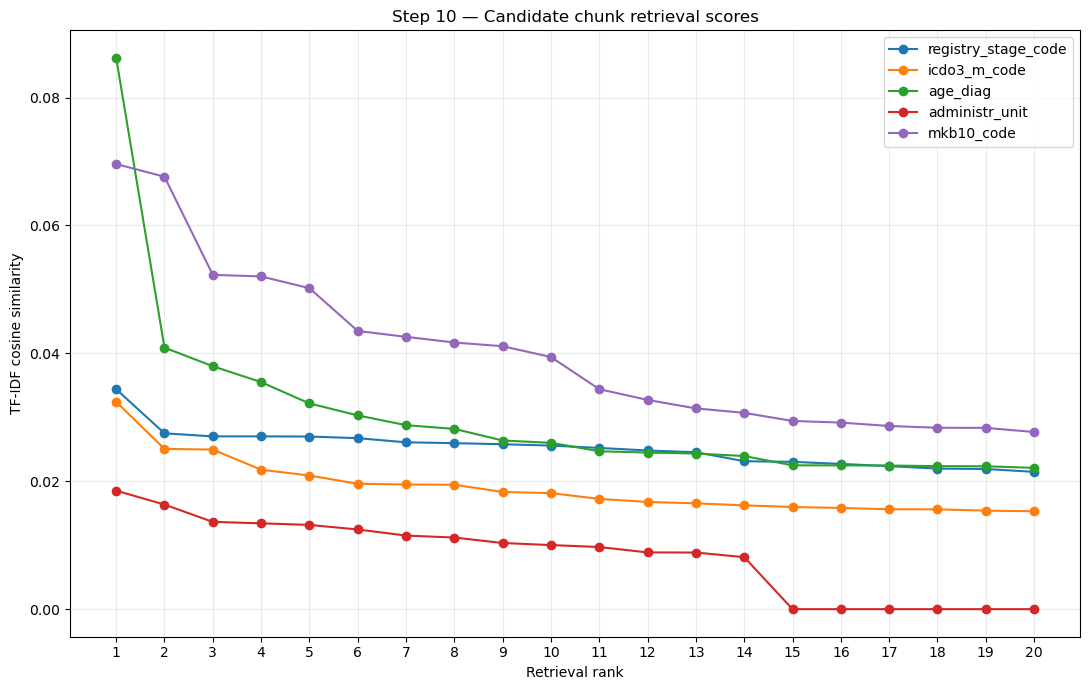

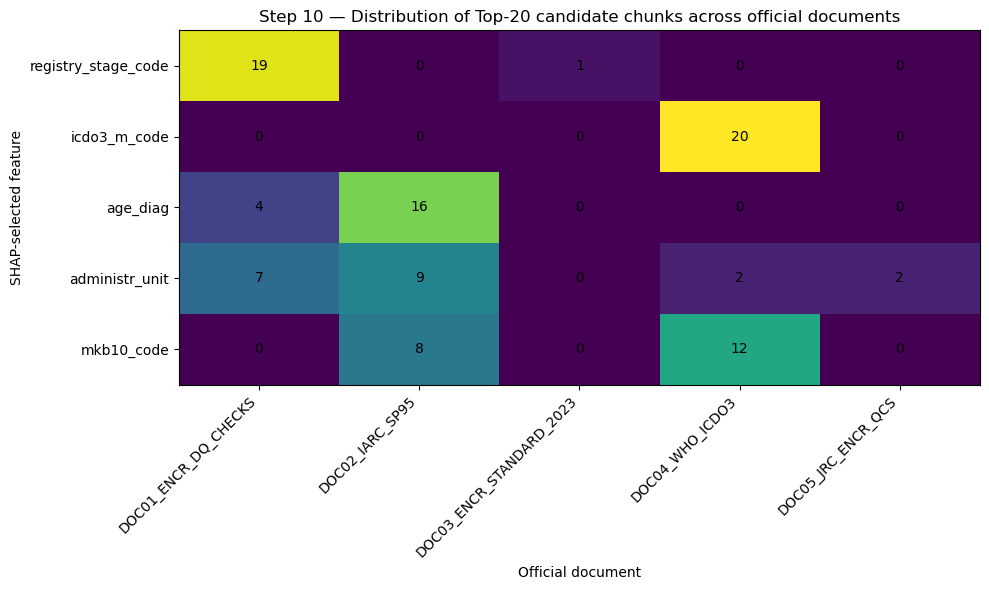

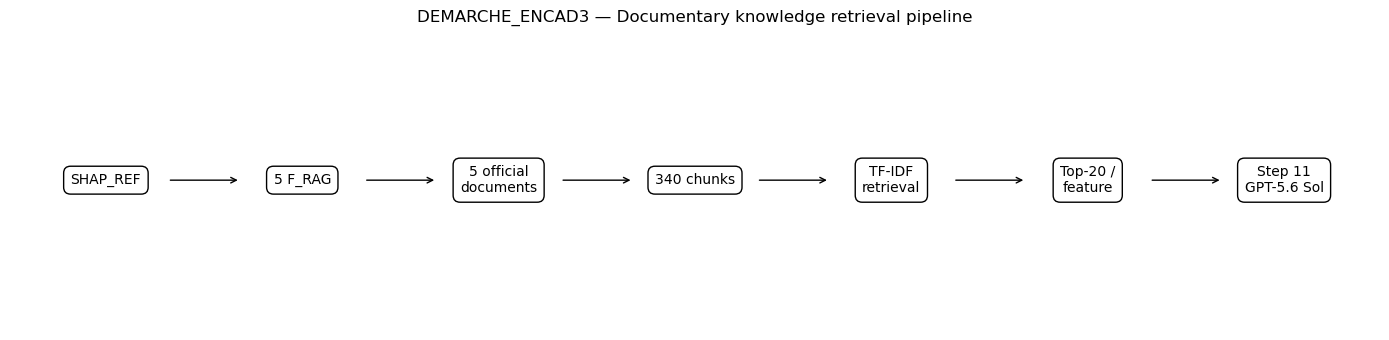


RETRIEVAL SUMMARY
            feature semantic_status                    query_source  n_total_chunks  n_positive_similarity_chunks  n_candidates_top_k  top1_similarity                   top1_chunk_id     top1_document_id  top1_page_start  top1_page_end  top1_lexical_match_ratio
registry_stage_code      DOCUMENTED FEATURE_NAME+MINIMAL_DICTIONARY             340                           220                  20         0.034385 DOC01_ENCR_DQ_CHECKS_CHUNK_0051 DOC01_ENCR_DQ_CHECKS              101            102                  1.000000
       icdo3_m_code  NOT_DOCUMENTED               FEATURE_NAME_ONLY             340                           189                  20         0.032419      DOC04_WHO_ICDO3_CHUNK_0126      DOC04_WHO_ICDO3              251            252                  1.000000
           age_diag      DOCUMENTED FEATURE_NAME+MINIMAL_DICTIONARY             340                           184                  20         0.086199 DOC01_ENCR_DQ_CHECKS_CHUNK_0009 DOC01_ENCR_D

In [9]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 2
# PHASE 2 — KNOWLEDGE
# STEP 10 — TRACEABLE FEATURE–CHUNK DOCUMENT RETRIEVAL
# ============================================================

from pathlib import Path
import json
import re
import hashlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = (
    PROJECT_ROOT
    / "CASE_STUDY_2_CANCER_REGISTRY"
)

DATA_DIR = (
    CASE_ROOT
    / "data"
)

DICTIONARY_FILE = (
    DATA_DIR
    / "dictionary"
    / "feature_dictionary.csv"
)

EXTRACTED_DIR = (
    CASE_ROOT
    / "knowledge"
    / "documents"
    / "extracted"
)

CHUNKS_FILE = (
    EXTRACTED_DIR
    / "official_documents_chunks_2pages.csv"
)

RESULTS_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step10_document_retrieval"
)

TABLES_DIR = RESULTS_DIR / "tables"
FIGURES_DIR = RESULTS_DIR / "figures"

TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

FIGURES_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. FROZEN EXPERIMENTAL PARAMETERS
# ============================================================

F_RAG = [
    "registry_stage_code",
    "icdo3_m_code",
    "age_diag",
    "administr_unit",
    "mkb10_code",
]

SHAP_COVERAGE = 80.376

TOP_K = 20

RANDOM_STATE = 42


# ============================================================
# 3. LOAD OFFICIAL DOCUMENT CHUNKS
# ============================================================

if not CHUNKS_FILE.exists():
    raise FileNotFoundError(
        f"Chunk file not found:\n{CHUNKS_FILE}"
    )

chunks_df = pd.read_csv(
    CHUNKS_FILE
)

required_chunk_columns = [
    "chunk_id",
    "document_id",
    "short_title",
    "document_name",
    "institution",
    "page_start",
    "page_end",
    "text",
]

missing_columns = [
    col
    for col in required_chunk_columns
    if col not in chunks_df.columns
]

if missing_columns:
    raise ValueError(
        "Missing columns in chunk file: "
        + ", ".join(missing_columns)
    )

chunks_df["text"] = (
    chunks_df["text"]
    .fillna("")
    .astype(str)
)

print("=" * 95)
print("DEMARCHE_ENCAD3 — PHASE 2 / STEP 10")
print("TRACEABLE FEATURE–CHUNK DOCUMENT RETRIEVAL")
print("=" * 95)

print(f"\nOfficial chunks loaded : {len(chunks_df)}")
print(f"F_RAG features         : {len(F_RAG)}")
print(
    f"Potential feature–chunk pairs : "
    f"{len(F_RAG) * len(chunks_df)}"
)


# ============================================================
# 4. LOAD MINIMAL SEMANTIC DICTIONARY
# ============================================================

if not DICTIONARY_FILE.exists():
    raise FileNotFoundError(
        f"Minimal feature dictionary not found:\n"
        f"{DICTIONARY_FILE}"
    )

dictionary_df = pd.read_csv(
    DICTIONARY_FILE
)

print(
    f"\nMinimal dictionary rows: "
    f"{len(dictionary_df)}"
)


# ============================================================
# 5. IDENTIFY DICTIONARY COLUMNS SAFELY
# ============================================================

print("\nDictionary columns:")
print(list(dictionary_df.columns))


def find_column(candidates):

    lower_map = {
        str(c).lower().strip(): c
        for c in dictionary_df.columns
    }

    for candidate in candidates:

        if candidate.lower() in lower_map:
            return lower_map[candidate.lower()]

    return None


FEATURE_COL = find_column([
    "feature",
    "variable",
    "variable_name",
    "feature_name",
    "name",
])

DESCRIPTION_COL = find_column([
    "description",
    "semantic_description",
    "definition",
    "label",
    "meaning",
])

if FEATURE_COL is None:

    raise ValueError(
        "Unable to identify the feature-name column "
        "in feature_dictionary.csv."
    )


print(
    f"\nFeature column detected     : "
    f"{FEATURE_COL}"
)

print(
    f"Description column detected : "
    f"{DESCRIPTION_COL}"
)


# ============================================================
# 6. EXTRACT ONLY DOCUMENTED SEMANTICS
# ============================================================

semantic_map = {}


for feature in F_RAG:

    match = dictionary_df[
        dictionary_df[FEATURE_COL]
        .astype(str)
        .str.strip()
        == feature
    ]

    if len(match) == 0:

        semantic_map[feature] = {
            "semantic_status":
                "NOT_DOCUMENTED",

            "semantic_description":
                None,
        }

        continue


    if DESCRIPTION_COL is None:

        semantic_map[feature] = {
            "semantic_status":
                "NOT_DOCUMENTED",

            "semantic_description":
                None,
        }

        continue


    value = match.iloc[0][
        DESCRIPTION_COL
    ]


    if pd.isna(value) or str(value).strip() == "":

        semantic_map[feature] = {
            "semantic_status":
                "NOT_DOCUMENTED",

            "semantic_description":
                None,
        }

    else:

        semantic_map[feature] = {
            "semantic_status":
                "DOCUMENTED",

            "semantic_description":
                str(value).strip(),
        }


# ============================================================
# 7. FORCE STEP-8 SEMANTIC STATUS
# ============================================================

# Step 8 already established which F_RAG features had
# documented semantics in the minimal dictionary.
#
# This prevents accidental semantic invention.

STEP8_DOCUMENTED_FEATURES = {
    "registry_stage_code",
    "age_diag",
    "mkb10_code",
}

STEP8_NOT_DOCUMENTED_FEATURES = {
    "icdo3_m_code",
    "administr_unit",
}


for feature in STEP8_NOT_DOCUMENTED_FEATURES:

    semantic_map[feature] = {
        "semantic_status":
            "NOT_DOCUMENTED",

        "semantic_description":
            None,
    }


# ============================================================
# 8. BUILD TRACEABLE RETRIEVAL QUERIES
# ============================================================

# IMPORTANT:
#
# No cancer-domain synonym is manually invented here.
#
# If semantic description exists:
#     feature name + official minimal description
#
# Otherwise:
#     feature name only
#
# Technical separators "_" are converted to spaces
# for lexical matching.

query_rows = []


for feature in F_RAG:

    semantic_status = (
        semantic_map[feature]
        ["semantic_status"]
    )

    description = (
        semantic_map[feature]
        ["semantic_description"]
    )


    feature_tokens = (
        feature
        .replace("_", " ")
        .strip()
    )


    if (
        semantic_status == "DOCUMENTED"
        and
        description is not None
    ):

        retrieval_query = (
            f"{feature_tokens} {description}"
        )

        query_source = (
            "FEATURE_NAME+MINIMAL_DICTIONARY"
        )

    else:

        retrieval_query = (
            feature_tokens
        )

        query_source = (
            "FEATURE_NAME_ONLY"
        )


    query_rows.append({

        "feature":
            feature,

        "semantic_status":
            semantic_status,

        "semantic_description":
            description,

        "retrieval_query":
            retrieval_query,

        "query_source":
            query_source,
    })


queries_df = pd.DataFrame(
    query_rows
)


print("\n" + "=" * 95)
print("RETRIEVAL QUERIES")
print("=" * 95)

print(
    queries_df[
        [
            "feature",
            "semantic_status",
            "query_source",
            "retrieval_query",
        ]
    ].to_string(
        index=False
    )
)


# ============================================================
# 9. NORMALIZATION FUNCTION
# ============================================================

def normalize_text(text):

    text = str(text).lower()

    text = re.sub(
        r"[_\-/]",
        " ",
        text
    )

    text = re.sub(
        r"[^a-z0-9\s]",
        " ",
        text
    )

    text = re.sub(
        r"\s+",
        " ",
        text
    ).strip()

    return text


chunks_df["retrieval_text"] = (
    chunks_df["text"]
    .apply(normalize_text)
)

queries_df["normalized_query"] = (
    queries_df["retrieval_query"]
    .apply(normalize_text)
)


# ============================================================
# 10. TF-IDF CORPUS
# ============================================================

# Query documents are included when fitting TF-IDF so that
# query vocabulary is represented.
#
# No labels / hidden rules / GPT outputs are used.

combined_texts = (
    chunks_df["retrieval_text"].tolist()
    +
    queries_df["normalized_query"].tolist()
)


vectorizer = TfidfVectorizer(

    lowercase=False,

    ngram_range=(1, 2),

    min_df=1,

    max_df=0.95,

    sublinear_tf=True,

    norm="l2",
)


tfidf_matrix = vectorizer.fit_transform(
    combined_texts
)


n_chunks = len(
    chunks_df
)

chunk_matrix = (
    tfidf_matrix[
        :n_chunks
    ]
)

query_matrix = (
    tfidf_matrix[
        n_chunks:
    ]
)


print(
    f"\nTF-IDF vocabulary size: "
    f"{len(vectorizer.vocabulary_)}"
)


# ============================================================
# 11. COSINE SIMILARITY
# ============================================================

similarity_matrix = cosine_similarity(
    query_matrix,
    chunk_matrix
)


assert similarity_matrix.shape == (
    len(F_RAG),
    len(chunks_df)
)


# ============================================================
# 12. LEXICAL SUPPORT FUNCTION
# ============================================================

# This is only a secondary traceability indicator.
# It does NOT decide documentary relevance.

STOP_TOKENS = {
    "code",
    "data",
    "value",
    "values",
    "variable",
    "variables",
    "information",
    "registry",
}


def query_terms(query):

    terms = normalize_text(
        query
    ).split()

    terms = [
        t
        for t in terms
        if len(t) >= 3
        and t not in STOP_TOKENS
    ]

    return sorted(
        set(terms)
    )


def lexical_support(
    query,
    chunk_text
):

    terms = query_terms(
        query
    )

    text = normalize_text(
        chunk_text
    )

    matched = [
        term
        for term in terms
        if re.search(
            rf"\b{re.escape(term)}\b",
            text
        )
    ]

    if len(terms) == 0:

        ratio = 0.0

    else:

        ratio = (
            len(matched)
            /
            len(terms)
        )


    return (
        matched,
        ratio
    )


# ============================================================
# 13. CREATE ALL 1,700 FEATURE–CHUNK PAIRS
# ============================================================

all_pair_rows = []


for query_index, query_row in queries_df.iterrows():

    feature = query_row["feature"]

    query = query_row[
        "retrieval_query"
    ]

    scores = similarity_matrix[
        query_index
    ]


    for chunk_index, chunk_row in chunks_df.iterrows():

        matched_terms, lexical_ratio = (
            lexical_support(
                query,
                chunk_row["text"]
            )
        )


        all_pair_rows.append({

            "feature":
                feature,

            "semantic_status":
                query_row[
                    "semantic_status"
                ],

            "query_source":
                query_row[
                    "query_source"
                ],

            "retrieval_query":
                query,

            "chunk_id":
                chunk_row[
                    "chunk_id"
                ],

            "document_id":
                chunk_row[
                    "document_id"
                ],

            "short_title":
                chunk_row[
                    "short_title"
                ],

            "document_name":
                chunk_row[
                    "document_name"
                ],

            "institution":
                chunk_row[
                    "institution"
                ],

            "page_start":
                int(
                    chunk_row[
                        "page_start"
                    ]
                ),

            "page_end":
                int(
                    chunk_row[
                        "page_end"
                    ]
                ),

            "cosine_similarity":
                float(
                    scores[
                        chunk_index
                    ]
                ),

            "lexical_match_count":
                len(
                    matched_terms
                ),

            "lexical_match_ratio":
                float(
                    lexical_ratio
                ),

            "matched_terms":
                " | ".join(
                    matched_terms
                ),
        })


all_pairs_df = pd.DataFrame(
    all_pair_rows
)


assert len(all_pairs_df) == (
    len(F_RAG)
    *
    len(chunks_df)
)


# ============================================================
# 14. RANK CHUNKS WITHIN EACH FEATURE
# ============================================================

all_pairs_df = (

    all_pairs_df

    .sort_values(
        [
            "feature",
            "cosine_similarity",
            "lexical_match_ratio",
        ],
        ascending=[
            True,
            False,
            False,
        ]
    )

    .reset_index(
        drop=True
    )
)


all_pairs_df[
    "retrieval_rank"
] = (

    all_pairs_df

    .groupby(
        "feature"
    )

    .cumcount()
    + 1
)


# ============================================================
# 15. SELECT TOP-K CANDIDATE CHUNKS
# ============================================================

candidate_df = (

    all_pairs_df[
        all_pairs_df[
            "retrieval_rank"
        ] <= TOP_K
    ]

    .copy()
)


candidate_df[
    "retrieval_status"
] = (
    "CANDIDATE_FOR_SEMANTIC_REVIEW"
)


# IMPORTANT:
#
# Top-K means only "candidate for Step 11".
# It does NOT mean:
#   RELEVANT
#   KNOWLEDGE_FOUND
#   ERROR
#   RULE
#   CORRECTION


# ============================================================
# 16. ADD FULL CHUNK TEXT ONLY TO CANDIDATE TABLE
# ============================================================

chunk_text_map = (

    chunks_df

    .set_index(
        "chunk_id"
    )["text"]

    .to_dict()
)


candidate_df[
    "chunk_text"
] = (

    candidate_df[
        "chunk_id"
    ]

    .map(
        chunk_text_map
    )
)


# ============================================================
# 17. RETRIEVAL SUMMARY PER FEATURE
# ============================================================

summary_rows = []


for feature in F_RAG:

    feature_all = (
        all_pairs_df[
            all_pairs_df["feature"]
            == feature
        ]
    )

    feature_candidates = (
        candidate_df[
            candidate_df["feature"]
            == feature
        ]
    )


    top1 = feature_candidates.iloc[0]


    positive_scores = int(
        (
            feature_all[
                "cosine_similarity"
            ] > 0
        ).sum()
    )


    summary_rows.append({

        "feature":
            feature,

        "semantic_status":
            top1[
                "semantic_status"
            ],

        "query_source":
            top1[
                "query_source"
            ],

        "n_total_chunks":
            len(
                feature_all
            ),

        "n_positive_similarity_chunks":
            positive_scores,

        "n_candidates_top_k":
            len(
                feature_candidates
            ),

        "top1_similarity":
            float(
                top1[
                    "cosine_similarity"
                ]
            ),

        "top1_chunk_id":
            top1[
                "chunk_id"
            ],

        "top1_document_id":
            top1[
                "document_id"
            ],

        "top1_page_start":
            int(
                top1[
                    "page_start"
                ]
            ),

        "top1_page_end":
            int(
                top1[
                    "page_end"
                ]
            ),

        "top1_lexical_match_ratio":
            float(
                top1[
                    "lexical_match_ratio"
                ]
            ),
    })


summary_df = pd.DataFrame(
    summary_rows
)


# ============================================================
# 18. DOCUMENT COVERAGE MATRIX
# ============================================================

coverage_df = (

    candidate_df

    .groupby(
        [
            "feature",
            "document_id"
        ]
    )

    .size()

    .unstack(
        fill_value=0
    )

    .reindex(
        F_RAG
    )
)


# ============================================================
# 19. SAVE TABLES
# ============================================================

ALL_PAIRS_FILE = (
    TABLES_DIR
    / "Table_All_Feature_Chunk_Retrieval_Scores.csv"
)

CANDIDATES_FILE = (
    TABLES_DIR
    / "Table_RAG_Candidate_Chunks_Top20.csv"
)

SUMMARY_FILE = (
    TABLES_DIR
    / "Table_RAG_Retrieval_Summary.csv"
)

COVERAGE_FILE = (
    TABLES_DIR
    / "Table_RAG_Document_Coverage_Matrix.csv"
)

QUERIES_FILE = (
    TABLES_DIR
    / "Table_RAG_Retrieval_Queries.csv"
)


all_pairs_df.to_csv(
    ALL_PAIRS_FILE,
    index=False,
    encoding="utf-8-sig"
)

candidate_df.to_csv(
    CANDIDATES_FILE,
    index=False,
    encoding="utf-8-sig"
)

summary_df.to_csv(
    SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig"
)

coverage_df.to_csv(
    COVERAGE_FILE,
    encoding="utf-8-sig"
)

queries_df.to_csv(
    QUERIES_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 20. SAVE CANDIDATES AS JSONL FOR STEP 11
# ============================================================

CANDIDATES_JSONL = (
    RESULTS_DIR
    / "RAG_Candidate_Chunks_Top20.jsonl"
)


with open(
    CANDIDATES_JSONL,
    "w",
    encoding="utf-8"
) as f:

    for record in (
        candidate_df
        .to_dict(
            orient="records"
        )
    ):

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            )
            + "\n"
        )


# ============================================================
# 21. FIGURE 9 — TOP-K RETRIEVAL SCORES
# ============================================================

fig, ax = plt.subplots(
    figsize=(11, 7)
)


for feature in F_RAG:

    temp = (

        candidate_df[
            candidate_df[
                "feature"
            ] == feature
        ]

        .sort_values(
            "retrieval_rank"
        )
    )


    ax.plot(
        temp[
            "retrieval_rank"
        ],
        temp[
            "cosine_similarity"
        ],
        marker="o",
        label=feature,
    )


ax.set_xlabel(
    "Retrieval rank"
)

ax.set_ylabel(
    "TF-IDF cosine similarity"
)

ax.set_title(
    "Step 10 — Candidate chunk retrieval scores"
)

ax.set_xticks(
    range(
        1,
        TOP_K + 1
    )
)

ax.legend()

ax.grid(
    alpha=0.25
)

fig.tight_layout()


FIGURE_9 = (
    FIGURES_DIR
    / "Figure_9_RAG_Retrieval_Scores.png"
)

fig.savefig(
    FIGURE_9,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 22. FIGURE 10 — DOCUMENT COVERAGE MATRIX
# ============================================================

fig, ax = plt.subplots(
    figsize=(10, 6)
)

matrix_values = (
    coverage_df
    .values
)

image = ax.imshow(
    matrix_values,
    aspect="auto"
)

ax.set_xticks(
    np.arange(
        len(
            coverage_df.columns
        )
    )
)

ax.set_xticklabels(
    coverage_df.columns,
    rotation=45,
    ha="right"
)

ax.set_yticks(
    np.arange(
        len(
            coverage_df.index
        )
    )
)

ax.set_yticklabels(
    coverage_df.index
)


for i in range(
    matrix_values.shape[0]
):

    for j in range(
        matrix_values.shape[1]
    ):

        ax.text(
            j,
            i,
            int(
                matrix_values[i, j]
            ),
            ha="center",
            va="center",
        )


ax.set_title(
    "Step 10 — Distribution of Top-20 candidate chunks "
    "across official documents"
)

ax.set_xlabel(
    "Official document"
)

ax.set_ylabel(
    "SHAP-selected feature"
)

fig.tight_layout()


FIGURE_10 = (
    FIGURES_DIR
    / "Figure_10_RAG_Document_Coverage_Matrix.png"
)

fig.savefig(
    FIGURE_10,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 23. FIGURE 11 — KNOWLEDGE PIPELINE
# ============================================================

fig, ax = plt.subplots(
    figsize=(14, 3.5)
)

ax.axis(
    "off"
)


pipeline_labels = [
    "SHAP_REF",
    "5 F_RAG",
    "5 official\ndocuments",
    "340 chunks",
    "TF-IDF\nretrieval",
    "Top-20 /\nfeature",
    "Step 11\nGPT-5.6 Sol",
]


x_positions = np.linspace(
    0.07,
    0.93,
    len(
        pipeline_labels
    )
)


for i, (
    x,
    label
) in enumerate(
    zip(
        x_positions,
        pipeline_labels
    )
):

    ax.text(
        x,
        0.5,
        label,
        ha="center",
        va="center",
        bbox=dict(
            boxstyle="round,pad=0.5",
            fill=False,
        ),
        transform=ax.transAxes,
    )


    if i < (
        len(
            pipeline_labels
        ) - 1
    ):

        ax.annotate(
            "",
            xy=(
                x_positions[i + 1]
                - 0.045,
                0.5
            ),
            xytext=(
                x + 0.045,
                0.5
            ),
            xycoords=ax.transAxes,
            arrowprops=dict(
                arrowstyle="->"
            ),
        )


ax.set_title(
    "DEMARCHE_ENCAD3 — Documentary knowledge retrieval pipeline"
)


fig.tight_layout()


FIGURE_11 = (
    FIGURES_DIR
    / "Figure_11_Knowledge_Retrieval_Workflow.png"
)

fig.savefig(
    FIGURE_11,
    dpi=300,
    bbox_inches="tight"
)

plt.show()
plt.close(fig)


# ============================================================
# 24. STEP METADATA
# ============================================================

metadata = {

    "step":
        10,

    "phase":
        "KNOWLEDGE",

    "case_study":
        "CANCER_REGISTRY",

    "purpose":
        (
            "Traceable preselection of official "
            "document chunks for subsequent "
            "semantic relevance assessment."
        ),

    "n_features":
        len(
            F_RAG
        ),

    "features":
        F_RAG,

    "SHAP_cumulative_coverage_percent":
        SHAP_COVERAGE,

    "n_official_chunks":
        len(
            chunks_df
        ),

    "n_feature_chunk_pairs":
        len(
            all_pairs_df
        ),

    "retrieval_method":
        "TF-IDF + cosine similarity",

    "tfidf_ngram_range":
        [1, 2],

    "top_k_per_feature":
        TOP_K,

    "n_candidate_pairs":
        len(
            candidate_df
        ),

    "candidate_interpretation":
        (
            "Candidate for semantic review only; "
            "not established as relevant knowledge."
        ),

    "semantic_invention_for_undocumented_features":
        False,

    "scientific_articles_used_as_RAG_source":
        False,

    "official_documents_only":
        True,

    "hidden_reference_used":
        False,

    "GPT_5_6_Sol_used":
        False,

    "knowledge_extraction_performed":
        False,

    "diagnosis_performed":
        False,

    "correction_performed":
        False,

    "random_state":
        RANDOM_STATE,
}


METADATA_FILE = (
    RESULTS_DIR
    / "step10_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 25. FINAL CONTROLS
# ============================================================

expected_pairs = (
    len(F_RAG)
    *
    len(chunks_df)
)

expected_candidates = (
    len(F_RAG)
    *
    min(
        TOP_K,
        len(chunks_df)
    )
)


assert (
    len(all_pairs_df)
    == expected_pairs
)

assert (
    len(candidate_df)
    == expected_candidates
)

assert not candidate_df[
    "chunk_text"
].isna().any()


# ============================================================
# 26. CONSOLE REPORT
# ============================================================

print("\n" + "=" * 95)
print("RETRIEVAL SUMMARY")
print("=" * 95)

print(
    summary_df
    .to_string(
        index=False
    )
)


print("\n" + "=" * 95)
print("TOP 5 CHUNKS PER FEATURE")
print("=" * 95)


for feature in F_RAG:

    print(
        f"\n--- {feature} ---"
    )

    temp = (

        candidate_df[
            candidate_df[
                "feature"
            ] == feature
        ]

        .sort_values(
            "retrieval_rank"
        )

        .head(5)
    )


    print(

        temp[
            [
                "retrieval_rank",
                "chunk_id",
                "short_title",
                "page_start",
                "page_end",
                "cosine_similarity",
                "lexical_match_ratio",
                "matched_terms",
            ]
        ]

        .to_string(
            index=False
        )
    )


print("\n" + "=" * 95)
print("TOP-20 DOCUMENT COVERAGE MATRIX")
print("=" * 95)

print(
    coverage_df
    .to_string()
)


print("\n" + "=" * 95)
print("STEP 10 SUMMARY")
print("=" * 95)

print(
    f"F_RAG features            : "
    f"{len(F_RAG)}"
)

print(
    f"Official chunks           : "
    f"{len(chunks_df)}"
)

print(
    f"Feature–chunk pairs       : "
    f"{len(all_pairs_df)}"
)

print(
    f"Top-K per feature         : "
    f"{TOP_K}"
)

print(
    f"Candidate pairs retained  : "
    f"{len(candidate_df)}"
)

print(
    "\nInterpretation:"
)

print(
    "CANDIDATE_FOR_SEMANTIC_REVIEW "
    "does NOT mean RELEVANT."
)


print("\n[EXPERIMENTAL CONTROLS]")

print(
    "Official documents only                 : YES"
)

print(
    "Scientific articles used                : NO"
)

print(
    "hidden_reference used                   : NO"
)

print(
    "GPT-5.6 Sol used                        : NO"
)

print(
    "Semantic invention for undocumented F   : NO"
)

print(
    "Knowledge extracted                     : NO"
)

print(
    "Diagnosis performed                     : NO"
)

print(
    "Correction performed                    : NO"
)


print("\n[OUTPUT TABLES]")

print(
    f"1. {QUERIES_FILE}"
)

print(
    f"2. {ALL_PAIRS_FILE}"
)

print(
    f"3. {CANDIDATES_FILE}"
)

print(
    f"4. {SUMMARY_FILE}"
)

print(
    f"5. {COVERAGE_FILE}"
)

print(
    f"6. {CANDIDATES_JSONL}"
)


print("\n[OUTPUT FIGURES]")

print(
    f"7. {FIGURE_9}"
)

print(
    f"8. {FIGURE_10}"
)

print(
    f"9. {FIGURE_11}"
)

print(
    f"10. {METADATA_FILE}"
)


print("\n" + "=" * 95)
print("[PASS] STEP 10 COMPLETED")
print("=" * 95)

In [10]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 2
# PHASE 2 — KNOWLEDGE
#
# STEP 10
# EXHAUSTIVE FEATURE–CHUNK PAIR GENERATION
# FOR GPT-5.6 SOL / LLM-A SEMANTIC FILTERING
#
# IMPORTANT:
# NO TF-IDF
# NO COSINE SIMILARITY
# NO EMBEDDINGS
# NO TOP-K
# NO KEYWORD PRE-FILTERING
# NO LLM DECISION AT THIS STEP
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = (
    PROJECT_ROOT
    / "CASE_STUDY_2_CANCER_REGISTRY"
)

CHUNKS_FILE = (
    CASE_ROOT
    / "knowledge"
    / "documents"
    / "extracted"
    / "official_documents_chunks_2pages.csv"
)

DICTIONARY_FILE = (
    CASE_ROOT
    / "data"
    / "dictionary"
    / "feature_dictionary.csv"
)

RESULTS_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step10_llma_input_preparation"
)

TABLES_DIR = (
    RESULTS_DIR
    / "tables"
)

LLMA_INPUT_DIR = (
    RESULTS_DIR
    / "llma_input"
)

TABLES_DIR.mkdir(
    parents=True,
    exist_ok=True
)

LLMA_INPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. FROZEN F_RAG FROM STEP 8
# ============================================================

F_RAG = [
    "registry_stage_code",
    "icdo3_m_code",
    "age_diag",
    "administr_unit",
    "mkb10_code",
]

SHAP_COVERAGE = 80.376


# ============================================================
# 3. SEMANTIC STATUS FROZEN FROM STEP 8
# ============================================================

DOCUMENTED_FEATURES = {
    "registry_stage_code",
    "age_diag",
    "mkb10_code",
}

NOT_DOCUMENTED_FEATURES = {
    "icdo3_m_code",
    "administr_unit",
}


# ============================================================
# 4. INITIAL REPORT
# ============================================================

print("=" * 95)
print("DEMARCHE_ENCAD3 — PHASE 2 / STEP 10")
print("EXHAUSTIVE FEATURE–CHUNK PAIR GENERATION FOR LLM-A")
print("=" * 95)

print("\nF_RAG frozen from Step 8:")

for i, feature in enumerate(F_RAG, start=1):
    print(f"  {i}. {feature}")

print(
    f"\nCumulative SHAP_REF coverage: "
    f"{SHAP_COVERAGE:.3f}%"
)


# ============================================================
# 5. LOAD THE 340 OFFICIAL CHUNKS
# ============================================================

if not CHUNKS_FILE.exists():

    raise FileNotFoundError(
        f"Official chunk file not found:\n"
        f"{CHUNKS_FILE}"
    )


chunks_df = pd.read_csv(
    CHUNKS_FILE
)


required_chunk_columns = [
    "chunk_id",
    "document_id",
    "short_title",
    "document_name",
    "institution",
    "document_type",
    "page_start",
    "page_end",
    "text",
]


missing_columns = [
    col
    for col in required_chunk_columns
    if col not in chunks_df.columns
]


if missing_columns:

    raise ValueError(
        "Missing required chunk columns: "
        + ", ".join(missing_columns)
    )


chunks_df["text"] = (
    chunks_df["text"]
    .fillna("")
    .astype(str)
)


print(
    f"\nOfficial chunks loaded : "
    f"{len(chunks_df)}"
)


if len(chunks_df) != 340:

    raise ValueError(
        f"Expected 340 chunks from Step 9, "
        f"but found {len(chunks_df)}."
    )


# ============================================================
# 6. CONTROL UNIQUE CHUNK IDs
# ============================================================

if chunks_df["chunk_id"].duplicated().any():

    duplicates = (
        chunks_df[
            chunks_df["chunk_id"].duplicated(
                keep=False
            )
        ]["chunk_id"]
        .tolist()
    )

    raise ValueError(
        "Duplicate chunk IDs detected:\n"
        + str(duplicates[:20])
    )


print(
    "Unique chunk IDs        : "
    "PASS"
)


# ============================================================
# 7. LOAD MINIMAL FEATURE DICTIONARY
# ============================================================

if not DICTIONARY_FILE.exists():

    raise FileNotFoundError(
        f"Minimal feature dictionary not found:\n"
        f"{DICTIONARY_FILE}"
    )


dictionary_df = pd.read_csv(
    DICTIONARY_FILE
)


print(
    f"Minimal dictionary rows : "
    f"{len(dictionary_df)}"
)

print(
    "\nDictionary columns:"
)

print(
    list(dictionary_df.columns)
)


# ============================================================
# 8. IDENTIFY FEATURE / DESCRIPTION COLUMNS
# ============================================================

def find_column(
    dataframe,
    candidates
):

    mapping = {
        str(column).lower().strip():
            column
        for column in dataframe.columns
    }

    for candidate in candidates:

        candidate_lower = (
            candidate.lower().strip()
        )

        if candidate_lower in mapping:

            return mapping[
                candidate_lower
            ]

    return None


FEATURE_COL = find_column(
    dictionary_df,
    [
        "feature",
        "variable",
        "variable_name",
        "feature_name",
        "name",
    ]
)


DESCRIPTION_COL = find_column(
    dictionary_df,
    [
        "description",
        "semantic_description",
        "definition",
        "label",
        "meaning",
    ]
)


if FEATURE_COL is None:

    raise ValueError(
        "Unable to identify feature column "
        "in feature_dictionary.csv"
    )


print(
    f"\nFeature column detected     : "
    f"{FEATURE_COL}"
)

print(
    f"Description column detected : "
    f"{DESCRIPTION_COL}"
)


# ============================================================
# 9. BUILD FROZEN FEATURE SEMANTIC TABLE
# ============================================================

feature_rows = []


for feature in F_RAG:

    if feature in DOCUMENTED_FEATURES:

        match = dictionary_df[
            dictionary_df[
                FEATURE_COL
            ]
            .astype(str)
            .str.strip()
            == feature
        ]


        if len(match) == 0:

            raise ValueError(
                f"{feature} was documented in Step 8 "
                f"but was not found in the minimal dictionary."
            )


        if DESCRIPTION_COL is None:

            raise ValueError(
                "Description column is required for "
                "documented features."
            )


        description = (
            match.iloc[0][
                DESCRIPTION_COL
            ]
        )


        if (
            pd.isna(description)
            or
            str(description).strip() == ""
        ):

            raise ValueError(
                f"Empty semantic description for "
                f"documented feature: {feature}"
            )


        description = (
            str(description)
            .strip()
        )


        semantic_status = (
            "DOCUMENTED"
        )


    elif feature in NOT_DOCUMENTED_FEATURES:

        description = None

        semantic_status = (
            "NOT_DOCUMENTED"
        )


    else:

        raise ValueError(
            f"Feature has no frozen semantic status: "
            f"{feature}"
        )


    feature_rows.append({

        "feature":
            feature,

        "semantic_status":
            semantic_status,

        "semantic_description":
            description,
    })


features_df = pd.DataFrame(
    feature_rows
)


print("\n" + "=" * 95)
print("FROZEN FEATURE SEMANTIC STATUS")
print("=" * 95)

print(
    features_df.to_string(
        index=False
    )
)


# ============================================================
# 10. GENERATE EXHAUSTIVE CARTESIAN PRODUCT
#
#     5 FEATURES × 340 CHUNKS = 1700 PAIRS
# ============================================================

pair_rows = []

pair_counter = 1


for _, feature_row in features_df.iterrows():

    feature = (
        feature_row["feature"]
    )

    semantic_status = (
        feature_row[
            "semantic_status"
        ]
    )

    semantic_description = (
        feature_row[
            "semantic_description"
        ]
    )


    for _, chunk_row in chunks_df.iterrows():

        pair_id = (
            f"PAIR_{pair_counter:05d}"
        )


        pair_rows.append({

            # --------------------------------------------
            # Pair traceability
            # --------------------------------------------

            "pair_id":
                pair_id,


            # --------------------------------------------
            # Feature information
            # --------------------------------------------

            "feature":
                feature,

            "semantic_status":
                semantic_status,

            "semantic_description":
                semantic_description,


            # --------------------------------------------
            # Chunk traceability
            # --------------------------------------------

            "chunk_id":
                chunk_row[
                    "chunk_id"
                ],

            "document_id":
                chunk_row[
                    "document_id"
                ],

            "short_title":
                chunk_row[
                    "short_title"
                ],

            "document_name":
                chunk_row[
                    "document_name"
                ],

            "institution":
                chunk_row[
                    "institution"
                ],

            "document_type":
                chunk_row[
                    "document_type"
                ],

            "page_start":
                int(
                    chunk_row[
                        "page_start"
                    ]
                ),

            "page_end":
                int(
                    chunk_row[
                        "page_end"
                    ]
                ),


            # --------------------------------------------
            # Complete chunk text
            # --------------------------------------------

            "chunk_text":
                chunk_row[
                    "text"
                ],


            # --------------------------------------------
            # Fields RESERVED for Step 11 / LLM-A
            #
            # They intentionally remain empty here.
            # --------------------------------------------

            "llma_decision":
                None,

            "llma_minimal_evidence":
                None,

            "llma_reason":
                None,

            "llma_semantic_link_status":
                None,

            "llma_model":
                None,
        })


        pair_counter += 1


pairs_df = pd.DataFrame(
    pair_rows
)


# ============================================================
# 11. STRICT CARTESIAN PRODUCT CONTROL
# ============================================================

EXPECTED_PAIRS = (
    len(F_RAG)
    *
    len(chunks_df)
)


if len(pairs_df) != EXPECTED_PAIRS:

    raise RuntimeError(
        f"Expected {EXPECTED_PAIRS} pairs, "
        f"but generated {len(pairs_df)}."
    )


if EXPECTED_PAIRS != 1700:

    raise RuntimeError(
        f"Experimental protocol expects 1700 pairs, "
        f"but current configuration gives "
        f"{EXPECTED_PAIRS}."
    )


# ============================================================
# 12. CONTROL 340 CHUNKS PER FEATURE
# ============================================================

feature_counts = (

    pairs_df

    .groupby(
        "feature"
    )

    .size()

    .reset_index(
        name="n_pairs"
    )
)


for _, row in feature_counts.iterrows():

    if int(row["n_pairs"]) != 340:

        raise RuntimeError(
            f"Feature {row['feature']} has "
            f"{row['n_pairs']} pairs instead of 340."
        )


# ============================================================
# 13. CONTROL EACH FEATURE × CHUNK APPEARS ONCE
# ============================================================

duplicate_pairs = (

    pairs_df

    .duplicated(
        subset=[
            "feature",
            "chunk_id"
        ]
    )

    .sum()
)


if duplicate_pairs != 0:

    raise RuntimeError(
        f"{duplicate_pairs} duplicate "
        f"feature–chunk pairs detected."
    )


# ============================================================
# 14. CONTROL THAT NO CHUNK WAS FILTERED
# ============================================================

for feature in F_RAG:

    feature_chunks = set(

        pairs_df[
            pairs_df["feature"]
            == feature
        ]["chunk_id"]
    )


    all_chunks = set(
        chunks_df["chunk_id"]
    )


    if feature_chunks != all_chunks:

        raise RuntimeError(
            f"Chunk loss detected for feature: "
            f"{feature}"
        )


# ============================================================
# 15. CONTROL EMPTY CHUNK TEXT
# ============================================================

empty_text_pairs = int(

    pairs_df[
        "chunk_text"
    ]

    .fillna("")
    .astype(str)
    .str.strip()
    .eq("")
    .sum()
)


if empty_text_pairs > 0:

    print(
        f"\n[WARNING] "
        f"{empty_text_pairs} pairs contain "
        f"an empty chunk text."
    )

else:

    print(
        "\n[PASS] No pair contains "
        "an empty chunk."
    )


# ============================================================
# 16. SAVE COMPLETE 1700-PAIR TABLE
# ============================================================

PAIR_CSV = (
    LLMA_INPUT_DIR
    / "LLMA_input_1700_feature_chunk_pairs.csv"
)


pairs_df.to_csv(
    PAIR_CSV,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 17. SAVE JSONL — MAIN INPUT FOR LLM-A
# ============================================================

PAIR_JSONL = (
    LLMA_INPUT_DIR
    / "LLMA_input_1700_feature_chunk_pairs.jsonl"
)


with open(
    PAIR_JSONL,
    "w",
    encoding="utf-8"
) as f:

    for record in (
        pairs_df
        .to_dict(
            orient="records"
        )
    ):

        f.write(

            json.dumps(
                record,
                ensure_ascii=False
            )

            + "\n"
        )


# ============================================================
# 18. SAVE FEATURE MANIFEST
# ============================================================

FEATURE_MANIFEST = (
    TABLES_DIR
    / "Table_LLMA_Feature_Manifest.csv"
)


features_df.to_csv(
    FEATURE_MANIFEST,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 19. SAVE PAIR COUNT AUDIT
# ============================================================

PAIR_AUDIT = (
    TABLES_DIR
    / "Table_LLMA_Pair_Count_Audit.csv"
)


feature_counts.to_csv(
    PAIR_AUDIT,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 20. DOCUMENT × FEATURE COVERAGE AUDIT
# ============================================================

coverage_df = (

    pairs_df

    .groupby(
        [
            "feature",
            "document_id"
        ]
    )

    .size()

    .unstack(
        fill_value=0
    )

    .reindex(
        F_RAG
    )
)


COVERAGE_FILE = (
    TABLES_DIR
    / "Table_LLMA_Document_Feature_Coverage.csv"
)


coverage_df.to_csv(
    COVERAGE_FILE,
    encoding="utf-8-sig"
)


# ============================================================
# 21. HASH THE LLM-A INPUT
# ============================================================

def sha256_file(path):

    sha = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        while True:

            block = f.read(
                1024 * 1024
            )

            if not block:
                break

            sha.update(
                block
            )

    return sha.hexdigest()


CSV_SHA256 = sha256_file(
    PAIR_CSV
)

JSONL_SHA256 = sha256_file(
    PAIR_JSONL
)


# ============================================================
# 22. CREATE STEP METADATA
# ============================================================

metadata = {

    "step":
        10,

    "phase":
        "KNOWLEDGE",

    "case_study":
        "CANCER_REGISTRY",

    "step_name":
        "EXHAUSTIVE_FEATURE_CHUNK_PAIR_GENERATION",

    "purpose":
        (
            "Prepare the complete Cartesian product "
            "between SHAP-selected features and "
            "official documentary chunks for direct "
            "LLM-A semantic filtering."
        ),

    "performed_by":
        "LOCAL_PYTHON",

    "next_step_performed_by":
        "GPT-5.6 Sol / LLM-A",

    "n_features":
        int(
            len(F_RAG)
        ),

    "features":
        F_RAG,

    "SHAP_cumulative_coverage_percent":
        SHAP_COVERAGE,

    "n_official_chunks":
        int(
            len(chunks_df)
        ),

    "n_feature_chunk_pairs":
        int(
            len(pairs_df)
        ),

    "expected_cartesian_product":
        "5 x 340 = 1700",

    "pre_filtering":
        False,

    "tfidf_used":
        False,

    "cosine_similarity_used":
        False,

    "embedding_used":
        False,

    "keyword_filter_used":
        False,

    "top_k_used":
        False,

    "chunk_ranking_used":
        False,

    "all_chunks_preserved_for_every_feature":
        True,

    "LLM_used_at_this_step":
        False,

    "LLM_planned_next_step":
        "GPT-5.6 Sol",

    "LLM_role_next_step":
        (
            "Semantic feature–chunk filtering: "
            "RELEVANT / NOT_RELEVANT"
        ),

    "scientific_articles_used_as_RAG_source":
        False,

    "official_documents_only":
        True,

    "hidden_reference_used":
        False,

    "knowledge_extraction_performed":
        False,

    "diagnosis_performed":
        False,

    "correction_performed":
        False,

    "undocumented_features":
        sorted(
            list(
                NOT_DOCUMENTED_FEATURES
            )
        ),

    "semantic_invention_for_undocumented_features":
        False,

    "input_csv_sha256":
        CSV_SHA256,

    "input_jsonl_sha256":
        JSONL_SHA256,

    "timestamp":
        datetime.now().isoformat(),
}


METADATA_FILE = (
    RESULTS_DIR
    / "step10_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 23. CONSOLE REPORT
# ============================================================

print("\n" + "=" * 95)
print("FEATURE × CHUNK PAIR AUDIT")
print("=" * 95)

print(
    feature_counts
    .to_string(
        index=False
    )
)


print("\n" + "=" * 95)
print("DOCUMENT × FEATURE COVERAGE")
print("=" * 95)

print(
    coverage_df
    .to_string()
)


print("\n" + "=" * 95)
print("STEP 10 SUMMARY")
print("=" * 95)

print(
    f"F_RAG features              : "
    f"{len(F_RAG)}"
)

print(
    f"Official chunks             : "
    f"{len(chunks_df)}"
)

print(
    f"Expected pairs              : "
    f"{EXPECTED_PAIRS}"
)

print(
    f"Generated pairs             : "
    f"{len(pairs_df)}"
)

print(
    f"Duplicate feature-chunk     : "
    f"{duplicate_pairs}"
)

print(
    f"Pairs with empty text       : "
    f"{empty_text_pairs}"
)


print("\n[FILTERING CONTROL]")

print(
    "TF-IDF used                 : NO"
)

print(
    "Cosine similarity used      : NO"
)

print(
    "Embeddings used             : NO"
)

print(
    "Keyword pre-filtering       : NO"
)

print(
    "Top-K used                  : NO"
)

print(
    "Chunk ranking               : NO"
)

print(
    "All 340 chunks / feature    : YES"
)


print("\n[KNOWLEDGE CONTROL]")

print(
    "GPT-5.6 Sol used            : NO"
)

print(
    "Knowledge extracted         : NO"
)

print(
    "Diagnosis performed         : NO"
)

print(
    "Correction performed        : NO"
)

print(
    "Scientific articles in RAG  : NO"
)

print(
    "Official documents only     : YES"
)

print(
    "hidden_reference used       : NO"
)

print(
    "Invented semantics          : NO"
)


print("\n[TRACEABILITY]")

print(
    f"CSV SHA-256:\n{CSV_SHA256}"
)

print(
    f"\nJSONL SHA-256:\n{JSONL_SHA256}"
)


print("\n[OUTPUT FILES]")

print(
    f"1. {PAIR_CSV}"
)

print(
    f"2. {PAIR_JSONL}"
)

print(
    f"3. {FEATURE_MANIFEST}"
)

print(
    f"4. {PAIR_AUDIT}"
)

print(
    f"5. {COVERAGE_FILE}"
)

print(
    f"6. {METADATA_FILE}"
)


# ============================================================
# 24. FINAL PASS / FAIL
# ============================================================

if (
    len(pairs_df) == 1700
    and
    duplicate_pairs == 0
    and
    empty_text_pairs == 0
):

    print("\n" + "=" * 95)

    print(
        "[PASS] STEP 10 COMPLETED — "
        "1700 EXHAUSTIVE FEATURE–CHUNK PAIRS "
        "READY FOR GPT-5.6 SOL / LLM-A"
    )

    print("=" * 95)

else:

    print("\n" + "=" * 95)

    print(
        "[WARNING] STEP 10 REQUIRES REVIEW "
        "BEFORE LLM-A PROCESSING"
    )

    print("=" * 95)

DEMARCHE_ENCAD3 — PHASE 2 / STEP 10
EXHAUSTIVE FEATURE–CHUNK PAIR GENERATION FOR LLM-A

F_RAG frozen from Step 8:
  1. registry_stage_code
  2. icdo3_m_code
  3. age_diag
  4. administr_unit
  5. mkb10_code

Cumulative SHAP_REF coverage: 80.376%

Official chunks loaded : 340
Unique chunk IDs        : PASS
Minimal dictionary rows : 10

Dictionary columns:
['feature', 'description', 'type', 'role', 'coding_values']

Feature column detected     : feature
Description column detected : description

FROZEN FEATURE SEMANTIC STATUS
            feature semantic_status     semantic_description
registry_stage_code      DOCUMENTED           registry stage
       icdo3_m_code  NOT_DOCUMENTED                     None
           age_diag      DOCUMENTED age at diagnosis (years)
     administr_unit  NOT_DOCUMENTED                     None
         mkb10_code      DOCUMENTED   ICD-10 topography code

[PASS] No pair contains an empty chunk.

FEATURE × CHUNK PAIR AUDIT
            feature  n_pairs
     a

In [ ]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 2 :  ce code n est pas exécuté ici --> ChatGpt web 
# resultat: 
# PHASE 2 — KNOWLEDGE
# STEP 11 — LLM-A SEMANTIC FEATURE–CHUNK FILTERING
#
# Reasoning performed by : GPT-5.6 Sol
# Python role            : orchestration + traceability only
#
# NO TF-IDF / NO COSINE / NO EMBEDDINGS / NO TOP-K
# NO ERROR/DETECTION/CORRECTION EXTRACTION
# ============================================================

from pathlib import Path
import pandas as pd
import json, hashlib, time, os
from datetime import datetime
from openai import OpenAI

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = PROJECT_ROOT / "CASE_STUDY_2_CANCER_REGISTRY"

INPUT_FILE = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step10_llma_input_preparation"
    / "llma_input"
    / "LLMA_input_1700_feature_chunk_pairs.jsonl"
)

RESULTS_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step11_llma_semantic_filtering"
)

TABLES_DIR = RESULTS_DIR / "tables"
TRACE_DIR = RESULTS_DIR / "trace"

TABLES_DIR.mkdir(parents=True, exist_ok=True)
TRACE_DIR.mkdir(parents=True, exist_ok=True)

CHECKPOINT_FILE = TRACE_DIR / "step11_checkpoint.jsonl"

FINAL_CSV = TABLES_DIR / "Table_LLMA_1700_Decisions.csv"
RELEVANT_CSV = TABLES_DIR / "Table_LLMA_RELEVANT_Pairs.csv"
SUMMARY_CSV = TABLES_DIR / "Table_LLMA_Filtering_Summary.csv"
FINAL_JSONL = RESULTS_DIR / "LLMA_1700_Decisions.jsonl"
METADATA_FILE = RESULTS_DIR / "step11_metadata.json"

# ------------------------------------------------------------
# 2. MODEL
# ------------------------------------------------------------

MODEL = "gpt-5.6-sol"

# API key should preferably be stored as environment variable:
# OPENAI_API_KEY
#
# Windows example outside Python:
# setx OPENAI_API_KEY "your-key"
#
# Restart Jupyter afterwards.

client = OpenAI()

# ------------------------------------------------------------
# 3. LOAD 1700 PAIRS
# ------------------------------------------------------------

if not INPUT_FILE.exists():
    raise FileNotFoundError(INPUT_FILE)

pairs = []

with open(INPUT_FILE, "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            pairs.append(json.loads(line))

assert len(pairs) == 1700

print("=" * 90)
print("DEMARCHE_ENCAD3 — STEP 11")
print("GPT-5.6 SOL / LLM-A SEMANTIC FILTERING")
print("=" * 90)
print(f"Input pairs : {len(pairs)}")
print(f"Model       : {MODEL}")

# ------------------------------------------------------------
# 4. SYSTEM INSTRUCTION
# ------------------------------------------------------------

SYSTEM_PROMPT = """
You are LLM-A, the semantic documentary filtering component
of the DEMARCHE_ENCAD3 research protocol.

Your ONLY task is to determine whether the supplied document
chunk is semantically relevant to the supplied feature.

Allowed decisions:
RELEVANT
NOT_RELEVANT

IMPORTANT RULES:

1. Use ONLY the supplied feature information and chunk.
2. Do not use external knowledge.
3. Do not infer that a statistical anomaly is an error.
4. Do NOT extract ERROR, DETECTION or CORRECTION knowledge.
5. Do NOT propose a correction.
6. Do NOT diagnose the dataset.
7. Do NOT use similarity scores, embeddings, rankings or Top-K.
8. A chunk is RELEVANT only if it contains information that
   materially helps understand, define, characterize, encode,
   constrain, interpret or assess the supplied feature.
9. Mere occurrence of generic words is insufficient.
10. If semantic_status is NOT_DOCUMENTED, do not invent the
    meaning of the technical feature name.
11. For an undocumented feature, mark RELEVANT only when the
    supplied chunk itself provides sufficiently explicit evidence
    connecting its content to the supplied feature identifier.
12. If uncertain, choose NOT_RELEVANT.
13. For RELEVANT, copy the SMALLEST exact passage from the chunk
    sufficient to justify relevance.
14. For NOT_RELEVANT, evidence_text must be an empty string.

Return ONLY valid JSON:

{
  "decision": "RELEVANT" or "NOT_RELEVANT",
  "evidence_text": "...",
  "reason": "brief semantic justification",
  "semantic_link_status":
      "ESTABLISHED" or
      "NOT_ESTABLISHED" or
      "NOT_APPLICABLE"
}
"""

# ------------------------------------------------------------
# 5. LOAD CHECKPOINT
# ------------------------------------------------------------

completed = {}

if CHECKPOINT_FILE.exists():

    with open(CHECKPOINT_FILE, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                r = json.loads(line)
                completed[r["pair_id"]] = r

print(f"Already completed : {len(completed)}")
print(f"Remaining         : {1700-len(completed)}")

# ------------------------------------------------------------
# 6. JSON EXTRACTION HELPER
# ------------------------------------------------------------

def parse_json_response(text):

    text = text.strip()

    if text.startswith("```"):
        text = text.replace("```json", "", 1)
        text = text.replace("```", "")
        text = text.strip()

    return json.loads(text)

# ------------------------------------------------------------
# 7. VALIDATION
# ------------------------------------------------------------

def validate_result(pair, result):

    decision = result.get("decision")

    if decision not in {"RELEVANT", "NOT_RELEVANT"}:
        raise ValueError(f"Invalid decision: {decision}")

    evidence = str(
        result.get("evidence_text", "")
    ).strip()

    reason = str(
        result.get("reason", "")
    ).strip()

    semantic_link = result.get(
        "semantic_link_status"
    )

    allowed_links = {
        "ESTABLISHED",
        "NOT_ESTABLISHED",
        "NOT_APPLICABLE"
    }

    if semantic_link not in allowed_links:
        raise ValueError(
            f"Invalid semantic_link_status: {semantic_link}"
        )

    if decision == "RELEVANT":

        if evidence == "":
            raise ValueError(
                "RELEVANT requires evidence_text."
            )

        # Exact evidence must exist inside original chunk.
        if evidence not in pair["chunk_text"]:
            raise ValueError(
                "Evidence is not an exact substring "
                "of the original chunk."
            )

    else:

        # Force empty evidence for NOT_RELEVANT.
        evidence = ""

    return {
        "decision": decision,
        "evidence_text": evidence,
        "reason": reason,
        "semantic_link_status": semantic_link
    }

# ------------------------------------------------------------
# 8. PROCESS ONE PAIR
# ------------------------------------------------------------

def process_pair(pair):

    payload = {
        "pair_id": pair["pair_id"],
        "feature": pair["feature"],
        "semantic_status": pair["semantic_status"],
        "semantic_description": pair["semantic_description"],
        "document_id": pair["document_id"],
        "chunk_id": pair["chunk_id"],
        "page_start": pair["page_start"],
        "page_end": pair["page_end"],
        "chunk_text": pair["chunk_text"]
    }

    response = client.responses.create(
        model=MODEL,
        reasoning={"effort": "medium"},
        input=[
            {
                "role": "system",
                "content": SYSTEM_PROMPT
            },
            {
                "role": "user",
                "content": json.dumps(
                    payload,
                    ensure_ascii=False
                )
            }
        ]
    )

    raw = response.output_text

    parsed = parse_json_response(raw)

    validated = validate_result(
        pair,
        parsed
    )

    return validated, raw

# ------------------------------------------------------------
# 9. EXHAUSTIVE 1700-PAIR PROCESSING
# ------------------------------------------------------------

MAX_RETRIES = 4

for i, pair in enumerate(pairs, start=1):

    pair_id = pair["pair_id"]

    if pair_id in completed:
        continue

    success = False
    last_error = None

    for attempt in range(1, MAX_RETRIES + 1):

        try:

            result, raw_output = process_pair(pair)

            record = {
                "pair_id": pair_id,
                "feature": pair["feature"],
                "semantic_status": pair["semantic_status"],
                "semantic_description":
                    pair["semantic_description"],
                "document_id": pair["document_id"],
                "short_title": pair["short_title"],
                "document_name": pair["document_name"],
                "institution": pair["institution"],
                "document_type": pair["document_type"],
                "chunk_id": pair["chunk_id"],
                "page_start": pair["page_start"],
                "page_end": pair["page_end"],

                "llma_decision":
                    result["decision"],

                "llma_minimal_evidence":
                    result["evidence_text"],

                "llma_reason":
                    result["reason"],

                "llma_semantic_link_status":
                    result["semantic_link_status"],

                "llma_model": MODEL,

                "processed_at":
                    datetime.now().isoformat(),

                "attempt":
                    attempt
            }

            # Immediate checkpoint.
            with open(
                CHECKPOINT_FILE,
                "a",
                encoding="utf-8"
            ) as f:

                f.write(
                    json.dumps(
                        record,
                        ensure_ascii=False
                    ) + "\n"
                )

            completed[pair_id] = record
            success = True

            print(
                f"[{len(completed):4d}/1700] "
                f"{pair_id} | "
                f"{pair['feature']} | "
                f"{result['decision']}"
            )

            break

        except Exception as e:

            last_error = str(e)

            print(
                f"[RETRY {attempt}/{MAX_RETRIES}] "
                f"{pair_id}: {last_error}"
            )

            time.sleep(
                min(2 ** attempt, 20)
            )

    if not success:

        raise RuntimeError(
            f"Step 11 stopped at {pair_id}.\n"
            f"Last error: {last_error}\n\n"
            f"Restart the same cell later: "
            f"checkpointing will resume automatically."
        )

# ------------------------------------------------------------
# 10. CONSOLIDATE RESULTS IN ORIGINAL PAIR ORDER
# ------------------------------------------------------------

results = []

for pair in pairs:

    pair_id = pair["pair_id"]

    if pair_id not in completed:
        raise RuntimeError(
            f"Missing result: {pair_id}"
        )

    results.append(
        completed[pair_id]
    )

results_df = pd.DataFrame(results)

assert len(results_df) == 1700
assert results_df["pair_id"].nunique() == 1700

# ------------------------------------------------------------
# 11. SAVE ALL RESULTS
# ------------------------------------------------------------

results_df.to_csv(
    FINAL_CSV,
    index=False,
    encoding="utf-8-sig"
)

with open(
    FINAL_JSONL,
    "w",
    encoding="utf-8"
) as f:

    for record in results:

        f.write(
            json.dumps(
                record,
                ensure_ascii=False
            ) + "\n"
        )

# ------------------------------------------------------------
# 12. RELEVANT-ONLY TABLE
# ------------------------------------------------------------

relevant_df = results_df[
    results_df["llma_decision"]
    == "RELEVANT"
].copy()

relevant_df.to_csv(
    RELEVANT_CSV,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 13. SUMMARY BY FEATURE
# ------------------------------------------------------------

summary = (
    results_df
    .groupby(
        ["feature", "llma_decision"]
    )
    .size()
    .unstack(fill_value=0)
    .reset_index()
)

if "RELEVANT" not in summary.columns:
    summary["RELEVANT"] = 0

if "NOT_RELEVANT" not in summary.columns:
    summary["NOT_RELEVANT"] = 0

summary["TOTAL"] = (
    summary["RELEVANT"]
    + summary["NOT_RELEVANT"]
)

summary["RELEVANT_PERCENT"] = (
    100
    * summary["RELEVANT"]
    / summary["TOTAL"]
)

summary.to_csv(
    SUMMARY_CSV,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 14. SECONDARY SUMMARY BY FEATURE × DOCUMENT
# ------------------------------------------------------------

doc_summary = (
    results_df[
        results_df["llma_decision"]
        == "RELEVANT"
    ]
    .groupby(
        ["feature", "document_id"]
    )
    .size()
    .reset_index(name="n_relevant")
)

DOC_SUMMARY_FILE = (
    TABLES_DIR
    / "Table_LLMA_RELEVANT_By_Feature_Document.csv"
)

doc_summary.to_csv(
    DOC_SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig"
)

# ------------------------------------------------------------
# 15. HASH FINAL OUTPUTS
# ------------------------------------------------------------

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        while True:

            block = f.read(1024 * 1024)

            if not block:
                break

            h.update(block)

    return h.hexdigest()

# ------------------------------------------------------------
# 16. METADATA
# ------------------------------------------------------------

metadata = {
    "step": 11,
    "phase": "KNOWLEDGE",
    "step_name":
        "LLMA_SEMANTIC_FEATURE_CHUNK_FILTERING",

    "reasoning_performed_by":
        "GPT-5.6 Sol",

    "orchestration_performed_by":
        "LOCAL_PYTHON",

    "model":
        MODEL,

    "n_input_pairs":
        1700,

    "n_output_decisions":
        int(len(results_df)),

    "n_relevant":
        int(
            (
                results_df["llma_decision"]
                == "RELEVANT"
            ).sum()
        ),

    "n_not_relevant":
        int(
            (
                results_df["llma_decision"]
                == "NOT_RELEVANT"
            ).sum()
        ),

    "tfidf_used": False,
    "cosine_similarity_used": False,
    "embeddings_used": False,
    "keyword_prefilter_used": False,
    "top_k_used": False,

    "all_1700_pairs_evaluated":
        True,

    "external_knowledge_allowed":
        False,

    "hidden_reference_used":
        False,

    "error_extraction_performed":
        False,

    "detection_extraction_performed":
        False,

    "correction_extraction_performed":
        False,

    "evidence_requirement":
        "minimal exact substring from original chunk",

    "final_csv_sha256":
        sha256_file(FINAL_CSV),

    "final_jsonl_sha256":
        sha256_file(FINAL_JSONL),

    "completed_at":
        datetime.now().isoformat()
}

with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )

# ------------------------------------------------------------
# 17. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("STEP 11 — FINAL RESULTS")
print("=" * 90)

print(summary.to_string(index=False))

print("\nTotal:")
print(f"  RELEVANT     : {metadata['n_relevant']}")
print(f"  NOT_RELEVANT : {metadata['n_not_relevant']}")
print(f"  TOTAL        : {len(results_df)}")

print("\nRelevant pairs by feature/document:")
print(doc_summary.to_string(index=False))

print("\nOutputs:")
print(FINAL_CSV)
print(RELEVANT_CSV)
print(SUMMARY_CSV)
print(DOC_SUMMARY_FILE)
print(FINAL_JSONL)
print(METADATA_FILE)

print("\n" + "=" * 90)
print(
    "[PASS] STEP 11 COMPLETED — "
    "1700/1700 PAIRS SEMANTICALLY FILTERED BY GPT-5.6 SOL"
)
print("=" * 90)

In [12]:
%pip install -U openai

   ---------------------------------------- 0.0/2.1 MB ? eta -:--:--
   ---------- ----------------------------- 0.5/2.1 MB 4.2 MB/s eta 0:00:01
   --------------- ------------------------ 0.8/2.1 MB 3.4 MB/s eta 0:00:01
   ------------------------- -------------- 1.3/2.1 MB 2.5 MB/s eta 0:00:01
   ----------------------------------- ---- 1.8/2.1 MB 2.3 MB/s eta 0:00:01
   ---------------------------------------- 2.1/2.1 MB 2.1 MB/s  0:00:00

  Attempting uninstall: idna

    Found existing installation: idna 3.11

    Uninstalling idna-3.11:

      Successfully uninstalled idna-3.11

   ---------------- ----------------------- 2/5 [httpcore2]
   ------------------------ --------------- 3/5 [httpx2]
   -------------------------------- ------- 4/5 [openai]
   -------------------------------- ------- 4/5 [openai]
   -------------------------------- ------- 4/5 [openai]
   -------------------------------- ------- 4/5 [openai]
   -------------------------------- ------- 4/5 [openai]
   ---

In [1]:
import openai

print("OpenAI installé")
print("Version :", openai.__version__)

OpenAI installé
Version : 3.16.2


In [2]:
import os

api_key = os.getenv("OPENAI_API_KEY")

if api_key:
    print("PASS : OPENAI_API_KEY est configurée.")
else:
    print("ABSENT : OPENAI_API_KEY n'est pas configurée.")

ABSENT : OPENAI_API_KEY n'est pas configurée.


In [ ]:
# REDACTED: an exposed OpenAI API key was removed from this cell for security.
# The original cell contained only the credential, not executable research logic.
# Revoke the exposed key in the OpenAI dashboard; do not reuse it.

In [3]:
import os
import getpass

os.environ["OPENAI_API_KEY"] = getpass.getpass(
    "Collez votre clé API OpenAI ici : "
)

print("PASS : clé chargée temporairement dans cette session Jupyter.")

Collez votre clé API OpenAI ici :  ········


PASS : clé chargée temporairement dans cette session Jupyter.


In [4]:
import os

print(
    "PASS : clé disponible."
    if os.getenv("OPENAI_API_KEY")
    else "ERREUR : clé absente."
)

PASS : clé disponible.


In [5]:
# ============================================================
# DEMARCHE_ENCAD3 — STEP 11  on a essayé d exécuter ce code localement avec api de chatgpt mais defaut de credit 
# j ai exécuter ce code dans une conversation independante 
# TEST GPT-5.6 SOL / LLM-A SUR 3 COUPLES UNIQUEMENT
# ============================================================

from pathlib import Path
from openai import OpenAI
import json
import os

# ------------------------------------------------------------
# 1. CONFIGURATION
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = PROJECT_ROOT / "CASE_STUDY_2_CANCER_REGISTRY"

INPUT_FILE = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step10_llma_input_preparation"
    / "llma_input"
    / "LLMA_input_1700_feature_chunk_pairs.jsonl"
)

MODEL = "gpt-5.6-sol"

# ------------------------------------------------------------
# 2. VERIFY API KEY
# ------------------------------------------------------------

if not os.getenv("OPENAI_API_KEY"):
    raise RuntimeError(
        "OPENAI_API_KEY n'est pas définie.\n"
        "Ajoutez d'abord votre clé API OpenAI."
    )

client = OpenAI()

# ------------------------------------------------------------
# 3. LOAD INPUT
# ------------------------------------------------------------

pairs = []

with open(INPUT_FILE, "r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            pairs.append(json.loads(line))

assert len(pairs) == 1700

print("=" * 80)
print("STEP 11 — TEST LLM-A")
print("=" * 80)

print(f"Model       : {MODEL}")
print(f"Total input : {len(pairs)}")
print("Test        : 3 pairs only")

# ------------------------------------------------------------
# 4. PROMPT
# ------------------------------------------------------------

SYSTEM_PROMPT = """
You are LLM-A, the semantic documentary filtering component
of the DEMARCHE_ENCAD3 research protocol.

Your ONLY task is to determine whether the supplied official
document chunk is semantically relevant to the supplied feature.

Allowed decisions:

RELEVANT
NOT_RELEVANT

RULES:

1. Use ONLY the supplied feature information and chunk.
2. Do not use external knowledge.
3. Do not diagnose data-quality errors.
4. Do not extract ERROR, DETECTION or CORRECTION knowledge.
5. Do not propose corrections.
6. Do not use similarity scores, embeddings, rankings or Top-K.
7. Mere occurrence of generic words is insufficient.

8. A chunk is RELEVANT only when it materially helps
   understand, define, characterize, encode, constrain,
   interpret or assess the supplied feature.

9. If semantic_status = NOT_DOCUMENTED, do NOT invent
   the meaning of the feature identifier.

10. For NOT_DOCUMENTED features, RELEVANT requires an
    explicit semantic link supported by the supplied information.

11. If the semantic link cannot be established, choose
    NOT_RELEVANT.

12. For RELEVANT, evidence_text must contain the SMALLEST
    exact passage copied verbatim from chunk_text that is
    sufficient to justify the decision.

13. For NOT_RELEVANT, evidence_text must be "".

Return ONLY valid JSON:

{
  "decision": "RELEVANT" or "NOT_RELEVANT",
  "evidence_text": "",
  "reason": "brief justification",
  "semantic_link_status":
      "ESTABLISHED" or
      "NOT_ESTABLISHED" or
      "NOT_APPLICABLE"
}
"""

# ------------------------------------------------------------
# 5. CHOOSE 3 TEST PAIRS
#
# We deliberately test:
# - registry_stage_code : DOCUMENTED
# - icdo3_m_code        : NOT_DOCUMENTED
# - age_diag            : DOCUMENTED
#
# No semantic retrieval is performed here.
# We simply take the first pair belonging to each feature.
# ------------------------------------------------------------

TEST_FEATURES = [
    "registry_stage_code",
    "icdo3_m_code",
    "age_diag"
]

test_pairs = []

for feature in TEST_FEATURES:

    pair = next(
        p for p in pairs
        if p["feature"] == feature
    )

    test_pairs.append(pair)

# ------------------------------------------------------------
# 6. RUN GPT-5.6 SOL
# ------------------------------------------------------------

for n, pair in enumerate(test_pairs, start=1):

    payload = {
        "pair_id": pair["pair_id"],
        "feature": pair["feature"],
        "semantic_status": pair["semantic_status"],
        "semantic_description": pair["semantic_description"],
        "document_id": pair["document_id"],
        "chunk_id": pair["chunk_id"],
        "page_start": pair["page_start"],
        "page_end": pair["page_end"],
        "chunk_text": pair["chunk_text"]
    }

    print("\n" + "=" * 80)
    print(f"TEST {n}/3")
    print("=" * 80)

    print("pair_id         :", pair["pair_id"])
    print("feature         :", pair["feature"])
    print("semantic_status :", pair["semantic_status"])
    print("document        :", pair["document_id"])
    print("chunk           :", pair["chunk_id"])
    print(
        "pages           :",
        pair["page_start"],
        "-",
        pair["page_end"]
    )

    try:

        response = client.responses.create(
            model=MODEL,
            reasoning={"effort": "medium"},
            input=[
                {
                    "role": "system",
                    "content": SYSTEM_PROMPT
                },
                {
                    "role": "user",
                    "content": json.dumps(
                        payload,
                        ensure_ascii=False
                    )
                }
            ]
        )

        raw = response.output_text.strip()

        # Remove markdown fences if returned despite instruction.
        if raw.startswith("```"):
            raw = raw.replace("```json", "", 1)
            raw = raw.replace("```", "")
            raw = raw.strip()

        result = json.loads(raw)

        decision = result.get("decision")
        evidence = str(
            result.get("evidence_text", "")
        ).strip()

        if decision not in {
            "RELEVANT",
            "NOT_RELEVANT"
        }:
            raise ValueError(
                f"Invalid decision: {decision}"
            )

        if decision == "RELEVANT":

            if not evidence:
                raise ValueError(
                    "RELEVANT without evidence."
                )

            if evidence not in pair["chunk_text"]:
                raise ValueError(
                    "Evidence is not an exact substring "
                    "of chunk_text."
                )

        elif evidence != "":
            raise ValueError(
                "NOT_RELEVANT should have empty evidence."
            )

        print("\nGPT-5.6 SOL RESULT:")
        print(
            json.dumps(
                result,
                indent=2,
                ensure_ascii=False
            )
        )

        print("\n[PASS] JSON and evidence validation OK")

    except Exception as e:

        print("\n[FAIL]")
        print(type(e).__name__)
        print(str(e))

        raise

# ------------------------------------------------------------
# 7. FINAL TEST STATUS
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("[PASS] GPT-5.6 SOL TEST COMPLETED SUCCESSFULLY")
print("The complete 1700-pair Step 11 can now be executed.")
print("=" * 80)

STEP 11 — TEST LLM-A
Model       : gpt-5.6-sol
Total input : 1700
Test        : 3 pairs only

TEST 1/3
pair_id         : PAIR_00001
feature         : registry_stage_code
semantic_status : DOCUMENTED
document        : DOC01_ENCR_DQ_CHECKS
chunk           : DOC01_ENCR_DQ_CHECKS_CHUNK_0001
pages           : 1 - 2

[FAIL]
RateLimitError
Error code: 429 - {'error': {'message': 'You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.', 'type': 'insufficient_quota', 'param': None, 'code': 'credit_balance_exhausted'}}


RateLimitError: Error code: 429 - {'error': {'message': 'You have no credits remaining. Add credits to continue using the API at https://platform.openai.com/settings/organization/billing/.', 'type': 'insufficient_quota', 'param': None, 'code': 'credit_balance_exhausted'}}

In [1]:
# prompt donné au chatgpt dans une conversation independante pour l etape11
# resultat : 

'''Je veux que vous jouiez exclusivement le rôle de LLM-A, modèle de filtrage
sémantique documentaire, dans une expérimentation scientifique sur la qualité
des données et l'Explainable AI.

Je vous fournis deux fichiers représentant le même jeu d'entrée :
- LLMA_input_1700_feature_chunk_pairs.csv
- LLMA_input_1700_feature_chunk_pairs.jsonl

Ils contiennent exactement 1700 couples feature–chunk correspondant à :

5 features × 340 chunks documentaires officiels.

============================================================
OBJECTIF UNIQUE DE CETTE ÉTAPE
============================================================

Pour CHAQUE couple feature–chunk, déterminer exclusivement :

RELEVANT

ou

NOT_RELEVANT

La question à résoudre est :

"Le contenu de ce chunk apporte-t-il une information documentaire
matériellement utile pour comprendre, définir, caractériser, encoder,
contraindre, interpréter ou évaluer la feature considérée ?"

Cette étape est UNIQUEMENT un filtrage sémantique documentaire.

============================================================
RÈGLE FONDAMENTALE : TRAITEMENT EXHAUSTIF
============================================================

Vous devez traiter TOUS les 1700 couples fournis.

Il est strictement interdit d'effectuer une présélection des chunks.

NE PAS utiliser :

- TF-IDF ;
- cosine similarity ;
- embeddings pour présélectionner les chunks ;
- BM25 ;
- recherche par mots-clés comme filtre préalable ;
- Top-K ;
- ranking documentaire ;
- sélection préalable des passages supposés pertinents.

Chaque feature doit être confrontée aux 340 chunks.

Aucun couple ne doit être supprimé avant la décision de LLM-A.

============================================================
SOURCE DE CONNAISSANCE
============================================================

Utilisez UNIQUEMENT :

1. les métadonnées de la feature présentes dans le fichier ;
2. le texte exact du chunk fourni dans le couple.

N'utilisez aucune connaissance externe pour établir la pertinence.

GPT-5.6 Sol agit ici comme PROCESSEUR SÉMANTIQUE et non comme
source de connaissance.

Ne consultez pas Internet.

Ne recherchez pas d'autres documents.

N'utilisez aucune règle provenant d'une autre étude ou d'un autre fichier.

============================================================
FEATURES DOCUMENTÉES
============================================================

Lorsqu'une feature possède :

semantic_status = DOCUMENTED

utilisez sa description/sémantique fournie dans les données pour déterminer
si le chunk est matériellement pertinent.

Une simple occurrence d'un terme similaire au nom de la feature ne suffit
pas pour conclure RELEVANT.

Le chunk doit apporter une information réellement exploitable concernant
la feature.

============================================================
FEATURES NON DOCUMENTÉES
============================================================

Une attention particulière est obligatoire pour :

- icdo3_m_code
- administr_unit

Ces features ont :

semantic_status = NOT_DOCUMENTED

Vous NE DEVEZ PAS déduire leur signification à partir de leur nom technique.

Par exemple, il est interdit de décider arbitrairement ce que signifie
"icdo3_m_code" uniquement parce que son nom semble évoquer une terminologie
médicale.

De même, ne déduisez pas la signification de "administr_unit" uniquement
à partir de son nom.

Pour ces features, une relation sémantique avec un chunk ne peut être
considérée comme établie que si elle est explicitement justifiée par les
informations fournies dans le couple.

Sinon :

decision = NOT_RELEVANT
semantic_link_status = NOT_ESTABLISHED

Cette abstention est un résultat méthodologiquement valide.

============================================================
RÈGLE DE DÉCISION
============================================================

Utilisez :

RELEVANT

uniquement lorsque le chunk apporte une information documentaire
matériellement utile concernant la feature.

Utilisez :

NOT_RELEVANT

lorsque :

- le chunk ne concerne pas réellement la feature ;
- la relation est seulement lexicale ou superficielle ;
- la relation nécessite une connaissance externe ;
- la sémantique de la feature n'est pas suffisamment établie ;
- vous avez un doute raisonnable sur la pertinence.

En cas d'incertitude :

NOT_RELEVANT

============================================================
PREUVE DOCUMENTAIRE
============================================================

Pour chaque décision RELEVANT :

extrayez le PLUS PETIT PASSAGE EXACT du chunk permettant de justifier
la pertinence.

Ce passage doit être COPIÉ VERBATIM depuis chunk_text.

Il doit obligatoirement être une sous-chaîne exacte de chunk_text.

Ne paraphrasez jamais la preuve.

Ne corrigez jamais le texte source.

N'ajoutez aucun mot absent du chunk.

Pour NOT_RELEVANT :

evidence_text = ""

============================================================
SEMANTIC LINK STATUS
============================================================

Utilisez exclusivement :

ESTABLISHED
NOT_ESTABLISHED
NOT_APPLICABLE

ESTABLISHED :
la relation entre la feature et le contenu documentaire est explicitement
supportée par les informations disponibles.

NOT_ESTABLISHED :
une relation pourrait être imaginée mais elle nécessiterait une inférence
non autorisée ou une connaissance externe.

NOT_APPLICABLE :
aucune relation sémantique raisonnable avec la feature n'est présente.

============================================================
INTERDICTIONS À CETTE ÉTAPE
============================================================

NE PAS extraire :

- ERROR ;
- DETECTION ;
- CORRECTION.

NE PAS :

- diagnostiquer le dataset ;
- proposer une correction ;
- appliquer une correction ;
- évaluer une action ;
- rechercher des anomalies dans le dataset ;
- construire encore la base finale de connaissances ;
- utiliser les règles publiées de l'étude Cancer Registry ;
- utiliser hidden_reference ;
- utiliser les résultats de l'article original comme vérité terrain ;
- inventer une règle experte.

Ces opérations appartiennent aux étapes ultérieures.

============================================================
SORTIE OBLIGATOIRE POUR CHAQUE COUPLE
============================================================

Conservez TOUS les champs de traçabilité présents dans l'entrée.

Ajoutez au minimum :

llma_decision
llma_minimal_evidence
llma_reason
llma_semantic_link_status
llma_model

avec :

llma_decision =
    RELEVANT | NOT_RELEVANT

llma_minimal_evidence =
    passage exact si RELEVANT
    chaîne vide si NOT_RELEVANT

llma_reason =
    justification sémantique courte et factuelle

llma_semantic_link_status =
    ESTABLISHED | NOT_ESTABLISHED | NOT_APPLICABLE

llma_model =
    GPT-5.6 Sol

============================================================
CONTRÔLES OBLIGATOIRES
============================================================

Avant de rendre les résultats, vérifier automatiquement :

1. nombre de couples d'entrée = 1700 ;
2. nombre de décisions produites = 1700 ;
3. aucune duplication de pair_id ;
4. aucun pair_id manquant ;
5. exactement 340 décisions par feature ;
6. chaque décision appartient à :
   RELEVANT / NOT_RELEVANT ;
7. chaque preuve d'un RELEVANT est une sous-chaîne exacte de chunk_text ;
8. chaque NOT_RELEVANT possède une preuve vide ;
9. aucune feature NOT_DOCUMENTED n'a reçu une sémantique inventée ;
10. aucune présélection documentaire n'a été réalisée.

Si un de ces contrôles échoue, corrigez le résultat avant de produire les
fichiers finaux.

============================================================
FICHIERS À PRODUIRE
============================================================

Je veux récupérer les fichiers suivants :

1. Table_LLMA_1700_Decisions.csv
   → les 1700 couples et toutes les décisions LLM-A.

2. LLMA_1700_Decisions.jsonl
   → même résultat complet au format JSONL.

3. Table_LLMA_RELEVANT_Pairs.csv
   → uniquement les couples RELEVANT.

4. Table_LLMA_Filtering_Summary.csv
   → pour chaque feature :
      - nombre total de chunks ;
      - nombre RELEVANT ;
      - nombre NOT_RELEVANT ;
      - pourcentage RELEVANT.

5. Table_LLMA_RELEVANT_By_Feature_Document.csv
   → nombre de chunks RELEVANT par feature et par document source.

6. step11_metadata.json
   → paramètres méthodologiques et contrôles de l'expérience.

============================================================
TRAÇABILITÉ SCIENTIFIQUE
============================================================

Dans step11_metadata.json, indiquer explicitement :

step = "STEP11_LLMA_SEMANTIC_FILTERING"

processor = "GPT-5.6 Sol"

semantic_prefilter = false
tfidf = false
cosine_similarity = false
embedding_prefilter = false
keyword_prefilter = false
top_k = false

all_feature_chunk_pairs_evaluated = true

expected_pairs = 1700
expected_chunks_per_feature = 340

external_knowledge_used = false
hidden_reference_used = false
scientific_articles_added = false

error_extraction = false
detection_extraction = false
correction_extraction = false

============================================================
IMPORTANT
============================================================

Ne me donnez pas seulement quelques exemples.

Ne vous arrêtez pas après les premiers couples.

Traitez réellement l'ensemble des 1700 couples.

À la fin, fournissez-moi les fichiers produits pour téléchargement ainsi
qu'une synthèse très courte des contrôles :

- 1700/1700 traités ;
- nombre RELEVANT ;
- nombre NOT_RELEVANT ;
- résultat par feature ;
- validation des preuves exactes ;
- confirmation qu'aucune présélection n'a été utilisée.'''

'Je veux que vous jouiez exclusivement le rôle de LLM-A, modèle de filtrage\nsémantique documentaire, dans une expérimentation scientifique sur la qualité\ndes données et l\'Explainable AI.\n\nJe vous fournis deux fichiers représentant le même jeu d\'entrée :\n- LLMA_input_1700_feature_chunk_pairs.csv\n- LLMA_input_1700_feature_chunk_pairs.jsonl\n\nIls contiennent exactement 1700 couples feature–chunk correspondant à :\n\n5 features × 340 chunks documentaires officiels.\n\n============================================================\nOBJECTIF UNIQUE DE CETTE ÉTAPE\n============================================================\n\nPour CHAQUE couple feature–chunk, déterminer exclusivement :\n\nRELEVANT\n\nou\n\nNOT_RELEVANT\n\nLa question à résoudre est :\n\n"Le contenu de ce chunk apporte-t-il une information documentaire\nmatériellement utile pour comprendre, définir, caractériser, encoder,\ncontraindre, interpréter ou évaluer la feature considérée ?"\n\nCette étape est UNIQUEMENT un fi

In [2]:
# ============================================================
# STEP 12 — PREPARATION OF LLM-B DOCUMENTARY KNOWLEDGE INPUT
# Case Study 2 — Cancer Registry / CR-IDA
#
# OBJECTIVE
# ---------
# Prepare the 63 RELEVANT feature–chunk pairs identified by
# STEP 11 for structured documentary knowledge extraction.
#
# IMPORTANT
# ---------
# This step performs NO semantic reasoning.
# It does NOT extract knowledge.
# It does NOT diagnose the dataset.
# It does NOT propose corrections.
#
# Local Python = orchestration / validation / traceability only.
# GPT-5.6 Sol will perform semantic extraction afterwards.
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone


# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = PROJECT_ROOT / "CASE_STUDY_2_CANCER_REGISTRY"

STEP11_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step11_llma_semantic_filtering"
)

STEP12_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step12_document_knowledge_extraction"
)

INPUT_DIR = STEP12_DIR / "llmb_input"
TABLE_DIR = STEP12_DIR / "tables"

INPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)


# ------------------------------------------------------------
# 2. INPUT FILES FROM STEP 11
# ------------------------------------------------------------

RELEVANT_FILE = STEP11_DIR / "Table_LLMA_RELEVANT_Pairs.csv"
DECISIONS_FILE = STEP11_DIR / "Table_LLMA_1700_Decisions.csv"
METADATA_FILE = STEP11_DIR / "step11_metadata.json"

for file in [RELEVANT_FILE, DECISIONS_FILE, METADATA_FILE]:
    if not file.exists():
        raise FileNotFoundError(
            f"Required STEP 11 file not found:\n{file}"
        )

print("=" * 80)
print("STEP 12 — PREPARATION OF LLM-B INPUT")
print("=" * 80)

print("\nSTEP 11 files found:")
print("  [OK]", RELEVANT_FILE.name)
print("  [OK]", DECISIONS_FILE.name)
print("  [OK]", METADATA_FILE.name)


# ------------------------------------------------------------
# 3. LOAD STEP 11 OUTPUTS
# ------------------------------------------------------------

relevant = pd.read_csv(RELEVANT_FILE)
decisions = pd.read_csv(DECISIONS_FILE)

with open(METADATA_FILE, "r", encoding="utf-8") as f:
    step11_metadata = json.load(f)

print("\nLoaded:")
print("  STEP11 complete decisions :", len(decisions))
print("  STEP11 RELEVANT pairs     :", len(relevant))


# ------------------------------------------------------------
# 4. NORMALIZE EXPECTED COLUMN NAMES
# ------------------------------------------------------------

# STEP 11 output may use llma_minimal_evidence or evidence_text.
if (
    "llma_minimal_evidence" not in relevant.columns
    and "evidence_text" in relevant.columns
):
    relevant = relevant.rename(
        columns={"evidence_text": "llma_minimal_evidence"}
    )

if (
    "llma_semantic_link_status" not in relevant.columns
    and "semantic_link_status" in relevant.columns
):
    relevant = relevant.rename(
        columns={
            "semantic_link_status":
            "llma_semantic_link_status"
        }
    )


# ------------------------------------------------------------
# 5. REQUIRED TRACEABILITY FIELDS
# ------------------------------------------------------------

required_columns = [
    "pair_id",
    "feature",
    "chunk_text",
    "llma_decision",
]

missing_columns = [
    c for c in required_columns
    if c not in relevant.columns
]

if missing_columns:
    raise ValueError(
        "Missing required columns in STEP 11 RELEVANT file:\n"
        + str(missing_columns)
        + "\n\nAvailable columns:\n"
        + str(list(relevant.columns))
    )


# ------------------------------------------------------------
# 6. FUNDAMENTAL STEP 11 CONTROLS
# ------------------------------------------------------------

if len(decisions) != 1700:
    raise ValueError(
        f"Expected 1700 STEP 11 decisions, found {len(decisions)}."
    )

if len(relevant) != 63:
    raise ValueError(
        f"Expected 63 RELEVANT pairs, found {len(relevant)}."
    )

if relevant["pair_id"].duplicated().any():
    duplicates = relevant.loc[
        relevant["pair_id"].duplicated(keep=False),
        "pair_id"
    ].tolist()

    raise ValueError(
        f"Duplicate pair_id detected: {duplicates}"
    )

if not (relevant["llma_decision"] == "RELEVANT").all():
    invalid = relevant.loc[
        relevant["llma_decision"] != "RELEVANT",
        ["pair_id", "feature", "llma_decision"]
    ]

    raise ValueError(
        "Non-RELEVANT rows found in RELEVANT file:\n"
        + invalid.to_string(index=False)
    )


# ------------------------------------------------------------
# 7. VERIFY THAT THE 63 PAIRS REALLY COME FROM THE
#    COMPLETE STEP 11 DECISION TABLE
# ------------------------------------------------------------

decision_ids = set(decisions["pair_id"].astype(str))
relevant_ids = set(relevant["pair_id"].astype(str))

missing_from_complete = relevant_ids - decision_ids

if missing_from_complete:
    raise ValueError(
        "Some RELEVANT pair IDs are absent from "
        "Table_LLMA_1700_Decisions.csv:\n"
        + str(sorted(missing_from_complete))
    )


# ------------------------------------------------------------
# 8. VERIFY EXPECTED FEATURE DISTRIBUTION
# ------------------------------------------------------------

expected_counts = {
    "registry_stage_code": 39,
    "age_diag": 11,
    "mkb10_code": 13,
    "icdo3_m_code": 0,
    "administr_unit": 0,
}

actual_counts = (
    relevant["feature"]
    .value_counts()
    .to_dict()
)

print("\nRELEVANT pairs by feature:")

for feature, expected in expected_counts.items():

    actual = int(actual_counts.get(feature, 0))

    status = "PASS" if actual == expected else "FAIL"

    print(
        f"  {feature:<25}"
        f"{actual:>4} "
        f"(expected {expected:>2}) "
        f"[{status}]"
    )

    if actual != expected:
        raise ValueError(
            f"Unexpected RELEVANT count for {feature}: "
            f"{actual} instead of {expected}."
        )


# ------------------------------------------------------------
# 9. CHECK CHUNK TEXT
# ------------------------------------------------------------

if relevant["chunk_text"].isna().any():
    raise ValueError("Empty chunk_text detected.")

empty_chunks = (
    relevant["chunk_text"]
    .astype(str)
    .str.strip()
    .eq("")
)

if empty_chunks.any():
    raise ValueError(
        f"{int(empty_chunks.sum())} empty chunk_text detected."
    )


# ------------------------------------------------------------
# 10. VERIFY STEP 11 EXACT EVIDENCE IF AVAILABLE
# ------------------------------------------------------------

evidence_validation_available = (
    "llma_minimal_evidence" in relevant.columns
)

invalid_evidence = []

if evidence_validation_available:

    for _, row in relevant.iterrows():

        evidence = row.get(
            "llma_minimal_evidence",
            ""
        )

        if pd.isna(evidence):
            evidence = ""

        evidence = str(evidence)

        chunk = str(row["chunk_text"])

        if not evidence:
            invalid_evidence.append(
                (row["pair_id"], "EMPTY_EVIDENCE")
            )

        elif evidence not in chunk:
            invalid_evidence.append(
                (row["pair_id"], "NOT_EXACT_SUBSTRING")
            )

    if invalid_evidence:

        raise ValueError(
            "STEP 11 evidence validation failed:\n"
            + str(invalid_evidence[:20])
        )

    print(
        "\nSTEP 11 exact evidence validation : PASS"
    )

else:

    print(
        "\nSTEP 11 exact evidence validation : "
        "SKIPPED (column unavailable)"
    )


# ------------------------------------------------------------
# 11. CREATE STABLE LLM-B ITEM IDS
# ------------------------------------------------------------

# Keep pair_id unchanged for end-to-end traceability.
# llmb_item_id is specific to STEP 12.

relevant = relevant.reset_index(drop=True)

relevant.insert(
    0,
    "llmb_item_id",
    [
        f"LLMB_{i:04d}"
        for i in range(1, len(relevant) + 1)
    ]
)


# ------------------------------------------------------------
# 12. DEFINE STEP 12 EXTRACTION TARGETS
# ------------------------------------------------------------

KNOWLEDGE_TYPES = [
    "SEMANTICS",
    "DOMAIN_CONSTRAINT",
    "ERROR",
    "DETECTION",
    "CORRECTION",
]

# These are targets only.
# No knowledge is extracted locally here.

relevant["llmb_requested_knowledge_types"] = (
    "|".join(KNOWLEDGE_TYPES)
)

relevant["llmb_extraction_status"] = "PENDING"


# ------------------------------------------------------------
# 13. PRESERVE ORIGINAL ORDER
# ------------------------------------------------------------

# Recover the order of pair_id from the complete 1700-pair
# STEP 11 output.

pair_order = {
    str(pair_id): i
    for i, pair_id in enumerate(
        decisions["pair_id"].astype(str)
    )
}

relevant["_original_order"] = (
    relevant["pair_id"]
    .astype(str)
    .map(pair_order)
)

if relevant["_original_order"].isna().any():
    raise ValueError(
        "Unable to recover original pair order."
    )

relevant = (
    relevant
    .sort_values("_original_order")
    .drop(columns=["_original_order"])
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 14. SAVE LLM-B CSV INPUT
# ------------------------------------------------------------

CSV_OUT = (
    INPUT_DIR
    / "LLMB_input_63_relevant_feature_chunk_pairs.csv"
)

relevant.to_csv(
    CSV_OUT,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 15. SAVE LLM-B JSONL INPUT
# ------------------------------------------------------------

JSONL_OUT = (
    INPUT_DIR
    / "LLMB_input_63_relevant_feature_chunk_pairs.jsonl"
)

with open(
    JSONL_OUT,
    "w",
    encoding="utf-8"
) as f:

    for record in relevant.to_dict(orient="records"):

        # Convert NaN to None for valid JSON semantics.
        clean_record = {}

        for key, value in record.items():

            if pd.isna(value):
                clean_record[key] = None
            else:
                clean_record[key] = value

        f.write(
            json.dumps(
                clean_record,
                ensure_ascii=False
            )
            + "\n"
        )


# ------------------------------------------------------------
# 16. FEATURE MANIFEST FOR STEP 12
# ------------------------------------------------------------

manifest = (
    relevant
    .groupby("feature", dropna=False)
    .agg(
        relevant_pairs=("pair_id", "count")
    )
    .reset_index()
)

# Add zero-count influential features explicitly
all_rag_features = [
    "registry_stage_code",
    "icdo3_m_code",
    "age_diag",
    "administr_unit",
    "mkb10_code",
]

manifest = (
    pd.DataFrame(
        {"feature": all_rag_features}
    )
    .merge(
        manifest,
        on="feature",
        how="left"
    )
)

manifest["relevant_pairs"] = (
    manifest["relevant_pairs"]
    .fillna(0)
    .astype(int)
)

MANIFEST_OUT = (
    TABLE_DIR
    / "Table_LLMB_Input_Feature_Manifest.csv"
)

manifest.to_csv(
    MANIFEST_OUT,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 17. DOCUMENT × FEATURE MANIFEST
# ------------------------------------------------------------

document_column = None

for candidate in [
    "document_id",
    "document",
    "doc_id",
    "source_document"
]:
    if candidate in relevant.columns:
        document_column = candidate
        break

if document_column is not None:

    doc_manifest = (
        relevant
        .groupby(
            ["feature", document_column],
            dropna=False
        )
        .size()
        .reset_index(name="relevant_pairs")
    )

    DOC_MANIFEST_OUT = (
        TABLE_DIR
        / "Table_LLMB_Input_By_Feature_Document.csv"
    )

    doc_manifest.to_csv(
        DOC_MANIFEST_OUT,
        index=False,
        encoding="utf-8-sig"
    )

else:

    DOC_MANIFEST_OUT = None


# ------------------------------------------------------------
# 18. SHA256 UTILITY
# ------------------------------------------------------------

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


# ------------------------------------------------------------
# 19. STEP 12 PREPARATION METADATA
# ------------------------------------------------------------

metadata = {

    "step":
        "STEP12_DOCUMENT_KNOWLEDGE_EXTRACTION_INPUT_PREPARATION",

    "case_study":
        "CASE_STUDY_2_CANCER_REGISTRY",

    "created_at_utc":
        datetime.now(timezone.utc).isoformat(),

    "orchestration":
        "Local Python / Jupyter",

    "semantic_processor_next_stage":
        "GPT-5.6 Sol",

    "llm_role_next_stage":
        "LLM-B documentary knowledge extractor",

    "input_source":
        "STEP11 Table_LLMA_RELEVANT_Pairs.csv",

    "step11_total_decisions":
        int(len(decisions)),

    "step11_relevant_pairs":
        int(len(relevant)),

    "knowledge_types_requested":
        KNOWLEDGE_TYPES,

    "knowledge_extraction_performed_here":
        False,

    "dataset_diagnosis_performed":
        False,

    "correction_applied":
        False,

    "hidden_reference_used":
        False,

    "external_knowledge_used":
        False,

    "scientific_articles_added":
        False,

    "semantic_prefilter_added":
        False,

    "tfidf":
        False,

    "cosine_similarity":
        False,

    "embedding_prefilter":
        False,

    "keyword_prefilter":
        False,

    "top_k":
        False,

    "input_controls": {

        "expected_step11_decisions":
            1700,

        "actual_step11_decisions":
            int(len(decisions)),

        "expected_relevant_pairs":
            63,

        "actual_relevant_pairs":
            int(len(relevant)),

        "duplicate_pair_ids":
            int(
                relevant["pair_id"]
                .duplicated()
                .sum()
            ),

        "all_input_rows_relevant":
            bool(
                (
                    relevant["llma_decision"]
                    == "RELEVANT"
                ).all()
            ),

        "empty_chunk_text":
            int(empty_chunks.sum()),

        "step11_exact_evidence_checked":
            bool(evidence_validation_available),

        "step11_exact_evidence_valid":
            bool(
                evidence_validation_available
                and len(invalid_evidence) == 0
            )
    },

    "feature_counts": {
        feature:
            int(
                (
                    relevant["feature"]
                    == feature
                ).sum()
            )
        for feature in all_rag_features
    },

    "outputs": {
        "csv_input":
            str(CSV_OUT),

        "jsonl_input":
            str(JSONL_OUT),

        "feature_manifest":
            str(MANIFEST_OUT),

        "feature_document_manifest":
            (
                str(DOC_MANIFEST_OUT)
                if DOC_MANIFEST_OUT
                else None
            )
    },

    "sha256": {
        "csv_input":
            sha256_file(CSV_OUT),

        "jsonl_input":
            sha256_file(JSONL_OUT)
    }
}

METADATA_OUT = (
    STEP12_DIR
    / "step12_input_preparation_metadata.json"
)

with open(
    METADATA_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 20. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("STEP 12 INPUT PREPARATION — FINAL CONTROL")
print("=" * 80)

print(f"\nSTEP 11 decisions : {len(decisions)}")
print(f"LLM-B input pairs : {len(relevant)}")

print("\nFeature distribution:")
print(
    manifest.to_string(index=False)
)

print("\nKnowledge categories requested:")
for k in KNOWLEDGE_TYPES:
    print("  -", k)

print("\nMethodological controls:")
print("  Semantic reasoning locally      : NO")
print("  Knowledge extraction locally    : NO")
print("  Dataset diagnosis               : NO")
print("  Correction                      : NO")
print("  Hidden reference                : NO")
print("  External knowledge              : NO")
print("  TF-IDF                          : NO")
print("  Cosine similarity               : NO")
print("  Embedding prefilter             : NO")
print("  Keyword prefilter               : NO")
print("  Top-K                           : NO")
print("  STEP11 RELEVANT only            : YES")

print("\nFiles generated:")
print("  1.", CSV_OUT)
print("  2.", JSONL_OUT)
print("  3.", MANIFEST_OUT)

if DOC_MANIFEST_OUT:
    print("  4.", DOC_MANIFEST_OUT)

print("  5.", METADATA_OUT)

print("\nSHA256:")
print(
    "  CSV   :",
    metadata["sha256"]["csv_input"]
)
print(
    "  JSONL :",
    metadata["sha256"]["jsonl_input"]
)

print("\n" + "=" * 80)
print("[PASS] STEP 12 INPUT PREPARATION COMPLETED")
print("63 RELEVANT pairs are frozen and ready for LLM-B.")
print("NO documentary knowledge has been extracted yet.")
print("=" * 80)

STEP 12 — PREPARATION OF LLM-B INPUT

STEP 11 files found:
  [OK] Table_LLMA_RELEVANT_Pairs.csv
  [OK] Table_LLMA_1700_Decisions.csv
  [OK] step11_metadata.json

Loaded:
  STEP11 complete decisions : 1700
  STEP11 RELEVANT pairs     : 63

RELEVANT pairs by feature:
  registry_stage_code        39 (expected 39) [PASS]
  age_diag                   11 (expected 11) [PASS]
  mkb10_code                 13 (expected 13) [PASS]
  icdo3_m_code                0 (expected  0) [PASS]
  administr_unit              0 (expected  0) [PASS]

STEP 11 exact evidence validation : PASS

STEP 12 INPUT PREPARATION — FINAL CONTROL

STEP 11 decisions : 1700
LLM-B input pairs : 63

Feature distribution:
            feature  relevant_pairs
registry_stage_code              39
       icdo3_m_code               0
           age_diag              11
     administr_unit               0
         mkb10_code              13

Knowledge categories requested:
  - SEMANTICS
  - DOMAIN_CONSTRAINT
  - ERROR
  - DETECTION
  -

In [3]:
# ============================================================
# STEP 13 — KB_DOCUMENT CONSTRUCTION
# LOCAL PREPARATION FOR SEMANTIC CONSOLIDATION
# Case Study 2 — Cancer Registry / CR-IDA
#
# INPUT:
#   STEP 12 established documentary knowledge
#
# OBJECTIVES:
#   1. Validate the 81 ESTABLISHED knowledge items
#   2. Preserve complete documentary provenance
#   3. Remove ONLY strictly identical knowledge duplicates
#   4. Group exact duplicates without losing their evidence
#   5. Prepare the controlled input for GPT-5.6 Sol
#
# IMPORTANT:
#   - NO semantic similarity
#   - NO TF-IDF
#   - NO cosine similarity
#   - NO embeddings
#   - NO keyword prefilter
#   - NO Top-K
#   - NO semantic merging locally
#   - NO conversion between knowledge types
#   - NO dataset diagnosis
#   - NO correction application
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
import re
from datetime import datetime, timezone


# ------------------------------------------------------------
# 1. PROJECT PATHS
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = PROJECT_ROOT / "CASE_STUDY_2_CANCER_REGISTRY"

STEP12_OUTPUT_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step12_document_knowledge_extraction"
    / "llmb_output"
)

STEP13_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step13_kb_document_construction"
)

CONSOLIDATION_INPUT_DIR = (
    STEP13_DIR / "consolidation_input"
)

CONSOLIDATION_OUTPUT_DIR = (
    STEP13_DIR / "consolidation_output"
)

TABLE_DIR = STEP13_DIR / "tables"

CONSOLIDATION_INPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

CONSOLIDATION_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# 2. INPUT FILE
# ------------------------------------------------------------

INPUT_FILE = (
    STEP12_OUTPUT_DIR
    / "Table_LLMB_Established_Knowledge.csv"
)

STEP12_METADATA = (
    STEP12_OUTPUT_DIR
    / "step12_llmb_metadata.json"
)

if not INPUT_FILE.exists():
    raise FileNotFoundError(
        f"STEP 12 established knowledge file not found:\n"
        f"{INPUT_FILE}"
    )

if not STEP12_METADATA.exists():
    raise FileNotFoundError(
        f"STEP 12 metadata file not found:\n"
        f"{STEP12_METADATA}"
    )


print("=" * 90)
print("STEP 13 — KB_DOCUMENT CONSTRUCTION")
print("LOCAL PREPARATION FOR SEMANTIC CONSOLIDATION")
print("=" * 90)

print("\nInput files found:")
print("  [OK]", INPUT_FILE.name)
print("  [OK]", STEP12_METADATA.name)


# ------------------------------------------------------------
# 3. LOAD STEP 12 RESULTS
# ------------------------------------------------------------

df = pd.read_csv(INPUT_FILE)

with open(
    STEP12_METADATA,
    "r",
    encoding="utf-8"
) as f:
    step12_metadata = json.load(f)

print("\nLoaded established knowledge items:", len(df))


# ------------------------------------------------------------
# 4. EXPECTED STEP 12 CONTROL
# ------------------------------------------------------------

expected_total = int(
    step12_metadata.get(
        "total_established_knowledge",
        81
    )
)

if len(df) != expected_total:
    raise ValueError(
        f"Expected {expected_total} established knowledge items "
        f"according to STEP 12 metadata, found {len(df)}."
    )

if len(df) != 81:
    raise ValueError(
        f"Experimental protocol expected 81 knowledge items, "
        f"found {len(df)}."
    )

print("STEP 12 expected knowledge count : PASS (81)")


# ------------------------------------------------------------
# 5. REQUIRED COLUMNS
# ------------------------------------------------------------

required_columns = [
    "knowledge_item_id",
    "llmb_item_id",
    "pair_id",
    "feature",
    "knowledge_type",
    "knowledge_statement",
    "evidence",
    "chunk_id",
    "llmb_model",
]

missing = [
    c for c in required_columns
    if c not in df.columns
]

if missing:
    raise ValueError(
        "Missing required columns:\n"
        + str(missing)
        + "\n\nAvailable columns:\n"
        + str(list(df.columns))
    )


# ------------------------------------------------------------
# 6. IDENTIFY PROVENANCE COLUMNS
# ------------------------------------------------------------

possible_provenance_columns = [
    "document_id",
    "document",
    "document_name",
    "source_document",
    "source_file",
    "chunk_id",
    "page_start",
    "page_end",
]

provenance_columns = [
    c for c in possible_provenance_columns
    if c in df.columns
]

print("\nProvenance columns detected:")
for c in provenance_columns:
    print("  -", c)


# ------------------------------------------------------------
# 7. BASIC INTEGRITY CONTROLS
# ------------------------------------------------------------

if df["knowledge_item_id"].isna().any():
    raise ValueError(
        "Missing knowledge_item_id detected."
    )

if df["knowledge_item_id"].duplicated().any():
    duplicates = df.loc[
        df["knowledge_item_id"].duplicated(keep=False),
        "knowledge_item_id"
    ].tolist()

    raise ValueError(
        "Duplicate knowledge_item_id detected:\n"
        + str(duplicates)
    )

for column in [
    "pair_id",
    "feature",
    "knowledge_type",
    "knowledge_statement",
    "evidence",
    "chunk_id"
]:
    if df[column].isna().any():
        raise ValueError(
            f"Missing values detected in '{column}'."
        )


# ------------------------------------------------------------
# 8. VALID KNOWLEDGE TYPES
# ------------------------------------------------------------

VALID_TYPES = [
    "SEMANTICS",
    "DOMAIN_CONSTRAINT",
    "ERROR",
    "DETECTION",
    "CORRECTION",
]

invalid_types = sorted(
    set(df["knowledge_type"].astype(str))
    - set(VALID_TYPES)
)

if invalid_types:
    raise ValueError(
        "Invalid knowledge types detected:\n"
        + str(invalid_types)
    )

print("\nKnowledge type validation : PASS")


# ------------------------------------------------------------
# 9. CHECK GPT MODEL TRACE
# ------------------------------------------------------------

models = sorted(
    df["llmb_model"]
    .dropna()
    .astype(str)
    .unique()
)

print("LLM-B model values:", models)

if len(models) == 0:
    raise ValueError(
        "No LLM-B model trace found."
    )


# ------------------------------------------------------------
# 10. ORIGINAL KNOWLEDGE DISTRIBUTION
# ------------------------------------------------------------

type_counts = (
    df["knowledge_type"]
    .value_counts()
    .reindex(
        VALID_TYPES,
        fill_value=0
    )
)

print("\nOriginal knowledge distribution:")

for knowledge_type in VALID_TYPES:
    print(
        f"  {knowledge_type:<20}: "
        f"{int(type_counts[knowledge_type])}"
    )

expected_distribution = {
    "SEMANTICS": 42,
    "DOMAIN_CONSTRAINT": 34,
    "ERROR": 1,
    "DETECTION": 3,
    "CORRECTION": 1,
}

for knowledge_type, expected in expected_distribution.items():

    actual = int(
        type_counts.get(
            knowledge_type,
            0
        )
    )

    if actual != expected:
        raise ValueError(
            f"Unexpected count for {knowledge_type}: "
            f"{actual} instead of {expected}."
        )

print("\nSTEP 12 knowledge distribution : PASS")


# ------------------------------------------------------------
# 11. FEATURE DISTRIBUTION CONTROL
# ------------------------------------------------------------

feature_counts = (
    df["feature"]
    .value_counts()
)

print("\nKnowledge items by feature:")

for feature, count in feature_counts.items():
    print(
        f"  {feature:<25}: {int(count)}"
    )

expected_feature_counts = {
    "registry_stage_code": 65,
    "age_diag": 9,
    "mkb10_code": 7,
}

for feature, expected in expected_feature_counts.items():

    actual = int(
        feature_counts.get(
            feature,
            0
        )
    )

    if actual != expected:
        raise ValueError(
            f"Unexpected knowledge count for {feature}: "
            f"{actual} instead of {expected}."
        )

print("\nSTEP 12 feature distribution : PASS")


# ------------------------------------------------------------
# 12. VERIFY NON-EMPTY KNOWLEDGE AND EVIDENCE
# ------------------------------------------------------------

empty_statement = (
    df["knowledge_statement"]
    .astype(str)
    .str.strip()
    .eq("")
)

empty_evidence = (
    df["evidence"]
    .astype(str)
    .str.strip()
    .eq("")
)

if empty_statement.any():
    raise ValueError(
        f"{int(empty_statement.sum())} empty "
        f"knowledge_statement values detected."
    )

if empty_evidence.any():
    raise ValueError(
        f"{int(empty_evidence.sum())} empty "
        f"evidence values detected."
    )

print("\nEstablished knowledge fields : PASS")


# ------------------------------------------------------------
# 13. IMPORTANT:
#     DEFINE STRICT-IDENTITY NORMALIZATION
# ------------------------------------------------------------
#
# We are NOT performing semantic normalization.
#
# We only normalize technically irrelevant differences:
#   - leading/trailing spaces
#   - repeated whitespace
#
# We DO NOT:
#   - lowercase the statement
#   - stem words
#   - remove punctuation
#   - use similarity
#   - paraphrase
#
# Therefore:
#
# "TNM staging is used."
# and
# "TNM classification is used for staging."
#
# remain DIFFERENT.
# ------------------------------------------------------------

def normalize_whitespace(value):

    value = str(value).strip()

    value = re.sub(
        r"\s+",
        " ",
        value
    )

    return value


df["_statement_exact_norm"] = (
    df["knowledge_statement"]
    .apply(normalize_whitespace)
)

df["_evidence_exact_norm"] = (
    df["evidence"]
    .apply(normalize_whitespace)
)


# ------------------------------------------------------------
# 14. STRICT KNOWLEDGE DUPLICATE KEY
# ------------------------------------------------------------
#
# Exact duplicates are defined ONLY by:
#
#   feature
#   knowledge_type
#   normalized knowledge_statement
#
# Evidence is deliberately NOT part of the duplicate key.
#
# Why?
#
# Two different chunks may provide the same exact documentary
# knowledge statement using different supporting evidence.
#
# These are one exact knowledge statement with multiple
# documentary provenance records.
#
# No semantic equivalence is inferred here.
# ------------------------------------------------------------

exact_key_columns = [
    "feature",
    "knowledge_type",
    "_statement_exact_norm",
]

df["_exact_group_number"] = (
    df
    .groupby(
        exact_key_columns,
        sort=False,
        dropna=False
    )
    .ngroup()
)


# ------------------------------------------------------------
# 15. BUILD EXACT-GROUP IDs
# ------------------------------------------------------------

group_ids = (
    df[["_exact_group_number"]]
    .drop_duplicates()
    .sort_values("_exact_group_number")
    .reset_index(drop=True)
)

group_ids["exact_knowledge_group_id"] = [
    f"EXACT_KNOW_{i:04d}"
    for i in range(
        1,
        len(group_ids) + 1
    )
]

df = df.merge(
    group_ids,
    on="_exact_group_number",
    how="left"
)


# ------------------------------------------------------------
# 16. COUNT STRICT DUPLICATES
# ------------------------------------------------------------

group_sizes = (
    df
    .groupby(
        "exact_knowledge_group_id"
    )
    .size()
    .rename("source_knowledge_items")
)

df = df.merge(
    group_sizes,
    on="exact_knowledge_group_id",
    how="left"
)

n_original = len(df)
n_exact_groups = df[
    "exact_knowledge_group_id"
].nunique()

n_removed_by_exact_grouping = (
    n_original - n_exact_groups
)

groups_with_multiple_sources = int(
    (group_sizes > 1).sum()
)

print("\nStrict identity grouping:")
print(
    "  Original knowledge items       :",
    n_original
)
print(
    "  Exact knowledge groups         :",
    n_exact_groups
)
print(
    "  Strict duplicate rows grouped  :",
    n_removed_by_exact_grouping
)
print(
    "  Groups with >1 source item     :",
    groups_with_multiple_sources
)


# ------------------------------------------------------------
# 17. PRESERVE FULL PROVENANCE TABLE
# ------------------------------------------------------------

TRACE_COLUMNS = [
    "exact_knowledge_group_id",
    "knowledge_item_id",
    "llmb_item_id",
    "pair_id",
    "feature",
    "knowledge_type",
    "knowledge_statement",
    "evidence",
]

for c in provenance_columns:
    if c not in TRACE_COLUMNS:
        TRACE_COLUMNS.append(c)

if "llmb_model" not in TRACE_COLUMNS:
    TRACE_COLUMNS.append("llmb_model")

trace_table = (
    df[TRACE_COLUMNS]
    .copy()
    .sort_values(
        [
            "feature",
            "knowledge_type",
            "exact_knowledge_group_id"
        ]
    )
    .reset_index(drop=True)
)

TRACE_OUT = (
    TABLE_DIR
    / "Table_Exact_Knowledge_Provenance.csv"
)

trace_table.to_csv(
    TRACE_OUT,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 18. BUILD ONE ROW PER EXACT KNOWLEDGE GROUP
# ------------------------------------------------------------

representatives = (
    df
    .sort_values(
        [
            "feature",
            "knowledge_type",
            "exact_knowledge_group_id",
            "knowledge_item_id"
        ]
    )
    .groupby(
        "exact_knowledge_group_id",
        as_index=False,
        sort=False
    )
    .first()
)


# ------------------------------------------------------------
# 19. COLLECT SOURCE IDENTIFIERS WITHOUT LOSING TRACEABILITY
# ------------------------------------------------------------

def unique_join(series):

    values = []

    for value in series:

        if pd.isna(value):
            continue

        value = str(value).strip()

        if value and value not in values:
            values.append(value)

    return " | ".join(values)


aggregate_dict = {
    "knowledge_item_id":
        unique_join,

    "llmb_item_id":
        unique_join,

    "pair_id":
        unique_join,

    "evidence":
        unique_join,

    "chunk_id":
        unique_join,
}

for optional_col in [
    "document_id",
    "document",
    "document_name",
    "source_document",
    "source_file",
    "page_start",
    "page_end",
]:
    if optional_col in df.columns:
        aggregate_dict[optional_col] = unique_join


source_aggregation = (
    df
    .groupby(
        "exact_knowledge_group_id",
        as_index=False
    )
    .agg(aggregate_dict)
)

rename_map = {
    "knowledge_item_id":
        "source_knowledge_item_ids",

    "llmb_item_id":
        "source_llmb_item_ids",

    "pair_id":
        "source_pair_ids",

    "evidence":
        "source_evidence",

    "chunk_id":
        "source_chunk_ids",
}

for optional_col in [
    "document_id",
    "document",
    "document_name",
    "source_document",
    "source_file",
    "page_start",
    "page_end",
]:
    if optional_col in source_aggregation.columns:
        rename_map[optional_col] = (
            "source_" + optional_col
        )

source_aggregation = (
    source_aggregation
    .rename(columns=rename_map)
)


# ------------------------------------------------------------
# 20. CREATE CONSOLIDATION INPUT
# ------------------------------------------------------------

consolidation = representatives[
    [
        "exact_knowledge_group_id",
        "feature",
        "knowledge_type",
        "knowledge_statement",
        "source_knowledge_items",
    ]
].copy()

consolidation = consolidation.merge(
    source_aggregation,
    on="exact_knowledge_group_id",
    how="left"
)


# ------------------------------------------------------------
# 21. ADD SEMANTIC CONSOLIDATION FIELDS
# ------------------------------------------------------------
#
# These fields are EMPTY/PENDING.
#
# GPT-5.6 Sol will fill them later.
# Python does NOT decide semantic equivalence.
# ------------------------------------------------------------

consolidation["semantic_consolidation_status"] = (
    "PENDING"
)

consolidation["semantic_group_id"] = ""

consolidation["semantic_canonical_statement"] = ""

consolidation["semantic_consolidation_reason"] = ""

consolidation["semantic_processor"] = ""


# ------------------------------------------------------------
# 22. SORT WITHOUT MIXING FEATURES OR KNOWLEDGE TYPES
# ------------------------------------------------------------

type_order = {
    "SEMANTICS": 1,
    "DOMAIN_CONSTRAINT": 2,
    "ERROR": 3,
    "DETECTION": 4,
    "CORRECTION": 5,
}

consolidation["_type_order"] = (
    consolidation["knowledge_type"]
    .map(type_order)
)

consolidation = (
    consolidation
    .sort_values(
        [
            "feature",
            "_type_order",
            "exact_knowledge_group_id"
        ]
    )
    .drop(columns="_type_order")
    .reset_index(drop=True)
)


# ------------------------------------------------------------
# 23. SAVE CONSOLIDATION CSV
# ------------------------------------------------------------

CSV_OUT = (
    CONSOLIDATION_INPUT_DIR
    / "GPT56_KB_DOCUMENT_Consolidation_Input.csv"
)

consolidation.to_csv(
    CSV_OUT,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 24. SAVE CONSOLIDATION JSONL
# ------------------------------------------------------------

JSONL_OUT = (
    CONSOLIDATION_INPUT_DIR
    / "GPT56_KB_DOCUMENT_Consolidation_Input.jsonl"
)

with open(
    JSONL_OUT,
    "w",
    encoding="utf-8"
) as f:

    for record in consolidation.to_dict(
        orient="records"
    ):

        clean_record = {}

        for key, value in record.items():

            if pd.isna(value):
                clean_record[key] = None
            else:
                clean_record[key] = value

        f.write(
            json.dumps(
                clean_record,
                ensure_ascii=False
            )
            + "\n"
        )


# ------------------------------------------------------------
# 25. CREATE SUMMARY TABLE
# ------------------------------------------------------------

summary = (
    consolidation
    .groupby(
        ["feature", "knowledge_type"],
        dropna=False
    )
    .agg(
        exact_knowledge_groups=(
            "exact_knowledge_group_id",
            "nunique"
        ),
        original_knowledge_items=(
            "source_knowledge_items",
            "sum"
        )
    )
    .reset_index()
)

SUMMARY_OUT = (
    TABLE_DIR
    / "Table_PreSemantic_Consolidation_Summary.csv"
)

summary.to_csv(
    SUMMARY_OUT,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 26. CREATE EXACT DUPLICATE GROUP REPORT
# ------------------------------------------------------------

duplicate_groups = (
    consolidation.loc[
        consolidation["source_knowledge_items"] > 1
    ]
    .copy()
)

DUPLICATE_OUT = (
    TABLE_DIR
    / "Table_Strict_Exact_Duplicate_Groups.csv"
)

duplicate_groups.to_csv(
    DUPLICATE_OUT,
    index=False,
    encoding="utf-8-sig"
)


# ------------------------------------------------------------
# 27. SHA256 UTILITY
# ------------------------------------------------------------

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


# ------------------------------------------------------------
# 28. METADATA
# ------------------------------------------------------------

metadata = {

    "step":
        "STEP13_KB_DOCUMENT_CONSTRUCTION_PREPARATION",

    "case_study":
        "CASE_STUDY_2_CANCER_REGISTRY",

    "created_at_utc":
        datetime.now(timezone.utc).isoformat(),

    "local_processor":
        "Python / Jupyter",

    "next_semantic_processor":
        "GPT-5.6 Sol",

    "input":
        str(INPUT_FILE),

    "input_established_knowledge_items":
        int(n_original),

    "exact_knowledge_groups":
        int(n_exact_groups),

    "strict_duplicate_rows_grouped":
        int(n_removed_by_exact_grouping),

    "groups_with_multiple_source_items":
        int(groups_with_multiple_sources),

    "strict_duplicate_definition": [
        "feature",
        "knowledge_type",
        "knowledge_statement_after_whitespace_normalization"
    ],

    "knowledge_statement_semantically_modified":
        False,

    "semantic_consolidation_performed":
        False,

    "semantic_similarity_used":
        False,

    "tfidf_used":
        False,

    "cosine_similarity_used":
        False,

    "embeddings_used":
        False,

    "keyword_prefilter_used":
        False,

    "top_k_used":
        False,

    "cross_feature_merging":
        False,

    "cross_knowledge_type_merging":
        False,

    "knowledge_type_conversion":
        False,

    "dataset_used":
        False,

    "dataset_diagnosis":
        False,

    "correction_application":
        False,

    "hidden_reference_used":
        False,

    "external_knowledge_used":
        False,

    "provenance_preserved":
        True,

    "knowledge_types": VALID_TYPES,

    "original_distribution": {
        k: int(type_counts.get(k, 0))
        for k in VALID_TYPES
    },

    "feature_distribution": {
        str(k): int(v)
        for k, v in feature_counts.items()
    },

    "outputs": {
        "semantic_consolidation_csv":
            str(CSV_OUT),

        "semantic_consolidation_jsonl":
            str(JSONL_OUT),

        "full_provenance_table":
            str(TRACE_OUT),

        "summary_table":
            str(SUMMARY_OUT),

        "strict_duplicate_groups":
            str(DUPLICATE_OUT),
    },

    "sha256": {
        "semantic_consolidation_csv":
            sha256_file(CSV_OUT),

        "semantic_consolidation_jsonl":
            sha256_file(JSONL_OUT),

        "full_provenance_table":
            sha256_file(TRACE_OUT),
    }
}

METADATA_OUT = (
    STEP13_DIR
    / "step13_preparation_metadata.json"
)

with open(
    METADATA_OUT,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ------------------------------------------------------------
# 29. FINAL REPORT
# ------------------------------------------------------------

print("\n" + "=" * 90)
print("STEP 13 — LOCAL PREPARATION FINAL CONTROL")
print("=" * 90)

print(
    "\nOriginal ESTABLISHED knowledge items :",
    n_original
)

print(
    "Exact knowledge groups               :",
    n_exact_groups
)

print(
    "Strict duplicate rows grouped        :",
    n_removed_by_exact_grouping
)

print(
    "Groups with multiple source items    :",
    groups_with_multiple_sources
)

print("\nKnowledge types:")

for k in VALID_TYPES:
    print(
        f"  {k:<20}: "
        f"{int(type_counts.get(k, 0))}"
    )

print("\nMethodological controls:")
print("  Semantic consolidation locally : NO")
print("  TF-IDF                         : NO")
print("  Cosine similarity              : NO")
print("  Embeddings                     : NO")
print("  Keyword prefilter              : NO")
print("  Top-K                          : NO")
print("  Cross-feature merging          : NO")
print("  Cross-type merging             : NO")
print("  Type conversion                : NO")
print("  Dataset diagnosis              : NO")
print("  Correction application         : NO")
print("  Hidden reference               : NO")
print("  External knowledge             : NO")
print("  Full provenance preserved      : YES")

print("\nFiles generated:")

print("  1.", CSV_OUT)
print("  2.", JSONL_OUT)
print("  3.", TRACE_OUT)
print("  4.", SUMMARY_OUT)
print("  5.", DUPLICATE_OUT)
print("  6.", METADATA_OUT)

print("\nSHA256:")
print(
    "  Consolidation CSV   :",
    metadata["sha256"][
        "semantic_consolidation_csv"
    ]
)
print(
    "  Consolidation JSONL :",
    metadata["sha256"][
        "semantic_consolidation_jsonl"
    ]
)
print(
    "  Provenance table    :",
    metadata["sha256"][
        "full_provenance_table"
    ]
)

print("\n" + "=" * 90)
print("[PASS] STEP 13 LOCAL PREPARATION COMPLETED")
print(
    "The exact knowledge groups are ready "
    "for controlled semantic consolidation by GPT-5.6 Sol."
)
print(
    "KB_DOCUMENT has NOT been constructed yet."
)
print("=" * 90)

STEP 13 — KB_DOCUMENT CONSTRUCTION
LOCAL PREPARATION FOR SEMANTIC CONSOLIDATION

Input files found:
  [OK] Table_LLMB_Established_Knowledge.csv
  [OK] step12_llmb_metadata.json

Loaded established knowledge items: 81
STEP 12 expected knowledge count : PASS (81)

Provenance columns detected:
  - document_id
  - chunk_id
  - page_start
  - page_end

Knowledge type validation : PASS
LLM-B model values: ['GPT-5.6 Sol']

Original knowledge distribution:
  SEMANTICS           : 42
  DOMAIN_CONSTRAINT   : 34
  ERROR               : 1
  DETECTION           : 3
  CORRECTION          : 1

STEP 12 knowledge distribution : PASS

Knowledge items by feature:
  registry_stage_code      : 65
  age_diag                 : 9
  mkb10_code               : 7

STEP 12 feature distribution : PASS

Established knowledge fields : PASS

Strict identity grouping:
  Original knowledge items       : 81
  Exact knowledge groups         : 23
  Strict duplicate rows grouped  : 58
  Groups with >1 source item     : 4



In [4]:
# ============================================================
# STEP 14 — FINAL VALIDATION AND FREEZING OF KB_DOCUMENT
# Case Study 2 — Cancer Registry / CR-IDA
#
# OBJECTIVES
# ----------
# 1. Cross-check STEP 12 established knowledge (81 items)
# 2. Cross-check STEP 13 exact groups (23 groups)
# 3. Cross-check STEP 13 semantic consolidation (23 groups)
# 4. Verify feature/type consistency
# 5. Verify complete documentary provenance
# 6. Verify no new knowledge/group was introduced
# 7. Materialize and freeze:
#       KB_DOCUMENT.csv
#       KB_DOCUMENT.jsonl
#       KB_DOCUMENT_metadata.json
#
# IMPORTANT
# ---------
# Local Python only.
#
# NO semantic reasoning.
# NO LLM.
# NO semantic similarity.
# NO TF-IDF / cosine / embeddings / BM25.
# NO dataset diagnosis.
# NO correction.
# NO hidden_reference.
# NO external knowledge.
#
# If any critical control fails, KB_DOCUMENT is NOT created.
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = PROJECT_ROOT / "CASE_STUDY_2_CANCER_REGISTRY"


# STEP 12
STEP12_OUTPUT_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step12_document_knowledge_extraction"
    / "llmb_output"
)

STEP12_KNOWLEDGE_FILE = (
    STEP12_OUTPUT_DIR
    / "Table_LLMB_Established_Knowledge.csv"
)

STEP12_METADATA_FILE = (
    STEP12_OUTPUT_DIR
    / "step12_llmb_metadata.json"
)


# STEP 13
STEP13_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step13_kb_document_construction"
)

STEP13_TABLE_DIR = (
    STEP13_DIR / "tables"
)

STEP13_OUTPUT_DIR = (
    STEP13_DIR / "consolidation_output"
)

EXACT_PROVENANCE_FILE = (
    STEP13_TABLE_DIR
    / "Table_Exact_Knowledge_Provenance.csv"
)

MAPPING_FILE = (
    STEP13_OUTPUT_DIR
    / "Table_Semantic_Consolidation_Mapping.csv"
)

CANDIDATES_FILE = (
    STEP13_OUTPUT_DIR
    / "Table_KB_DOCUMENT_Consolidated_Candidates.csv"
)

STEP13_METADATA_FILE = (
    STEP13_OUTPUT_DIR
    / "step13_semantic_consolidation_metadata.json"
)


# FINAL KB
KB_DIR = (
    CASE_ROOT
    / "knowledge"
    / "knowledge_base"
)

KB_DIR.mkdir(
    parents=True,
    exist_ok=True
)

KB_CSV = KB_DIR / "KB_DOCUMENT.csv"
KB_JSONL = KB_DIR / "KB_DOCUMENT.jsonl"
KB_METADATA = KB_DIR / "KB_DOCUMENT_metadata.json"


# ============================================================
# 2. INITIAL REPORT
# ============================================================

print("=" * 90)
print("STEP 14 — FINAL VALIDATION AND FREEZING OF KB_DOCUMENT")
print("=" * 90)


# ============================================================
# 3. VERIFY ALL REQUIRED FILES
# ============================================================

required_files = [
    STEP12_KNOWLEDGE_FILE,
    STEP12_METADATA_FILE,
    EXACT_PROVENANCE_FILE,
    MAPPING_FILE,
    CANDIDATES_FILE,
    STEP13_METADATA_FILE,
]

for path in required_files:

    if not path.exists():
        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )

    print("[OK]", path.name)


# ============================================================
# 4. LOAD DATA
# ============================================================

step12 = pd.read_csv(
    STEP12_KNOWLEDGE_FILE
)

provenance = pd.read_csv(
    EXACT_PROVENANCE_FILE
)

mapping = pd.read_csv(
    MAPPING_FILE
)

candidates = pd.read_csv(
    CANDIDATES_FILE
)

with open(
    STEP12_METADATA_FILE,
    "r",
    encoding="utf-8"
) as f:
    step12_metadata = json.load(f)

with open(
    STEP13_METADATA_FILE,
    "r",
    encoding="utf-8"
) as f:
    step13_metadata = json.load(f)


print("\nLoaded:")
print(
    "  STEP12 established knowledge :",
    len(step12)
)
print(
    "  STEP13 provenance rows       :",
    len(provenance)
)
print(
    "  STEP13 mapping rows          :",
    len(mapping)
)
print(
    "  STEP13 semantic candidates   :",
    len(candidates)
)


# ============================================================
# 5. EXPECTED EXPERIMENTAL COUNTS
# ============================================================

EXPECTED_STEP12 = 81
EXPECTED_EXACT_GROUPS = 23
EXPECTED_SEMANTIC_GROUPS = 23


if len(step12) != EXPECTED_STEP12:

    raise ValueError(
        f"Expected {EXPECTED_STEP12} STEP12 knowledge items, "
        f"found {len(step12)}."
    )


if len(mapping) != EXPECTED_EXACT_GROUPS:

    raise ValueError(
        f"Expected {EXPECTED_EXACT_GROUPS} mapping rows, "
        f"found {len(mapping)}."
    )


if len(candidates) != EXPECTED_SEMANTIC_GROUPS:

    raise ValueError(
        f"Expected {EXPECTED_SEMANTIC_GROUPS} semantic candidates, "
        f"found {len(candidates)}."
    )


print("\nExperimental counts:")
print("  81 STEP12 knowledge items : PASS")
print("  23 exact groups           : PASS")
print("  23 semantic groups        : PASS")


# ============================================================
# 6. REQUIRED COLUMNS
# ============================================================

required_step12_columns = [
    "knowledge_item_id",
    "llmb_item_id",
    "pair_id",
    "feature",
    "knowledge_type",
    "knowledge_statement",
    "evidence",
    "chunk_id",
]

required_provenance_columns = [
    "exact_knowledge_group_id",
    "knowledge_item_id",
    "feature",
    "knowledge_type",
]

required_mapping_columns = [
    "exact_knowledge_group_id",
    "feature",
    "knowledge_type",
    "knowledge_statement",
    "semantic_group_id",
    "semantic_consolidation_status",
    "semantic_canonical_statement",
]

required_candidate_columns = [
    "semantic_group_id",
    "feature",
    "knowledge_type",
    "semantic_canonical_statement",
]


def check_columns(df, columns, table_name):

    missing = [
        c for c in columns
        if c not in df.columns
    ]

    if missing:
        raise ValueError(
            f"{table_name}: missing columns:\n"
            + str(missing)
            + "\nAvailable columns:\n"
            + str(list(df.columns))
        )


check_columns(
    step12,
    required_step12_columns,
    "STEP12"
)

check_columns(
    provenance,
    required_provenance_columns,
    "PROVENANCE"
)

check_columns(
    mapping,
    required_mapping_columns,
    "MAPPING"
)

check_columns(
    candidates,
    required_candidate_columns,
    "CANDIDATES"
)

print("\nRequired columns : PASS")


# ============================================================
# 7. STEP 12 KNOWLEDGE ITEM INTEGRITY
# ============================================================

if step12["knowledge_item_id"].isna().any():
    raise ValueError(
        "Missing STEP12 knowledge_item_id."
    )

if step12["knowledge_item_id"].duplicated().any():
    raise ValueError(
        "Duplicate STEP12 knowledge_item_id detected."
    )

step12_ids = set(
    step12["knowledge_item_id"]
    .astype(str)
)


# ============================================================
# 8. VERIFY COMPLETE 81-ITEM PROVENANCE
# ============================================================

provenance_ids = set(
    provenance["knowledge_item_id"]
    .astype(str)
)

missing_in_provenance = (
    step12_ids - provenance_ids
)

extra_in_provenance = (
    provenance_ids - step12_ids
)

if missing_in_provenance:
    raise ValueError(
        "STEP12 knowledge items missing from provenance:\n"
        + str(sorted(missing_in_provenance))
    )

if extra_in_provenance:
    raise ValueError(
        "Unknown knowledge items found in provenance:\n"
        + str(sorted(extra_in_provenance))
    )

print(
    "Complete 81-item provenance coverage : PASS"
)


# ============================================================
# 9. VERIFY PROVENANCE FEATURE/TYPE CONSISTENCY
# ============================================================

step12_check = step12[
    [
        "knowledge_item_id",
        "feature",
        "knowledge_type"
    ]
].copy()

prov_check = provenance[
    [
        "knowledge_item_id",
        "feature",
        "knowledge_type"
    ]
].copy()

comparison = step12_check.merge(
    prov_check,
    on="knowledge_item_id",
    how="inner",
    suffixes=(
        "_step12",
        "_prov"
    )
)

bad_feature = comparison[
    comparison["feature_step12"]
    != comparison["feature_prov"]
]

bad_type = comparison[
    comparison["knowledge_type_step12"]
    != comparison["knowledge_type_prov"]
]

if len(bad_feature) > 0:
    raise ValueError(
        "Feature inconsistency between STEP12 "
        "and provenance."
    )

if len(bad_type) > 0:
    raise ValueError(
        "Knowledge type inconsistency between STEP12 "
        "and provenance."
    )

print(
    "STEP12 ↔ provenance feature/type : PASS"
)


# ============================================================
# 10. EXACT GROUP CONTROL
# ============================================================

exact_groups = set(
    provenance[
        "exact_knowledge_group_id"
    ].astype(str)
)

mapping_exact_groups = set(
    mapping[
        "exact_knowledge_group_id"
    ].astype(str)
)

if len(exact_groups) != 23:
    raise ValueError(
        f"Expected 23 exact groups in provenance, "
        f"found {len(exact_groups)}."
    )

if exact_groups != mapping_exact_groups:

    missing = (
        exact_groups
        - mapping_exact_groups
    )

    extra = (
        mapping_exact_groups
        - exact_groups
    )

    raise ValueError(
        "Exact group mismatch.\n"
        f"Missing: {sorted(missing)}\n"
        f"Extra: {sorted(extra)}"
    )


if mapping[
    "exact_knowledge_group_id"
].duplicated().any():

    raise ValueError(
        "Duplicate exact_knowledge_group_id "
        "in semantic mapping."
    )


print(
    "23 exact groups fully mapped : PASS"
)


# ============================================================
# 11. VERIFY EXACT GROUP FEATURE/TYPE
# ============================================================

prov_group_info = (
    provenance
    .groupby(
        "exact_knowledge_group_id"
    )
    .agg(
        feature_count=(
            "feature",
            "nunique"
        ),
        type_count=(
            "knowledge_type",
            "nunique"
        ),
        feature=(
            "feature",
            "first"
        ),
        knowledge_type=(
            "knowledge_type",
            "first"
        )
    )
    .reset_index()
)

if (
    prov_group_info["feature_count"] != 1
).any():

    raise ValueError(
        "An exact group contains "
        "multiple features."
    )

if (
    prov_group_info["type_count"] != 1
).any():

    raise ValueError(
        "An exact group contains "
        "multiple knowledge types."
    )


mapping_group_check = mapping.merge(
    prov_group_info[
        [
            "exact_knowledge_group_id",
            "feature",
            "knowledge_type"
        ]
    ],
    on="exact_knowledge_group_id",
    how="left",
    suffixes=(
        "_mapping",
        "_prov"
    )
)


if (
    mapping_group_check["feature_mapping"]
    != mapping_group_check["feature_prov"]
).any():

    raise ValueError(
        "Feature changed during semantic consolidation."
    )


if (
    mapping_group_check[
        "knowledge_type_mapping"
    ]
    != mapping_group_check[
        "knowledge_type_prov"
    ]
).any():

    raise ValueError(
        "Knowledge type changed during "
        "semantic consolidation."
    )


print(
    "Exact group feature/type preservation : PASS"
)


# ============================================================
# 12. SEMANTIC GROUP CONTROL
# ============================================================

semantic_groups_mapping = set(
    mapping[
        "semantic_group_id"
    ].astype(str)
)

semantic_groups_candidates = set(
    candidates[
        "semantic_group_id"
    ].astype(str)
)


if len(semantic_groups_mapping) != 23:

    raise ValueError(
        "Expected 23 semantic groups "
        f"in mapping, found "
        f"{len(semantic_groups_mapping)}."
    )


if semantic_groups_mapping != semantic_groups_candidates:

    missing = (
        semantic_groups_mapping
        - semantic_groups_candidates
    )

    extra = (
        semantic_groups_candidates
        - semantic_groups_mapping
    )

    raise ValueError(
        "Semantic group mismatch.\n"
        f"Missing candidates: {sorted(missing)}\n"
        f"Extra candidates: {sorted(extra)}"
    )


if candidates[
    "semantic_group_id"
].duplicated().any():

    raise ValueError(
        "Duplicate semantic_group_id "
        "in candidate KB."
    )


print(
    "23 semantic groups fully represented : PASS"
)


# ============================================================
# 13. VERIFY NO SEMANTIC MERGING OCCURRED
# ============================================================

groups_per_semantic = (
    mapping
    .groupby(
        "semantic_group_id"
    )[
        "exact_knowledge_group_id"
    ]
    .nunique()
)

if (
    groups_per_semantic != 1
).any():

    raise ValueError(
        "Unexpected semantic merging detected. "
        "Metadata expected 23 standalone groups."
    )


statuses = set(
    mapping[
        "semantic_consolidation_status"
    ]
    .astype(str)
)

if statuses != {"STANDALONE"}:

    raise ValueError(
        "Expected only STANDALONE semantic "
        f"groups, found: {statuses}"
    )


print(
    "No semantic merging : PASS"
)


# ============================================================
# 14. VERIFY ONE FEATURE / ONE TYPE PER SEMANTIC GROUP
# ============================================================

semantic_integrity = (
    mapping
    .groupby(
        "semantic_group_id"
    )
    .agg(
        feature_count=(
            "feature",
            "nunique"
        ),
        type_count=(
            "knowledge_type",
            "nunique"
        )
    )
)


if (
    semantic_integrity["feature_count"] != 1
).any():

    raise ValueError(
        "Cross-feature semantic group detected."
    )


if (
    semantic_integrity["type_count"] != 1
).any():

    raise ValueError(
        "Cross-knowledge-type semantic group detected."
    )


print(
    "No cross-feature/type grouping : PASS"
)


# ============================================================
# 15. VERIFY CANDIDATE FEATURE/TYPE AGAINST MAPPING
# ============================================================

mapping_semantic_info = (
    mapping
    .groupby(
        "semantic_group_id"
    )
    .agg(
        feature=(
            "feature",
            "first"
        ),
        knowledge_type=(
            "knowledge_type",
            "first"
        ),
        semantic_canonical_statement=(
            "semantic_canonical_statement",
            "first"
        )
    )
    .reset_index()
)


candidate_check = candidates.merge(
    mapping_semantic_info,
    on="semantic_group_id",
    how="left",
    suffixes=(
        "_candidate",
        "_mapping"
    )
)


if (
    candidate_check["feature_candidate"]
    != candidate_check["feature_mapping"]
).any():

    raise ValueError(
        "Candidate feature differs from mapping."
    )


if (
    candidate_check[
        "knowledge_type_candidate"
    ]
    != candidate_check[
        "knowledge_type_mapping"
    ]
).any():

    raise ValueError(
        "Candidate knowledge_type differs "
        "from mapping."
    )


if (
    candidate_check[
        "semantic_canonical_statement_candidate"
    ].astype(str).str.strip()
    !=
    candidate_check[
        "semantic_canonical_statement_mapping"
    ].astype(str).str.strip()
).any():

    raise ValueError(
        "Candidate canonical statement "
        "differs from semantic mapping."
    )


print(
    "Candidate ↔ mapping consistency : PASS"
)


# ============================================================
# 16. VERIFY STEP 13 METADATA
# ============================================================

metadata_controls = {
    "input_exact_groups":
        23,

    "all_exact_groups_evaluated":
        True,

    "semantic_groups_after_consolidation":
        23,

    "merged_semantic_groups":
        0,

    "standalone_semantic_groups":
        23,

    "exact_groups_participating_in_merges":
        0,

    "cross_feature_merging":
        False,

    "cross_knowledge_type_merging":
        False,

    "knowledge_type_conversion":
        False,

    "new_knowledge_created":
        False,

    "provenance_preserved":
        True,
}


for key, expected in metadata_controls.items():

    actual = step13_metadata.get(key)

    if actual != expected:

        raise ValueError(
            f"STEP13 metadata control failed: "
            f"{key} = {actual}, "
            f"expected {expected}"
        )


print(
    "STEP13 metadata controls : PASS"
)


# ============================================================
# 17. VALID KNOWLEDGE TYPES
# ============================================================

VALID_TYPES = [
    "SEMANTICS",
    "DOMAIN_CONSTRAINT",
    "ERROR",
    "DETECTION",
    "CORRECTION",
]


invalid_types = (
    set(
        candidates[
            "knowledge_type"
        ].astype(str)
    )
    - set(VALID_TYPES)
)


if invalid_types:

    raise ValueError(
        "Invalid knowledge types in final candidates:\n"
        + str(invalid_types)
    )


# ============================================================
# 18. BUILD COMPLETE PROVENANCE FROM ORIGINAL 81 ITEMS
# ============================================================

# We reconstruct provenance from the original STEP12 table
# rather than trusting only concatenated strings produced by GPT.

step12_with_exact = step12.merge(
    provenance[
        [
            "knowledge_item_id",
            "exact_knowledge_group_id"
        ]
    ],
    on="knowledge_item_id",
    how="left",
    validate="one_to_one"
)


if step12_with_exact[
    "exact_knowledge_group_id"
].isna().any():

    raise ValueError(
        "Some STEP12 items could not be assigned "
        "to an exact knowledge group."
    )


exact_to_semantic = mapping[
    [
        "exact_knowledge_group_id",
        "semantic_group_id"
    ]
].copy()


step12_full_trace = (
    step12_with_exact
    .merge(
        exact_to_semantic,
        on="exact_knowledge_group_id",
        how="left",
        validate="many_to_one"
    )
)


if step12_full_trace[
    "semantic_group_id"
].isna().any():

    raise ValueError(
        "Some STEP12 knowledge items could not "
        "be assigned to a semantic group."
    )


# ============================================================
# 19. TRACEABILITY AGGREGATION FUNCTION
# ============================================================

def unique_join(series):

    values = []

    for value in series:

        if pd.isna(value):
            continue

        value = str(value).strip()

        if (
            value
            and value not in values
        ):
            values.append(value)

    return " | ".join(values)


# ============================================================
# 20. BUILD AUTHORITATIVE TRACE TABLE
# ============================================================

trace_agg = {
    "knowledge_item_id":
        unique_join,

    "llmb_item_id":
        unique_join,

    "pair_id":
        unique_join,

    "exact_knowledge_group_id":
        unique_join,

    "chunk_id":
        unique_join,

    "evidence":
        unique_join,
}


for optional_column in [
    "document_id",
    "document",
    "document_name",
    "source_document",
    "source_file",
    "page_start",
    "page_end",
]:

    if optional_column in step12_full_trace.columns:

        trace_agg[
            optional_column
        ] = unique_join


trace = (
    step12_full_trace
    .groupby(
        "semantic_group_id",
        as_index=False
    )
    .agg(trace_agg)
)


# ============================================================
# 21. BUILD FINAL KB_DOCUMENT
# ============================================================

kb = candidates[
    [
        "semantic_group_id",
        "feature",
        "knowledge_type",
        "semantic_canonical_statement",
    ]
].copy()


kb = kb.merge(
    trace,
    on="semantic_group_id",
    how="left",
    validate="one_to_one"
)


# Stable final knowledge IDs
kb = kb.sort_values(
    [
        "feature",
        "knowledge_type",
        "semantic_group_id"
    ]
).reset_index(drop=True)


kb.insert(
    0,
    "knowledge_id",
    [
        f"KBDOC_{i:04d}"
        for i in range(
            1,
            len(kb) + 1
        )
    ]
)


# Rename statement to final KB terminology
kb = kb.rename(
    columns={
        "semantic_canonical_statement":
            "knowledge_statement",

        "knowledge_item_id":
            "source_knowledge_item_ids",

        "llmb_item_id":
            "source_llmb_item_ids",

        "pair_id":
            "source_pair_ids",

        "exact_knowledge_group_id":
            "source_exact_knowledge_group_ids",

        "chunk_id":
            "source_chunk_ids",

        "evidence":
            "source_evidence",
    }
)


for optional_column in [
    "document_id",
    "document",
    "document_name",
    "source_document",
    "source_file",
    "page_start",
    "page_end",
]:

    if optional_column in kb.columns:

        kb = kb.rename(
            columns={
                optional_column:
                    "source_" + optional_column
            }
        )


# ============================================================
# 22. ADD FINAL KB METADATA COLUMNS
# ============================================================

kb["knowledge_source"] = "DOCUMENT"

kb["knowledge_status"] = "ESTABLISHED"

kb["semantic_processor"] = "GPT-5.6 Sol"

kb["kb_version"] = "KB_DOCUMENT_CASE2_v1"


# ============================================================
# 23. FINAL KB STRUCTURAL CONTROLS
# ============================================================

if len(kb) != 23:
    raise ValueError(
        f"Final KB must contain 23 knowledge items, "
        f"found {len(kb)}."
    )


if kb["knowledge_id"].duplicated().any():
    raise ValueError(
        "Duplicate final knowledge_id."
    )


if kb["semantic_group_id"].duplicated().any():
    raise ValueError(
        "Duplicate semantic_group_id in final KB."
    )


if kb["knowledge_statement"].isna().any():
    raise ValueError(
        "Missing final knowledge statement."
    )


if (
    kb["knowledge_statement"]
    .astype(str)
    .str.strip()
    .eq("")
).any():

    raise ValueError(
        "Empty final knowledge statement."
    )


if (
    set(kb["knowledge_type"])
    - set(VALID_TYPES)
):

    raise ValueError(
        "Invalid final knowledge type."
    )


if not (
    kb["knowledge_source"]
    == "DOCUMENT"
).all():

    raise ValueError(
        "Invalid knowledge source."
    )


if not (
    kb["knowledge_status"]
    == "ESTABLISHED"
).all():

    raise ValueError(
        "Invalid knowledge status."
    )


print(
    "\nFinal KB structural controls : PASS"
)


# ============================================================
# 24. VERIFY ALL 81 ORIGINAL ITEMS REMAIN TRACEABLE
# ============================================================

final_trace_ids = set()

for value in kb[
    "source_knowledge_item_ids"
].astype(str):

    for item in value.split("|"):

        item = item.strip()

        if item:
            final_trace_ids.add(item)


if final_trace_ids != step12_ids:

    missing = (
        step12_ids
        - final_trace_ids
    )

    extra = (
        final_trace_ids
        - step12_ids
    )

    raise ValueError(
        "Final provenance does not reproduce "
        "the original 81 items.\n"
        f"Missing: {sorted(missing)}\n"
        f"Extra: {sorted(extra)}"
    )


print(
    "81/81 original knowledge items traceable : PASS"
)


# ============================================================
# 25. FINAL KNOWLEDGE DISTRIBUTION
# ============================================================

final_type_counts = (
    kb["knowledge_type"]
    .value_counts()
    .reindex(
        VALID_TYPES,
        fill_value=0
    )
)


final_feature_counts = (
    kb["feature"]
    .value_counts()
)


print("\nFINAL KB_DOCUMENT distribution:")

for k in VALID_TYPES:

    print(
        f"  {k:<20}: "
        f"{int(final_type_counts[k])}"
    )


print("\nFinal knowledge by feature:")

for feature, count in final_feature_counts.items():

    print(
        f"  {feature:<25}: "
        f"{int(count)}"
    )


# ============================================================
# 26. SAVE FINAL KB CSV
# ============================================================

kb.to_csv(
    KB_CSV,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 27. SAVE FINAL KB JSONL
# ============================================================

with open(
    KB_JSONL,
    "w",
    encoding="utf-8"
) as f:

    for record in kb.to_dict(
        orient="records"
    ):

        clean_record = {}

        for key, value in record.items():

            if pd.isna(value):
                clean_record[key] = None
            else:
                clean_record[key] = value

        f.write(
            json.dumps(
                clean_record,
                ensure_ascii=False
            )
            + "\n"
        )


# ============================================================
# 28. SHA256
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(
                1024 * 1024
            ),
            b""
        ):
            h.update(block)

    return h.hexdigest()


# ============================================================
# 29. FINAL KB METADATA
# ============================================================

metadata = {

    "knowledge_base":
        "KB_DOCUMENT",

    "case_study":
        "CASE_STUDY_2_CANCER_REGISTRY",

    "version":
        "KB_DOCUMENT_CASE2_v1",

    "created_at_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "finalization_processor":
        "Python / Jupyter",

    "semantic_processor":
        "GPT-5.6 Sol",

    "knowledge_source":
        "DOCUMENT",

    "official_documents_only":
        True,

    "step12_established_items":
        81,

    "step13_exact_groups":
        23,

    "step13_semantic_groups":
        23,

    "final_knowledge_items":
        int(len(kb)),

    "semantic_merges":
        0,

    "all_original_knowledge_items_traceable":
        True,

    "knowledge_types":
        VALID_TYPES,

    "final_distribution_by_type": {
        k:
            int(
                final_type_counts.get(
                    k,
                    0
                )
            )
        for k in VALID_TYPES
    },

    "final_distribution_by_feature": {
        str(k):
            int(v)
        for k, v
        in final_feature_counts.items()
    },

    "controls": {

        "step12_81_items_valid":
            True,

        "exact_23_groups_valid":
            True,

        "semantic_23_groups_valid":
            True,

        "no_missing_exact_groups":
            True,

        "no_missing_semantic_groups":
            True,

        "no_cross_feature_merging":
            True,

        "no_cross_knowledge_type_merging":
            True,

        "no_knowledge_type_conversion":
            True,

        "no_new_knowledge_created":
            True,

        "provenance_preserved":
            True,

        "all_81_source_items_traceable":
            True,

        "semantic_reasoning_during_finalization":
            False,

        "external_knowledge_used":
            False,

        "hidden_reference_used":
            False,

        "dataset_used":
            False,

        "dataset_diagnosis":
            False,

        "correction_application":
            False,

        "tfidf_used":
            False,

        "cosine_similarity_used":
            False,

        "embeddings_used":
            False,

        "bm25_used":
            False,

        "top_k_used":
            False,
    },

    "inputs": {

        "step12_established_knowledge":
            str(
                STEP12_KNOWLEDGE_FILE
            ),

        "exact_provenance":
            str(
                EXACT_PROVENANCE_FILE
            ),

        "semantic_mapping":
            str(
                MAPPING_FILE
            ),

        "semantic_candidates":
            str(
                CANDIDATES_FILE
            ),

        "semantic_metadata":
            str(
                STEP13_METADATA_FILE
            ),
    },

    "outputs": {

        "csv":
            str(KB_CSV),

        "jsonl":
            str(KB_JSONL),
    },

    "sha256": {

        "KB_DOCUMENT.csv":
            sha256_file(
                KB_CSV
            ),

        "KB_DOCUMENT.jsonl":
            sha256_file(
                KB_JSONL
            ),
    }
}


with open(
    KB_METADATA,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 30. FINAL REPORT
# ============================================================

print("\n" + "=" * 90)
print("KB_DOCUMENT — FINAL FREEZE")
print("=" * 90)

print("\nExperimental chain:")
print("  STEP12 ESTABLISHED       : 81")
print("  Exact groups             : 23")
print("  Semantic groups          : 23")
print("  Final KB_DOCUMENT items  :", len(kb))

print("\nFinal knowledge distribution:")

for k in VALID_TYPES:

    print(
        f"  {k:<20}: "
        f"{int(final_type_counts[k])}"
    )


print("\nFinal knowledge by feature:")

for feature, count in final_feature_counts.items():

    print(
        f"  {feature:<25}: "
        f"{int(count)}"
    )


print("\nFinal controls:")
print("  81/81 source items traceable     : YES")
print("  23/23 exact groups represented   : YES")
print("  23/23 semantic groups represented: YES")
print("  Cross-feature merging            : NO")
print("  Cross-type merging               : NO")
print("  Knowledge type conversion        : NO")
print("  New knowledge created            : NO")
print("  Semantic reasoning locally       : NO")
print("  Dataset diagnosis                : NO")
print("  Correction application           : NO")
print("  Hidden reference                 : NO")
print("  External knowledge               : NO")


print("\nFINAL FILES:")

print(
    "  1.",
    KB_CSV
)

print(
    "  2.",
    KB_JSONL
)

print(
    "  3.",
    KB_METADATA
)


print("\nSHA256:")

print(
    "  KB_DOCUMENT.csv   :",
    metadata[
        "sha256"
    ][
        "KB_DOCUMENT.csv"
    ]
)

print(
    "  KB_DOCUMENT.jsonl :",
    metadata[
        "sha256"
    ][
        "KB_DOCUMENT.jsonl"
    ]
)


print("\n" + "=" * 90)
print("[PASS] KB_DOCUMENT HAS BEEN VALIDATED AND FROZEN")
print(
    "The documentary knowledge branch "
    "of Phase 2 is complete."
)
print("=" * 90)

STEP 14 — FINAL VALIDATION AND FREEZING OF KB_DOCUMENT
[OK] Table_LLMB_Established_Knowledge.csv
[OK] step12_llmb_metadata.json
[OK] Table_Exact_Knowledge_Provenance.csv
[OK] Table_Semantic_Consolidation_Mapping.csv
[OK] Table_KB_DOCUMENT_Consolidated_Candidates.csv
[OK] step13_semantic_consolidation_metadata.json

Loaded:
  STEP12 established knowledge : 81
  STEP13 provenance rows       : 81
  STEP13 mapping rows          : 23
  STEP13 semantic candidates   : 23

Experimental counts:
  81 STEP12 knowledge items : PASS
  23 exact groups           : PASS
  23 semantic groups        : PASS

Required columns : PASS
Complete 81-item provenance coverage : PASS
STEP12 ↔ provenance feature/type : PASS
23 exact groups fully mapped : PASS
Exact group feature/type preservation : PASS
23 semantic groups fully represented : PASS
No semantic merging : PASS
No cross-feature/type grouping : PASS
Candidate ↔ mapping consistency : PASS
STEP13 metadata controls : PASS

Final KB structural controls : PA

In [5]:
# ============================================================
# STEP 15 — RULE_BASE_DOCUMENT
# LOCAL PREPARATION FOR DOCUMENTARY RULE GENERATION
#
# Case Study 2 — Cancer Registry / CR-IDA
#
# PURPOSE
# -------
# Prepare the frozen KB_DOCUMENT for controlled rule generation
# by GPT-5.6 Sol.
#
# Python DOES:
#   - load frozen KB_DOCUMENT
#   - verify integrity
#   - expose dataset column names ONLY
#   - preserve provenance
#   - prepare exhaustive LLM input
#
# Python DOES NOT:
#   - generate IF/THEN rules
#   - infer conditions
#   - infer actions
#   - combine knowledge items
#   - interpret semantics
#   - inspect dataset values
#   - diagnose dataset records
#   - apply corrections
#
# GPT-5.6 Sol will perform semantic rule generation later.
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PROJECT PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = (
    PROJECT_ROOT
    / "CASE_STUDY_2_CANCER_REGISTRY"
)

KB_DIR = (
    CASE_ROOT
    / "knowledge"
    / "knowledge_base"
)

KB_DOCUMENT_FILE = (
    KB_DIR
    / "KB_DOCUMENT.csv"
)

KB_METADATA_FILE = (
    KB_DIR
    / "KB_DOCUMENT_metadata.json"
)

DATASET_FILE = (
    CASE_ROOT
    / "data"
    / "reference"
    / "dataset_new.csv"
)


# ============================================================
# 2. OUTPUT STRUCTURE
# ============================================================

STEP15_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step15_rule_base_document"
)

INPUT_DIR = (
    STEP15_DIR
    / "rule_generation_input"
)

OUTPUT_DIR = (
    STEP15_DIR
    / "rule_generation_output"
)

TABLE_DIR = (
    STEP15_DIR
    / "tables"
)

for directory in [
    STEP15_DIR,
    INPUT_DIR,
    OUTPUT_DIR,
    TABLE_DIR,
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )


# ============================================================
# 3. REPORT HEADER
# ============================================================

print("=" * 92)
print("STEP 15 — RULE_BASE_DOCUMENT")
print("LOCAL PREPARATION FOR CONTROLLED DOCUMENTARY RULE GENERATION")
print("=" * 92)


# ============================================================
# 4. VERIFY INPUT FILES
# ============================================================

required_files = [
    KB_DOCUMENT_FILE,
    KB_METADATA_FILE,
    DATASET_FILE,
]

for path in required_files:

    if not path.exists():
        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )

    print(
        "[OK]",
        path.name
    )


# ============================================================
# 5. LOAD FROZEN KB_DOCUMENT
# ============================================================

kb = pd.read_csv(
    KB_DOCUMENT_FILE
)

with open(
    KB_METADATA_FILE,
    "r",
    encoding="utf-8"
) as f:
    kb_metadata = json.load(f)


print(
    "\nKB_DOCUMENT knowledge items:",
    len(kb)
)


# ============================================================
# 6. VERIFY FROZEN KB
# ============================================================

EXPECTED_KB_ITEMS = 23

if len(kb) != EXPECTED_KB_ITEMS:

    raise ValueError(
        f"Expected {EXPECTED_KB_ITEMS} KB_DOCUMENT items, "
        f"found {len(kb)}."
    )


required_kb_columns = [
    "knowledge_id",
    "feature",
    "knowledge_type",
    "knowledge_statement",
    "source_evidence",
    "knowledge_source",
    "knowledge_status",
]


missing_columns = [
    c
    for c in required_kb_columns
    if c not in kb.columns
]

if missing_columns:

    raise ValueError(
        "KB_DOCUMENT missing required columns:\n"
        + str(missing_columns)
    )


if kb["knowledge_id"].duplicated().any():

    raise ValueError(
        "Duplicate knowledge_id in KB_DOCUMENT."
    )


if kb["knowledge_id"].isna().any():

    raise ValueError(
        "Missing knowledge_id."
    )


if (
    kb["knowledge_statement"]
    .astype(str)
    .str.strip()
    .eq("")
    .any()
):

    raise ValueError(
        "Empty knowledge_statement detected."
    )


if not (
    kb["knowledge_source"]
    .astype(str)
    == "DOCUMENT"
).all():

    raise ValueError(
        "Non-documentary knowledge found."
    )


if not (
    kb["knowledge_status"]
    .astype(str)
    == "ESTABLISHED"
).all():

    raise ValueError(
        "Non-ESTABLISHED knowledge found."
    )


VALID_TYPES = {
    "SEMANTICS",
    "DOMAIN_CONSTRAINT",
    "ERROR",
    "DETECTION",
    "CORRECTION",
}


invalid_types = (
    set(
        kb["knowledge_type"]
        .astype(str)
    )
    - VALID_TYPES
)

if invalid_types:

    raise ValueError(
        "Invalid knowledge types: "
        + str(invalid_types)
    )


print(
    "Frozen KB_DOCUMENT integrity : PASS"
)


# ============================================================
# 7. VERIFY KB METADATA
# ============================================================

if (
    kb_metadata.get(
        "final_knowledge_items"
    )
    != 23
):

    raise ValueError(
        "KB metadata does not confirm "
        "23 final knowledge items."
    )


if (
    kb_metadata.get(
        "knowledge_source"
    )
    != "DOCUMENT"
):

    raise ValueError(
        "KB metadata source is not DOCUMENT."
    )


if not kb_metadata.get(
    "official_documents_only",
    False
):

    raise ValueError(
        "KB metadata does not confirm "
        "official documents only."
    )


print(
    "KB_DOCUMENT metadata : PASS"
)


# ============================================================
# 8. LOAD DATASET HEADER ONLY
# ============================================================
#
# IMPORTANT:
# nrows=0 means that NO dataset records are loaded.
#
# We expose only the schema / column names.
# This prevents STEP 15 from becoming a diagnosis stage.
# ============================================================

dataset_header = pd.read_csv(
    DATASET_FILE,
    nrows=0
)

dataset_columns = list(
    dataset_header.columns
)


print(
    "\nDataset rows inspected : 0"
)

print(
    "Dataset columns available:",
    len(dataset_columns)
)


# ============================================================
# 9. DATASET COLUMN MANIFEST
# ============================================================

column_manifest = pd.DataFrame({
    "dataset_column": dataset_columns,
    "available_in_dataset": True
})


COLUMN_MANIFEST_FILE = (
    TABLE_DIR
    / "Table_Dataset_Available_Columns.csv"
)

column_manifest.to_csv(
    COLUMN_MANIFEST_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 10. KB FEATURE AVAILABILITY
# ============================================================

kb_features = sorted(
    kb["feature"]
    .dropna()
    .astype(str)
    .unique()
)


feature_manifest_rows = []

for feature in kb_features:

    feature_manifest_rows.append({
        "feature": feature,
        "direct_feature_available_in_dataset":
            feature in dataset_columns,
        "note":
            (
                "Direct KB feature is present in Dataset_REF."
                if feature in dataset_columns
                else
                "Direct KB feature is absent from Dataset_REF."
            )
    })


feature_manifest = pd.DataFrame(
    feature_manifest_rows
)


FEATURE_MANIFEST_FILE = (
    TABLE_DIR
    / "Table_KB_Feature_Availability.csv"
)

feature_manifest.to_csv(
    FEATURE_MANIFEST_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 11. KNOWLEDGE DISTRIBUTION
# ============================================================

knowledge_summary = (
    kb.groupby(
        [
            "feature",
            "knowledge_type"
        ]
    )
    .size()
    .reset_index(
        name="knowledge_count"
    )
)


SUMMARY_FILE = (
    TABLE_DIR
    / "Table_KB_DOCUMENT_Rule_Generation_Summary.csv"
)

knowledge_summary.to_csv(
    SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 12. PREPARE EXHAUSTIVE RULE GENERATION INPUT
# ============================================================
#
# IMPORTANT:
# We send ALL 23 knowledge items.
#
# No prefilter.
# No ranking.
# No Top-K.
# No local rule generation.
#
# GPT will decide whether each knowledge item can:
#
#   - generate a rule alone,
#   - participate in a composite rule,
#   - provide semantic support only,
#   - or produce no operational rule.
#
# ============================================================

rule_input = kb.copy()


# Dataset schema is supplied as a deterministic string.
dataset_schema_string = " | ".join(
    dataset_columns
)


rule_input[
    "dataset_available_columns"
] = dataset_schema_string


# Pending fields are deliberately EMPTY.
# GPT will fill them later.

rule_input[
    "rule_generation_status"
] = "PENDING"

rule_input[
    "rule_role"
] = ""

rule_input[
    "candidate_rule_id"
] = ""

rule_input[
    "required_features"
] = ""

rule_input[
    "if_expression"
] = ""

rule_input[
    "then_expression"
] = ""

rule_input[
    "logical_operators"
] = ""

rule_input[
    "action"
] = ""

rule_input[
    "executability"
] = "PENDING"

rule_input[
    "executability_reason"
] = ""

rule_input[
    "semantic_processor"
] = ""


# ============================================================
# 13. SAVE LLM INPUT CSV
# ============================================================

RULE_INPUT_CSV = (
    INPUT_DIR
    / "GPT56_RULE_BASE_DOCUMENT_Input.csv"
)

rule_input.to_csv(
    RULE_INPUT_CSV,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 14. SAVE LLM INPUT JSONL
# ============================================================

RULE_INPUT_JSONL = (
    INPUT_DIR
    / "GPT56_RULE_BASE_DOCUMENT_Input.jsonl"
)


with open(
    RULE_INPUT_JSONL,
    "w",
    encoding="utf-8"
) as f:

    for record in rule_input.to_dict(
        orient="records"
    ):

        clean_record = {}

        for key, value in record.items():

            if pd.isna(value):
                clean_record[key] = None
            else:
                clean_record[key] = value

        f.write(
            json.dumps(
                clean_record,
                ensure_ascii=False
            )
            + "\n"
        )


# ============================================================
# 15. SHA256
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(
                1024 * 1024
            ),
            b""
        ):
            h.update(block)

    return h.hexdigest()


csv_sha = sha256_file(
    RULE_INPUT_CSV
)

jsonl_sha = sha256_file(
    RULE_INPUT_JSONL
)


# ============================================================
# 16. PREPARATION METADATA
# ============================================================

metadata = {

    "step":
        "STEP15_RULE_BASE_DOCUMENT_PREPARATION",

    "case_study":
        "CASE_STUDY_2_CANCER_REGISTRY",

    "created_at_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "local_processor":
        "Python / Jupyter",

    "semantic_processor_at_this_stage":
        None,

    "input_knowledge_base":
        "KB_DOCUMENT_CASE2_v1",

    "input_knowledge_items":
        int(len(kb)),

    "all_knowledge_items_included":
        True,

    "dataset_file":
        str(DATASET_FILE),

    "dataset_rows_inspected":
        0,

    "dataset_schema_only":
        True,

    "dataset_column_count":
        len(dataset_columns),

    "dataset_columns":
        dataset_columns,

    "kb_features":
        kb_features,

    "controls": {

        "rule_generation_locally":
            False,

        "semantic_reasoning_locally":
            False,

        "knowledge_combination_locally":
            False,

        "dataset_values_inspected":
            False,

        "dataset_diagnosis":
            False,

        "correction_application":
            False,

        "hidden_reference_used":
            False,

        "external_knowledge_used":
            False,

        "internet_used":
            False,

        "tfidf_used":
            False,

        "cosine_similarity_used":
            False,

        "embeddings_used":
            False,

        "bm25_used":
            False,

        "keyword_prefilter_used":
            False,

        "top_k_used":
            False,

        "all_23_kb_items_preserved":
            True,

        "provenance_preserved":
            True,
    },

    "outputs": {

        "rule_generation_csv":
            str(RULE_INPUT_CSV),

        "rule_generation_jsonl":
            str(RULE_INPUT_JSONL),

        "dataset_column_manifest":
            str(COLUMN_MANIFEST_FILE),

        "kb_feature_manifest":
            str(FEATURE_MANIFEST_FILE),

        "knowledge_summary":
            str(SUMMARY_FILE),
    },

    "sha256": {

        "GPT56_RULE_BASE_DOCUMENT_Input.csv":
            csv_sha,

        "GPT56_RULE_BASE_DOCUMENT_Input.jsonl":
            jsonl_sha,
    }
}


METADATA_FILE = (
    STEP15_DIR
    / "step15_rule_generation_preparation_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 17. FINAL CONTROLS
# ============================================================

if len(rule_input) != 23:

    raise ValueError(
        "Rule generation input must contain "
        "exactly 23 knowledge items."
    )


if (
    set(rule_input["knowledge_id"])
    != set(kb["knowledge_id"])
):

    raise ValueError(
        "Knowledge IDs changed during preparation."
    )


if (
    rule_input["knowledge_id"]
    .duplicated()
    .any()
):

    raise ValueError(
        "Duplicate knowledge_id "
        "in rule generation input."
    )


if not (
    rule_input[
        "rule_generation_status"
    ]
    == "PENDING"
).all():

    raise ValueError(
        "A rule-generation decision "
        "was made locally."
    )


if not (
    rule_input[
        "executability"
    ]
    == "PENDING"
).all():

    raise ValueError(
        "Executability was decided locally."
    )


# ============================================================
# 18. FINAL REPORT
# ============================================================

print("\n" + "=" * 92)
print("STEP 15 — FINAL CONTROL")
print("=" * 92)

print(
    "\nKB_DOCUMENT items prepared :",
    len(rule_input)
)

print(
    "Dataset columns exposed     :",
    len(dataset_columns)
)

print(
    "Dataset rows inspected      : 0"
)


print("\nKB features:")

for _, row in feature_manifest.iterrows():

    status = (
        "AVAILABLE"
        if row[
            "direct_feature_available_in_dataset"
        ]
        else "NOT_AVAILABLE"
    )

    print(
        f"  {row['feature']:<25}: "
        f"{status}"
    )


print("\nKnowledge distribution:")

for _, row in knowledge_summary.iterrows():

    print(
        f"  {row['feature']:<25} "
        f"{row['knowledge_type']:<20} "
        f"{int(row['knowledge_count'])}"
    )


print("\nMethodological controls:")

print(
    "  Rule generation locally       : NO"
)

print(
    "  Semantic reasoning locally    : NO"
)

print(
    "  Knowledge combination locally : NO"
)

print(
    "  Dataset values inspected      : NO"
)

print(
    "  Dataset diagnosis             : NO"
)

print(
    "  Correction application        : NO"
)

print(
    "  Hidden reference              : NO"
)

print(
    "  External knowledge            : NO"
)

print(
    "  Similarity / Top-K            : NO"
)

print(
    "  All 23 KB items preserved     : YES"
)

print(
    "  Provenance preserved          : YES"
)


print("\nFILES GENERATED:")

print(
    "  1.",
    RULE_INPUT_CSV
)

print(
    "  2.",
    RULE_INPUT_JSONL
)

print(
    "  3.",
    COLUMN_MANIFEST_FILE
)

print(
    "  4.",
    FEATURE_MANIFEST_FILE
)

print(
    "  5.",
    SUMMARY_FILE
)

print(
    "  6.",
    METADATA_FILE
)


print("\nSHA256:")

print(
    "  Input CSV   :",
    csv_sha
)

print(
    "  Input JSONL :",
    jsonl_sha
)


print("\n" + "=" * 92)
print("[PASS] STEP 15 LOCAL PREPARATION COMPLETED")
print(
    "The 23 frozen documentary knowledge items "
    "are ready for controlled rule generation by GPT-5.6 Sol."
)
print(
    "No rule has been generated locally."
)
print("=" * 92)

STEP 15 — RULE_BASE_DOCUMENT
LOCAL PREPARATION FOR CONTROLLED DOCUMENTARY RULE GENERATION
[OK] KB_DOCUMENT.csv
[OK] KB_DOCUMENT_metadata.json
[OK] dataset_new.csv

KB_DOCUMENT knowledge items: 23
Frozen KB_DOCUMENT integrity : PASS
KB_DOCUMENT metadata : PASS

Dataset rows inspected : 0
Dataset columns available: 28

STEP 15 — FINAL CONTROL

KB_DOCUMENT items prepared : 23
Dataset columns exposed     : 28
Dataset rows inspected      : 0

KB features:
  age_diag                 : AVAILABLE
  mkb10_code               : AVAILABLE
  registry_stage_code      : AVAILABLE

Knowledge distribution:
  age_diag                  CORRECTION           1
  age_diag                  DETECTION            2
  age_diag                  DOMAIN_CONSTRAINT    2
  age_diag                  ERROR                1
  age_diag                  SEMANTICS            3
  mkb10_code                DOMAIN_CONSTRAINT    1
  mkb10_code                SEMANTICS            2
  registry_stage_code       DETECTION         

In [6]:
# ============================================================
# STEP 16 — FINAL VALIDATION AND FREEZING OF RULE_BASE_DOCUMENT
#
# Case Study 2 — Cancer Registry / CR-IDA
#
# PURPOSE
# -------
# Independently validate the documentary rules generated
# in STEP 15 and freeze RULE_BASE_DOCUMENT.
#
# IMPORTANT
# ---------
# Python validates structure, traceability and schema-level
# executability only.
#
# NO dataset values are inspected.
# NO diagnosis is performed.
# NO correction is applied.
# NO semantic reasoning is performed locally.
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone
import re


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = (
    PROJECT_ROOT
    / "CASE_STUDY_2_CANCER_REGISTRY"
)

KB_DIR = (
    CASE_ROOT
    / "knowledge"
    / "knowledge_base"
)

STEP15_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step15_rule_base_document"
)

INPUT_DIR = (
    STEP15_DIR
    / "rule_generation_input"
)

OUTPUT_DIR = (
    STEP15_DIR
    / "rule_generation_output"
)

TABLE_DIR = (
    STEP15_DIR
    / "tables"
)

STEP16_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step16_rule_base_document_validation"
)

STEP16_TABLE_DIR = STEP16_DIR / "tables"

STEP16_DIR.mkdir(
    parents=True,
    exist_ok=True
)

STEP16_TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. INPUT FILES
# ============================================================

KB_FILE = (
    KB_DIR
    / "KB_DOCUMENT.csv"
)

DATASET_COLUMN_FILE = (
    TABLE_DIR
    / "Table_Dataset_Available_Columns.csv"
)

MAPPING_FILE = (
    OUTPUT_DIR
    / "Table_Knowledge_to_Rule_Mapping.csv"
)

RULE_FILE = (
    OUTPUT_DIR
    / "Table_RULE_BASE_DOCUMENT_Candidates.csv"
)

SUMMARY_FILE = (
    OUTPUT_DIR
    / "Table_RULE_BASE_DOCUMENT_Summary.csv"
)

EXEC_FILE = (
    OUTPUT_DIR
    / "Table_RULE_BASE_DOCUMENT_Executability.csv"
)

GPT_METADATA_FILE = (
    OUTPUT_DIR
    / "step15_rule_generation_metadata.json"
)


print("=" * 94)
print("STEP 16 — FINAL VALIDATION AND FREEZING OF RULE_BASE_DOCUMENT")
print("=" * 94)


required_files = [
    KB_FILE,
    DATASET_COLUMN_FILE,
    MAPPING_FILE,
    RULE_FILE,
    SUMMARY_FILE,
    EXEC_FILE,
    GPT_METADATA_FILE,
]


for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )

    print("[OK]", path.name)


# ============================================================
# 3. LOAD FILES
# ============================================================

kb = pd.read_csv(KB_FILE)

dataset_columns_df = pd.read_csv(
    DATASET_COLUMN_FILE
)

mapping = pd.read_csv(
    MAPPING_FILE
)

rules = pd.read_csv(
    RULE_FILE
)

summary = pd.read_csv(
    SUMMARY_FILE
)

exec_table = pd.read_csv(
    EXEC_FILE
)


with open(
    GPT_METADATA_FILE,
    "r",
    encoding="utf-8"
) as f:

    gpt_meta = json.load(f)


print("\nLoaded:")

print(
    "  KB_DOCUMENT knowledge :",
    len(kb)
)

print(
    "  Knowledge mapping      :",
    len(mapping)
)

print(
    "  Rule candidates        :",
    len(rules)
)

print(
    "  Executability rows     :",
    len(exec_table)
)


# ============================================================
# 4. EXPECTED EXPERIMENTAL COUNTS
# ============================================================

if len(kb) != 23:

    raise ValueError(
        f"Expected 23 KB_DOCUMENT items, found {len(kb)}."
    )


if len(mapping) != 23:

    raise ValueError(
        f"Expected 23 mapping rows, found {len(mapping)}."
    )


if len(rules) != 8:

    raise ValueError(
        f"Expected 8 candidate rules, found {len(rules)}."
    )


if len(exec_table) != 8:

    raise ValueError(
        f"Expected 8 executability rows, found {len(exec_table)}."
    )


print("\nExperimental counts : PASS")


# ============================================================
# 5. REQUIRED COLUMNS
# ============================================================

kb_required = [
    "knowledge_id",
    "feature",
    "knowledge_type",
]

mapping_required = [
    "knowledge_id",
    "feature",
    "knowledge_type",
    "rule_generation_status",
    "associated_rule_ids",
    "rule_role",
]

rules_required = [
    "rule_id",
    "primary_feature",
    "rule_type",
    "if_expression",
    "then_expression",
    "candidate_action",
    "required_features",
    "executability",
    "executability_reason",
    "source_knowledge_ids",
    "source_knowledge_types",
]

exec_required = [
    "rule_id",
    "rule_type",
    "required_features",
    "available_required_features",
    "missing_required_features",
    "executability",
    "executability_reason",
]


def require_columns(
    df,
    columns,
    label
):

    missing = [
        c
        for c in columns
        if c not in df.columns
    ]

    if missing:

        raise ValueError(
            f"{label} missing columns: {missing}"
        )


require_columns(
    kb,
    kb_required,
    "KB_DOCUMENT"
)

require_columns(
    mapping,
    mapping_required,
    "Mapping"
)

require_columns(
    rules,
    rules_required,
    "Rules"
)

require_columns(
    exec_table,
    exec_required,
    "Executability"
)


if (
    "dataset_column"
    not in dataset_columns_df.columns
):

    raise ValueError(
        "Dataset column manifest missing "
        "'dataset_column'."
    )


print(
    "Required columns : PASS"
)


# ============================================================
# 6. BASIC ID CONTROLS
# ============================================================

if kb["knowledge_id"].duplicated().any():

    raise ValueError(
        "Duplicate knowledge_id in KB_DOCUMENT."
    )


if mapping["knowledge_id"].duplicated().any():

    raise ValueError(
        "Duplicate knowledge_id in mapping."
    )


if rules["rule_id"].duplicated().any():

    raise ValueError(
        "Duplicate rule_id."
    )


if exec_table["rule_id"].duplicated().any():

    raise ValueError(
        "Duplicate rule_id in executability table."
    )


kb_ids = set(
    kb["knowledge_id"]
    .astype(str)
    .str.strip()
)

mapping_ids = set(
    mapping["knowledge_id"]
    .astype(str)
    .str.strip()
)


if kb_ids != mapping_ids:

    raise ValueError(
        "Mapping does not contain exactly "
        "the 23 KB_DOCUMENT knowledge IDs."
    )


print(
    "Knowledge ID coverage : PASS"
)


# ============================================================
# 7. MAPPING FEATURE / TYPE PRESERVATION
# ============================================================

mapping_check = (
    mapping.merge(
        kb[
            [
                "knowledge_id",
                "feature",
                "knowledge_type"
            ]
        ],
        on="knowledge_id",
        suffixes=(
            "_mapping",
            "_kb"
        ),
        validate="one_to_one"
    )
)


feature_ok = (
    mapping_check[
        "feature_mapping"
    ].astype(str).str.strip()
    ==
    mapping_check[
        "feature_kb"
    ].astype(str).str.strip()
).all()


type_ok = (
    mapping_check[
        "knowledge_type_mapping"
    ].astype(str).str.strip()
    ==
    mapping_check[
        "knowledge_type_kb"
    ].astype(str).str.strip()
).all()


if not feature_ok:

    raise ValueError(
        "Feature changed in knowledge mapping."
    )


if not type_ok:

    raise ValueError(
        "Knowledge type changed in mapping."
    )


print(
    "Knowledge feature/type preservation : PASS"
)


# ============================================================
# 8. VALID ENUMERATIONS
# ============================================================

VALID_RULE_TYPES = {
    "VALIDATION_RULE",
    "ERROR_RULE",
    "DETECTION_RULE",
    "CORRECTION_CANDIDATE_RULE",
}


VALID_EXEC = {
    "EXECUTABLE",
    "NOT_EXECUTABLE",
}


VALID_ROLES = {
    "DIRECT_RULE",
    "COMPOSITE_RULE_COMPONENT",
    "SEMANTIC_SUPPORT",
    "NO_OPERATIONAL_RULE",
}


VALID_GENERATION_STATUS = {
    "RULE_USED",
    "NO_RULE",
}


if not set(
    rules["rule_type"]
    .astype(str)
    .str.strip()
).issubset(
    VALID_RULE_TYPES
):

    raise ValueError(
        "Invalid rule_type."
    )


if not set(
    rules["executability"]
    .astype(str)
    .str.strip()
).issubset(
    VALID_EXEC
):

    raise ValueError(
        "Invalid executability status."
    )


if not set(
    mapping["rule_role"]
    .astype(str)
    .str.strip()
).issubset(
    VALID_ROLES
):

    raise ValueError(
        "Invalid rule_role."
    )


if not set(
    mapping["rule_generation_status"]
    .astype(str)
    .str.strip()
).issubset(
    VALID_GENERATION_STATUS
):

    raise ValueError(
        "Invalid rule_generation_status."
    )


print(
    "Controlled vocabularies : PASS"
)


# ============================================================
# 9. RULE EXPRESSION COMPLETENESS
# ============================================================

for column in [
    "rule_id",
    "primary_feature",
    "rule_type",
    "if_expression",
    "then_expression",
    "required_features",
    "executability",
    "source_knowledge_ids",
]:

    if (
        rules[column]
        .fillna("")
        .astype(str)
        .str.strip()
        .eq("")
        .any()
    ):

        raise ValueError(
            f"Empty mandatory rule field: {column}"
        )


print(
    "Rule expression completeness : PASS"
)


# ============================================================
# 10. HELPER — SPLIT MULTI-VALUE FIELDS
# ============================================================

def split_values(value):

    if pd.isna(value):
        return []

    text = str(value).strip()

    if not text:
        return []

    # Conservative separators only.
    parts = re.split(
        r"\s*[;|]\s*",
        text
    )

    return [
        p.strip()
        for p in parts
        if p.strip()
    ]


# ============================================================
# 11. SOURCE KNOWLEDGE TRACEABILITY
# ============================================================

all_rule_source_ids = []


for _, row in rules.iterrows():

    source_ids = split_values(
        row["source_knowledge_ids"]
    )

    if not source_ids:

        raise ValueError(
            f"{row['rule_id']} has no source knowledge."
        )

    unknown = [
        kid
        for kid in source_ids
        if kid not in kb_ids
    ]

    if unknown:

        raise ValueError(
            f"{row['rule_id']} references unknown "
            f"knowledge IDs: {unknown}"
        )

    all_rule_source_ids.extend(
        source_ids
    )


print(
    "Rule → KB_DOCUMENT traceability : PASS"
)


# ============================================================
# 12. RULE TYPE vs SOURCE KNOWLEDGE TYPE
# ============================================================

kb_type_map = dict(
    zip(
        kb["knowledge_id"].astype(str),
        kb["knowledge_type"].astype(str)
    )
)


type_audit_rows = []


for _, row in rules.iterrows():

    source_ids = split_values(
        row["source_knowledge_ids"]
    )

    source_types = [
        kb_type_map[kid]
        for kid in source_ids
    ]

    rule_type = str(
        row["rule_type"]
    ).strip()


    valid = True
    reason = "PASS"


    if rule_type == "ERROR_RULE":

        if "ERROR" not in source_types:

            valid = False

            reason = (
                "ERROR_RULE without ERROR "
                "knowledge source."
            )


    if (
        rule_type
        == "CORRECTION_CANDIDATE_RULE"
    ):

        if "CORRECTION" not in source_types:

            valid = False

            reason = (
                "CORRECTION_CANDIDATE_RULE "
                "without CORRECTION knowledge."
            )


    if rule_type == "DETECTION_RULE":

        if "DETECTION" not in source_types:

            valid = False

            reason = (
                "DETECTION_RULE without "
                "DETECTION knowledge."
            )


    if rule_type == "VALIDATION_RULE":

        if "DOMAIN_CONSTRAINT" not in source_types:

            valid = False

            reason = (
                "VALIDATION_RULE without "
                "DOMAIN_CONSTRAINT knowledge."
            )


    type_audit_rows.append({

        "rule_id":
            row["rule_id"],

        "rule_type":
            rule_type,

        "source_knowledge_ids":
            ";".join(source_ids),

        "source_knowledge_types_authoritative":
            ";".join(source_types),

        "type_validation":
            "PASS" if valid else "FAIL",

        "reason":
            reason,
    })


type_audit = pd.DataFrame(
    type_audit_rows
)


if (
    type_audit[
        "type_validation"
    ]
    == "FAIL"
).any():

    print(
        type_audit[
            type_audit[
                "type_validation"
            ]
            == "FAIL"
        ]
    )

    raise ValueError(
        "Rule type / knowledge type "
        "validation failed."
    )


print(
    "Rule type ↔ source knowledge type : PASS"
)


# ============================================================
# 13. DATASET SCHEMA
# ============================================================

dataset_columns = set(
    dataset_columns_df[
        "dataset_column"
    ]
    .astype(str)
    .str.strip()
)


print(
    "Dataset schema columns:",
    len(dataset_columns)
)


# ============================================================
# 14. INDEPENDENT EXECUTABILITY CHECK
# ============================================================
#
# IMPORTANT:
# We use required_features declared by GPT,
# but Python independently compares them with
# the frozen dataset schema.
#
# No dataset values are read.
# ============================================================

exec_audit_rows = []


for _, row in rules.iterrows():

    rule_id = str(
        row["rule_id"]
    ).strip()

    required = split_values(
        row["required_features"]
    )

    available = [
        f
        for f in required
        if f in dataset_columns
    ]

    missing = [
        f
        for f in required
        if f not in dataset_columns
    ]

    gpt_exec = str(
        row["executability"]
    ).strip()


    # Schema-level independent status.
    #
    # If a required feature is absent,
    # the rule CANNOT be executable.
    #
    # If none are absent, we preserve
    # GPT NOT_EXECUTABLE when the reason
    # is insufficient operationalization.
    #
    # Python must not semantically override
    # such a decision.

    if missing:

        local_exec = (
            "NOT_EXECUTABLE"
        )

        local_reason = (
            "At least one declared required "
            "feature is absent from the "
            "Dataset_REF schema."
        )

    else:

        if gpt_exec == "EXECUTABLE":

            local_exec = "EXECUTABLE"

            local_reason = (
                "All declared required features "
                "exist in Dataset_REF and GPT "
                "classified the documentary rule "
                "as sufficiently operationalized."
            )

        else:

            local_exec = (
                "NOT_EXECUTABLE"
            )

            local_reason = (
                "All declared required features "
                "may be present, but the semantic "
                "generator classified the rule as "
                "not sufficiently executable. "
                "Python does not override this "
                "semantic abstention."
            )


    consistency = (
        gpt_exec
        == local_exec
    )


    exec_audit_rows.append({

        "rule_id":
            rule_id,

        "required_features":
            ";".join(required),

        "available_required_features":
            ";".join(available),

        "missing_required_features":
            ";".join(missing),

        "gpt_executability":
            gpt_exec,

        "local_schema_executability":
            local_exec,

        "consistency":
            consistency,

        "local_reason":
            local_reason,
    })


exec_audit = pd.DataFrame(
    exec_audit_rows
)


if not exec_audit[
    "consistency"
].all():

    print(
        "\nEXECUTABILITY INCONSISTENCIES:"
    )

    print(
        exec_audit[
            ~exec_audit[
                "consistency"
            ]
        ].to_string(
            index=False
        )
    )

    raise ValueError(
        "GPT executability is inconsistent "
        "with Dataset_REF schema."
    )


print(
    "Independent schema executability : PASS"
)


# ============================================================
# 15. CROSS-CHECK EXECUTABILITY TABLE
# ============================================================

rule_exec_map = dict(
    zip(
        rules["rule_id"].astype(str),
        rules["executability"].astype(str)
    )
)


exec_table_map = dict(
    zip(
        exec_table["rule_id"].astype(str),
        exec_table["executability"].astype(str)
    )
)


if set(
    rule_exec_map
) != set(
    exec_table_map
):

    raise ValueError(
        "Rule candidates and executability "
        "table contain different rule IDs."
    )


for rule_id in rule_exec_map:

    if (
        rule_exec_map[rule_id].strip()
        !=
        exec_table_map[rule_id].strip()
    ):

        raise ValueError(
            f"Executability mismatch for {rule_id}."
        )


print(
    "Candidate ↔ executability table : PASS"
)


# ============================================================
# 16. GPT METADATA CONTROLS
# ============================================================

expected_metadata = {

    "input_knowledge_items": 23,

    "all_knowledge_items_evaluated": True,

    "external_knowledge_used": False,

    "internet_used": False,

    "hidden_reference_used": False,

    "dataset_values_used": False,

    "dataset_diagnosis": False,

    "correction_application": False,

    "domain_constraint_converted_to_error":
        False,

    "detection_converted_to_correction":
        False,

    "automatic_correction_created":
        False,

    "provenance_preserved":
        True,
}


for key, expected in expected_metadata.items():

    actual = gpt_meta.get(key)

    if actual != expected:

        raise ValueError(
            f"Metadata control failed: "
            f"{key}={actual}, expected {expected}"
        )


print(
    "GPT metadata controls : PASS"
)


# ============================================================
# 17. EXPECTED RULE DISTRIBUTION
# ============================================================

rule_type_counts = (
    rules[
        "rule_type"
    ]
    .value_counts()
    .to_dict()
)


expected_rule_counts = {

    "VALIDATION_RULE": 4,
    "ERROR_RULE": 1,
    "DETECTION_RULE": 2,
    "CORRECTION_CANDIDATE_RULE": 1,
}


if (
    rule_type_counts
    != expected_rule_counts
):

    raise ValueError(
        "Unexpected rule-type distribution:\n"
        + str(rule_type_counts)
    )


exec_counts = (
    rules[
        "executability"
    ]
    .value_counts()
    .to_dict()
)


if exec_counts.get(
    "EXECUTABLE",
    0
) != 2:

    raise ValueError(
        "Expected exactly 2 EXECUTABLE rules."
    )


if exec_counts.get(
    "NOT_EXECUTABLE",
    0
) != 6:

    raise ValueError(
        "Expected exactly 6 NOT_EXECUTABLE rules."
    )


print(
    "Expected rule distributions : PASS"
)


# ============================================================
# 18. BUILD FINAL RULE_BASE_DOCUMENT
# ============================================================

final_rules = rules.copy()


# Authoritative source knowledge types reconstructed
# from KB_DOCUMENT rather than trusting generated strings.

authoritative_types = []


for _, row in final_rules.iterrows():

    ids = split_values(
        row["source_knowledge_ids"]
    )

    types = []

    for kid in ids:

        ktype = kb_type_map[kid]

        if ktype not in types:
            types.append(ktype)

    authoritative_types.append(
        ";".join(types)
    )


final_rules[
    "source_knowledge_types"
] = authoritative_types


# Add controlled metadata.

final_rules[
    "rule_source"
] = "DOCUMENT"

final_rules[
    "rule_status"
] = "VALIDATED"

final_rules[
    "semantic_processor"
] = "GPT-5.6 Sol"

final_rules[
    "validation_processor"
] = "Python / Jupyter"

final_rules[
    "rule_base_version"
] = "RULE_BASE_DOCUMENT_CASE2_v1"


# ============================================================
# 19. FINAL STRUCTURAL CHECKS
# ============================================================

if len(final_rules) != 8:

    raise ValueError(
        "Final RULE_BASE_DOCUMENT "
        "must contain 8 rules."
    )


if final_rules[
    "rule_id"
].duplicated().any():

    raise ValueError(
        "Duplicate rule IDs in final rule base."
    )


if not (
    final_rules[
        "rule_source"
    ]
    == "DOCUMENT"
).all():

    raise ValueError(
        "Invalid rule source."
    )


if not (
    final_rules[
        "rule_status"
    ]
    == "VALIDATED"
).all():

    raise ValueError(
        "Invalid final rule status."
    )


print(
    "Final RULE_BASE_DOCUMENT "
    "structural controls : PASS"
)


# ============================================================
# 20. SAVE AUDIT TABLES
# ============================================================

TYPE_AUDIT_FILE = (
    STEP16_TABLE_DIR
    / "Table_Rule_Type_Validation.csv"
)

EXEC_AUDIT_FILE = (
    STEP16_TABLE_DIR
    / "Table_Rule_Executability_Validation.csv"
)


type_audit.to_csv(
    TYPE_AUDIT_FILE,
    index=False,
    encoding="utf-8-sig"
)


exec_audit.to_csv(
    EXEC_AUDIT_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 21. SAVE FINAL RULE BASE
# ============================================================

FINAL_CSV = (
    KB_DIR
    / "RULE_BASE_DOCUMENT.csv"
)

FINAL_JSONL = (
    KB_DIR
    / "RULE_BASE_DOCUMENT.jsonl"
)


final_rules.to_csv(
    FINAL_CSV,
    index=False,
    encoding="utf-8-sig"
)


with open(
    FINAL_JSONL,
    "w",
    encoding="utf-8"
) as f:

    for record in final_rules.to_dict(
        orient="records"
    ):

        clean_record = {}

        for key, value in record.items():

            if pd.isna(value):
                clean_record[key] = None
            else:
                clean_record[key] = value

        f.write(
            json.dumps(
                clean_record,
                ensure_ascii=False
            )
            + "\n"
        )


# ============================================================
# 22. SHA256
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(
                1024 * 1024
            ),
            b""
        ):

            h.update(block)

    return h.hexdigest()


csv_sha = sha256_file(
    FINAL_CSV
)

jsonl_sha = sha256_file(
    FINAL_JSONL
)


# ============================================================
# 23. FINAL METADATA
# ============================================================

used_knowledge_ids = set(
    all_rule_source_ids
)


final_metadata = {

    "step":
        "STEP16_RULE_BASE_DOCUMENT_FINALIZATION",

    "case_study":
        "CASE_STUDY_2_CANCER_REGISTRY",

    "rule_base":
        "RULE_BASE_DOCUMENT",

    "version":
        "RULE_BASE_DOCUMENT_CASE2_v1",

    "created_at_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "semantic_processor":
        "GPT-5.6 Sol",

    "validation_processor":
        "Python / Jupyter",

    "knowledge_source":
        "DOCUMENT",

    "input_kb_document_items":
        23,

    "knowledge_items_used_in_rules":
        len(used_knowledge_ids),

    "final_rules":
        len(final_rules),

    "rule_distribution":
        {
            key: int(value)
            for key, value
            in rule_type_counts.items()
        },

    "executability_distribution":
        {
            key: int(value)
            for key, value
            in exec_counts.items()
        },

    "controls": {

        "all_23_knowledge_items_mapped":
            True,

        "all_rule_sources_exist_in_kb":
            True,

        "feature_type_preserved":
            True,

        "rule_type_source_type_validated":
            True,

        "executability_independently_checked":
            True,

        "dataset_schema_only":
            True,

        "dataset_values_inspected":
            False,

        "dataset_diagnosis":
            False,

        "correction_application":
            False,

        "semantic_reasoning_during_finalization":
            False,

        "external_knowledge_used":
            False,

        "hidden_reference_used":
            False,

        "domain_constraint_converted_to_error":
            False,

        "detection_converted_to_correction":
            False,

        "automatic_correction_created":
            False,

        "provenance_preserved":
            True,
    },

    "outputs": {

        "csv":
            str(FINAL_CSV),

        "jsonl":
            str(FINAL_JSONL),

        "type_validation_table":
            str(TYPE_AUDIT_FILE),

        "executability_validation_table":
            str(EXEC_AUDIT_FILE),
    },

    "sha256": {

        "RULE_BASE_DOCUMENT.csv":
            csv_sha,

        "RULE_BASE_DOCUMENT.jsonl":
            jsonl_sha,
    }
}


FINAL_METADATA = (
    KB_DIR
    / "RULE_BASE_DOCUMENT_metadata.json"
)


with open(
    FINAL_METADATA,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        final_metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 24. FINAL REPORT
# ============================================================

print("\n" + "=" * 94)
print("RULE_BASE_DOCUMENT — FINAL FREEZE")
print("=" * 94)


print(
    "\nKB_DOCUMENT knowledge items :",
    len(kb)
)

print(
    "Knowledge items used       :",
    len(used_knowledge_ids)
)

print(
    "Final documentary rules    :",
    len(final_rules)
)


print("\nRule distribution:")

for rule_type in [
    "VALIDATION_RULE",
    "ERROR_RULE",
    "DETECTION_RULE",
    "CORRECTION_CANDIDATE_RULE",
]:

    print(
        f"  {rule_type:<30}: "
        f"{rule_type_counts.get(rule_type, 0)}"
    )


print("\nExecutability:")

print(
    "  EXECUTABLE     :",
    exec_counts.get(
        "EXECUTABLE",
        0
    )
)

print(
    "  NOT_EXECUTABLE :",
    exec_counts.get(
        "NOT_EXECUTABLE",
        0
    )
)


print("\nFinal controls:")

print(
    "  23/23 knowledge mapped        : YES"
)

print(
    "  Rule → KB traceability        : YES"
)

print(
    "  Rule type validation          : YES"
)

print(
    "  Schema executability checked  : YES"
)

print(
    "  Dataset values inspected      : NO"
)

print(
    "  Dataset diagnosis             : NO"
)

print(
    "  Correction application        : NO"
)

print(
    "  Semantic reasoning locally    : NO"
)

print(
    "  External knowledge            : NO"
)

print(
    "  Hidden reference              : NO"
)

print(
    "  Automatic correction          : NO"
)

print(
    "  Provenance preserved          : YES"
)


print("\nFINAL FILES:")

print(
    "  1.",
    FINAL_CSV
)

print(
    "  2.",
    FINAL_JSONL
)

print(
    "  3.",
    FINAL_METADATA
)


print("\nAUDIT FILES:")

print(
    "  1.",
    TYPE_AUDIT_FILE
)

print(
    "  2.",
    EXEC_AUDIT_FILE
)


print("\nSHA256:")

print(
    "  RULE_BASE_DOCUMENT.csv   :",
    csv_sha
)

print(
    "  RULE_BASE_DOCUMENT.jsonl :",
    jsonl_sha
)


print("\n" + "=" * 94)
print(
    "[PASS] RULE_BASE_DOCUMENT HAS BEEN VALIDATED AND FROZEN"
)
print(
    "No dataset record has been inspected or diagnosed."
)
print("=" * 94)

STEP 16 — FINAL VALIDATION AND FREEZING OF RULE_BASE_DOCUMENT
[OK] KB_DOCUMENT.csv
[OK] Table_Dataset_Available_Columns.csv
[OK] Table_Knowledge_to_Rule_Mapping.csv
[OK] Table_RULE_BASE_DOCUMENT_Candidates.csv
[OK] Table_RULE_BASE_DOCUMENT_Summary.csv
[OK] Table_RULE_BASE_DOCUMENT_Executability.csv
[OK] step15_rule_generation_metadata.json

Loaded:
  KB_DOCUMENT knowledge : 23
  Knowledge mapping      : 23
  Rule candidates        : 8
  Executability rows     : 8

Experimental counts : PASS
Required columns : PASS
Knowledge ID coverage : PASS
Knowledge feature/type preservation : PASS
Controlled vocabularies : PASS
Rule expression completeness : PASS
Rule → KB_DOCUMENT traceability : PASS
Rule type ↔ source knowledge type : PASS
Dataset schema columns: 28
Independent schema executability : PASS
Candidate ↔ executability table : PASS
GPT metadata controls : PASS
Expected rule distributions : PASS
Final RULE_BASE_DOCUMENT structural controls : PASS

RULE_BASE_DOCUMENT — FINAL FREEZE

KB_

In [7]:
# ============================================================
# STEP 17 — STATISTICAL FEATURE CHARACTERIZATION
# Case Study 2 — Cancer Registry / CR-IDA
#
# PURPOSE
# -------
# Prepare the five frozen F_RAG features for the construction
# of KB_STATISTICAL.
#
# This step characterizes what is safely known about each
# feature BEFORE any anomaly search.
#
# IMPORTANT
# ---------
# This step DOES NOT:
#   - inspect dataset values
#   - detect missing values
#   - detect outliers
#   - detect rare categories
#   - compute distributions
#   - diagnose errors
#   - generate corrections
#   - use KB_DOCUMENT
#   - use RULE_BASE_DOCUMENT
#   - use hidden_reference
#
# The dataset is read with nrows=0 ONLY to obtain its schema.
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = (
    PROJECT_ROOT
    / "CASE_STUDY_2_CANCER_REGISTRY"
)

DATASET_FILE = (
    CASE_ROOT
    / "data"
    / "reference"
    / "dataset_new.csv"
)

DICTIONARY_FILE = (
    CASE_ROOT
    / "data"
    / "dictionary"
    / "feature_dictionary.csv"
)

STEP17_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step17_statistical_feature_characterization"
)

TABLE_DIR = STEP17_DIR / "tables"

GPT_INPUT_DIR = (
    STEP17_DIR
    / "statistical_characterization_input"
)

STEP17_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

GPT_INPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. FROZEN F_RAG
# ============================================================

F_RAG = [
    "registry_stage_code",
    "icdo3_m_code",
    "age_diag",
    "administr_unit",
    "mkb10_code",
]


# ============================================================
# 3. CONTROLLED STATISTICAL TYPE TAXONOMY
# ============================================================
#
# These are the ONLY statistical feature types that may later
# be assigned.
#
# UNKNOWN is explicitly allowed.
# ============================================================

STATISTICAL_TYPES = [
    "NUMERIC_CONTINUOUS",
    "NUMERIC_DISCRETE",
    "CATEGORICAL_NOMINAL",
    "CATEGORICAL_ORDINAL",
    "BINARY",
    "DATE_TIME",
    "IDENTIFIER",
    "UNKNOWN",
]


# ============================================================
# 4. CONTROLLED FAMILY OF STATISTICAL DQ CONTROLS
# ============================================================
#
# IMPORTANT:
# These are generic candidate control families.
# They are NOT anomalies observed in Dataset_REF.
#
# Applicability will be decided later according to the
# statistical nature of the feature.
# ============================================================

CONTROL_FAMILIES = {

    "MISSINGNESS": {
        "description":
            "Check whether the feature value is absent/null.",

        "possible_for":
            [
                "NUMERIC_CONTINUOUS",
                "NUMERIC_DISCRETE",
                "CATEGORICAL_NOMINAL",
                "CATEGORICAL_ORDINAL",
                "BINARY",
                "DATE_TIME",
                "IDENTIFIER",
            ],
    },

    "NON_FINITE_NUMERIC": {
        "description":
            "Check NaN/positive infinity/negative infinity "
            "for genuinely numeric measurements.",

        "possible_for":
            [
                "NUMERIC_CONTINUOUS",
                "NUMERIC_DISCRETE",
            ],
    },

    "STATISTICAL_OUTLIER": {
        "description":
            "Identify statistically extreme observations "
            "using an explicitly defined numerical method.",

        "possible_for":
            [
                "NUMERIC_CONTINUOUS",
                "NUMERIC_DISCRETE",
            ],
    },

    "DISTRIBUTION_PROFILE": {
        "description":
            "Characterize the empirical distribution of "
            "a genuinely quantitative feature.",

        "possible_for":
            [
                "NUMERIC_CONTINUOUS",
                "NUMERIC_DISCRETE",
            ],
    },

    "LOW_VARIANCE": {
        "description":
            "Identify a quantitative feature with very "
            "limited empirical variation.",

        "possible_for":
            [
                "NUMERIC_CONTINUOUS",
                "NUMERIC_DISCRETE",
            ],
    },

    "CATEGORY_FREQUENCY": {
        "description":
            "Characterize empirical frequencies of "
            "categorical modalities.",

        "possible_for":
            [
                "CATEGORICAL_NOMINAL",
                "CATEGORICAL_ORDINAL",
                "BINARY",
            ],
    },

    "RARE_CATEGORY": {
        "description":
            "Identify categorical modalities with low "
            "empirical frequency under a predefined criterion.",

        "possible_for":
            [
                "CATEGORICAL_NOMINAL",
                "CATEGORICAL_ORDINAL",
                "BINARY",
            ],
    },

    "CARDINALITY": {
        "description":
            "Characterize the number of distinct modalities "
            "of a categorical feature.",

        "possible_for":
            [
                "CATEGORICAL_NOMINAL",
                "CATEGORICAL_ORDINAL",
                "BINARY",
                "IDENTIFIER",
            ],
    },

    "BINARY_DOMAIN_STRUCTURE": {
        "description":
            "Check the empirical structure expected for "
            "a binary feature without establishing domain error.",

        "possible_for":
            [
                "BINARY",
            ],
    },

    "TEMPORAL_FORMAT": {
        "description":
            "Check whether values can be represented using "
            "the expected date/time structure.",

        "possible_for":
            [
                "DATE_TIME",
            ],
    },

    "TEMPORAL_DISTRIBUTION": {
        "description":
            "Characterize the temporal distribution of "
            "a date/time feature.",

        "possible_for":
            [
                "DATE_TIME",
            ],
    },

    "IDENTIFIER_UNIQUENESS": {
        "description":
            "Assess uniqueness/duplication structure for "
            "a feature known to be an identifier.",

        "possible_for":
            [
                "IDENTIFIER",
            ],
    },
}


# ============================================================
# 5. HEADER
# ============================================================

print("=" * 96)
print("STEP 17 — STATISTICAL FEATURE CHARACTERIZATION")
print("=" * 96)


# ============================================================
# 6. VERIFY INPUT FILES
# ============================================================

for path in [
    DATASET_FILE,
    DICTIONARY_FILE,
]:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )

    print(
        "[OK]",
        path.name
    )


# ============================================================
# 7. READ DATASET SCHEMA ONLY
# ============================================================
#
# CRITICAL:
# nrows=0 guarantees that NO patient/data row is inspected.
# ============================================================

dataset_schema = pd.read_csv(
    DATASET_FILE,
    nrows=0
)

dataset_columns = list(
    dataset_schema.columns
)


print(
    "\nDataset rows inspected: 0"
)

print(
    "Dataset columns available:",
    len(dataset_columns)
)


missing_f_rag = [
    feature
    for feature in F_RAG
    if feature not in dataset_columns
]


if missing_f_rag:

    raise ValueError(
        "Missing F_RAG features in dataset schema: "
        + str(missing_f_rag)
    )


print(
    "F_RAG schema coverage: 5/5 — PASS"
)


# ============================================================
# 8. LOAD MINIMAL FEATURE DICTIONARY
# ============================================================

dictionary = pd.read_csv(
    DICTIONARY_FILE
)


required_dictionary_columns = [
    "feature",
    "description",
    "type",
    "role",
    "coding_values",
]


missing_dictionary_columns = [
    c
    for c in required_dictionary_columns
    if c not in dictionary.columns
]


if missing_dictionary_columns:

    raise ValueError(
        "Dictionary missing columns: "
        + str(missing_dictionary_columns)
    )


dictionary["feature"] = (
    dictionary["feature"]
    .astype(str)
    .str.strip()
)


dictionary_lookup = (
    dictionary
    .set_index("feature")
    .to_dict(orient="index")
)


print(
    "Minimal dictionary rows:",
    len(dictionary)
)


# ============================================================
# 9. BUILD FEATURE CHARACTERIZATION INPUT
# ============================================================
#
# IMPORTANT:
#
# We DO NOT infer a statistical type from the technical
# feature name.
#
# We DO NOT infer categorical/numerical nature from Pandas
# storage dtype alone.
#
# For documented features, existing minimal dictionary
# information is exposed for later controlled reasoning.
#
# For undocumented features, semantic information remains
# absent.
# ============================================================

rows = []


for feature in F_RAG:

    if feature in dictionary_lookup:

        d = dictionary_lookup[
            feature
        ]

        description = d.get(
            "description"
        )

        dictionary_type = d.get(
            "type"
        )

        role = d.get(
            "role"
        )

        coding_values = d.get(
            "coding_values"
        )

        documented = True

    else:

        description = None
        dictionary_type = None
        role = None
        coding_values = None

        documented = False


    # Normalize empty / NaN fields without inventing content.

    def clean_value(value):

        if pd.isna(value):
            return None

        value = str(value).strip()

        if value == "":
            return None

        return value


    description = clean_value(
        description
    )

    dictionary_type = clean_value(
        dictionary_type
    )

    role = clean_value(
        role
    )

    coding_values = clean_value(
        coding_values
    )


    # Documentation status:
    #
    # A row existing in the dictionary does not necessarily
    # mean that enough semantics exist to characterize the
    # statistical nature safely.

    has_semantic_description = (
        description is not None
    )


    if has_semantic_description:

        semantic_status = "DOCUMENTED"

    else:

        semantic_status = "NOT_DOCUMENTED"


    rows.append({

        "feature":
            feature,

        "present_in_dataset_schema":
            True,

        "minimal_dictionary_row_exists":
            documented,

        "semantic_status":
            semantic_status,

        "description":
            description,

        "dictionary_type":
            dictionary_type,

        "dictionary_role":
            role,

        "coding_values":
            coding_values,

        # Intentionally unresolved at this local step.
        "statistical_feature_type":
            "PENDING",

        "statistical_type_status":
            "PENDING",

        "statistical_type_justification":
            None,

        "applicable_control_families":
            None,

        "non_applicable_control_families":
            None,

        "characterization_status":
            "PENDING",
    })


characterization_input = pd.DataFrame(
    rows
)


# ============================================================
# 10. SAFETY CONTROL FOR KNOWN UNDOCUMENTED FEATURES
# ============================================================
#
# These were already established as NOT_DOCUMENTED in the
# frozen experimental design.
#
# Their technical names MUST NOT be used to infer semantics.
# ============================================================

EXPECTED_UNDOCUMENTED = {
    "icdo3_m_code",
    "administr_unit",
}


for feature in EXPECTED_UNDOCUMENTED:

    row = characterization_input[
        characterization_input[
            "feature"
        ]
        == feature
    ]

    if len(row) != 1:

        raise ValueError(
            f"Unexpected characterization row count for {feature}"
        )


    semantic_status = row.iloc[0][
        "semantic_status"
    ]


    if semantic_status != "NOT_DOCUMENTED":

        raise ValueError(
            f"{feature} was expected to remain "
            "NOT_DOCUMENTED."
        )


print(
    "\nUndocumented-feature protection: PASS"
)


# ============================================================
# 11. BUILD CONTROL-FAMILY REFERENCE TABLE
# ============================================================

control_rows = []


for control_id, info in CONTROL_FAMILIES.items():

    control_rows.append({

        "control_family":
            control_id,

        "description":
            info["description"],

        "possible_statistical_types":
            ";".join(
                info["possible_for"]
            ),

        "establishes_error":
            False,

        "creates_correction":
            False,

        "scope":
            "GENERIC_STATISTICAL_CONTROL",
    })


control_reference = pd.DataFrame(
    control_rows
)


# ============================================================
# 12. BUILD STATISTICAL TYPE REFERENCE TABLE
# ============================================================

type_rows = []


for statistical_type in STATISTICAL_TYPES:

    applicable = []

    for control_id, info in CONTROL_FAMILIES.items():

        if statistical_type in info[
            "possible_for"
        ]:

            applicable.append(
                control_id
            )


    type_rows.append({

        "statistical_feature_type":
            statistical_type,

        "generic_applicable_control_families":
            ";".join(applicable),

        "status":
            (
                "ABSTENTION_TYPE"
                if statistical_type == "UNKNOWN"
                else
                "CONTROLLED_TYPE"
            ),
    })


type_reference = pd.DataFrame(
    type_rows
)


# ============================================================
# 13. SAVE PREPARATION TABLES
# ============================================================

CHARACTERIZATION_FILE = (
    GPT_INPUT_DIR
    / "GPT56_Statistical_Feature_Characterization_Input.csv"
)

CHARACTERIZATION_JSONL = (
    GPT_INPUT_DIR
    / "GPT56_Statistical_Feature_Characterization_Input.jsonl"
)

CONTROL_REFERENCE_FILE = (
    TABLE_DIR
    / "Table_Statistical_Control_Family_Reference.csv"
)

TYPE_REFERENCE_FILE = (
    TABLE_DIR
    / "Table_Statistical_Feature_Type_Reference.csv"
)


characterization_input.to_csv(
    CHARACTERIZATION_FILE,
    index=False,
    encoding="utf-8-sig"
)


with open(
    CHARACTERIZATION_JSONL,
    "w",
    encoding="utf-8"
) as f:

    for record in characterization_input.to_dict(
        orient="records"
    ):

        clean_record = {}

        for key, value in record.items():

            if pd.isna(value):
                clean_record[key] = None
            else:
                clean_record[key] = value

        f.write(
            json.dumps(
                clean_record,
                ensure_ascii=False
            )
            + "\n"
        )


control_reference.to_csv(
    CONTROL_REFERENCE_FILE,
    index=False,
    encoding="utf-8-sig"
)


type_reference.to_csv(
    TYPE_REFERENCE_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 14. SHA256
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(
                1024 * 1024
            ),
            b""
        ):

            h.update(block)

    return h.hexdigest()


characterization_sha = sha256_file(
    CHARACTERIZATION_FILE
)

characterization_jsonl_sha = sha256_file(
    CHARACTERIZATION_JSONL
)


# ============================================================
# 15. METADATA
# ============================================================

metadata = {

    "step":
        "STEP17_STATISTICAL_FEATURE_CHARACTERIZATION_PREPARATION",

    "case_study":
        "CASE_STUDY_2_CANCER_REGISTRY",

    "created_at_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "processor":
        "Python / Jupyter",

    "purpose":
        (
            "Prepare F_RAG features for statistical "
            "characterization independently of anomalies "
            "observed in Dataset_REF."
        ),

    "f_rag":
        F_RAG,

    "statistical_type_taxonomy":
        STATISTICAL_TYPES,

    "control_families":
        list(
            CONTROL_FAMILIES.keys()
        ),

    "counts": {

        "f_rag_features":
            len(F_RAG),

        "dataset_rows_inspected":
            0,

        "dataset_schema_columns":
            len(dataset_columns),

        "documented_features":
            int(
                (
                    characterization_input[
                        "semantic_status"
                    ]
                    == "DOCUMENTED"
                ).sum()
            ),

        "not_documented_features":
            int(
                (
                    characterization_input[
                        "semantic_status"
                    ]
                    == "NOT_DOCUMENTED"
                ).sum()
            ),

        "control_families":
            len(
                CONTROL_FAMILIES
            ),
    },

    "controls": {

        "dataset_schema_used":
            True,

        "dataset_values_used":
            False,

        "missingness_measured":
            False,

        "outliers_detected":
            False,

        "rarity_measured":
            False,

        "distribution_profiled":
            False,

        "anomalies_detected":
            False,

        "kb_document_used":
            False,

        "rule_base_document_used":
            False,

        "hidden_reference_used":
            False,

        "external_knowledge_used":
            False,

        "internet_used":
            False,

        "gpt_used":
            False,

        "technical_feature_name_used_to_infer_semantics":
            False,

        "pandas_dtype_used_to_assign_statistical_type":
            False,

        "statistical_type_assigned_locally":
            False,

        "correction_generated":
            False,

        "dataset_modified":
            False,
    },

    "outputs": {

        "characterization_csv":
            str(
                CHARACTERIZATION_FILE
            ),

        "characterization_jsonl":
            str(
                CHARACTERIZATION_JSONL
            ),

        "control_family_reference":
            str(
                CONTROL_REFERENCE_FILE
            ),

        "statistical_type_reference":
            str(
                TYPE_REFERENCE_FILE
            ),
    },

    "sha256": {

        CHARACTERIZATION_FILE.name:
            characterization_sha,

        CHARACTERIZATION_JSONL.name:
            characterization_jsonl_sha,
    },
}


METADATA_FILE = (
    STEP17_DIR
    / "step17_statistical_feature_characterization_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 16. FINAL CONTROLS
# ============================================================

if len(
    characterization_input
) != 5:

    raise ValueError(
        "Expected exactly 5 F_RAG features."
    )


if set(
    characterization_input[
        "feature"
    ]
) != set(F_RAG):

    raise ValueError(
        "F_RAG coverage mismatch."
    )


if not (
    characterization_input[
        "statistical_feature_type"
    ]
    == "PENDING"
).all():

    raise ValueError(
        "A statistical feature type was "
        "assigned locally."
    )


if not (
    characterization_input[
        "characterization_status"
    ]
    == "PENDING"
).all():

    raise ValueError(
        "A statistical characterization "
        "was performed locally."
    )


# No data-derived measurements should exist in this table.

for forbidden_column in [
    "n_missing",
    "missing_rate",
    "n_outliers",
    "outlier_rate",
    "n_rare",
    "rare_rate",
    "mean",
    "median",
    "std",
    "min",
    "max",
]:

    if forbidden_column in characterization_input.columns:

        raise ValueError(
            "Forbidden dataset-derived measurement "
            f"found: {forbidden_column}"
        )


# ============================================================
# 17. CONSOLE REPORT
# ============================================================

print("\n" + "=" * 96)
print("STATISTICAL FEATURE CHARACTERIZATION — PREPARATION SUMMARY")
print("=" * 96)


print("\nF_RAG FEATURES:")

print(
    characterization_input[
        [
            "feature",
            "semantic_status",
            "description",
            "dictionary_type",
            "statistical_feature_type",
            "characterization_status",
        ]
    ].to_string(
        index=False
    )
)


print("\nCONTROLLED STATISTICAL TYPES:")

for x in STATISTICAL_TYPES:

    print(
        " ",
        x
    )


print("\nGENERIC CONTROL FAMILIES:")

for x in CONTROL_FAMILIES:

    print(
        " ",
        x
    )


print("\nMETHODOLOGICAL CONTROLS:")

print(
    "  Dataset rows inspected                  : 0"
)

print(
    "  Dataset values used                     : NO"
)

print(
    "  Missingness measured                    : NO"
)

print(
    "  Outliers detected                       : NO"
)

print(
    "  Rare values detected                    : NO"
)

print(
    "  Distribution profiled                   : NO"
)

print(
    "  Statistical type assigned from dtype    : NO"
)

print(
    "  Technical names used as semantics       : NO"
)

print(
    "  KB_DOCUMENT used                        : NO"
)

print(
    "  RULE_BASE_DOCUMENT used                 : NO"
)

print(
    "  Hidden reference used                   : NO"
)

print(
    "  GPT used                                : NO"
)

print(
    "  Correction generated                    : NO"
)

print(
    "  Dataset modified                        : NO"
)


print("\nFILES GENERATED:")

for path in [
    CHARACTERIZATION_FILE,
    CHARACTERIZATION_JSONL,
    CONTROL_REFERENCE_FILE,
    TYPE_REFERENCE_FILE,
    METADATA_FILE,
]:

    print(
        " ",
        path
    )


print("\nSHA256:")

print(
    "  CSV   :",
    characterization_sha
)

print(
    "  JSONL :",
    characterization_jsonl_sha
)


print("\n" + "=" * 96)

print(
    "[PASS] STEP 17 PREPARATION COMPLETED"
)

print(
    "The five F_RAG features are ready for "
    "controlled statistical characterization."
)

print(
    "No Dataset_REF anomaly has been searched, "
    "detected or used."
)

print("=" * 96)

STEP 17 — STATISTICAL FEATURE CHARACTERIZATION
[OK] dataset_new.csv
[OK] feature_dictionary.csv

Dataset rows inspected: 0
Dataset columns available: 28
F_RAG schema coverage: 5/5 — PASS
Minimal dictionary rows: 10

Undocumented-feature protection: PASS

STATISTICAL FEATURE CHARACTERIZATION — PREPARATION SUMMARY

F_RAG FEATURES:
            feature semantic_status              description dictionary_type statistical_feature_type characterization_status
registry_stage_code      DOCUMENTED           registry stage     categorical                  PENDING                 PENDING
       icdo3_m_code  NOT_DOCUMENTED                     None            None                  PENDING                 PENDING
           age_diag      DOCUMENTED age at diagnosis (years)         numeric                  PENDING                 PENDING
     administr_unit  NOT_DOCUMENTED                     None            None                  PENDING                 PENDING
         mkb10_code      DOCUMENTED   I

In [ ]:
# etape 18  prompt pour chat gpt
''' 
Je veux que vous jouiez exclusivement le rôle de :

CONTROLLED STATISTICAL FEATURE CHARACTERIZER

dans l'expérimentation scientifique ENCAD3 — Case Study 2 Cancer Registry.

Vous êtes utilisé comme processeur sémantique contrôlé.

Vous N'ÊTES PAS une source de connaissances.

============================================================
FICHIERS D'ENTRÉE AUTORISÉS
============================================================

Vous devez utiliser EXCLUSIVEMENT les fichiers fournis :

1. GPT56_Statistical_Feature_Characterization_Input.csv
2. GPT56_Statistical_Feature_Characterization_Input.jsonl
3. Table_Statistical_Control_Family_Reference.csv
4. Table_Statistical_Feature_Type_Reference.csv
5. step17_statistical_feature_characterization_metadata.json

Le CSV et le JSONL représentent le même ensemble de features.

Vous devez traiter exactement les 5 features F_RAG présentes dans ces fichiers.

============================================================
OBJECTIF UNIQUE
============================================================

Pour chacune des 5 features :

1. déterminer si les informations AUTORISÉES permettent d'établir
   sa nature statistique ;

2. si oui, attribuer exactement UN statistical_feature_type
   appartenant à la taxonomie fournie ;

3. si non, attribuer :

   UNKNOWN

4. déterminer ensuite quelles familles de contrôles statistiques
   prédéfinies sont applicables à cette feature ;

5. déterminer quelles familles de contrôles ne sont pas applicables ;

6. fournir une justification courte fondée UNIQUEMENT sur les
   informations présentes dans les fichiers fournis.

Vous ne devez rechercher AUCUNE anomalie dans Dataset_REF.

============================================================
TAXONOMIE FERMÉE DES TYPES STATISTIQUES
============================================================

Vous devez choisir exactement un type parmi :

NUMERIC_CONTINUOUS
NUMERIC_DISCRETE
CATEGORICAL_NOMINAL
CATEGORICAL_ORDINAL
BINARY
DATE_TIME
IDENTIFIER
UNKNOWN

Vous ne devez créer aucun autre type.

============================================================
FAMILLES DE CONTRÔLES AUTORISÉES
============================================================

Vous devez utiliser uniquement les familles présentes dans :

Table_Statistical_Control_Family_Reference.csv

Aucune nouvelle famille de contrôle ne doit être créée.

Les compatibilités entre types statistiques et familles de contrôles
définies dans les fichiers de référence doivent être respectées.

============================================================
RÈGLE FONDAMENTALE : PAS DE CONNAISSANCE EXTERNE
============================================================

Vous ne devez utiliser :

- aucune connaissance externe ;
- aucune connaissance médicale personnelle ;
- aucune connaissance générale sur ICD, ICD-O, cancer registry, TNM, etc. ;
- aucune recherche Internet ;
- aucun document externe ;
- aucune information provenant de KB_DOCUMENT ;
- aucune information provenant de RULE_BASE_DOCUMENT ;
- aucune information provenant de hidden_reference ;
- aucune valeur du Dataset_REF ;
- aucun résultat SHAP autre que le fait que ces 5 features ont déjà
  été sélectionnées en amont.

Les noms techniques des features ne constituent PAS à eux seuls
une preuve sémantique.

Par exemple, vous ne devez PAS conclure que :

icdo3_m_code

est catégorielle simplement parce que son nom contient "code".

De même :

administr_unit

ne doit pas être interprétée à partir de son nom.

============================================================
UTILISATION DU DICTIONNAIRE MINIMAL
============================================================

Pour une feature ayant :

semantic_status = DOCUMENTED

vous pouvez utiliser uniquement :

- description
- dictionary_type
- dictionary_role
- coding_values

tels qu'ils apparaissent dans les fichiers d'entrée.

Vous ne devez pas enrichir ces informations avec vos connaissances.

Pour une feature ayant :

semantic_status = NOT_DOCUMENTED

vous ne devez PAS inférer sa sémantique à partir :

- du nom de la feature ;
- de conventions habituelles ;
- de connaissances médicales ;
- de connaissances sur les registres ;
- de connaissances ICD/ICD-O ;
- de suppositions.

Si aucune autre information autorisée ne permet de déterminer sa
nature statistique :

statistical_feature_type = UNKNOWN

============================================================
RÈGLE IMPORTANTE POUR UNKNOWN
============================================================

UNKNOWN ne signifie PAS :

NO QUALITY CONTROL.

Certaines familles de contrôles peuvent être indépendantes de la
nature statistique précise de la feature.

En particulier, MISSINGNESS peut être considérée comme applicable
à une feature UNKNOWN puisqu'elle consiste uniquement à vérifier
l'absence/nullité d'une valeur.

En revanche, vous ne devez PAS attribuer à UNKNOWN des contrôles
nécessitant de connaître la nature quantitative ou catégorielle,
par exemple :

STATISTICAL_OUTLIER
DISTRIBUTION_PROFILE
LOW_VARIANCE
CATEGORY_FREQUENCY
RARE_CATEGORY
BINARY_DOMAIN_STRUCTURE
TEMPORAL_FORMAT
TEMPORAL_DISTRIBUTION
IDENTIFIER_UNIQUENESS

sauf si leur applicabilité est explicitement justifiée par les
informations autorisées.

============================================================
DISTINCTION CRITIQUE : TYPE DE STOCKAGE ≠ TYPE STATISTIQUE
============================================================

Vous ne devez pas déterminer le statistical_feature_type à partir
du dtype Pandas ou de la représentation informatique seule.

Une variable codée par des nombres peut être catégorielle.

Un code ne doit pas être traité comme une mesure quantitative
sans justification explicite.

============================================================
PRUDENCE ENTRE NOMINAL ET ORDINAL
============================================================

Une variable décrite comme "categorical" ne doit PAS être
automatiquement classée CATEGORICAL_ORDINAL.

CATEGORICAL_ORDINAL exige que l'information fournie établisse
un ordre sémantique des catégories.

Sinon utiliser :

CATEGORICAL_NOMINAL

si la nature catégorielle est établie.

============================================================
PRUDENCE ENTRE NUMERIC_CONTINUOUS ET NUMERIC_DISCRETE
============================================================

Le simple terme "numeric" ne suffit pas toujours à distinguer
NUMERIC_CONTINUOUS de NUMERIC_DISCRETE.

Utilisez la description fournie.

Si la description et les informations disponibles ne permettent
pas de distinguer de façon suffisamment justifiée les deux types,
vous devez vous abstenir plutôt que d'inventer.

Dans ce cas, utilisez :

UNKNOWN

et expliquez pourquoi la granularité statistique n'est pas
suffisamment établie.

============================================================
CONTRÔLES STATISTIQUES ≠ ERREURS
============================================================

L'applicabilité d'un contrôle statistique signifie seulement :

"ce contrôle peut être appliqué à cette nature de feature."

Elle ne signifie PAS :

- qu'une anomalie existe ;
- qu'une erreur existe ;
- qu'une correction est nécessaire ;
- qu'une valeur doit être supprimée ou remplacée.

Vous ne devez établir :

AUCUNE anomalie,
AUCUNE erreur,
AUCUNE correction.

============================================================
INTERDICTIONS ABSOLUES
============================================================

Vous ne devez PAS :

- lire ou demander Dataset_REF ;
- analyser des valeurs du dataset ;
- calculer missingness ;
- calculer des fréquences ;
- calculer des outliers ;
- calculer IQR ;
- calculer moyenne, médiane ou variance ;
- rechercher des catégories rares ;
- profiler une distribution ;
- diagnostiquer un enregistrement ;
- créer une correction ;
- proposer une imputation ;
- créer une nouvelle connaissance métier ;
- consulter Internet ;
- utiliser KB_DOCUMENT ;
- utiliser RULE_BASE_DOCUMENT ;
- utiliser hidden_reference ;
- modifier la taxonomie ;
- créer de nouvelles familles de contrôles.

============================================================
TRAITEMENT EXHAUSTIF
============================================================

Vous devez traiter exactement les 5 features.

Aucune feature ne doit être omise.

Aucune feature supplémentaire ne doit être créée.

============================================================
SORTIE PRINCIPALE
============================================================

Créer :

Table_Statistical_Feature_Characterization.csv

avec exactement une ligne par feature.

Colonnes obligatoires :

feature
semantic_status
description
dictionary_type
statistical_feature_type
statistical_type_status
statistical_type_justification
applicable_control_families
non_applicable_control_families
characterization_status

============================================================
STATISTICAL_TYPE_STATUS
============================================================

Valeurs autorisées :

ESTABLISHED
NOT_ESTABLISHED

Si :

statistical_feature_type = UNKNOWN

alors :

statistical_type_status = NOT_ESTABLISHED

Sinon :

statistical_type_status = ESTABLISHED

============================================================
CHARACTERIZATION_STATUS
============================================================

Valeurs autorisées :

CHARACTERIZED
ABSTAINED

Si statistical_feature_type = UNKNOWN :

characterization_status = ABSTAINED

Sinon :

characterization_status = CHARACTERIZED

============================================================
FORMAT DES FAMILLES DE CONTRÔLES
============================================================

Dans :

applicable_control_families

et :

non_applicable_control_families

utiliser les identifiants EXACTS provenant de :

Table_Statistical_Control_Family_Reference.csv

Séparer plusieurs valeurs par :

;

Chaque famille de contrôle doit apparaître exactement une fois
pour chaque feature :

soit dans applicable_control_families,
soit dans non_applicable_control_families.

Aucune famille ne doit être absente.

Aucune famille ne doit apparaître dans les deux listes.

============================================================
JUSTIFICATION
============================================================

statistical_type_justification doit être courte et traçable.

Elle doit uniquement expliquer pourquoi les informations fournies
permettent ou ne permettent pas d'établir le type statistique.

Exemples de formulations acceptables :

"The minimal dictionary explicitly describes the feature as
categorical; no ordinal structure is established."

ou :

"The minimal dictionary provides no semantic description or type;
the technical feature name is not used to infer statistical nature."

Ne jamais utiliser une justification reposant sur une connaissance
externe.

============================================================
TABLE DE SYNTHÈSE
============================================================

Créer également :

Table_Statistical_Feature_Characterization_Summary.csv

avec les colonnes :

statistical_feature_type
n_features

Inclure tous les types effectivement attribués.

============================================================
TABLE FEATURE × CONTROL
============================================================

Créer également :

Table_Feature_Statistical_Control_Applicability.csv

Une ligne par :

feature × control_family

Donc :

5 features × nombre total de familles de contrôles.

Colonnes :

feature
statistical_feature_type
control_family
applicability

applicability doit être exactement :

APPLICABLE
NOT_APPLICABLE

Cette table doit être strictement cohérente avec
Table_Statistical_Feature_Characterization.csv.

============================================================
MÉTADONNÉES
============================================================

Créer :

step18_statistical_characterization_metadata.json

avec au minimum :

processor = GPT-5.6 Sol
role = controlled_statistical_feature_characterizer

input_features = 5
all_features_evaluated = true

external_knowledge_used = false
internet_used = false
dataset_values_used = false
kb_document_used = false
rule_base_document_used = false
hidden_reference_used = false
shap_values_used = false

technical_feature_name_used_to_infer_semantics = false
pandas_dtype_used_to_assign_statistical_type = false

anomaly_detection_performed = false
missingness_measured = false
outlier_detection_performed = false
rarity_detection_performed = false
distribution_profiling_performed = false

error_established = false
correction_generated = false
dataset_modified = false

new_statistical_type_created = false
new_control_family_created = false

============================================================
CONTRÔLES FINAUX OBLIGATOIRES
============================================================

Avant de terminer, vérifier :

1. exactement 5 features en entrée ;
2. exactement 5 lignes dans la table principale ;
3. aucune feature manquante ;
4. aucune feature supplémentaire ;
5. aucun doublon de feature ;
6. tous les statistical_feature_type appartiennent à la taxonomie ;
7. UNKNOWN implique NOT_ESTABLISHED ;
8. UNKNOWN implique ABSTAINED ;
9. aucun type n'est inféré à partir du nom technique seul ;
10. aucun dtype Pandas n'est utilisé comme preuve suffisante ;
11. aucune connaissance externe utilisée ;
12. aucune valeur du dataset utilisée ;
13. aucune anomalie recherchée ;
14. aucune erreur établie ;
15. aucune correction générée ;
16. aucune nouvelle famille de contrôle créée ;
17. chaque famille de contrôle apparaît exactement une fois par
    feature entre applicable et non_applicable ;
18. la table Feature × Control est cohérente avec la table principale.

============================================================
FICHIERS À RENDRE
============================================================

Rendre exactement ces 4 fichiers :

1. Table_Statistical_Feature_Characterization.csv

2. Table_Feature_Statistical_Control_Applicability.csv

3. Table_Statistical_Feature_Characterization_Summary.csv

4. step18_statistical_characterization_metadata.json

Ne rendez pas d'autres fichiers.

============================================================
RAPPEL FINAL
============================================================

Votre tâche n'est PAS de construire KB_STATISTICAL.

Votre tâche n'est PAS de rechercher des anomalies.

Votre tâche est uniquement :

FEATURE
→ STATISTICAL FEATURE TYPE
→ APPLICABLE STATISTICAL CONTROL FAMILIES

à partir des informations autorisées.

L'abstention UNKNOWN est un résultat valide et préférable à
une inférence non justifiée.'''

In [10]:
# ============================================================
# STEP 19 — CONSTRUCTION AND FREEZING OF KB_STATISTICAL
# Case Study 2 — Cancer Registry / CR-IDA
#
# PURPOSE
# -------
# Construct KB_STATISTICAL from the frozen Step 18 statistical
# characterization.
#
# KB_STATISTICAL is built from:
#
#   FEATURE
#      +
#   STATISTICAL FEATURE TYPE
#      +
#   APPLICABLE STATISTICAL CONTROL FAMILY
#
# IMPORTANT
# ---------
# This step DOES NOT:
#   - search for anomalies
#   - measure missingness
#   - detect outliers
#   - detect rare categories
#   - profile distributions
#   - inspect Dataset_REF
#   - establish data errors
#   - generate corrections
#   - generate IF/THEN rules
#   - use KB_DOCUMENT
#   - use RULE_BASE_DOCUMENT
#   - use hidden_reference
#
# Statistical rules will be constructed later in
# RULE_BASE_STATISTICAL.
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = (
    PROJECT_ROOT
    / "CASE_STUDY_2_CANCER_REGISTRY"
)

STEP18_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step18_statistical_characterization"
    / "characterization_output"
)

STEP17_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step17_statistical_feature_characterization"
)

KB_DIR = (
    CASE_ROOT
    / "knowledge"
    / "knowledge_base"
)

STEP19_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step19_kb_statistical_construction"
)

TABLE_DIR = STEP19_DIR / "tables"

KB_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ============================================================
# 2. INPUT FILES
# ============================================================

CHARACTERIZATION_FILE = (
    STEP18_DIR
    / "Table_Statistical_Feature_Characterization.csv"
)

APPLICABILITY_FILE = (
    STEP18_DIR
    / "Table_Feature_Statistical_Control_Applicability.csv"
)

SUMMARY_FILE = (
    STEP18_DIR
    / "Table_Statistical_Feature_Characterization_Summary.csv"
)

STEP18_METADATA_FILE = (
    STEP18_DIR
    / "step18_statistical_characterization_metadata.json"
)

CONTROL_REFERENCE_FILE = (
    STEP17_DIR
    / "tables"
    / "Table_Statistical_Control_Family_Reference.csv"
)


required_files = [
    CHARACTERIZATION_FILE,
    APPLICABILITY_FILE,
    SUMMARY_FILE,
    STEP18_METADATA_FILE,
    CONTROL_REFERENCE_FILE,
]


print("=" * 100)
print("STEP 19 — CONSTRUCTION AND FREEZING OF KB_STATISTICAL")
print("=" * 100)


for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )

    print(
        "[OK]",
        path.name
    )


# ============================================================
# 3. LOAD INPUTS
# ============================================================

characterization = pd.read_csv(
    CHARACTERIZATION_FILE
)

applicability = pd.read_csv(
    APPLICABILITY_FILE
)

summary = pd.read_csv(
    SUMMARY_FILE
)

control_reference = pd.read_csv(
    CONTROL_REFERENCE_FILE
)


with open(
    STEP18_METADATA_FILE,
    encoding="utf-8"
) as f:

    step18_metadata = json.load(f)


print(
    "\nStep18 features:",
    len(characterization)
)

print(
    "Feature × control rows:",
    len(applicability)
)

print(
    "Control families:",
    len(control_reference)
)


# ============================================================
# 4. FROZEN F_RAG
# ============================================================

F_RAG = [
    "registry_stage_code",
    "icdo3_m_code",
    "age_diag",
    "administr_unit",
    "mkb10_code",
]


if len(characterization) != 5:

    raise ValueError(
        "Step18 must contain exactly 5 features."
    )


if set(
    characterization["feature"]
) != set(F_RAG):

    raise ValueError(
        "Step18 F_RAG coverage mismatch."
    )


if characterization[
    "feature"
].duplicated().any():

    raise ValueError(
        "Duplicate feature in Step18 characterization."
    )


print(
    "F_RAG coverage: 5/5 — PASS"
)


# ============================================================
# 5. EXPECTED FINAL STATISTICAL TYPES
# ============================================================

EXPECTED_TYPES = {

    "registry_stage_code":
        "CATEGORICAL_NOMINAL",

    "icdo3_m_code":
        "UNKNOWN",

    "age_diag":
        "NUMERIC_CONTINUOUS",

    "administr_unit":
        "UNKNOWN",

    "mkb10_code":
        "CATEGORICAL_NOMINAL",
}


for feature, expected_type in EXPECTED_TYPES.items():

    observed = characterization.loc[
        characterization["feature"] == feature,
        "statistical_feature_type"
    ].iloc[0]

    if observed != expected_type:

        raise ValueError(
            f"{feature}: expected {expected_type}, "
            f"found {observed}"
        )


print(
    "Frozen statistical types: PASS"
)


# ============================================================
# 6. VERIFY STEP18 CHARACTERIZATION STATUS
# ============================================================

for _, row in characterization.iterrows():

    statistical_type = row[
        "statistical_feature_type"
    ]

    type_status = row[
        "statistical_type_status"
    ]

    characterization_status = row[
        "characterization_status"
    ]


    if statistical_type == "UNKNOWN":

        if type_status != "NOT_ESTABLISHED":

            raise ValueError(
                f"{row['feature']}: UNKNOWN must imply "
                "NOT_ESTABLISHED."
            )

        if characterization_status != "ABSTAINED":

            raise ValueError(
                f"{row['feature']}: UNKNOWN must imply "
                "ABSTAINED."
            )

    else:

        if type_status != "ESTABLISHED":

            raise ValueError(
                f"{row['feature']}: known type must imply "
                "ESTABLISHED."
            )

        if characterization_status != "CHARACTERIZED":

            raise ValueError(
                f"{row['feature']}: established type must imply "
                "CHARACTERIZED."
            )


print(
    "Step18 characterization statuses: PASS"
)


# ============================================================
# 7. VERIFY CONTROL REFERENCE
# ============================================================

required_control_columns = [
    "control_family",
    "description",
]


for col in required_control_columns:

    if col not in control_reference.columns:

        raise ValueError(
            f"Missing control-reference column: {col}"
        )


control_reference = (
    control_reference
    .drop_duplicates(
        subset=["control_family"]
    )
    .copy()
)


CONTROL_DESCRIPTION = dict(
    zip(
        control_reference["control_family"],
        control_reference["description"]
    )
)


ALL_CONTROLS = set(
    control_reference["control_family"]
)


print(
    "Controlled statistical control families:",
    len(ALL_CONTROLS)
)


# ============================================================
# 8. VERIFY FEATURE × CONTROL TABLE
# ============================================================

required_app_columns = [
    "feature",
    "statistical_feature_type",
    "control_family",
    "applicability",
]


for col in required_app_columns:

    if col not in applicability.columns:

        raise ValueError(
            f"Missing applicability column: {col}"
        )


valid_applicability = {
    "APPLICABLE",
    "NOT_APPLICABLE",
}


if not set(
    applicability["applicability"]
).issubset(
    valid_applicability
):

    raise ValueError(
        "Invalid applicability value."
    )


expected_rows = (
    len(F_RAG)
    * len(ALL_CONTROLS)
)


if len(applicability) != expected_rows:

    raise ValueError(
        f"Expected {expected_rows} feature-control rows, "
        f"found {len(applicability)}."
    )


if applicability[
    ["feature", "control_family"]
].duplicated().any():

    raise ValueError(
        "Duplicate feature × control pair."
    )


for feature in F_RAG:

    observed_controls = set(
        applicability.loc[
            applicability["feature"] == feature,
            "control_family"
        ]
    )

    if observed_controls != ALL_CONTROLS:

        raise ValueError(
            f"Incomplete control-family coverage for {feature}."
        )


print(
    "Feature × control completeness: PASS"
)


# ============================================================
# 9. SELECT ONLY APPLICABLE CONTROLS
# ============================================================

applicable = applicability[
    applicability["applicability"]
    == "APPLICABLE"
].copy()


if applicable.empty:

    raise ValueError(
        "No applicable statistical controls found."
    )


print(
    "\nApplicable feature-control pairs:",
    len(applicable)
)


# ============================================================
# 10. CONSTRUCT KB_STATISTICAL
# ============================================================
#
# IMPORTANT:
#
# One KB item =
#
# FEATURE
#   ×
# APPLICABLE CONTROL FAMILY
#
# This is knowledge about APPLICABILITY.
#
# It is NOT evidence that the corresponding statistical
# situation is present in Dataset_REF.
# ============================================================

char_lookup = (
    characterization
    .set_index("feature")
    .to_dict(
        orient="index"
    )
)


kb_rows = []


applicable = applicable.sort_values(
    [
        "feature",
        "control_family",
    ]
).reset_index(
    drop=True
)


for i, row in applicable.iterrows():

    feature = row[
        "feature"
    ]

    control = row[
        "control_family"
    ]

    char = char_lookup[
        feature
    ]


    statistical_type = char[
        "statistical_feature_type"
    ]


    if control not in CONTROL_DESCRIPTION:

        raise ValueError(
            f"Unknown control family: {control}"
        )


    kb_id = (
        f"KBSTAT_{i + 1:04d}"
    )


    kb_rows.append({

        "kb_statistical_id":
            kb_id,

        "feature":
            feature,

        "statistical_feature_type":
            statistical_type,

        "statistical_type_status":
            char[
                "statistical_type_status"
            ],

        "control_family":
            control,

        "knowledge_type":
            control,

        "knowledge_statement":
            (
                f"{control} is an applicable statistical "
                f"data-quality control for feature "
                f"'{feature}' under statistical type "
                f"'{statistical_type}'."
            ),

        "control_description":
            CONTROL_DESCRIPTION[
                control
            ],

        "applicability_status":
            "ESTABLISHED",

        # Critical epistemic separation
        "anomaly_presence_status":
            "NOT_EVALUATED",

        "error_status":
            "NOT_ESTABLISHED",

        "correction_status":
            "NOT_ESTABLISHED",

        "knowledge_scope":
            "STATISTICAL_CONTROL_APPLICABILITY",

        "source":
            "STEP18_STATISTICAL_CHARACTERIZATION",

        "source_feature":
            feature,

        "source_statistical_type":
            statistical_type,

        "dataset_dependent_anomaly":
            False,

        "diagnosis_performed":
            False,

        "correction_generated":
            False,
    })


kb_statistical = pd.DataFrame(
    kb_rows
)


# ============================================================
# 11. CRITICAL EPISTEMIC CONTROLS
# ============================================================

if not (
    kb_statistical[
        "applicability_status"
    ]
    == "ESTABLISHED"
).all():

    raise ValueError(
        "All KB items must have established applicability."
    )


if not (
    kb_statistical[
        "anomaly_presence_status"
    ]
    == "NOT_EVALUATED"
).all():

    raise ValueError(
        "Anomaly presence must remain NOT_EVALUATED."
    )


if not (
    kb_statistical[
        "error_status"
    ]
    == "NOT_ESTABLISHED"
).all():

    raise ValueError(
        "No statistical control may establish ERROR."
    )


if not (
    kb_statistical[
        "correction_status"
    ]
    == "NOT_ESTABLISHED"
).all():

    raise ValueError(
        "No correction may be established in KB_STATISTICAL."
    )


if kb_statistical[
    "kb_statistical_id"
].duplicated().any():

    raise ValueError(
        "Duplicate KB_STATISTICAL ID."
    )


if kb_statistical[
    ["feature", "control_family"]
].duplicated().any():

    raise ValueError(
        "Duplicate feature-control knowledge item."
    )


print(
    "Epistemic separation controls: PASS"
)


# ============================================================
# 12. VERIFY UNKNOWN FEATURES
# ============================================================
#
# Under the frozen Step18 characterization, UNKNOWN features
# may only receive controls explicitly marked APPLICABLE in
# Step18.
#
# We do NOT invent additional controls here.
# ============================================================

unknown_features = set(
    characterization.loc[
        characterization[
            "statistical_feature_type"
        ]
        == "UNKNOWN",
        "feature"
    ]
)


for feature in unknown_features:

    expected = set(
        applicability.loc[
            (
                applicability["feature"] == feature
            )
            &
            (
                applicability["applicability"]
                == "APPLICABLE"
            ),
            "control_family"
        ]
    )

    observed = set(
        kb_statistical.loc[
            kb_statistical["feature"] == feature,
            "control_family"
        ]
    )

    if observed != expected:

        raise ValueError(
            f"UNKNOWN-feature control mismatch: {feature}"
        )


print(
    "UNKNOWN-feature abstention preservation: PASS"
)


# ============================================================
# 13. SUMMARY TABLES
# ============================================================

summary_by_feature = (
    kb_statistical
    .groupby(
        [
            "feature",
            "statistical_feature_type",
        ],
        as_index=False
    )
    .agg(
        n_statistical_knowledge_items=(
            "kb_statistical_id",
            "count"
        )
    )
)


summary_by_control = (
    kb_statistical
    .groupby(
        "control_family",
        as_index=False
    )
    .agg(
        n_features=(
            "feature",
            "nunique"
        )
    )
)


summary_by_type = (
    kb_statistical
    .groupby(
        "statistical_feature_type",
        as_index=False
    )
    .agg(
        n_features=(
            "feature",
            "nunique"
        ),

        n_statistical_knowledge_items=(
            "kb_statistical_id",
            "count"
        )
    )
)


# ============================================================
# 14. FINAL OUTPUT FILES
# ============================================================

KB_CSV = (
    KB_DIR
    / "KB_STATISTICAL.csv"
)

KB_JSONL = (
    KB_DIR
    / "KB_STATISTICAL.jsonl"
)

KB_METADATA = (
    KB_DIR
    / "KB_STATISTICAL_metadata.json"
)


TABLE_FEATURE = (
    TABLE_DIR
    / "Table_KB_STATISTICAL_By_Feature.csv"
)

TABLE_CONTROL = (
    TABLE_DIR
    / "Table_KB_STATISTICAL_By_Control.csv"
)

TABLE_TYPE = (
    TABLE_DIR
    / "Table_KB_STATISTICAL_By_Type.csv"
)


kb_statistical.to_csv(
    KB_CSV,
    index=False,
    encoding="utf-8-sig"
)


with open(
    KB_JSONL,
    "w",
    encoding="utf-8"
) as f:

    for record in kb_statistical.to_dict(
        orient="records"
    ):

        clean_record = {}

        for key, value in record.items():

            if pd.isna(value):
                clean_record[key] = None
            else:
                clean_record[key] = value

        f.write(
            json.dumps(
                clean_record,
                ensure_ascii=False
            )
            + "\n"
        )


summary_by_feature.to_csv(
    TABLE_FEATURE,
    index=False,
    encoding="utf-8-sig"
)

summary_by_control.to_csv(
    TABLE_CONTROL,
    index=False,
    encoding="utf-8-sig"
)

summary_by_type.to_csv(
    TABLE_TYPE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 15. SHA256
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(
                1024 * 1024
            ),
            b""
        ):

            h.update(block)

    return h.hexdigest()


kb_csv_sha = sha256_file(
    KB_CSV
)

kb_jsonl_sha = sha256_file(
    KB_JSONL
)


# ============================================================
# 16. METADATA
# ============================================================

metadata = {

    "step":
        "STEP19_KB_STATISTICAL_CONSTRUCTION",

    "case_study":
        "CASE_STUDY_2_CANCER_REGISTRY",

    "created_at_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "processor":
        "Python / Jupyter",

    "knowledge_base":
        "KB_STATISTICAL",

    "construction_principle":
        (
            "KB_STATISTICAL is constructed from statistical "
            "feature type and applicable control families, "
            "independently of anomalies observed in Dataset_REF."
        ),

    "f_rag":
        F_RAG,

    "counts": {

        "features":
            len(F_RAG),

        "characterized_features":
            int(
                (
                    characterization[
                        "statistical_feature_type"
                    ]
                    != "UNKNOWN"
                ).sum()
            ),

        "unknown_features":
            int(
                (
                    characterization[
                        "statistical_feature_type"
                    ]
                    == "UNKNOWN"
                ).sum()
            ),

        "control_families":
            len(
                ALL_CONTROLS
            ),

        "applicable_feature_control_pairs":
            len(
                kb_statistical
            ),

        "kb_statistical_items":
            len(
                kb_statistical
            ),
    },

    "controls": {

        "step18_used":
            True,

        "dataset_ref_inspected":
            False,

        "dataset_values_used":
            False,

        "anomaly_detection_performed":
            False,

        "missingness_measured":
            False,

        "outlier_detection_performed":
            False,

        "rarity_detection_performed":
            False,

        "distribution_profiling_performed":
            False,

        "error_established":
            False,

        "correction_generated":
            False,

        "correction_applied":
            False,

        "dataset_modified":
            False,

        "kb_document_used":
            False,

        "rule_base_document_used":
            False,

        "hidden_reference_used":
            False,

        "external_knowledge_used":
            False,

        "internet_used":
            False,

        "gpt_used":
            False,

        "new_control_family_created":
            False,

        "new_statistical_type_created":
            False,

        "if_then_rules_generated":
            False,

        "unknown_feature_abstention_preserved":
            True,
    },

    "outputs": {

        "kb_statistical_csv":
            str(
                KB_CSV
            ),

        "kb_statistical_jsonl":
            str(
                KB_JSONL
            ),

        "summary_by_feature":
            str(
                TABLE_FEATURE
            ),

        "summary_by_control":
            str(
                TABLE_CONTROL
            ),

        "summary_by_type":
            str(
                TABLE_TYPE
            ),
    },

    "sha256": {

        KB_CSV.name:
            kb_csv_sha,

        KB_JSONL.name:
            kb_jsonl_sha,
    },
}


with open(
    KB_METADATA,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 17. FINAL VALIDATION
# ============================================================

if len(
    kb_statistical
) != len(
    applicable
):

    raise ValueError(
        "KB item count mismatch."
    )


for _, row in kb_statistical.iterrows():

    match = applicability[
        (
            applicability["feature"]
            == row["feature"]
        )
        &
        (
            applicability["control_family"]
            == row["control_family"]
        )
    ]

    if len(match) != 1:

        raise ValueError(
            "Invalid KB provenance."
        )

    if match.iloc[0][
        "applicability"
    ] != "APPLICABLE":

        raise ValueError(
            "KB item created from a non-applicable control."
        )


print(
    "Final KB provenance validation: PASS"
)


# ============================================================
# 18. CONSOLE REPORT
# ============================================================

print("\n" + "=" * 100)
print("KB_STATISTICAL — FINAL SUMMARY")
print("=" * 100)


print(
    "\nSTATISTICAL TYPES:"
)

print(
    characterization[
        [
            "feature",
            "statistical_feature_type",
            "characterization_status",
        ]
    ].to_string(
        index=False
    )
)


print(
    "\nKB ITEMS BY FEATURE:"
)

print(
    summary_by_feature.to_string(
        index=False
    )
)


print(
    "\nKB ITEMS BY CONTROL FAMILY:"
)

print(
    summary_by_control.to_string(
        index=False
    )
)


print(
    "\nTOTAL KB_STATISTICAL ITEMS:",
    len(kb_statistical)
)


print(
    "\nEPISTEMIC CONTROLS:"
)

print(
    "  Dataset_REF inspected                  : NO"
)

print(
    "  Dataset anomaly searched               : NO"
)

print(
    "  Missingness measured                   : NO"
)

print(
    "  Outlier detected                       : NO"
)

print(
    "  Rare category detected                 : NO"
)

print(
    "  Error established                      : NO"
)

print(
    "  Correction generated                   : NO"
)

print(
    "  IF/THEN rule generated                 : NO"
)

print(
    "  UNKNOWN abstention preserved           : YES"
)


print(
    "\nFROZEN FILES:"
)

print(
    " ",
    KB_CSV
)

print(
    " ",
    KB_JSONL
)

print(
    " ",
    KB_METADATA
)


print(
    "\nSHA256:"
)

print(
    "  CSV   :",
    kb_csv_sha
)

print(
    "  JSONL :",
    kb_jsonl_sha
)


print("\n" + "=" * 100)

print(
    "[PASS] KB_STATISTICAL HAS BEEN CONSTRUCTED AND FROZEN"
)

print(
    "Statistical knowledge is independent of anomalies "
    "currently observed in Dataset_REF."
)

print(
    "No statistical situation has been interpreted as "
    "an established data error."
)

print("=" * 100)

STEP 19 — CONSTRUCTION AND FREEZING OF KB_STATISTICAL
[OK] Table_Statistical_Feature_Characterization.csv
[OK] Table_Feature_Statistical_Control_Applicability.csv
[OK] Table_Statistical_Feature_Characterization_Summary.csv
[OK] step18_statistical_characterization_metadata.json
[OK] Table_Statistical_Control_Family_Reference.csv

Step18 features: 5
Feature × control rows: 60
Control families: 12
F_RAG coverage: 5/5 — PASS
Frozen statistical types: PASS
Step18 characterization statuses: PASS
Controlled statistical control families: 12
Feature × control completeness: PASS

Applicable feature-control pairs: 15
Epistemic separation controls: PASS
UNKNOWN-feature abstention preservation: PASS
Final KB provenance validation: PASS

KB_STATISTICAL — FINAL SUMMARY

STATISTICAL TYPES:
            feature statistical_feature_type characterization_status
registry_stage_code      CATEGORICAL_NOMINAL           CHARACTERIZED
       icdo3_m_code                  UNKNOWN               ABSTAINED
        

In [11]:
# ============================================================
# STEP 20A — STATISTICAL METHOD SPECIFICATION PREPARATION
# Case Study 2 — Cancer Registry / CR-IDA
#
# INPUT:
#   Frozen KB_STATISTICAL
#
# OUTPUT:
#   Controlled input for statistical method specification.
#
# IMPORTANT:
#   - NO dataset inspection
#   - NO anomaly detection
#   - NO thresholds invented
#   - NO IF/THEN rules
#   - NO corrections
#   - NO KB_DOCUMENT
#   - NO hidden_reference
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = (
    PROJECT_ROOT
    / "CASE_STUDY_2_CANCER_REGISTRY"
)

KB_FILE = (
    CASE_ROOT
    / "knowledge"
    / "knowledge_base"
    / "KB_STATISTICAL.csv"
)

KB_METADATA_FILE = (
    CASE_ROOT
    / "knowledge"
    / "knowledge_base"
    / "KB_STATISTICAL_metadata.json"
)

STEP20_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step20_statistical_method_specification"
)

INPUT_DIR = (
    STEP20_DIR
    / "method_specification_input"
)

TABLE_DIR = (
    STEP20_DIR
    / "tables"
)

INPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)


print("=" * 100)
print("STEP 20A — STATISTICAL METHOD SPECIFICATION PREPARATION")
print("=" * 100)


# ============================================================
# 2. VERIFY INPUT FILES
# ============================================================

for path in [KB_FILE, KB_METADATA_FILE]:

    if not path.exists():
        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )

    print("[OK]", path.name)


# ============================================================
# 3. LOAD FROZEN KB_STATISTICAL
# ============================================================

kb = pd.read_csv(KB_FILE)

with open(
    KB_METADATA_FILE,
    encoding="utf-8"
) as f:
    kb_metadata = json.load(f)


print("\nKB_STATISTICAL items:", len(kb))


if len(kb) != 15:
    raise ValueError(
        f"Expected 15 frozen KB_STATISTICAL items, found {len(kb)}."
    )


# ============================================================
# 4. REQUIRED KB COLUMNS
# ============================================================

required_columns = [
    "kb_statistical_id",
    "feature",
    "statistical_feature_type",
    "control_family",
    "knowledge_statement",
    "control_description",
    "applicability_status",
    "anomaly_presence_status",
    "error_status",
    "correction_status",
]


missing_columns = [
    c for c in required_columns
    if c not in kb.columns
]

if missing_columns:
    raise ValueError(
        "Missing KB_STATISTICAL columns: "
        + str(missing_columns)
    )


# ============================================================
# 5. VERIFY FROZEN EPISTEMIC STATUS
# ============================================================

if kb["kb_statistical_id"].duplicated().any():
    raise ValueError(
        "Duplicate KB_STATISTICAL IDs."
    )

if not (kb["applicability_status"] == "ESTABLISHED").all():
    raise ValueError(
        "All KB applicability statuses must be ESTABLISHED."
    )

if not (kb["anomaly_presence_status"] == "NOT_EVALUATED").all():
    raise ValueError(
        "Anomaly presence must remain NOT_EVALUATED."
    )

if not (kb["error_status"] == "NOT_ESTABLISHED").all():
    raise ValueError(
        "No ERROR may already be established."
    )

if not (kb["correction_status"] == "NOT_ESTABLISHED").all():
    raise ValueError(
        "No correction may already be established."
    )

print("Frozen KB epistemic controls: PASS")


# ============================================================
# 6. CONTROLLED METHOD-SPECIFICATION CATEGORIES
# ============================================================
#
# This does NOT choose the method.
#
# It only indicates the kind of specification that is needed.
# ============================================================

SPECIFICATION_NEEDS = {

    "MISSINGNESS":
        "DETERMINISTIC_PRESENCE_TEST",

    "NON_FINITE_NUMERIC":
        "DETERMINISTIC_NUMERIC_VALIDITY_TEST",

    "STATISTICAL_OUTLIER":
        "METHOD_AND_PARAMETER_REQUIRED",

    "DISTRIBUTION_PROFILE":
        "DESCRIPTIVE_METHOD_REQUIRED",

    "LOW_VARIANCE":
        "CRITERION_AND_PARAMETER_REQUIRED",

    "CATEGORY_FREQUENCY":
        "FREQUENCY_METHOD_REQUIRED",

    "RARE_CATEGORY":
        "CRITERION_AND_PARAMETER_REQUIRED",

    "CARDINALITY":
        "CARDINALITY_METHOD_REQUIRED",
}


observed_controls = set(
    kb["control_family"]
)

unsupported_controls = (
    observed_controls
    - set(SPECIFICATION_NEEDS)
)

if unsupported_controls:
    raise ValueError(
        "No Step20 specification category defined for: "
        + str(sorted(unsupported_controls))
    )


print(
    "Observed control families:",
    len(observed_controls)
)

print(
    "All observed controls have a specification category: PASS"
)


# ============================================================
# 7. BUILD METHOD-SPECIFICATION INPUT
# ============================================================

rows = []

for _, row in kb.iterrows():

    control = row["control_family"]

    rows.append({

        "kb_statistical_id":
            row["kb_statistical_id"],

        "feature":
            row["feature"],

        "statistical_feature_type":
            row["statistical_feature_type"],

        "control_family":
            control,

        "knowledge_statement":
            row["knowledge_statement"],

        "control_description":
            row["control_description"],

        "specification_need":
            SPECIFICATION_NEEDS[control],

        # intentionally unresolved
        "method_name":
            "PENDING",

        "method_definition":
            None,

        "parameter_name":
            None,

        "parameter_value":
            None,

        "parameter_status":
            "PENDING",

        "decision_output":
            None,

        "method_status":
            "PENDING",

        "method_justification":
            None,

        "rule_generation_ready":
            False,
    })


method_input = pd.DataFrame(rows)


# ============================================================
# 8. VERIFY NO METHOD/THRESHOLD WAS INVENTED LOCALLY
# ============================================================

if not (
    method_input["method_name"] == "PENDING"
).all():
    raise ValueError(
        "A statistical method was selected locally."
    )

if not (
    method_input["parameter_status"] == "PENDING"
).all():
    raise ValueError(
        "A statistical parameter was selected locally."
    )

if method_input["parameter_value"].notna().any():
    raise ValueError(
        "A statistical threshold/parameter was invented locally."
    )

if method_input["rule_generation_ready"].any():
    raise ValueError(
        "No item may yet be ready for rule generation."
    )

print(
    "No method or threshold selected locally: PASS"
)


# ============================================================
# 9. SUMMARY BY CONTROL
# ============================================================

summary = (
    method_input
    .groupby(
        [
            "control_family",
            "specification_need"
        ],
        as_index=False
    )
    .agg(
        n_kb_items=(
            "kb_statistical_id",
            "count"
        )
    )
)


# ============================================================
# 10. SAVE INPUT FILES
# ============================================================

CSV_FILE = (
    INPUT_DIR
    / "GPT56_Statistical_Method_Specification_Input.csv"
)

JSONL_FILE = (
    INPUT_DIR
    / "GPT56_Statistical_Method_Specification_Input.jsonl"
)

SUMMARY_FILE = (
    TABLE_DIR
    / "Table_Statistical_Method_Specification_Needs.csv"
)


method_input.to_csv(
    CSV_FILE,
    index=False,
    encoding="utf-8-sig"
)

with open(
    JSONL_FILE,
    "w",
    encoding="utf-8"
) as f:

    for record in method_input.to_dict(
        orient="records"
    ):

        clean_record = {}

        for key, value in record.items():

            if pd.isna(value):
                clean_record[key] = None
            else:
                clean_record[key] = value

        f.write(
            json.dumps(
                clean_record,
                ensure_ascii=False
            )
            + "\n"
        )


summary.to_csv(
    SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 11. SHA256
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


csv_sha = sha256_file(CSV_FILE)
jsonl_sha = sha256_file(JSONL_FILE)


# ============================================================
# 12. METADATA
# ============================================================

metadata = {

    "step":
        "STEP20A_STATISTICAL_METHOD_SPECIFICATION_PREPARATION",

    "case_study":
        "CASE_STUDY_2_CANCER_REGISTRY",

    "created_at_utc":
        datetime.now(timezone.utc).isoformat(),

    "processor":
        "Python / Jupyter",

    "input_knowledge_base":
        "KB_STATISTICAL",

    "input_items":
        len(kb),

    "output_items":
        len(method_input),

    "construction_principle":
        (
            "Prepare every frozen KB_STATISTICAL item for "
            "controlled method specification without selecting "
            "methods, thresholds, or parameters locally."
        ),

    "specification_categories":
        SPECIFICATION_NEEDS,

    "controls": {

        "all_kb_items_processed":
            len(method_input) == len(kb),

        "dataset_ref_used":
            False,

        "dataset_values_used":
            False,

        "anomaly_detection_performed":
            False,

        "missingness_measured":
            False,

        "outlier_detection_performed":
            False,

        "rarity_detection_performed":
            False,

        "distribution_profiling_performed":
            False,

        "method_selected_locally":
            False,

        "threshold_selected_locally":
            False,

        "parameter_selected_locally":
            False,

        "if_then_rule_generated":
            False,

        "error_established":
            False,

        "correction_generated":
            False,

        "dataset_modified":
            False,

        "kb_document_used":
            False,

        "rule_base_document_used":
            False,

        "hidden_reference_used":
            False,

        "external_knowledge_used":
            False,

        "internet_used":
            False,

        "gpt_used":
            False,
    },

    "outputs": {

        "method_specification_csv":
            str(CSV_FILE),

        "method_specification_jsonl":
            str(JSONL_FILE),

        "summary":
            str(SUMMARY_FILE),
    },

    "sha256": {

        CSV_FILE.name:
            csv_sha,

        JSONL_FILE.name:
            jsonl_sha,
    },
}


METADATA_FILE = (
    STEP20_DIR
    / "step20A_method_specification_preparation_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 13. FINAL VALIDATION
# ============================================================

if len(method_input) != 15:
    raise ValueError(
        "Expected exactly 15 Step20 input items."
    )

if set(
    method_input["kb_statistical_id"]
) != set(
    kb["kb_statistical_id"]
):
    raise ValueError(
        "Incomplete KB_STATISTICAL traceability."
    )


print(
    "15/15 KB_STATISTICAL items traceable: PASS"
)


# ============================================================
# 14. CONSOLE REPORT
# ============================================================

print("\n" + "=" * 100)
print("STEP 20A — FINAL SUMMARY")
print("=" * 100)

print("\nMETHOD-SPECIFICATION NEEDS:")

print(
    summary.to_string(index=False)
)

print(
    "\nTOTAL ITEMS:",
    len(method_input)
)

print("\nCONTROLS:")

print("  Dataset_REF used                : NO")
print("  Anomaly detection               : NO")
print("  Method selected locally         : NO")
print("  Threshold selected locally      : NO")
print("  Parameter selected locally      : NO")
print("  IF/THEN rule generated          : NO")
print("  Error established               : NO")
print("  Correction generated            : NO")
print("  GPT used                        : NO")

print("\nFILES GENERATED:")

for path in [
    CSV_FILE,
    JSONL_FILE,
    SUMMARY_FILE,
    METADATA_FILE
]:
    print(" ", path)

print("\nSHA256:")
print("  CSV   :", csv_sha)
print("  JSONL :", jsonl_sha)

print("\n" + "=" * 100)

print(
    "[PASS] STEP 20A METHOD-SPECIFICATION PREPARATION COMPLETED"
)

print(
    "The 15 KB_STATISTICAL items are ready for controlled "
    "statistical method specification."
)

print(
    "No method, threshold, anomaly, error, or correction "
    "has been selected locally."
)

print("=" * 100)

STEP 20A — STATISTICAL METHOD SPECIFICATION PREPARATION
[OK] KB_STATISTICAL.csv
[OK] KB_STATISTICAL_metadata.json

KB_STATISTICAL items: 15
Frozen KB epistemic controls: PASS
Observed control families: 8
All observed controls have a specification category: PASS
No method or threshold selected locally: PASS
15/15 KB_STATISTICAL items traceable: PASS

STEP 20A — FINAL SUMMARY

METHOD-SPECIFICATION NEEDS:
      control_family                  specification_need  n_kb_items
         CARDINALITY         CARDINALITY_METHOD_REQUIRED           2
  CATEGORY_FREQUENCY           FREQUENCY_METHOD_REQUIRED           2
DISTRIBUTION_PROFILE         DESCRIPTIVE_METHOD_REQUIRED           1
        LOW_VARIANCE    CRITERION_AND_PARAMETER_REQUIRED           1
         MISSINGNESS         DETERMINISTIC_PRESENCE_TEST           5
  NON_FINITE_NUMERIC DETERMINISTIC_NUMERIC_VALIDITY_TEST           1
       RARE_CATEGORY    CRITERION_AND_PARAMETER_REQUIRED           2
 STATISTICAL_OUTLIER       METHOD_AND_PARA

In [1]:
# ============================================================
# STEP 20B — STATISTICAL CONTROL OPERATIONALIZABILITY ASSESSMENT
# Case Study 2 — Cancer Registry / CR-IDA
#
# PURPOSE
# -------
# Determine which KB_STATISTICAL controls can be operationalized
# WITHOUT inventing a statistical method, threshold or parameter.
#
# IMPORTANT
# ---------
# This step:
#   - DOES NOT inspect Dataset_REF
#   - DOES NOT detect anomalies
#   - DOES NOT generate final IF/THEN rules
#   - DOES NOT invent thresholds
#   - DOES NOT invent statistical methods
#   - DOES NOT establish errors
#   - DOES NOT generate corrections
#
# Output:
#   OPERATIONALIZABLE
#   NOT_OPERATIONALIZABLE
#
# Final IF/THEN rules will be generated in STEP 21.
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = (
    PROJECT_ROOT
    / "CASE_STUDY_2_CANCER_REGISTRY"
)

STEP20_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step20_statistical_method_specification"
)

INPUT_FILE = (
    STEP20_DIR
    / "method_specification_input"
    / "GPT56_Statistical_Method_Specification_Input.csv"
)

STEP20A_METADATA_FILE = (
    STEP20_DIR
    / "step20A_method_specification_preparation_metadata.json"
)

OUTPUT_DIR = (
    STEP20_DIR
    / "operationalizability_output"
)

TABLE_DIR = (
    OUTPUT_DIR
    / "tables"
)

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR.mkdir(parents=True, exist_ok=True)


print("=" * 100)
print("STEP 20B — STATISTICAL CONTROL OPERATIONALIZABILITY ASSESSMENT")
print("=" * 100)


# ============================================================
# 2. VERIFY INPUTS
# ============================================================

for path in [
    INPUT_FILE,
    STEP20A_METADATA_FILE
]:

    if not path.exists():
        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )

    print("[OK]", path.name)


# ============================================================
# 3. LOAD STEP 20A
# ============================================================

df = pd.read_csv(INPUT_FILE)

with open(
    STEP20A_METADATA_FILE,
    encoding="utf-8"
) as f:

    step20a_metadata = json.load(f)


print("\nStep20A items:", len(df))


if len(df) != 15:
    raise ValueError(
        f"Expected 15 Step20A items, found {len(df)}."
    )


# ============================================================
# 4. REQUIRED COLUMNS
# ============================================================

required_columns = [
    "kb_statistical_id",
    "feature",
    "statistical_feature_type",
    "control_family",
    "knowledge_statement",
    "control_description",
    "specification_need",
]


missing = [
    col
    for col in required_columns
    if col not in df.columns
]

if missing:
    raise ValueError(
        f"Missing required columns: {missing}"
    )


if df["kb_statistical_id"].duplicated().any():
    raise ValueError(
        "Duplicate KB_STATISTICAL IDs."
    )


print("Input structure: PASS")


# ============================================================
# 5. CLOSED OPERATIONALIZABILITY POLICY
# ============================================================
#
# Important:
#
# DIRECT_TEST
#   A deterministic test can be expressed without any
#   learned threshold or arbitrary parameter.
#
# DIRECT_MEASUREMENT
#   A deterministic statistic can be computed, but its result
#   is descriptive and does NOT itself establish an anomaly.
#
# PARAMETER_REQUIRED
#   A method/threshold/criterion would have to be chosen.
#   Since it is not established in the available knowledge,
#   we abstain.
#
# ============================================================

POLICY = {

    "MISSINGNESS": {
        "status": "OPERATIONALIZABLE",
        "mode": "DIRECT_TEST",
        "reason":
            "Missingness can be tested directly without "
            "selecting a statistical threshold or parameter."
    },

    "NON_FINITE_NUMERIC": {
        "status": "OPERATIONALIZABLE",
        "mode": "DIRECT_TEST",
        "reason":
            "Numeric finiteness can be tested directly without "
            "selecting a statistical threshold or parameter."
    },

    "CATEGORY_FREQUENCY": {
        "status": "OPERATIONALIZABLE",
        "mode": "DIRECT_MEASUREMENT",
        "reason":
            "Category counts and frequencies can be computed "
            "directly. The measurement alone does not establish "
            "that a category is anomalous."
    },

    "CARDINALITY": {
        "status": "OPERATIONALIZABLE",
        "mode": "DIRECT_MEASUREMENT",
        "reason":
            "The number of distinct observed categories can be "
            "computed directly. Cardinality alone does not "
            "establish an anomaly."
    },

    "DISTRIBUTION_PROFILE": {
        "status": "OPERATIONALIZABLE",
        "mode": "DIRECT_MEASUREMENT",
        "reason":
            "A descriptive distribution profile can be computed "
            "without defining an anomaly threshold. The profile "
            "alone does not establish an anomaly."
    },

    "STATISTICAL_OUTLIER": {
        "status": "NOT_OPERATIONALIZABLE",
        "mode": "PARAMETER_REQUIRED",
        "reason":
            "An operational outlier rule requires an established "
            "detection method and/or parameters. These are not "
            "available in the current statistical knowledge."
    },

    "LOW_VARIANCE": {
        "status": "NOT_OPERATIONALIZABLE",
        "mode": "PARAMETER_REQUIRED",
        "reason":
            "A low-variance rule requires an established criterion "
            "or threshold. No such criterion is available."
    },

    "RARE_CATEGORY": {
        "status": "NOT_OPERATIONALIZABLE",
        "mode": "PARAMETER_REQUIRED",
        "reason":
            "A rare-category rule requires an established rarity "
            "criterion or threshold. No such criterion is available."
    },
}


# ============================================================
# 6. VERIFY COMPLETE POLICY COVERAGE
# ============================================================

observed_controls = set(
    df["control_family"]
)

policy_controls = set(
    POLICY.keys()
)


missing_policy = (
    observed_controls
    - policy_controls
)

if missing_policy:
    raise ValueError(
        "Missing operationalizability policy for: "
        + str(sorted(missing_policy))
    )


print(
    "Observed control families:",
    len(observed_controls)
)

print(
    "Operationalizability policy coverage: PASS"
)


# ============================================================
# 7. ASSESS ALL 15 ITEMS
# ============================================================

rows = []


for _, row in df.iterrows():

    control = row["control_family"]

    policy = POLICY[control]

    status = policy["status"]

    mode = policy["mode"]


    # Rule readiness is intentionally stricter than
    # operationalizability.
    #
    # DIRECT_TEST can later become a detection IF/THEN rule.
    #
    # DIRECT_MEASUREMENT is computable but is not by itself
    # an anomaly decision rule.
    #
    # PARAMETER_REQUIRED remains blocked.

    if mode == "DIRECT_TEST":

        rule_generation_status = "READY_FOR_DETECTION_RULE"

    elif mode == "DIRECT_MEASUREMENT":

        rule_generation_status = "MEASUREMENT_ONLY"

    else:

        rule_generation_status = "NOT_READY"


    rows.append({

        "kb_statistical_id":
            row["kb_statistical_id"],

        "feature":
            row["feature"],

        "statistical_feature_type":
            row["statistical_feature_type"],

        "control_family":
            control,

        "specification_need":
            row["specification_need"],

        "operationalizability_status":
            status,

        "operationalization_mode":
            mode,

        "operationalizability_reason":
            policy["reason"],

        "method_required":
            mode == "PARAMETER_REQUIRED",

        "parameter_required":
            mode == "PARAMETER_REQUIRED",

        "threshold_required":
            mode == "PARAMETER_REQUIRED",

        "rule_generation_status":
            rule_generation_status,

        "anomaly_status":
            "NOT_EVALUATED",

        "error_status":
            "NOT_ESTABLISHED",

        "correction_status":
            "NOT_ESTABLISHED",

        "dataset_values_used":
            False,

        "final_rule_generated":
            False,
    })


assessment = pd.DataFrame(rows)


# ============================================================
# 8. STRUCTURAL VALIDATION
# ============================================================

if len(assessment) != 15:
    raise ValueError(
        "Assessment must contain exactly 15 items."
    )


if assessment[
    "kb_statistical_id"
].duplicated().any():

    raise ValueError(
        "Duplicate KB_STATISTICAL IDs in assessment."
    )


if set(
    assessment["kb_statistical_id"]
) != set(
    df["kb_statistical_id"]
):

    raise ValueError(
        "Incomplete KB_STATISTICAL traceability."
    )


valid_status = {
    "OPERATIONALIZABLE",
    "NOT_OPERATIONALIZABLE"
}

if not set(
    assessment["operationalizability_status"]
).issubset(valid_status):

    raise ValueError(
        "Invalid operationalizability status."
    )


valid_modes = {
    "DIRECT_TEST",
    "DIRECT_MEASUREMENT",
    "PARAMETER_REQUIRED"
}

if not set(
    assessment["operationalization_mode"]
).issubset(valid_modes):

    raise ValueError(
        "Invalid operationalization mode."
    )


print("15/15 items assessed: PASS")


# ============================================================
# 9. CRITICAL EPISTEMIC CONTROLS
# ============================================================

if not (
    assessment["anomaly_status"]
    == "NOT_EVALUATED"
).all():

    raise ValueError(
        "No anomaly may be evaluated at Step20B."
    )


if not (
    assessment["error_status"]
    == "NOT_ESTABLISHED"
).all():

    raise ValueError(
        "No error may be established at Step20B."
    )


if not (
    assessment["correction_status"]
    == "NOT_ESTABLISHED"
).all():

    raise ValueError(
        "No correction may be established at Step20B."
    )


if assessment[
    "dataset_values_used"
].any():

    raise ValueError(
        "Dataset values must not be used."
    )


if assessment[
    "final_rule_generated"
].any():

    raise ValueError(
        "Final IF/THEN rules must not be generated yet."
    )


print("Epistemic controls: PASS")


# ============================================================
# 10. VERIFY RULE READINESS LOGIC
# ============================================================

direct_test = assessment[
    assessment["operationalization_mode"]
    == "DIRECT_TEST"
]

if not (
    direct_test["rule_generation_status"]
    == "READY_FOR_DETECTION_RULE"
).all():

    raise ValueError(
        "DIRECT_TEST readiness inconsistency."
    )


measurement = assessment[
    assessment["operationalization_mode"]
    == "DIRECT_MEASUREMENT"
]

if not (
    measurement["rule_generation_status"]
    == "MEASUREMENT_ONLY"
).all():

    raise ValueError(
        "DIRECT_MEASUREMENT readiness inconsistency."
    )


parameter_required = assessment[
    assessment["operationalization_mode"]
    == "PARAMETER_REQUIRED"
]

if not (
    parameter_required["rule_generation_status"]
    == "NOT_READY"
).all():

    raise ValueError(
        "PARAMETER_REQUIRED readiness inconsistency."
    )


print("Rule-readiness logic: PASS")


# ============================================================
# 11. SUMMARIES
# ============================================================

summary_status = (
    assessment
    .groupby(
        "operationalizability_status",
        as_index=False
    )
    .agg(
        n_items=(
            "kb_statistical_id",
            "count"
        )
    )
)


summary_mode = (
    assessment
    .groupby(
        [
            "operationalization_mode",
            "rule_generation_status"
        ],
        as_index=False
    )
    .agg(
        n_items=(
            "kb_statistical_id",
            "count"
        )
    )
)


summary_control = (
    assessment
    .groupby(
        [
            "control_family",
            "operationalizability_status",
            "operationalization_mode",
            "rule_generation_status"
        ],
        as_index=False
    )
    .agg(
        n_items=(
            "kb_statistical_id",
            "count"
        )
    )
)


# ============================================================
# 12. RULE COVERAGE
# ============================================================
#
# Two different notions are intentionally separated:
#
# 1. Operationalization coverage:
#    computable/testable controls / KB items
#
# 2. Detection-rule readiness:
#    items that can directly become IF/THEN detection rules
#
# ============================================================

n_total = len(assessment)

n_operationalizable = int(
    (
        assessment[
            "operationalizability_status"
        ]
        == "OPERATIONALIZABLE"
    ).sum()
)

n_detection_ready = int(
    (
        assessment[
            "rule_generation_status"
        ]
        == "READY_FOR_DETECTION_RULE"
    ).sum()
)

n_measurement_only = int(
    (
        assessment[
            "rule_generation_status"
        ]
        == "MEASUREMENT_ONLY"
    ).sum()
)

n_not_ready = int(
    (
        assessment[
            "rule_generation_status"
        ]
        == "NOT_READY"
    ).sum()
)


operationalization_coverage = (
    n_operationalizable
    / n_total
)

detection_rule_coverage = (
    n_detection_ready
    / n_total
)


# ============================================================
# 13. SAVE OUTPUTS
# ============================================================

ASSESSMENT_FILE = (
    OUTPUT_DIR
    / "Table_Statistical_Control_Operationalizability.csv"
)

STATUS_FILE = (
    TABLE_DIR
    / "Table_Operationalizability_Summary.csv"
)

MODE_FILE = (
    TABLE_DIR
    / "Table_Operationalization_Mode_Summary.csv"
)

CONTROL_FILE = (
    TABLE_DIR
    / "Table_Operationalizability_By_Control.csv"
)


assessment.to_csv(
    ASSESSMENT_FILE,
    index=False,
    encoding="utf-8-sig"
)

summary_status.to_csv(
    STATUS_FILE,
    index=False,
    encoding="utf-8-sig"
)

summary_mode.to_csv(
    MODE_FILE,
    index=False,
    encoding="utf-8-sig"
)

summary_control.to_csv(
    CONTROL_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 14. SHA256
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


assessment_sha = sha256_file(
    ASSESSMENT_FILE
)


# ============================================================
# 15. METADATA
# ============================================================

metadata = {

    "step":
        "STEP20B_STATISTICAL_CONTROL_OPERATIONALIZABILITY",

    "case_study":
        "CASE_STUDY_2_CANCER_REGISTRY",

    "created_at_utc":
        datetime.now(timezone.utc).isoformat(),

    "processor":
        "Python / Jupyter",

    "input_items":
        n_total,

    "all_items_assessed":
        True,

    "decision_principle":
        (
            "A statistical control is operationalized only when "
            "it can be computed or tested without inventing an "
            "unsupported method, threshold, or parameter."
        ),

    "counts": {

        "total_kb_statistical_items":
            n_total,

        "operationalizable_items":
            n_operationalizable,

        "detection_rule_ready_items":
            n_detection_ready,

        "measurement_only_items":
            n_measurement_only,

        "not_ready_items":
            n_not_ready,
    },

    "coverage": {

        "operationalization_coverage":
            operationalization_coverage,

        "detection_rule_coverage":
            detection_rule_coverage,
    },

    "controls": {

        "dataset_ref_used":
            False,

        "dataset_values_used":
            False,

        "anomaly_detection_performed":
            False,

        "missingness_measured":
            False,

        "outlier_detection_performed":
            False,

        "rarity_detection_performed":
            False,

        "distribution_profiling_performed":
            False,

        "unsupported_method_invented":
            False,

        "unsupported_threshold_invented":
            False,

        "unsupported_parameter_invented":
            False,

        "final_if_then_rules_generated":
            False,

        "error_established":
            False,

        "correction_generated":
            False,

        "dataset_modified":
            False,

        "kb_document_used":
            False,

        "rule_base_document_used":
            False,

        "hidden_reference_used":
            False,

        "external_knowledge_used":
            False,

        "internet_used":
            False,

        "gpt_used":
            False,
    },

    "outputs": {

        "operationalizability_table":
            str(ASSESSMENT_FILE),

        "status_summary":
            str(STATUS_FILE),

        "mode_summary":
            str(MODE_FILE),

        "control_summary":
            str(CONTROL_FILE),
    },

    "sha256": {

        ASSESSMENT_FILE.name:
            assessment_sha
    }
}


METADATA_FILE = (
    OUTPUT_DIR
    / "step20B_operationalizability_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 16. FINAL REPORT
# ============================================================

print("\n" + "=" * 100)
print("STEP 20B — FINAL SUMMARY")
print("=" * 100)


print("\nBY CONTROL FAMILY:")

print(
    summary_control.to_string(
        index=False
    )
)


print("\nBY OPERATIONALIZATION MODE:")

print(
    summary_mode.to_string(
        index=False
    )
)


print("\nCOUNTS:")

print(
    "  KB_STATISTICAL items       :",
    n_total
)

print(
    "  Operationalizable          :",
    n_operationalizable
)

print(
    "  Ready for detection rule   :",
    n_detection_ready
)

print(
    "  Measurement only           :",
    n_measurement_only
)

print(
    "  Not ready                  :",
    n_not_ready
)


print("\nCOVERAGE:")

print(
    "  Operationalization coverage:",
    f"{operationalization_coverage:.2%}"
)

print(
    "  Detection-rule coverage    :",
    f"{detection_rule_coverage:.2%}"
)


print("\nEPISTEMIC CONTROLS:")

print("  Dataset_REF used             : NO")
print("  Dataset values inspected     : NO")
print("  Anomaly detection            : NO")
print("  Unsupported method invented  : NO")
print("  Unsupported threshold        : NO")
print("  Error established            : NO")
print("  Correction generated         : NO")
print("  Final IF/THEN generated      : NO")
print("  GPT used                     : NO")


print("\nOUTPUT FILES:")

for path in [
    ASSESSMENT_FILE,
    STATUS_FILE,
    MODE_FILE,
    CONTROL_FILE,
    METADATA_FILE
]:
    print(" ", path)


print(
    "\nSHA256:",
    assessment_sha
)


print("\n" + "=" * 100)

print(
    "[PASS] STEP 20B OPERATIONALIZABILITY ASSESSMENT COMPLETED"
)

print(
    "Only controls that can be operationalized without "
    "unsupported assumptions have been retained as operationalizable."
)

print(
    "Final IF/THEN statistical rules have NOT yet been generated."
)

print("=" * 100)

STEP 20B — STATISTICAL CONTROL OPERATIONALIZABILITY ASSESSMENT
[OK] GPT56_Statistical_Method_Specification_Input.csv
[OK] step20A_method_specification_preparation_metadata.json

Step20A items: 15
Input structure: PASS
Observed control families: 8
Operationalizability policy coverage: PASS
15/15 items assessed: PASS
Epistemic controls: PASS
Rule-readiness logic: PASS

STEP 20B — FINAL SUMMARY

BY CONTROL FAMILY:
      control_family operationalizability_status operationalization_mode   rule_generation_status  n_items
         CARDINALITY           OPERATIONALIZABLE      DIRECT_MEASUREMENT         MEASUREMENT_ONLY        2
  CATEGORY_FREQUENCY           OPERATIONALIZABLE      DIRECT_MEASUREMENT         MEASUREMENT_ONLY        2
DISTRIBUTION_PROFILE           OPERATIONALIZABLE      DIRECT_MEASUREMENT         MEASUREMENT_ONLY        1
        LOW_VARIANCE       NOT_OPERATIONALIZABLE      PARAMETER_REQUIRED                NOT_READY        1
         MISSINGNESS           OPERATIONALIZABLE  

In [2]:
# ============================================================
# STEP 21 — CONSTRUCTION AND FREEZING OF
#           RULE_BASE_STATISTICAL
#
# Case Study 2 — Cancer Registry / CR-IDA
#
# PURPOSE
# -------
# Convert ONLY Step20B items marked:
#
#     READY_FOR_DETECTION_RULE
#
# into explicit statistical detection rules:
#
#     IF condition(s)
#     THEN action
#
# IMPORTANT
# ---------
# - NO Dataset_REF inspection
# - NO anomaly detection on data
# - NO arbitrary threshold
# - NO arbitrary statistical method
# - NO correction
# - NO error establishment
# - NO MEASUREMENT_ONLY conversion into anomaly rules
# - NO NOT_READY conversion into rules
# - NO GPT
# - NO hidden_reference
#
# ============================================================

from pathlib import Path
import pandas as pd
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = (
    PROJECT_ROOT
    / "CASE_STUDY_2_CANCER_REGISTRY"
)


# ------------------------------------------------------------
# KB_STATISTICAL
# ------------------------------------------------------------

KB_FILE = (
    CASE_ROOT
    / "knowledge"
    / "knowledge_base"
    / "KB_STATISTICAL.csv"
)

KB_METADATA_FILE = (
    CASE_ROOT
    / "knowledge"
    / "knowledge_base"
    / "KB_STATISTICAL_metadata.json"
)


# ------------------------------------------------------------
# STEP 20B
# ------------------------------------------------------------

STEP20B_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step20_statistical_method_specification"
    / "operationalizability_output"
)

OPERATIONALIZABILITY_FILE = (
    STEP20B_DIR
    / "Table_Statistical_Control_Operationalizability.csv"
)

STEP20B_METADATA_FILE = (
    STEP20B_DIR
    / "step20B_operationalizability_metadata.json"
)


# ------------------------------------------------------------
# STEP 21
# ------------------------------------------------------------

STEP21_DIR = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step21_rule_base_statistical"
)

TABLE_DIR = (
    STEP21_DIR
    / "tables"
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ------------------------------------------------------------
# FINAL KNOWLEDGE-BASE DIRECTORY
# ------------------------------------------------------------

KB_DIR = (
    CASE_ROOT
    / "knowledge"
    / "knowledge_base"
)

KB_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("=" * 100)
print("STEP 21 — CONSTRUCTION AND FREEZING OF RULE_BASE_STATISTICAL")
print("=" * 100)


# ============================================================
# 2. VERIFY INPUT FILES
# ============================================================

required_files = [
    KB_FILE,
    KB_METADATA_FILE,
    OPERATIONALIZABILITY_FILE,
    STEP20B_METADATA_FILE,
]


for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )

    print(
        "[OK]",
        path.name
    )


# ============================================================
# 3. LOAD INPUTS
# ============================================================

kb = pd.read_csv(
    KB_FILE
)

op = pd.read_csv(
    OPERATIONALIZABILITY_FILE
)


with open(
    KB_METADATA_FILE,
    encoding="utf-8"
) as f:

    kb_metadata = json.load(f)


with open(
    STEP20B_METADATA_FILE,
    encoding="utf-8"
) as f:

    step20b_metadata = json.load(f)


print(
    "\nKB_STATISTICAL items:",
    len(kb)
)

print(
    "Step20B items:",
    len(op)
)


if len(kb) != 15:

    raise ValueError(
        "Expected exactly 15 KB_STATISTICAL items."
    )


if len(op) != 15:

    raise ValueError(
        "Expected exactly 15 Step20B items."
    )


# ============================================================
# 4. TRACEABILITY CONTROL
# ============================================================

if kb[
    "kb_statistical_id"
].duplicated().any():

    raise ValueError(
        "Duplicate KB_STATISTICAL IDs."
    )


if op[
    "kb_statistical_id"
].duplicated().any():

    raise ValueError(
        "Duplicate Step20B KB IDs."
    )


if set(
    kb["kb_statistical_id"]
) != set(
    op["kb_statistical_id"]
):

    raise ValueError(
        "KB_STATISTICAL / Step20B traceability mismatch."
    )


print(
    "15/15 KB items traceable: PASS"
)


# ============================================================
# 5. VERIFY STEP20B STATUS
# ============================================================

ready = op[
    op["rule_generation_status"]
    == "READY_FOR_DETECTION_RULE"
].copy()


measurement_only = op[
    op["rule_generation_status"]
    == "MEASUREMENT_ONLY"
].copy()


not_ready = op[
    op["rule_generation_status"]
    == "NOT_READY"
].copy()


print(
    "\nREADY_FOR_DETECTION_RULE:",
    len(ready)
)

print(
    "MEASUREMENT_ONLY:",
    len(measurement_only)
)

print(
    "NOT_READY:",
    len(not_ready)
)


if len(ready) != 6:

    raise ValueError(
        f"Expected 6 rule-ready items, found {len(ready)}."
    )


if len(measurement_only) != 5:

    raise ValueError(
        "Expected 5 MEASUREMENT_ONLY items."
    )


if len(not_ready) != 4:

    raise ValueError(
        "Expected 4 NOT_READY items."
    )


print(
    "Step20B partition: PASS"
)


# ============================================================
# 6. ALLOWED RULE-GENERATING CONTROL FAMILIES
# ============================================================

ALLOWED_RULE_CONTROLS = {
    "MISSINGNESS",
    "NON_FINITE_NUMERIC",
}


if not set(
    ready["control_family"]
).issubset(
    ALLOWED_RULE_CONTROLS
):

    raise ValueError(
        "A control not authorized for deterministic "
        "rule generation was found."
    )


print(
    "Authorized rule-generating controls: PASS"
)


# ============================================================
# 7. CONTROLLED RULE TEMPLATES
# ============================================================
#
# IMPORTANT:
#
# These templates do NOT introduce statistical thresholds.
#
# They translate deterministic Step20B tests into a formal
# IF / AND-OR / THEN representation.
#
# ============================================================

RULE_TEMPLATES = {

    "MISSINGNESS": {

        "rule_type":
            "DETECTION_RULE",

        "condition_1_template":
            "{feature} IS MISSING",

        "logical_operator":
            "NONE",

        "condition_2_template":
            None,

        "action":
            "FLAG MISSING_VALUE",

        "detected_situation":
            "MISSING_VALUE",

        "requires_threshold":
            False,

        "requires_parameter":
            False,
    },


    "NON_FINITE_NUMERIC": {

        "rule_type":
            "DETECTION_RULE",

        "condition_1_template":
            "{feature} IS POSITIVE_INFINITY",

        "logical_operator":
            "OR",

        "condition_2_template":
            "{feature} IS NEGATIVE_INFINITY",

        "action":
            "FLAG NON_FINITE_NUMERIC",

        "detected_situation":
            "NON_FINITE_NUMERIC",

        "requires_threshold":
            False,

        "requires_parameter":
            False,
    },
}


# ============================================================
# 8. GENERATE RULES
# ============================================================

ready = ready.sort_values(
    [
        "feature",
        "control_family",
        "kb_statistical_id",
    ]
).reset_index(
    drop=True
)


rule_rows = []


for i, row in ready.iterrows():

    control = row[
        "control_family"
    ]

    feature = row[
        "feature"
    ]

    kb_id = row[
        "kb_statistical_id"
    ]

    template = RULE_TEMPLATES[
        control
    ]


    condition_1 = (
        template[
            "condition_1_template"
        ].format(
            feature=feature
        )
    )


    if (
        template[
            "condition_2_template"
        ]
        is None
    ):

        condition_2 = None

    else:

        condition_2 = (
            template[
                "condition_2_template"
            ].format(
                feature=feature
            )
        )


    logical_operator = (
        template[
            "logical_operator"
        ]
    )


    # --------------------------------------------------------
    # Human-readable IF expression
    # --------------------------------------------------------

    if condition_2 is None:

        if_expression = (
            f"IF {condition_1}"
        )

    else:

        if_expression = (
            f"IF {condition_1} "
            f"{logical_operator} "
            f"{condition_2}"
        )


    then_expression = (
        f"THEN {template['action']}"
    )


    full_rule = (
        f"{if_expression} "
        f"{then_expression}"
    )


    rule_id = (
        f"RBSTAT_{i + 1:04d}"
    )


    rule_rows.append({

        "rule_id":
            rule_id,

        "source_kb_statistical_id":
            kb_id,

        "feature":
            feature,

        "statistical_feature_type":
            row[
                "statistical_feature_type"
            ],

        "source_control_family":
            control,

        "rule_type":
            template[
                "rule_type"
            ],

        "condition_1":
            condition_1,

        "logical_operator":
            logical_operator,

        "condition_2":
            condition_2,

        "if_expression":
            if_expression,

        "then_action":
            template[
                "action"
            ],

        "then_expression":
            then_expression,

        "full_rule":
            full_rule,

        "detected_situation":
            template[
                "detected_situation"
            ],

        "operationalization_mode":
            row[
                "operationalization_mode"
            ],

        "operationalizability_status":
            row[
                "operationalizability_status"
            ],

        "rule_generation_status":
            row[
                "rule_generation_status"
            ],

        "requires_threshold":
            template[
                "requires_threshold"
            ],

        "requires_parameter":
            template[
                "requires_parameter"
            ],

        "threshold_value":
            None,

        "parameter_value":
            None,

        "rule_status":
            "ESTABLISHED",

        "executability":
            "EXECUTABLE",

        "anomaly_presence_status":
            "NOT_EVALUATED",

        "error_status":
            "NOT_ESTABLISHED",

        "correction_status":
            "NOT_ESTABLISHED",

        "action_scope":
            "FLAG_ONLY",

        "source":
            "KB_STATISTICAL_STEP20B",

        "dataset_values_used":
            False,

        "dataset_diagnosis_performed":
            False,

        "correction_applied":
            False,
    })


rules = pd.DataFrame(
    rule_rows
)


# ============================================================
# 9. VALIDATE NUMBER OF RULES
# ============================================================

if len(rules) != 6:

    raise ValueError(
        f"Expected exactly 6 rules, found {len(rules)}."
    )


if rules[
    "rule_id"
].duplicated().any():

    raise ValueError(
        "Duplicate RULE_BASE_STATISTICAL IDs."
    )


if rules[
    "source_kb_statistical_id"
].duplicated().any():

    raise ValueError(
        "One KB item generated more than one rule."
    )


print(
    "Rule count and IDs: PASS"
)


# ============================================================
# 10. VALIDATE RULE LOGIC
# ============================================================

for _, row in rules.iterrows():

    control = row[
        "source_control_family"
    ]


    # --------------------------------------------------------
    # Missingness
    # --------------------------------------------------------

    if control == "MISSINGNESS":

        if row[
            "logical_operator"
        ] != "NONE":

            raise ValueError(
                "MISSINGNESS must use logical_operator NONE."
            )

        if pd.notna(
            row["condition_2"]
        ):

            raise ValueError(
                "MISSINGNESS must have one condition only."
            )

        if row[
            "then_action"
        ] != "FLAG MISSING_VALUE":

            raise ValueError(
                "Invalid MISSINGNESS action."
            )


    # --------------------------------------------------------
    # Non-finite numeric
    # --------------------------------------------------------

    elif control == "NON_FINITE_NUMERIC":

        if row[
            "logical_operator"
        ] != "OR":

            raise ValueError(
                "NON_FINITE_NUMERIC must use OR."
            )

        if pd.isna(
            row["condition_2"]
        ):

            raise ValueError(
                "NON_FINITE_NUMERIC requires two conditions."
            )

        if row[
            "then_action"
        ] != "FLAG NON_FINITE_NUMERIC":

            raise ValueError(
                "Invalid NON_FINITE_NUMERIC action."
            )


print(
    "IF / AND-OR / THEN structure: PASS"
)


# ============================================================
# 11. VERIFY NO UNSUPPORTED RULES
# ============================================================

for kb_id in measurement_only[
    "kb_statistical_id"
]:

    if kb_id in set(
        rules[
            "source_kb_statistical_id"
        ]
    ):

        raise ValueError(
            "MEASUREMENT_ONLY item incorrectly generated a rule."
        )


for kb_id in not_ready[
    "kb_statistical_id"
]:

    if kb_id in set(
        rules[
            "source_kb_statistical_id"
        ]
    ):

        raise ValueError(
            "NOT_READY item incorrectly generated a rule."
        )


print(
    "No unsupported rule generated: PASS"
)


# ============================================================
# 12. EPISTEMIC VALIDATION
# ============================================================

if rules[
    "requires_threshold"
].any():

    raise ValueError(
        "No generated rule may require a threshold."
    )


if rules[
    "requires_parameter"
].any():

    raise ValueError(
        "No generated rule may require a parameter."
    )


if rules[
    "threshold_value"
].notna().any():

    raise ValueError(
        "No threshold value may be introduced."
    )


if rules[
    "parameter_value"
].notna().any():

    raise ValueError(
        "No parameter value may be introduced."
    )


if not (
    rules[
        "anomaly_presence_status"
    ]
    == "NOT_EVALUATED"
).all():

    raise ValueError(
        "No anomaly may be evaluated in Step21."
    )


if not (
    rules[
        "error_status"
    ]
    == "NOT_ESTABLISHED"
).all():

    raise ValueError(
        "No data error may be established in Step21."
    )


if not (
    rules[
        "correction_status"
    ]
    == "NOT_ESTABLISHED"
).all():

    raise ValueError(
        "No correction may be established in Step21."
    )


if not (
    rules[
        "action_scope"
    ]
    == "FLAG_ONLY"
).all():

    raise ValueError(
        "All Step21 actions must be FLAG_ONLY."
    )


print(
    "Epistemic rule controls: PASS"
)


# ============================================================
# 13. SOURCE TRACEABILITY
# ============================================================

kb_lookup = (
    kb
    .set_index(
        "kb_statistical_id"
    )
)


for _, rule in rules.iterrows():

    source_id = rule[
        "source_kb_statistical_id"
    ]

    if source_id not in kb_lookup.index:

        raise ValueError(
            f"Unknown source KB ID: {source_id}"
        )


    source = kb_lookup.loc[
        source_id
    ]


    if (
        source[
            "feature"
        ]
        != rule[
            "feature"
        ]
    ):

        raise ValueError(
            f"Feature traceability mismatch for {source_id}"
        )


    if (
        source[
            "control_family"
        ]
        != rule[
            "source_control_family"
        ]
    ):

        raise ValueError(
            f"Control-family traceability mismatch for {source_id}"
        )


print(
    "KB_STATISTICAL → rule traceability: PASS"
)


# ============================================================
# 14. COMPLETE 15-ITEM MAPPING
# ============================================================
#
# We preserve not only generated rules, but also why the other
# KB items did not generate a rule.
# ============================================================

rule_lookup = {
    row[
        "source_kb_statistical_id"
    ]: row[
        "rule_id"
    ]

    for _, row in rules.iterrows()
}


mapping_rows = []


for _, row in op.iterrows():

    kb_id = row[
        "kb_statistical_id"
    ]

    status = row[
        "rule_generation_status"
    ]


    if status == "READY_FOR_DETECTION_RULE":

        final_status = (
            "RULE_GENERATED"
        )

        rule_id = (
            rule_lookup[
                kb_id
            ]
        )


    elif status == "MEASUREMENT_ONLY":

        final_status = (
            "NO_RULE_MEASUREMENT_ONLY"
        )

        rule_id = None


    elif status == "NOT_READY":

        final_status = (
            "NO_RULE_INSUFFICIENT_SPECIFICATION"
        )

        rule_id = None


    else:

        raise ValueError(
            f"Unexpected Step20B status: {status}"
        )


    mapping_rows.append({

        "kb_statistical_id":
            kb_id,

        "feature":
            row[
                "feature"
            ],

        "control_family":
            row[
                "control_family"
            ],

        "operationalization_mode":
            row[
                "operationalization_mode"
            ],

        "step20b_rule_generation_status":
            status,

        "step21_final_status":
            final_status,

        "generated_rule_id":
            rule_id,
    })


mapping = pd.DataFrame(
    mapping_rows
)


if len(mapping) != 15:

    raise ValueError(
        "Final mapping must contain all 15 KB items."
    )


print(
    "Complete 15-item rule mapping: PASS"
)


# ============================================================
# 15. SUMMARY TABLES
# ============================================================

summary_rules = (
    rules
    .groupby(
        [
            "source_control_family",
            "rule_type"
        ],
        as_index=False
    )
    .agg(
        n_rules=(
            "rule_id",
            "count"
        )
    )
)


summary_feature = (
    rules
    .groupby(
        "feature",
        as_index=False
    )
    .agg(
        n_rules=(
            "rule_id",
            "count"
        )
    )
)


summary_mapping = (
    mapping
    .groupby(
        "step21_final_status",
        as_index=False
    )
    .agg(
        n_kb_items=(
            "kb_statistical_id",
            "count"
        )
    )
)


# ============================================================
# 16. COVERAGE
# ============================================================

n_kb = len(kb)
n_rules = len(rules)

rule_coverage = (
    n_rules
    / n_kb
)


# ============================================================
# 17. FINAL OUTPUT FILES
# ============================================================

RULE_CSV = (
    KB_DIR
    / "RULE_BASE_STATISTICAL.csv"
)

RULE_JSONL = (
    KB_DIR
    / "RULE_BASE_STATISTICAL.jsonl"
)

RULE_METADATA = (
    KB_DIR
    / "RULE_BASE_STATISTICAL_metadata.json"
)


MAPPING_FILE = (
    TABLE_DIR
    / "Table_KB_STATISTICAL_to_RULE_BASE_STATISTICAL.csv"
)

SUMMARY_RULE_FILE = (
    TABLE_DIR
    / "Table_RULE_BASE_STATISTICAL_Summary.csv"
)

SUMMARY_FEATURE_FILE = (
    TABLE_DIR
    / "Table_RULE_BASE_STATISTICAL_By_Feature.csv"
)

SUMMARY_MAPPING_FILE = (
    TABLE_DIR
    / "Table_RULE_BASE_STATISTICAL_Coverage.csv"
)


# ============================================================
# 18. SAVE RULE BASE
# ============================================================

rules.to_csv(
    RULE_CSV,
    index=False,
    encoding="utf-8-sig"
)


with open(
    RULE_JSONL,
    "w",
    encoding="utf-8"
) as f:

    for record in rules.to_dict(
        orient="records"
    ):

        clean = {}

        for key, value in record.items():

            if pd.isna(value):
                clean[key] = None
            else:
                clean[key] = value

        f.write(
            json.dumps(
                clean,
                ensure_ascii=False
            )
            + "\n"
        )


mapping.to_csv(
    MAPPING_FILE,
    index=False,
    encoding="utf-8-sig"
)

summary_rules.to_csv(
    SUMMARY_RULE_FILE,
    index=False,
    encoding="utf-8-sig"
)

summary_feature.to_csv(
    SUMMARY_FEATURE_FILE,
    index=False,
    encoding="utf-8-sig"
)

summary_mapping.to_csv(
    SUMMARY_MAPPING_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 19. SHA256
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(
        path,
        "rb"
    ) as f:

        for block in iter(
            lambda: f.read(
                1024 * 1024
            ),
            b""
        ):

            h.update(block)

    return h.hexdigest()


rule_csv_sha = sha256_file(
    RULE_CSV
)

rule_jsonl_sha = sha256_file(
    RULE_JSONL
)


# ============================================================
# 20. METADATA
# ============================================================

metadata = {

    "step":
        "STEP21_RULE_BASE_STATISTICAL_CONSTRUCTION",

    "case_study":
        "CASE_STUDY_2_CANCER_REGISTRY",

    "created_at_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "processor":
        "Python / Jupyter",

    "rule_base":
        "RULE_BASE_STATISTICAL",

    "construction_principle":
        (
            "Only KB_STATISTICAL items classified as "
            "READY_FOR_DETECTION_RULE in Step20B are converted "
            "into deterministic IF/AND-OR/THEN detection rules."
        ),

    "counts": {

        "kb_statistical_items":
            n_kb,

        "step20b_ready_items":
            len(ready),

        "measurement_only_items":
            len(measurement_only),

        "not_ready_items":
            len(not_ready),

        "generated_rules":
            n_rules,
    },

    "rule_coverage":
        rule_coverage,

    "rule_types": (
        rules[
            "rule_type"
        ]
        .value_counts()
        .to_dict()
    ),

    "control_family_distribution": (
        rules[
            "source_control_family"
        ]
        .value_counts()
        .to_dict()
    ),

    "controls": {

        "all_15_kb_items_mapped":
            len(mapping) == 15,

        "only_ready_items_generated_rules":
            True,

        "measurement_only_generated_rules":
            False,

        "not_ready_generated_rules":
            False,

        "dataset_ref_used":
            False,

        "dataset_values_used":
            False,

        "dataset_diagnosis_performed":
            False,

        "anomaly_detection_performed":
            False,

        "unsupported_method_invented":
            False,

        "unsupported_threshold_invented":
            False,

        "unsupported_parameter_invented":
            False,

        "error_established":
            False,

        "correction_generated":
            False,

        "correction_applied":
            False,

        "dataset_modified":
            False,

        "kb_document_used":
            False,

        "rule_base_document_used":
            False,

        "hidden_reference_used":
            False,

        "external_knowledge_used":
            False,

        "internet_used":
            False,

        "gpt_used":
            False,

        "if_then_rules_generated":
            True,

        "rules_are_flag_only":
            True,
    },

    "outputs": {

        "rule_base_csv":
            str(
                RULE_CSV
            ),

        "rule_base_jsonl":
            str(
                RULE_JSONL
            ),

        "mapping":
            str(
                MAPPING_FILE
            ),

        "summary_rules":
            str(
                SUMMARY_RULE_FILE
            ),

        "summary_by_feature":
            str(
                SUMMARY_FEATURE_FILE
            ),

        "coverage":
            str(
                SUMMARY_MAPPING_FILE
            ),
    },

    "sha256": {

        RULE_CSV.name:
            rule_csv_sha,

        RULE_JSONL.name:
            rule_jsonl_sha,
    },
}


with open(
    RULE_METADATA,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 21. FINAL VALIDATION
# ============================================================

if len(rules) != len(ready):

    raise ValueError(
        "Every READY item must generate exactly one rule."
    )


if (
    mapping[
        "step21_final_status"
    ]
    .value_counts()
    .get(
        "RULE_GENERATED",
        0
    )
    != 6
):

    raise ValueError(
        "Expected exactly 6 RULE_GENERATED mappings."
    )


if (
    mapping[
        "step21_final_status"
    ]
    .value_counts()
    .get(
        "NO_RULE_MEASUREMENT_ONLY",
        0
    )
    != 5
):

    raise ValueError(
        "Expected exactly 5 MEASUREMENT_ONLY mappings."
    )


if (
    mapping[
        "step21_final_status"
    ]
    .value_counts()
    .get(
        "NO_RULE_INSUFFICIENT_SPECIFICATION",
        0
    )
    != 4
):

    raise ValueError(
        "Expected exactly 4 insufficient-specification mappings."
    )


print(
    "Final rule-base structural validation: PASS"
)


# ============================================================
# 22. CONSOLE REPORT
# ============================================================

print("\n" + "=" * 100)
print("RULE_BASE_STATISTICAL — FINAL SUMMARY")
print("=" * 100)


print(
    "\nGENERATED RULES:"
)

print(
    rules[
        [
            "rule_id",
            "feature",
            "source_control_family",
            "full_rule",
            "executability",
        ]
    ].to_string(
        index=False
    )
)


print(
    "\nRULE DISTRIBUTION:"
)

print(
    summary_rules.to_string(
        index=False
    )
)


print(
    "\nFINAL 15-ITEM MAPPING:"
)

print(
    summary_mapping.to_string(
        index=False
    )
)


print(
    "\nCOUNTS:"
)

print(
    "  KB_STATISTICAL items              :",
    n_kb
)

print(
    "  Generated rules                   :",
    n_rules
)

print(
    "  Measurement-only / no rule        :",
    len(measurement_only)
)

print(
    "  Insufficient specification        :",
    len(not_ready)
)


print(
    "\nRULE COVERAGE:"
)

print(
    " ",
    f"{n_rules}/{n_kb} = {rule_coverage:.2%}"
)


print(
    "\nEPISTEMIC CONTROLS:"
)

print(
    "  Dataset_REF inspected             : NO"
)

print(
    "  Dataset anomaly searched          : NO"
)

print(
    "  Unsupported threshold introduced  : NO"
)

print(
    "  Unsupported parameter introduced  : NO"
)

print(
    "  Error established                 : NO"
)

print(
    "  Correction generated              : NO"
)

print(
    "  Rules are FLAG_ONLY               : YES"
)

print(
    "  IF/AND-OR/THEN rules generated    : YES"
)

print(
    "  GPT used                          : NO"
)


print(
    "\nFROZEN FILES:"
)

print(
    " ",
    RULE_CSV
)

print(
    " ",
    RULE_JSONL
)

print(
    " ",
    RULE_METADATA
)


print(
    "\nSHA256:"
)

print(
    "  CSV   :",
    rule_csv_sha
)

print(
    "  JSONL :",
    rule_jsonl_sha
)


print("\n" + "=" * 100)

print(
    "[PASS] RULE_BASE_STATISTICAL HAS BEEN VALIDATED AND FROZEN"
)

print(
    "Only statistically operationalizable deterministic "
    "detection rules were generated."
)

print(
    "No unsupported threshold, parameter, correction, "
    "or data error was introduced."
)

print("=" * 100)

STEP 21 — CONSTRUCTION AND FREEZING OF RULE_BASE_STATISTICAL
[OK] KB_STATISTICAL.csv
[OK] KB_STATISTICAL_metadata.json
[OK] Table_Statistical_Control_Operationalizability.csv
[OK] step20B_operationalizability_metadata.json

KB_STATISTICAL items: 15
Step20B items: 15
15/15 KB items traceable: PASS

READY_FOR_DETECTION_RULE: 6
MEASUREMENT_ONLY: 5
NOT_READY: 4
Step20B partition: PASS
Authorized rule-generating controls: PASS
Rule count and IDs: PASS
IF / AND-OR / THEN structure: PASS
No unsupported rule generated: PASS
Epistemic rule controls: PASS
KB_STATISTICAL → rule traceability: PASS
Complete 15-item rule mapping: PASS
Final rule-base structural validation: PASS

RULE_BASE_STATISTICAL — FINAL SUMMARY

GENERATED RULES:
    rule_id             feature source_control_family                                                                                      full_rule executability
RBSTAT_0001      administr_unit           MISSINGNESS                                           IF administ

In [3]:
# ============================================================
# STEP 22 — INTEGRATED BLIND DIAGNOSIS OF DATASET_REF
# Case Study 2 — Cancer Registry / CR-IDA
#
# INPUTS
# ------
# Dataset_REF / dataset_new.csv
# RULE_BASE_DOCUMENT
# RULE_BASE_STATISTICAL
# Step20B operationalizability table
#
# PURPOSE
# -------
# Apply ONLY previously established executable rules and
# compute descriptive statistical measurements.
#
# IMPORTANT
# ---------
# - Dataset is inspected NOW for the first time for diagnosis.
# - NO hidden_reference.
# - NO correction.
# - NO arbitrary threshold.
# - NO new rule.
# - NO GPT.
# - A statistical flag is NOT automatically an error.
# - A descriptive measurement is NOT automatically an anomaly.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime, timezone


# ============================================================
# 1. PATHS
# ============================================================

PROJECT_ROOT = Path(
    r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3"
)

CASE_ROOT = PROJECT_ROOT / "CASE_STUDY_2_CANCER_REGISTRY"


DATASET_FILE = (
    CASE_ROOT
    / "data"
    / "reference"
    / "dataset_new.csv"
)


KB_DIR = (
    CASE_ROOT
    / "knowledge"
    / "knowledge_base"
)


RULE_DOCUMENT_FILE = (
    KB_DIR
    / "RULE_BASE_DOCUMENT.csv"
)


RULE_STATISTICAL_FILE = (
    KB_DIR
    / "RULE_BASE_STATISTICAL.csv"
)


STEP20B_FILE = (
    CASE_ROOT
    / "results"
    / "02_knowledge"
    / "step20_statistical_method_specification"
    / "operationalizability_output"
    / "Table_Statistical_Control_Operationalizability.csv"
)


OUTPUT_DIR = (
    CASE_ROOT
    / "results"
    / "03_diagnosis"
    / "step22_integrated_diagnosis"
)

TABLE_DIR = OUTPUT_DIR / "tables"

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

TABLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


print("=" * 110)
print("STEP 22 — INTEGRATED BLIND DIAGNOSIS OF DATASET_REF")
print("=" * 110)


# ============================================================
# 2. VERIFY INPUTS
# ============================================================

required_files = [
    DATASET_FILE,
    RULE_DOCUMENT_FILE,
    RULE_STATISTICAL_FILE,
    STEP20B_FILE,
]


for path in required_files:

    if not path.exists():

        raise FileNotFoundError(
            f"Required file not found:\n{path}"
        )

    print("[OK]", path.name)


# ============================================================
# 3. LOAD DATA
# ============================================================

df = pd.read_csv(DATASET_FILE)

rules_doc = pd.read_csv(
    RULE_DOCUMENT_FILE
)

rules_stat = pd.read_csv(
    RULE_STATISTICAL_FILE
)

op20b = pd.read_csv(
    STEP20B_FILE
)


print("\nDATASET:")
print("  Rows    :", len(df))
print("  Columns :", len(df.columns))

print("\nRULE BASES:")
print("  Documentary rules :", len(rules_doc))
print("  Statistical rules :", len(rules_stat))


# ============================================================
# 4. BASIC EXPECTED STRUCTURE
# ============================================================

if len(df) != 1865:

    raise ValueError(
        f"Expected dataset_new with 1865 rows; found {len(df)}."
    )


if len(rules_stat) != 6:

    raise ValueError(
        f"Expected 6 statistical rules; found {len(rules_stat)}."
    )


if len(op20b) != 15:

    raise ValueError(
        f"Expected 15 Step20B items; found {len(op20b)}."
    )


print("\nInput structure: PASS")


# ============================================================
# 5. PRESERVE DATASET INTEGRITY
# ============================================================

def sha256_file(path):

    h = hashlib.sha256()

    with open(path, "rb") as f:

        for block in iter(
            lambda: f.read(1024 * 1024),
            b""
        ):
            h.update(block)

    return h.hexdigest()


dataset_sha_before = sha256_file(
    DATASET_FILE
)


# ============================================================
# 6. ROW IDENTIFIER FOR TRACEABILITY
# ============================================================

diagnostic_df = df.copy()

diagnostic_df.insert(
    0,
    "_encad3_row_id",
    np.arange(len(diagnostic_df))
)


# ============================================================
# 7. DIAGNOSTIC EVENT CONTAINER
# ============================================================

events = []


def add_event(
    row_id,
    feature,
    source,
    rule_id,
    control_or_type,
    diagnostic_class,
    observed_value,
    message
):

    events.append({

        "row_id":
            int(row_id),

        "feature":
            feature,

        "source":
            source,

        "rule_id":
            rule_id,

        "control_or_rule_type":
            control_or_type,

        "diagnostic_class":
            diagnostic_class,

        "observed_value":
            observed_value,

        "message":
            message,

        "error_status":
            "NOT_AUTOMATICALLY_ESTABLISHED",

        "correction_status":
            "NOT_APPLIED",
    })


# ============================================================
# 8. APPLY RULE_BASE_STATISTICAL
# ============================================================
#
# These are the 6 deterministic FLAG_ONLY rules frozen
# in Step21.
#
# ============================================================

print("\n" + "-" * 110)
print("A. STATISTICAL RULE EXECUTION")
print("-" * 110)


stat_execution_rows = []


for _, rule in rules_stat.iterrows():

    rule_id = rule["rule_id"]

    feature = rule["feature"]

    control = rule["source_control_family"]


    if feature not in diagnostic_df.columns:

        stat_execution_rows.append({

            "rule_id":
                rule_id,

            "feature":
                feature,

            "control_family":
                control,

            "execution_status":
                "NOT_EXECUTABLE",

            "n_triggered":
                0,

            "reason":
                "FEATURE_NOT_AVAILABLE",
        })

        continue


    # --------------------------------------------------------
    # MISSINGNESS
    # --------------------------------------------------------

    if control == "MISSINGNESS":

        mask = diagnostic_df[
            feature
        ].isna()

        n_triggered = int(
            mask.sum()
        )


        for idx in diagnostic_df.loc[
            mask,
            "_encad3_row_id"
        ]:

            add_event(

                row_id=idx,

                feature=feature,

                source="STATISTICAL",

                rule_id=rule_id,

                control_or_type=control,

                diagnostic_class="STATISTICAL_FLAG",

                observed_value=None,

                message="Missing value detected."
            )


        stat_execution_rows.append({

            "rule_id":
                rule_id,

            "feature":
                feature,

            "control_family":
                control,

            "execution_status":
                "EXECUTED",

            "n_triggered":
                n_triggered,

            "reason":
                "DETERMINISTIC_MISSINGNESS_TEST",
        })


    # --------------------------------------------------------
    # NON-FINITE NUMERIC
    # --------------------------------------------------------

    elif control == "NON_FINITE_NUMERIC":

        numeric = pd.to_numeric(
            diagnostic_df[feature],
            errors="coerce"
        )


        # Important:
        # NaN is excluded here because missingness has its
        # own rule.
        #
        # Only +inf and -inf are tested.

        values = numeric.to_numpy(
            dtype=float
        )

        mask_array = (
            np.isinf(values)
        )

        mask = pd.Series(
            mask_array,
            index=diagnostic_df.index
        )


        n_triggered = int(
            mask.sum()
        )


        for idx, value in zip(

            diagnostic_df.loc[
                mask,
                "_encad3_row_id"
            ],

            diagnostic_df.loc[
                mask,
                feature
            ]
        ):

            add_event(

                row_id=idx,

                feature=feature,

                source="STATISTICAL",

                rule_id=rule_id,

                control_or_type=control,

                diagnostic_class="STATISTICAL_FLAG",

                observed_value=value,

                message="Non-finite numeric value detected."
            )


        stat_execution_rows.append({

            "rule_id":
                rule_id,

            "feature":
                feature,

            "control_family":
                control,

            "execution_status":
                "EXECUTED",

            "n_triggered":
                n_triggered,

            "reason":
                "DETERMINISTIC_INFINITY_TEST",
        })


    else:

        raise ValueError(
            "Unexpected statistical rule control: "
            + str(control)
        )


stat_execution = pd.DataFrame(
    stat_execution_rows
)


print(
    stat_execution.to_string(
        index=False
    )
)


# ============================================================
# 9. MEASUREMENT-ONLY CONTROLS
# ============================================================
#
# IMPORTANT:
# These computations DO NOT generate anomaly flags.
#
# ============================================================

print("\n" + "-" * 110)
print("B. MEASUREMENT-ONLY STATISTICAL PROFILE")
print("-" * 110)


measurement_items = op20b[
    op20b["rule_generation_status"]
    == "MEASUREMENT_ONLY"
].copy()


measurement_rows = []


for _, item in measurement_items.iterrows():

    feature = item["feature"]

    control = item["control_family"]


    if feature not in diagnostic_df.columns:

        measurement_rows.append({

            "feature":
                feature,

            "control_family":
                control,

            "measurement_status":
                "NOT_COMPUTABLE",

            "result":
                None,

            "interpretation":
                "FEATURE_NOT_AVAILABLE",
        })

        continue


    series = diagnostic_df[
        feature
    ]


    # --------------------------------------------------------
    # CARDINALITY
    # --------------------------------------------------------

    if control == "CARDINALITY":

        value = int(
            series.nunique(
                dropna=True
            )
        )

        result = {
            "n_unique_non_missing":
                value
        }


    # --------------------------------------------------------
    # CATEGORY FREQUENCY
    # --------------------------------------------------------

    elif control == "CATEGORY_FREQUENCY":

        counts = (
            series
            .value_counts(
                dropna=False
            )
        )

        result = {

            "n_categories_including_missing":
                int(len(counts)),

            "max_category_count":
                int(counts.iloc[0])
                if len(counts) > 0
                else 0,

            "max_category_fraction":
                float(
                    counts.iloc[0]
                    / len(series)
                )
                if len(series) > 0
                else None,
        }


    # --------------------------------------------------------
    # DISTRIBUTION PROFILE
    # --------------------------------------------------------

    elif control == "DISTRIBUTION_PROFILE":

        numeric = pd.to_numeric(
            series,
            errors="coerce"
        )

        finite = numeric[
            np.isfinite(
                numeric.to_numpy(
                    dtype=float
                )
            )
        ]


        if len(finite) > 0:

            result = {

                "n_finite":
                    int(len(finite)),

                "mean":
                    float(
                        finite.mean()
                    ),

                "std":
                    float(
                        finite.std()
                    ),

                "min":
                    float(
                        finite.min()
                    ),

                "q25":
                    float(
                        finite.quantile(
                            0.25
                        )
                    ),

                "median":
                    float(
                        finite.median()
                    ),

                "q75":
                    float(
                        finite.quantile(
                            0.75
                        )
                    ),

                "max":
                    float(
                        finite.max()
                    ),
            }

        else:

            result = {
                "n_finite": 0
            }


    else:

        result = {
            "status":
                "UNSUPPORTED_MEASUREMENT_TYPE"
        }


    measurement_rows.append({

        "feature":
            feature,

        "control_family":
            control,

        "measurement_status":
            "COMPUTED",

        "result":
            json.dumps(
                result,
                ensure_ascii=False
            ),

        "interpretation":
            "DESCRIPTIVE_ONLY_NO_ANOMALY_DECISION",
    })


measurements = pd.DataFrame(
    measurement_rows
)


print(
    measurements.to_string(
        index=False
    )
)


# ============================================================
# 10. NOT-READY CONTROLS
# ============================================================

print("\n" + "-" * 110)
print("C. STATISTICAL ABSTENTIONS")
print("-" * 110)


not_ready = op20b[
    op20b["rule_generation_status"]
    == "NOT_READY"
].copy()


abstention_rows = []


for _, item in not_ready.iterrows():

    abstention_rows.append({

        "feature":
            item["feature"],

        "control_family":
            item["control_family"],

        "status":
            "NOT_EVALUATED",

        "reason":
            item[
                "operationalizability_reason"
            ],

        "anomaly_status":
            "NOT_ESTABLISHED",
    })


abstentions = pd.DataFrame(
    abstention_rows
)


print(
    abstentions.to_string(
        index=False
    )
)


# ============================================================
# 11. DOCUMENTARY RULES — SAFE EXECUTION ASSESSMENT
# ============================================================
#
# IMPORTANT:
# We DO NOT infer executable Python logic from natural-language
# documentary rules.
#
# Only explicitly recognizable deterministic rules are applied.
#
# Currently, the known documentary age constraint:
#
#       age_diag between 0 and 120
#
# can be safely operationalized because the bounds themselves
# are documentary knowledge already frozen upstream.
#
# Everything else is either:
#   - already NOT_EXECUTABLE
#   - or EXECUTION_ABSTENTION if no deterministic translator
#     is explicitly implemented below.
#
# ============================================================

print("\n" + "-" * 110)
print("D. DOCUMENTARY RULE EXECUTION")
print("-" * 110)


doc_execution_rows = []


# ------------------------------------------------------------
# Helper to safely obtain values from a row
# ------------------------------------------------------------

def get_value(row, column, default=None):

    if column in row.index:
        return row[column]

    return default


for _, rule in rules_doc.iterrows():

    rule_id = get_value(
        rule,
        "rule_id",
        "UNKNOWN_RULE"
    )

    feature = get_value(
        rule,
        "feature",
        None
    )

    rule_type = get_value(
        rule,
        "rule_type",
        "UNKNOWN"
    )

    executability = get_value(
        rule,
        "executability",
        "UNKNOWN"
    )


    # --------------------------------------------------------
    # Already declared NOT_EXECUTABLE upstream
    # --------------------------------------------------------

    if executability != "EXECUTABLE":

        doc_execution_rows.append({

            "rule_id":
                rule_id,

            "feature":
                feature,

            "rule_type":
                rule_type,

            "execution_status":
                "NOT_EXECUTED",

            "n_triggered":
                0,

            "reason":
                "UPSTREAM_NOT_EXECUTABLE",
        })

        continue


    # --------------------------------------------------------
    # Controlled deterministic translator:
    # age_diag documentary range [0, 120]
    #
    # This does NOT create the threshold.
    # The threshold comes from KB_DOCUMENT / RULE_BASE_DOCUMENT.
    # --------------------------------------------------------

    rule_text_parts = []

    for col in [
        "full_rule",
        "if_expression",
        "condition_expression",
        "condition",
        "rule_expression",
        "then_expression",
    ]:

        if col in rules_doc.columns:

            value = rule.get(
                col,
                None
            )

            if pd.notna(value):

                rule_text_parts.append(
                    str(value)
                )


    rule_text = " ".join(
        rule_text_parts
    ).lower()


    is_age_range_rule = (

        feature == "age_diag"

        and "0" in rule_text

        and "120" in rule_text

        and (
            "between" in rule_text
            or ">=" in rule_text
            or "<=" in rule_text
            or "range" in rule_text
        )
    )


    if is_age_range_rule:

        if "age_diag" not in diagnostic_df.columns:

            doc_execution_rows.append({

                "rule_id":
                    rule_id,

                "feature":
                    feature,

                "rule_type":
                    rule_type,

                "execution_status":
                    "NOT_EXECUTED",

                "n_triggered":
                    0,

                "reason":
                    "FEATURE_NOT_AVAILABLE",
            })

            continue


        age = pd.to_numeric(
            diagnostic_df[
                "age_diag"
            ],
            errors="coerce"
        )


        # Missing values are NOT interpreted here as
        # documentary range violations.
        #
        # They are handled independently by the
        # statistical missingness rule.

        mask = (
            age.notna()
            &
            (
                (age < 0)
                |
                (age > 120)
            )
        )


        n_triggered = int(
            mask.sum()
        )


        for idx, value in zip(

            diagnostic_df.loc[
                mask,
                "_encad3_row_id"
            ],

            diagnostic_df.loc[
                mask,
                "age_diag"
            ]
        ):

            add_event(

                row_id=idx,

                feature="age_diag",

                source="DOCUMENT",

                rule_id=rule_id,

                control_or_type=rule_type,

                diagnostic_class=
                    "DOCUMENTARY_CONSTRAINT_VIOLATION",

                observed_value=value,

                message=
                    "Observed age_diag is outside the "
                    "documented admissible range [0, 120]."
            )


        doc_execution_rows.append({

            "rule_id":
                rule_id,

            "feature":
                feature,

            "rule_type":
                rule_type,

            "execution_status":
                "EXECUTED",

            "n_triggered":
                n_triggered,

            "reason":
                "DOCUMENTED_RANGE_RULE",
        })


    # --------------------------------------------------------
    # Safe abstention
    # --------------------------------------------------------

    else:

        doc_execution_rows.append({

            "rule_id":
                rule_id,

            "feature":
                feature,

            "rule_type":
                rule_type,

            "execution_status":
                "EXECUTION_ABSTENTION",

            "n_triggered":
                0,

            "reason":
                "NO_SAFE_DETERMINISTIC_TRANSLATOR_IMPLEMENTED",
        })


doc_execution = pd.DataFrame(
    doc_execution_rows
)


print(
    doc_execution.to_string(
        index=False
    )
)


# ============================================================
# 12. BUILD EVENT-LEVEL DIAGNOSIS
# ============================================================

events_df = pd.DataFrame(
    events
)


if len(events_df) == 0:

    events_df = pd.DataFrame(
        columns=[
            "row_id",
            "feature",
            "source",
            "rule_id",
            "control_or_rule_type",
            "diagnostic_class",
            "observed_value",
            "message",
            "error_status",
            "correction_status",
        ]
    )


print("\n" + "-" * 110)
print("E. DIAGNOSTIC EVENTS")
print("-" * 110)

print(
    "Total diagnostic events:",
    len(events_df)
)


# ============================================================
# 13. EVENT SUMMARY
# ============================================================

if len(events_df) > 0:

    event_summary = (
        events_df
        .groupby(
            [
                "source",
                "feature",
                "diagnostic_class",
                "rule_id",
            ],
            as_index=False
        )
        .agg(
            n_events=(
                "row_id",
                "count"
            ),

            n_rows=(
                "row_id",
                "nunique"
            )
        )
    )

else:

    event_summary = pd.DataFrame(
        columns=[
            "source",
            "feature",
            "diagnostic_class",
            "rule_id",
            "n_events",
            "n_rows",
        ]
    )


print(
    event_summary.to_string(
        index=False
    )
)


# ============================================================
# 14. ROW-LEVEL DIAGNOSTIC SUMMARY
# ============================================================

row_summary = pd.DataFrame({

    "row_id":
        diagnostic_df[
            "_encad3_row_id"
        ]
})


if len(events_df) > 0:

    counts = (
        events_df
        .groupby(
            "row_id"
        )
        .size()
    )

    row_summary[
        "n_diagnostic_events"
    ] = (
        row_summary[
            "row_id"
        ]
        .map(counts)
        .fillna(0)
        .astype(int)
    )


    classes = (
        events_df
        .groupby(
            "row_id"
        )[
            "diagnostic_class"
        ]
        .apply(
            lambda x:
                " | ".join(
                    sorted(
                        set(x)
                    )
                )
        )
    )


    row_summary[
        "diagnostic_classes"
    ] = (
        row_summary[
            "row_id"
        ]
        .map(classes)
        .fillna(
            "NO_FLAG"
        )
    )


else:

    row_summary[
        "n_diagnostic_events"
    ] = 0

    row_summary[
        "diagnostic_classes"
    ] = "NO_FLAG"


row_summary[
    "has_diagnostic_flag"
] = (
    row_summary[
        "n_diagnostic_events"
    ] > 0
)


# ============================================================
# 15. GLOBAL DIAGNOSTIC SUMMARY
# ============================================================

n_flagged_rows = int(
    row_summary[
        "has_diagnostic_flag"
    ].sum()
)


n_unflagged_rows = (
    len(row_summary)
    - n_flagged_rows
)


global_summary = pd.DataFrame([{

    "dataset_rows":
        len(df),

    "statistical_rules":
        len(rules_stat),

    "documentary_rules":
        len(rules_doc),

    "diagnostic_events":
        len(events_df),

    "flagged_rows":
        n_flagged_rows,

    "unflagged_rows":
        n_unflagged_rows,

    "flagged_row_fraction":
        (
            n_flagged_rows
            / len(df)
        ),

    "corrections_applied":
        0,

    "new_rules_created":
        0,

    "hidden_reference_used":
        False,
}])


# ============================================================
# 16. DATASET INTEGRITY CHECK
# ============================================================

dataset_sha_after = sha256_file(
    DATASET_FILE
)


dataset_unchanged = (
    dataset_sha_before
    == dataset_sha_after
)


if not dataset_unchanged:

    raise RuntimeError(
        "Dataset_REF changed during diagnosis."
    )


print(
    "\nDataset unchanged:",
    dataset_unchanged
)


# ============================================================
# 17. SAVE OUTPUTS
# ============================================================

EVENTS_FILE = (
    OUTPUT_DIR
    / "DIAGNOSIS_REF_events.csv"
)

EVENT_SUMMARY_FILE = (
    TABLE_DIR
    / "Table_Diagnostic_Event_Summary.csv"
)

ROW_SUMMARY_FILE = (
    OUTPUT_DIR
    / "DIAGNOSIS_REF_row_summary.csv"
)

STAT_EXEC_FILE = (
    TABLE_DIR
    / "Table_Statistical_Rule_Execution.csv"
)

DOC_EXEC_FILE = (
    TABLE_DIR
    / "Table_Documentary_Rule_Execution.csv"
)

MEASUREMENT_FILE = (
    TABLE_DIR
    / "Table_Statistical_Descriptive_Measurements.csv"
)

ABSTENTION_FILE = (
    TABLE_DIR
    / "Table_Statistical_Diagnostic_Abstentions.csv"
)

GLOBAL_FILE = (
    TABLE_DIR
    / "Table_Diagnosis_Global_Summary.csv"
)


events_df.to_csv(
    EVENTS_FILE,
    index=False,
    encoding="utf-8-sig"
)

event_summary.to_csv(
    EVENT_SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig"
)

row_summary.to_csv(
    ROW_SUMMARY_FILE,
    index=False,
    encoding="utf-8-sig"
)

stat_execution.to_csv(
    STAT_EXEC_FILE,
    index=False,
    encoding="utf-8-sig"
)

doc_execution.to_csv(
    DOC_EXEC_FILE,
    index=False,
    encoding="utf-8-sig"
)

measurements.to_csv(
    MEASUREMENT_FILE,
    index=False,
    encoding="utf-8-sig"
)

abstentions.to_csv(
    ABSTENTION_FILE,
    index=False,
    encoding="utf-8-sig"
)

global_summary.to_csv(
    GLOBAL_FILE,
    index=False,
    encoding="utf-8-sig"
)


# ============================================================
# 18. METADATA
# ============================================================

metadata = {

    "step":
        "STEP22_INTEGRATED_BLIND_DIAGNOSIS",

    "case_study":
        "CASE_STUDY_2_CANCER_REGISTRY",

    "created_at_utc":
        datetime.now(
            timezone.utc
        ).isoformat(),

    "processor":
        "Python / Jupyter",

    "dataset_rows":
        len(df),

    "statistical_rules":
        len(rules_stat),

    "documentary_rules":
        len(rules_doc),

    "measurement_only_items":
        len(measurement_items),

    "not_ready_items":
        len(not_ready),

    "diagnostic_events":
        len(events_df),

    "flagged_rows":
        n_flagged_rows,

    "dataset_sha256_before":
        dataset_sha_before,

    "dataset_sha256_after":
        dataset_sha_after,

    "dataset_unchanged":
        dataset_unchanged,

    "principles": {

        "statistical_flag_is_error":
            False,

        "measurement_is_anomaly":
            False,

        "documentary_constraint_violation_is_automatically_error":
            False,

        "correction_applied":
            False,

        "new_rule_created":
            False,

        "unsupported_threshold_created":
            False,

        "hidden_reference_used":
            False,

        "gpt_used":
            False,
    },

    "outputs": {

        "events":
            str(EVENTS_FILE),

        "row_summary":
            str(ROW_SUMMARY_FILE),

        "statistical_execution":
            str(STAT_EXEC_FILE),

        "documentary_execution":
            str(DOC_EXEC_FILE),

        "measurements":
            str(MEASUREMENT_FILE),

        "abstentions":
            str(ABSTENTION_FILE),

        "global_summary":
            str(GLOBAL_FILE),
    }
}


METADATA_FILE = (
    OUTPUT_DIR
    / "step22_diagnosis_metadata.json"
)


with open(
    METADATA_FILE,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        metadata,
        f,
        indent=2,
        ensure_ascii=False
    )


# ============================================================
# 19. FINAL REPORT
# ============================================================

print("\n" + "=" * 110)
print("STEP 22 — FINAL DIAGNOSIS SUMMARY")
print("=" * 110)


print("\nSTATISTICAL RULES:")
print(
    "  Executed:",
    int(
        (
            stat_execution[
                "execution_status"
            ]
            == "EXECUTED"
        ).sum()
    )
)

print(
    "  Total triggers:",
    int(
        stat_execution[
            "n_triggered"
        ].sum()
    )
)


print("\nDOCUMENTARY RULES:")

print(
    doc_execution[
        "execution_status"
    ].value_counts(
        dropna=False
    ).to_string()
)


print(
    "  Total triggers:",
    int(
        doc_execution[
            "n_triggered"
        ].sum()
    )
)


print("\nMEASUREMENT-ONLY:")
print(
    "  Computed:",
    int(
        (
            measurements[
                "measurement_status"
            ]
            == "COMPUTED"
        ).sum()
    )
)


print("\nABSTENTIONS:")
print(
    "  NOT_READY controls:",
    len(abstentions)
)


print("\nDIAGNOSIS:")
print(
    "  Diagnostic events:",
    len(events_df)
)

print(
    "  Rows with >=1 flag:",
    n_flagged_rows
)

print(
    "  Rows without flag:",
    n_unflagged_rows
)

print(
    "  Flagged fraction:",
    f"{n_flagged_rows / len(df):.2%}"
)


print("\nEPISTEMIC CONTROLS:")
print("  Hidden reference used       : NO")
print("  New rule generated          : NO")
print("  Unsupported threshold       : NO")
print("  Error automatically assumed : NO")
print("  Correction applied          : NO")
print("  Dataset modified            : NO")
print("  GPT used                    : NO")


print("\nOUTPUT DIRECTORY:")
print(
    OUTPUT_DIR
)


print("\n" + "=" * 110)

print(
    "[PASS] STEP 22 — BLIND DIAGNOSIS COMPLETED"
)

print(
    "Dataset_REF was diagnosed using only previously frozen knowledge/rules."
)

print(
    "No correction or hidden reference was used."
)

print("=" * 110)

STEP 22 — INTEGRATED BLIND DIAGNOSIS OF DATASET_REF
[OK] dataset_new.csv
[OK] RULE_BASE_DOCUMENT.csv
[OK] RULE_BASE_STATISTICAL.csv
[OK] Table_Statistical_Control_Operationalizability.csv

DATASET:
  Rows    : 1865
  Columns : 28

RULE BASES:
  Documentary rules : 8
  Statistical rules : 6

Input structure: PASS

--------------------------------------------------------------------------------------------------------------
A. STATISTICAL RULE EXECUTION
--------------------------------------------------------------------------------------------------------------
    rule_id             feature     control_family execution_status  n_triggered                         reason
RBSTAT_0001      administr_unit        MISSINGNESS         EXECUTED            0 DETERMINISTIC_MISSINGNESS_TEST
RBSTAT_0002            age_diag        MISSINGNESS         EXECUTED            0 DETERMINISTIC_MISSINGNESS_TEST
RBSTAT_0003            age_diag NON_FINITE_NUMERIC         EXECUTED            0    DETERMINISTIC

In [4]:
# ============================================================
# 11. DOCUMENTARY RULES — DETERMINISTIC EXECUTION
# ============================================================
#
# RULE_BASE_DOCUMENT structure verified from Steps 15–16.
#
# Executable documentary rules:
#
# RULE_DOC_0003
#   IF age_diag < 0 OR age_diag > 120
#   THEN DOMAIN_CONSTRAINT_VIOLATION
#
# RULE_DOC_0005
#   IF birth_date > diag_date
#   THEN DOCUMENTED_ERROR_OR_WARNING
#
# No new documentary interpretation is introduced here.
# The expressions come directly from the frozen rule base.
#
# ============================================================

print("\n" + "-" * 110)
print("D. DOCUMENTARY RULE EXECUTION")
print("-" * 110)

doc_execution_rows = []


# ============================================================
# Controlled executors
# ============================================================

for _, rule in rules_doc.iterrows():

    rule_id = str(rule["rule_id"])

    feature = rule["primary_feature"]

    rule_type = rule["rule_type"]

    executability = rule["executability"]

    if_expression = str(
        rule["if_expression"]
    )

    then_expression = str(
        rule["then_expression"]
    )


    # --------------------------------------------------------
    # Rules already established as NOT_EXECUTABLE
    # --------------------------------------------------------

    if executability != "EXECUTABLE":

        doc_execution_rows.append({

            "rule_id":
                rule_id,

            "feature":
                feature,

            "rule_type":
                rule_type,

            "if_expression":
                if_expression,

            "then_expression":
                then_expression,

            "execution_status":
                "NOT_EXECUTED",

            "n_triggered":
                0,

            "reason":
                "UPSTREAM_NOT_EXECUTABLE",
        })

        continue


    # ========================================================
    # RULE_DOC_0003
    #
    # IF age_diag < 0 OR age_diag > 120
    # THEN DOMAIN_CONSTRAINT_VIOLATION
    # ========================================================

    if rule_id == "RULE_DOC_0003":

        if "age_diag" not in diagnostic_df.columns:

            raise RuntimeError(
                "RULE_DOC_0003 requires age_diag, "
                "but age_diag is absent."
            )


        age = pd.to_numeric(
            diagnostic_df["age_diag"],
            errors="coerce"
        )


        # Missing values are NOT considered range violations.
        # Missingness is handled independently by
        # RULE_BASE_STATISTICAL.

        mask = (
            age.notna()
            &
            (
                (age < 0)
                |
                (age > 120)
            )
        )


        n_triggered = int(
            mask.sum()
        )


        for idx, value in zip(

            diagnostic_df.loc[
                mask,
                "_encad3_row_id"
            ],

            diagnostic_df.loc[
                mask,
                "age_diag"
            ]
        ):

            add_event(

                row_id=idx,

                feature="age_diag",

                source="DOCUMENT",

                rule_id=rule_id,

                control_or_type=rule_type,

                diagnostic_class=
                    "DOCUMENTARY_CONSTRAINT_VIOLATION",

                observed_value=value,

                message=(
                    "age_diag violates the documented "
                    "admissible range [0, 120]."
                )
            )


        doc_execution_rows.append({

            "rule_id":
                rule_id,

            "feature":
                feature,

            "rule_type":
                rule_type,

            "if_expression":
                if_expression,

            "then_expression":
                then_expression,

            "execution_status":
                "EXECUTED",

            "n_triggered":
                n_triggered,

            "reason":
                "FROZEN_DOCUMENTARY_RULE_EXECUTED",
        })


    # ========================================================
    # RULE_DOC_0005
    #
    # IF birth_date > diag_date
    # THEN DOCUMENTED_ERROR_OR_WARNING
    # ========================================================

    elif rule_id == "RULE_DOC_0005":

        required = [
            "birth_date",
            "diag_date"
        ]


        missing_features = [

            x for x in required

            if x not in diagnostic_df.columns
        ]


        if missing_features:

            raise RuntimeError(
                "RULE_DOC_0005 missing required features: "
                + ", ".join(missing_features)
            )


        birth = pd.to_datetime(
            diagnostic_df["birth_date"],
            errors="coerce"
        )

        diag = pd.to_datetime(
            diagnostic_df["diag_date"],
            errors="coerce"
        )


        # A comparison is performed only when BOTH dates
        # are parsable.
        #
        # Parse failures are NOT silently converted into
        # documentary errors.

        comparable = (
            birth.notna()
            &
            diag.notna()
        )


        mask = (
            comparable
            &
            (
                birth > diag
            )
        )


        n_triggered = int(
            mask.sum()
        )


        for idx in diagnostic_df.loc[
            mask,
            "_encad3_row_id"
        ]:

            original_index = diagnostic_df.index[
                diagnostic_df["_encad3_row_id"]
                == idx
            ][0]


            observed = (

                f"birth_date="
                f"{diagnostic_df.loc[original_index, 'birth_date']}; "

                f"diag_date="
                f"{diagnostic_df.loc[original_index, 'diag_date']}"
            )


            add_event(

                row_id=idx,

                feature="age_diag",

                source="DOCUMENT",

                rule_id=rule_id,

                control_or_type=rule_type,

                diagnostic_class=
                    "DOCUMENTED_ERROR_OR_WARNING",

                observed_value=observed,

                message=(
                    "birth_date is later than diag_date, "
                    "matching the frozen documentary "
                    "ERROR_RULE."
                )
            )


        doc_execution_rows.append({

            "rule_id":
                rule_id,

            "feature":
                feature,

            "rule_type":
                rule_type,

            "if_expression":
                if_expression,

            "then_expression":
                then_expression,

            "execution_status":
                "EXECUTED",

            "n_triggered":
                n_triggered,

            "reason":
                "FROZEN_DOCUMENTARY_RULE_EXECUTED",
        })


    # ========================================================
    # SAFETY CONTROL
    #
    # If another rule is unexpectedly marked EXECUTABLE,
    # do NOT invent an executor.
    # ========================================================

    else:

        doc_execution_rows.append({

            "rule_id":
                rule_id,

            "feature":
                feature,

            "rule_type":
                rule_type,

            "if_expression":
                if_expression,

            "then_expression":
                then_expression,

            "execution_status":
                "EXECUTION_ABSTENTION",

            "n_triggered":
                0,

            "reason":
                "NO_PREDEFINED_DETERMINISTIC_EXECUTOR",
        })


doc_execution = pd.DataFrame(
    doc_execution_rows
)


# ============================================================
# 11B. DOCUMENTARY EXECUTION VALIDATION
# ============================================================

expected_executable = {
    "RULE_DOC_0003",
    "RULE_DOC_0005"
}


actual_executed = set(

    doc_execution.loc[

        doc_execution[
            "execution_status"
        ]
        == "EXECUTED",

        "rule_id"
    ]
)


if actual_executed != expected_executable:

    raise RuntimeError(

        "Documentary execution mismatch.\n"
        f"Expected: {expected_executable}\n"
        f"Executed: {actual_executed}"
    )


if (
    doc_execution[
        "execution_status"
    ]
    == "EXECUTION_ABSTENTION"
).any():

    raise RuntimeError(

        "Unexpected EXECUTION_ABSTENTION remains "
        "among documentary rules."
    )


if (
    doc_execution[
        "execution_status"
    ]
    == "EXECUTED"
).sum() != 2:

    raise RuntimeError(
        "Exactly 2 documentary rules must be executed."
    )


if (
    doc_execution[
        "execution_status"
    ]
    == "NOT_EXECUTED"
).sum() != 6:

    raise RuntimeError(
        "Exactly 6 documentary rules must remain "
        "NOT_EXECUTED."
    )


print(
    doc_execution.to_string(
        index=False
    )
)


print("\nDocumentary rule execution validation: PASS")

print(
    "  Executed documentary rules :",
    int(
        (
            doc_execution[
                "execution_status"
            ]
            == "EXECUTED"
        ).sum()
    )
)

print(
    "  Upstream non-executable     :",
    int(
        (
            doc_execution[
                "execution_status"
            ]
            == "NOT_EXECUTED"
        ).sum()
    )
)

print(
    "  Execution abstentions       :",
    int(
        (
            doc_execution[
                "execution_status"
            ]
            == "EXECUTION_ABSTENTION"
        ).sum()
    )
)

print(
    "  Documentary triggers        :",
    int(
        doc_execution[
            "n_triggered"
        ].sum()
    )
)


--------------------------------------------------------------------------------------------------------------
D. DOCUMENTARY RULE EXECUTION
--------------------------------------------------------------------------------------------------------------
      rule_id             feature                 rule_type                                                                                                                                                              if_expression             then_expression execution_status  n_triggered                           reason
RULE_DOC_0001            age_diag CORRECTION_CANDIDATE_RULE                                                                                                                   age calculation requires imputation of one or more dates            CANDIDATE_ACTION     NOT_EXECUTED            0          UPSTREAM_NOT_EXECUTABLE
RULE_DOC_0002            age_diag            DETECTION_RULE                                            

In [7]:
# ============================================================
# DEMARCHE_ENCAD3 — CASE STUDY 2
# STEP 23A — TARGET FEATURE / MISSINGNESS CHARACTERIZATION
# Feature: icdo3_m_code
#
# PURPOSE
# -------
# - Start from the current validated Dataset_REF.
# - Characterize ONLY observable properties of icdo3_m_code.
# - Confirm the missing-value problem diagnosed at Step 22.
# - DO NOT infer semantic/statistical type from column name or values.
# - DO NOT infer MCAR/MAR/MNAR.
# - DO NOT impute/correct any value.
# - DO NOT use hidden_reference.
# - Prepare a traceable input for documentary/type validation.
# ============================================================

from pathlib import Path
import pandas as pd
import numpy as np
import json
import hashlib
from datetime import datetime, timezone

# ------------------------------------------------------------
# 1. PATHS
# ------------------------------------------------------------

ROOT = Path(r"C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3")
CASE = ROOT / "CASE_STUDY_2_CANCER_REGISTRY"

DATASET_PATH = CASE / "data" / "reference" / "dataset_new.csv"

STEP18_PATH = (
    CASE
    / "results"
    / "02_knowledge"
    / "step18_statistical_feature_characterization"
    / "Table_Statistical_Feature_Characterization.csv"
)

OUT_DIR = (
    CASE
    / "results"
    / "04_action_evaluation"
    / "step23_missing_value_correction"
    / "23A_feature_characterization"
)

OUT_DIR.mkdir(parents=True, exist_ok=True)

TARGET_FEATURE = "icdo3_m_code"
TARGET_PROBLEM = "MISSING_VALUE"


# ------------------------------------------------------------
# 2. UTILITIES
# ------------------------------------------------------------

def sha256_file(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024 * 1024), b""):
            h.update(block)
    return h.hexdigest()


# ------------------------------------------------------------
# 3. LOAD DATASET_REF
# ------------------------------------------------------------

df = pd.read_csv(DATASET_PATH)

if TARGET_FEATURE not in df.columns:
    raise ValueError(
        f"Feature '{TARGET_FEATURE}' absent from Dataset_REF."
    )

n_rows = len(df)

s = df[TARGET_FEATURE]

missing_mask = s.isna()

n_missing = int(missing_mask.sum())
n_observed = int((~missing_mask).sum())

missing_rate = (
    float(n_missing / n_rows)
    if n_rows > 0
    else np.nan
)


# ------------------------------------------------------------
# 4. RECOVER FROZEN STEP18 TYPE
# ------------------------------------------------------------

step18 = pd.read_csv(STEP18_PATH)

feature_col_candidates = [
    c for c in step18.columns
    if c.lower() in {
        "feature",
        "feature_name",
        "variable",
        "variable_name"
    }
]

if not feature_col_candidates:
    raise ValueError(
        "Impossible d'identifier la colonne feature dans Step18.\n"
        f"Colonnes disponibles : {list(step18.columns)}"
    )

feature_col = feature_col_candidates[0]

row18 = step18[
    step18[feature_col].astype(str) == TARGET_FEATURE
]

if len(row18) != 1:
    raise ValueError(
        f"Step18 doit contenir exactement une ligne pour "
        f"{TARGET_FEATURE}; trouvé : {len(row18)}"
    )

type_col_candidates = [
    c for c in step18.columns
    if c.lower() in {
        "statistical_feature_type",   # nom réel dans notre Step18
        "statistical_type",
        "feature_type",
        "assigned_type",
        "final_type"
    }
]

if not type_col_candidates:
    raise ValueError(
        "Impossible d'identifier la colonne du type statistique "
        "dans Step18.\n"
        f"Colonnes disponibles : {list(step18.columns)}"
    )

type_col = type_col_candidates[0]

frozen_type = str(row18.iloc[0][type_col])

if frozen_type.upper() != "UNKNOWN":
    print(
        f"ATTENTION : Step18 contient actuellement "
        f"{TARGET_FEATURE} = {frozen_type}"
    )


# ------------------------------------------------------------
# 5. OBSERVABLE STRUCTURAL CHARACTERIZATION
# ------------------------------------------------------------
# IMPORTANT:
# These measurements describe the stored representation only.
# They MUST NOT be used to infer semantic/statistical type.

observed = s[~missing_mask]

n_unique_observed = int(observed.nunique(dropna=True))

sample_values = (
    observed.astype(str)
    .drop_duplicates()
    .head(10)
    .tolist()
)

# Frequency information is descriptive only.
freq = (
    observed.astype(str)
    .value_counts(dropna=False)
    .rename_axis("stored_value")
    .reset_index(name="count")
)

if n_observed > 0:
    freq["fraction_observed"] = freq["count"] / n_observed
else:
    freq["fraction_observed"] = np.nan

freq["interpretation_status"] = (
    "DESCRIPTIVE_ONLY_NOT_USED_FOR_TYPE_INFERENCE"
)


# ------------------------------------------------------------
# 6. CREATE FEATURE-PROBLEM CHARACTERIZATION
# ------------------------------------------------------------

characterization = pd.DataFrame([{
    "feature": TARGET_FEATURE,

    "problem_type": TARGET_PROBLEM,

    "n_rows": n_rows,
    "n_observed": n_observed,
    "n_missing": n_missing,
    "missing_rate": missing_rate,
    "missing_percent": missing_rate * 100,

    "step18_statistical_type": frozen_type,

    # No semantic inference is allowed here.
    "type_validation_status":
        "DOCUMENTARY_VALIDATION_REQUIRED",

    # Missingness mechanism cannot be established merely
    # from the observed missing rate/pattern.
    "missingness_mechanism":
        "NOT_ESTABLISHED",

    "missingness_mechanism_status":
        "NO_MCAR_MAR_MNAR_INFERENCE_AT_THIS_STAGE",

    "n_unique_observed_stored_values":
        n_unique_observed,

    "stored_value_examples":
        " | ".join(sample_values),

    "kb_document_correction_status":
        "NO_APPLICABLE_CORRECTION_ESTABLISHED",

    "kb_statistical_detection_status":
        "MISSINGNESS_FLAG_ESTABLISHED",

    "statistical_correction_status":
        "PENDING_TYPE_AND_LITERATURE_VALIDATION",

    "correction_applied":
        False,

    "dataset_modified":
        False,

    "hidden_reference_used":
        False,

    "external_semantic_inference_used":
        False,

    "notes":
        (
            "Observed structure only. Stored values and pandas "
            "representation must not be used to infer the semantic "
            "or statistical nature of icdo3_m_code."
        )
}])


# ------------------------------------------------------------
# 7. PREPARE DOCUMENTARY VALIDATION INPUT
# ------------------------------------------------------------
# This is the next semantic/documentary question to answer.
# No answer is generated locally.

validation_input = {
    "case_study": "CASE_STUDY_2_CANCER_REGISTRY",

    "feature": TARGET_FEATURE,

    "current_statistical_type": frozen_type,

    "problem_type": TARGET_PROBLEM,

    "observed_problem": {
        "n_rows": n_rows,
        "n_missing": n_missing,
        "missing_rate": missing_rate
    },

    "validation_question": (
        "Using an authoritative source describing this registry "
        "variable or its coding standard, determine whether the "
        "semantic/statistical nature of 'icdo3_m_code' can be "
        "explicitly established. Do not infer the type from the "
        "column name, pandas dtype, numerical appearance, or "
        "observed values."
    ),

    "allowed_type_taxonomy": [
        "NUMERIC_CONTINUOUS",
        "NUMERIC_DISCRETE",
        "CATEGORICAL_NOMINAL",
        "CATEGORICAL_ORDINAL",
        "BINARY",
        "DATE_TIME",
        "IDENTIFIER",
        "UNKNOWN"
    ],

    "required_evidence": (
        "Authoritative documentary evidence explicitly supporting "
        "the semantic nature/coding of the variable."
    ),

    "fallback_if_insufficient_evidence": "UNKNOWN",

    "prohibited_inferences": [
        "infer type from feature name",
        "infer type from pandas dtype",
        "infer type from numeric-looking codes",
        "infer MCAR/MAR/MNAR from missing rate alone",
        "select an imputation method before type validation"
    ]
}


# ------------------------------------------------------------
# 8. SAVE ARTIFACTS
# ------------------------------------------------------------

characterization_path = (
    OUT_DIR / "Table_Target_Feature_Problem_Characterization.csv"
)

frequency_path = (
    OUT_DIR / "Table_Target_Feature_Stored_Value_Profile.csv"
)

validation_path = (
    OUT_DIR / "GPT56_Feature_Type_Validation_Input.json"
)

metadata_path = (
    OUT_DIR / "step23A_metadata.json"
)

characterization.to_csv(
    characterization_path,
    index=False,
    encoding="utf-8-sig"
)

freq.to_csv(
    frequency_path,
    index=False,
    encoding="utf-8-sig"
)

with open(validation_path, "w", encoding="utf-8") as f:
    json.dump(
        validation_input,
        f,
        ensure_ascii=False,
        indent=2
    )


# ------------------------------------------------------------
# 9. METADATA / TRACEABILITY
# ------------------------------------------------------------

metadata = {
    "step": "23A",
    "name": "Target Feature / Missingness Characterization",

    "timestamp_utc":
        datetime.now(timezone.utc).isoformat(),

    "dataset":
        str(DATASET_PATH),

    "dataset_sha256":
        sha256_file(DATASET_PATH),

    "target_feature":
        TARGET_FEATURE,

    "target_problem":
        TARGET_PROBLEM,

    "n_rows":
        n_rows,

    "n_missing":
        n_missing,

    "missing_rate":
        missing_rate,

    "frozen_step18_type":
        frozen_type,

    "type_changed":
        False,

    "type_validation":
        "PENDING_DOCUMENTARY_EVIDENCE",

    "missingness_mechanism":
        "NOT_ESTABLISHED",

    "correction_applied":
        False,

    "dataset_modified":
        False,

    "hidden_reference_used":
        False,

    "methodological_constraints": [
        "No correction at Step23A",
        "No imputation method selection",
        "No semantic inference from feature name",
        "No semantic inference from stored values",
        "No type inference from pandas dtype",
        "No MCAR/MAR/MNAR inference",
        "No hidden-reference access"
    ],

    "outputs": {
        "characterization":
            characterization_path.name,

        "stored_value_profile":
            frequency_path.name,

        "type_validation_input":
            validation_path.name
    }
}

with open(metadata_path, "w", encoding="utf-8") as f:
    json.dump(
        metadata,
        f,
        ensure_ascii=False,
        indent=2
    )


# ------------------------------------------------------------
# 10. FINAL CONTROL
# ------------------------------------------------------------

print("=" * 72)
print("DEMARCHE_ENCAD3 — STEP 23A COMPLETED")
print("=" * 72)

print(f"Feature                : {TARGET_FEATURE}")
print(f"Problem                : {TARGET_PROBLEM}")
print(f"Dataset rows           : {n_rows}")
print(f"Observed values        : {n_observed}")
print(f"Missing values         : {n_missing}")
print(f"Missing rate           : {missing_rate:.4%}")
print(f"Unique stored values   : {n_unique_observed}")

print()
print(f"Frozen Step18 type     : {frozen_type}")
print("Type validation        : PENDING_DOCUMENTARY_EVIDENCE")
print("Missingness mechanism  : NOT_ESTABLISHED")
print("Correction applied     : NO")
print("Dataset modified       : NO")
print("Hidden reference used  : NO")

print()
print("Example stored values (DESCRIPTIVE ONLY):")
print(sample_values)

print()
print("Artifacts:")
print(f" - {characterization_path}")
print(f" - {frequency_path}")
print(f" - {validation_path}")
print(f" - {metadata_path}")

print()
print("SHA256:")
print(
    " Characterization :",
    sha256_file(characterization_path)
)
print(
    " Validation input :",
    sha256_file(validation_path)
)

print("=" * 72)
print("NEXT:")
print(
    "Establish the semantic/statistical type of icdo3_m_code "
    "from authoritative documentary evidence."
)
print("=" * 72)

DEMARCHE_ENCAD3 — STEP 23A COMPLETED
Feature                : icdo3_m_code
Problem                : MISSING_VALUE
Dataset rows           : 1865
Observed values        : 1803
Missing values         : 62
Missing rate           : 3.3244%
Unique stored values   : 14

Frozen Step18 type     : UNKNOWN
Type validation        : PENDING_DOCUMENTARY_EVIDENCE
Missingness mechanism  : NOT_ESTABLISHED
Correction applied     : NO
Dataset modified       : NO
Hidden reference used  : NO

Example stored values (DESCRIPTIVE ONLY):
['8140/3', '8260/3', '8250/3', '8041/3', '8020/3', '8000/3', '8010/3', '8072/3', '8070/3', '8240/3']

Artifacts:
 - C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_2_CANCER_REGISTRY\results\04_action_evaluation\step23_missing_value_correction\23A_feature_characterization\Table_Target_Feature_Problem_Characterization.csv
 - C:\Users\Dafali\anaconda_projects\Article 1 new demarche_encad3\CASE_STUDY_2_CANCER_REGISTRY\results\04_action_evaluation\step23_